# CLC IDS

In [81]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [82]:
# set working directory
import os
os.chdir("//content/drive/My Drive/UVA/CLC/")

# Check current working directory.
retval = os.getcwd()
print ("Current working directory %s" % retval)

Current working directory /content/drive/My Drive/UVA/CLC


## Empezar aqui si no Colaboratory

In [1]:
import numpy as np
import lib
from lib import one_hot_dataframe

import sklearn
from sklearn.preprocessing import LabelBinarizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.preprocessing import LabelEncoder
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef, precision_recall_curve, auc
from sklearn.model_selection import GridSearchCV
from sklearn import svm
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.kernel_approximation import RBFSampler, Nystroem
from sklearn.linear_model import SGDClassifier
import pandas.core.algorithms as algos
from pandas import Series
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, mean_squared_error, mean_absolute_error, median_absolute_error, r2_score


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime, time
import matplotlib as mpl
from mpl_toolkits.mplot3d import Axes3D
from numpy import dot, multiply, diag, power
from numpy import pi, exp, sin, cos, cosh, tanh, real, imag
from numpy.linalg import inv, eig, pinv
from scipy.linalg import svd, svdvals
from scipy.integrate import odeint, ode, complex_ode
from warnings import warn

In [2]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.preprocessing import LabelBinarizer
from sklearn.preprocessing import LabelEncoder
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import SGDClassifier
from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn.metrics.cluster import contingency_matrix

In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Embedding, dot

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, Dropout, Reshape, BatchNormalization, TimeDistributed, \
                         Lambda, Activation, LSTM, Flatten, Convolution1D, GRU, MaxPooling1D, concatenate
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import Callback, ModelCheckpoint, EarlyStopping
from tensorflow.keras import initializers
from tensorflow.keras import backend as K
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.initializers import RandomUniform, Initializer, Constant
from tensorflow.keras.layers import Layer

from tensorflow.keras.models import Model
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Input
from tensorflow.keras.backend import abs

from tensorflow.keras.layers import Dense, Dropout, Flatten, dot
from tensorflow.keras.layers import Conv2D, MaxPooling2D

from tensorflow.keras.layers import add

In [4]:
tf.keras.backend.set_floatx('float64')

In [5]:
pd.set_option('display.max_columns',100)
pd.set_option('display.max_rows',100)

In [6]:
# set working directory
#import os
#os.chdir("W:/UVA/InvestigacionUVA/CODIGO/Contrastive_loss_classifier_IDS")

In [7]:
#import pandas as pd
#import numpy as np
#from sklearn.metrics import accuracy_score
#import matplotlib.pyplot as plt
#import datetime, time
#
#import tensorflow as tf
#import keras
#from keras import backend as K
#
#from keras.engine.topology import Layer
#from keras.initializers import RandomUniform, Initializer, Constant
#from keras.initializers import Initializer
#from keras.preprocessing.text import Tokenizer
#from keras.preprocessing.sequence import pad_sequences
#from keras.models import Sequential
#from keras.layers import Embedding, Dense, Dropout, Reshape, BatchNormalization, TimeDistributed, \
#                         Lambda, Activation, LSTM, Flatten, Convolution1D, GRU, MaxPooling1D
#from keras.regularizers import l2
#from keras.callbacks import Callback, ModelCheckpoint, EarlyStopping
#from keras import initializers
#from keras import backend as K
#from keras.optimizers import SGD
#
#from keras.models import Model
#from keras.layers import LSTM
#from keras.layers import Input
#from keras.layers.merge import concatenate, dot
#from keras.backend import abs
#
#from keras.layers import Dense, Dropout, Flatten
#from keras.layers import Conv2D, MaxPooling2D, Conv1D, MaxPooling1D
#
#from keras.layers.core import Lambda
#from keras.layers.core import Permute

In [8]:
import tensorflow
tensorflow.__version__

'2.0.0'

In [9]:
sklearn.__version__

'0.21.3'

In [10]:
#import keras
#keras.__version__

# Load NSL-KDD data


Load data used by all models



In [11]:
####################################################
# Load variables from previous session
####################################################
import dill
with open('NSL_KDD_Load.pkl', 'rb') as in_strm:
    dill.load_session(in_strm)
#filename_save = 'NSL_KDD_SVM_1.0.pkl'
#dill.load_session(filename_save)
####################################################

In [12]:
# create Y, matrix 
YTrain = dataTrain['class']
YTest = dataTest['class']


# create X, matrix 
XTest = dataTest.drop(['class','difficulty'], axis = 1)
XTrain = dataTrain.drop(['class','difficulty'], axis = 1)
lenXTrain = len(XTrain)
lenXTest = len(XTest)

# extract continous features
XTrainContinous = dataTrain.drop(['class','difficulty','protocol_type', 'service','flag'], axis = 1)
XTestContinous = dataTest.drop(['class','difficulty','protocol_type', 'service','flag'], axis = 1)

## Eliminate columns which are mainly zeros
#t = XTrainContinous.apply(lambda x: sum(x != 0)) 
#minNumZeros = 1
#indexToErase = t[t<minNumZeros].index
#XTrainContinous = XTrainContinous.drop(indexToErase, axis = 1)
#XTestContinous = XTestContinous.drop(indexToErase, axis = 1)
#
## convert columns with continous data to categorical data, using a quantile over the values of each column.
##XTrainContinousAsDis = XTrainContinous.apply(lambda x: pd.qcut(x, 20, labels=False))
##XTestContinousAsDis = XTestContinous.apply(lambda x: pd.qcut(x, 20, labels=False))
#nBins = 40  # number of bins when doing the quantiles
#XTrainContinousAsDis = XTrainContinous.apply(lambda x: lib.helpFun2 (x, nBins)).astype(str)
#XTestContinousAsDis = XTestContinous.apply(lambda x: lib.helpFun2 (x, nBins)).astype(str)

# extract discrete features
XTrainDiscrete = dataTrain.loc[:,['protocol_type', 'service','flag']]
XTestDiscrete = dataTest.loc[:,['protocol_type', 'service','flag']]

# normalize the continous features

# apply log(x+1) transform to features with great range
tXTest = XTestContinous[['duration', 'src_bytes','dst_bytes','num_compromised',
'num_root', 'count', 'srv_count', 'dst_host_count', 'dst_host_srv_count']]
tXTrain = XTrainContinous[['duration', 'src_bytes','dst_bytes','num_compromised',
'num_root', 'count', 'srv_count', 'dst_host_count', 'dst_host_srv_count']]

XTestContinous[['duration', 'src_bytes','dst_bytes','num_compromised',
                'num_root', 'count', 'srv_count', 'dst_host_count', 
                'dst_host_srv_count']] = tXTest.apply(lambda x: np.log(x+1), 0)
XTrainContinous[['duration', 'src_bytes','dst_bytes','num_compromised',
                 'num_root', 'count', 'srv_count', 'dst_host_count',
                 'dst_host_srv_count']] = tXTrain.apply(lambda x: np.log(x+1), 0)
# and then apply an additional min-max or standard scaler to all the continous features
scaler = MinMaxScaler()
#scaler = StandardScaler()
XTrainContinous = pd.DataFrame(scaler.fit_transform(XTrainContinous), columns=XTrainContinous.columns)
XTestContinous = pd.DataFrame(scaler.fit_transform(XTestContinous), columns=XTestContinous.columns)


# get back the full training data sets
#XTrainAll =pd.concat([XTrainContinousAsDis,XTrainDiscrete], axis=1)
#XTestAll =pd.concat([XTestContinousAsDis,XTestDiscrete], axis=1)
XTrainAll =pd.concat([XTrainContinous,XTrainDiscrete], axis=1)
XTestAll =pd.concat([XTestContinous,XTestDiscrete], axis=1)

# one-hot encode the categorical features
XAll = XTrainAll.append(XTestAll, ignore_index = True)
#col_names = list(XAll.columns.values)
col_names = ['protocol_type', 'service','flag']
XAll, _, _= lib.one_hot_dataframe(XAll, col_names, replace=True)

# extract XTrain and XTest
XTrain = XAll.loc[:lenXTrain-1]
XTest = XAll.loc[lenXTrain:]


#convert to matrix
XTrainM = XTrain.values
XTestM = XTest.values

# one hot encode Y and convert to matrix
YTrainM = YTrain.values
YTestM = YTest.values

# used by VAE
XTrainContinousM = XTrainContinous.values
XTestContinousM = XTestContinous.values
XAllDiscrete = XTrainDiscrete.append(XTestDiscrete, ignore_index = True)
XAllDiscrete, _, _= lib.one_hot_dataframe(XAllDiscrete, col_names, replace=True)
XAllDiscrete_flg = XAllDiscrete.iloc[:,:11]
XAllDiscrete_prot = XAllDiscrete.iloc[:,11:14]
XAllDiscrete_srv = XAllDiscrete.iloc[:,14:]
XTrainDiscreteM = XAllDiscrete.iloc[:lenXTrain-1].values
XTestDiscreteM = XAllDiscrete.iloc[lenXTrain:].values
XTrainDiscreteflgM = XAllDiscrete_flg.iloc[:lenXTrain-1].values
XTestDiscreteflgM = XAllDiscrete_flg.iloc[lenXTrain:].values
XTrainDiscreteprotM = XAllDiscrete_prot.iloc[:lenXTrain-1].values
XTestDiscreteprotM = XAllDiscrete_prot.iloc[lenXTrain:].values
XTrainDiscretesrvM = XAllDiscrete_srv.iloc[:lenXTrain-1].values
XTestDiscretsrveM = XAllDiscrete_srv.iloc[lenXTrain:].values

num_features = XTrainM.shape[1]

YTestAN = YTest.apply(lambda x: 'normal' if x == 'normal' else 'anomaly')
YTestANM = YTestAN.values
YTrainAN = YTrain.apply(lambda x: 'normal' if x == 'normal' else 'anomaly')
YTrainANM = YTrainAN.values
YTestAN5 =YTest.apply(lambda x: 'NORMAL' if 'normal' in x else LabelToGroup[x])
YTestAN5M = YTestAN5.values
YTrainAN5 = YTrain.apply(lambda x: 'NORMAL' if 'normal' in x else LabelToGroup[x])
YTrainAN5M = YTrainAN5.values

# 23 labels
lb = LabelBinarizer()
lb.fit(YTrainM)
#one-hot-encoded
YTrainMOhe = lb.transform(YTrainM)
YTestMOhe = lb.transform(YTestM) # this transformation changes YTest, as YTest has labels not present in YTrain

# 5 labels
lb5 = LabelBinarizer()
lb5.fit(YTrainAN5M)
#one-hot-encoded
YTrainAN5MOhe = lb5.transform(YTrainAN5M)
YTestAN5MOhe = lb5.transform(YTestAN5M) # this transformation changes YTest


# 2 labels
#one-hot-encoded
YTrainANMOhe = np.array([[1,0] if x== 'normal' else [0,1] for x in YTrainANM])
YTestANMOhe = np.array([[1,0] if x== 'normal' else [0,1] for x in YTestANM])


In [13]:
print(XTrainM.shape,YTrainMOhe.shape, XTestM.shape, YTestMOhe.shape, 
      YTestM.shape,YTestAN5MOhe.shape, YTestANMOhe.shape, YTestANM.shape, YTestAN5.shape)

(125973, 122) (125973, 23) (22544, 122) (22544, 23) (22544,) (22544, 5) (22544, 2) (22544,) (22544,)


In [14]:
YTestANM

array(['anomaly', 'anomaly', 'normal', ..., 'anomaly', 'normal',
       'anomaly'], dtype=object)

In [15]:
YTestANMOhe

array([[0, 1],
       [0, 1],
       [1, 0],
       ...,
       [0, 1],
       [1, 0],
       [0, 1]])

In [16]:
YTestAN5

0           DOS
1           DOS
2        NORMAL
3         PROBE
4         PROBE
          ...  
22539    NORMAL
22540    NORMAL
22541       DOS
22542    NORMAL
22543     PROBE
Name: class, Length: 22544, dtype: object

# Modelo

### Funciones auxiliares

In [17]:
#https://gist.github.com/mmmikael/0a3d4fae965bdbec1f9d  y https://github.com/keras-team/keras/blob/master/examples/mnist_siamese.py
def euclidean_distance(vects):
    x, y = vects
    sum_square = K.sum(K.square(x - y), axis=1, keepdims=True)
    return K.sqrt(K.maximum(sum_square, K.epsilon()))


def eucl_dist_output_shape(shapes):
    shape1, shape2 = shapes
    return (shape1[0], 1)

def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

def dummy_loss(y_true, d): # d viene de la funcion exponencial y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

def dummy_loss_max_margin(y_true, d): # d es la diferencia de distancias entre el valor x y el label verdadero y el mas cercano de los falsos [-Inf,+Inf]
  margin = 1
  return K.mean(K.maximum(margin + d, 0)) # y_true es siempre 0

In [18]:
def accuracy(predictions, labels):
  return (np.sum(np.argmax(predictions, 1) == np.argmax(labels, 1))/ predictions.shape[0])

# given probability predictions return the one-hot encoded associated labels
def labelOHEncodedFromPrediction(predictions):
  return ((predictions == np.reshape(np.max(predictions, 1),(len(predictions),-1)))*1)

# given distance predictions return the one-hot encoded associated labels
def labelOHEncodedFromDistances(predictions):
  return ((predictions == np.reshape(np.min(predictions, 1),(len(predictions),-1)))*1)

#transform back labels (one-hot encoded) to strings for the case of labels with 23 values
def invTransLabels(labels):
    return(lb.inverse_transform(labels))

#transform back labels (one-hot encoded) to strings for the case of labels with 5 values
def invTransLabels5labels(labels):
    return(lb5.inverse_transform(labels))

#transform back labels (one-hot encoded) to strings for the case of labels with 2 values
def invTransLabels2labels(labels):
    return(np.array([ 'normal' if (x== [1,0]).all() else 'anomaly' for x in labels]))

#transform back labels (one-hot encoded) to strings for the case of labels with 2 values
def invTransLabels2labels_bis(labels):
    return(np.array([ 'normal' if x== [1,0] else 'anomaly' for x in labels]))

#transform labels to ohe for the case of labels with 2 values
def TransLabels2ohelabels(labels):
    return(np.array([[1,0] if x== 'normal' else [0,1] for x in labels]))

#transform labels to integers for the case of labels with 2 values
def TransLabels2Integerlabels(labels):
    return(np.array([0 if x== 'normal' else 1 for x in labels])) 

### Modelo hinge loss multiclass

In [19]:
# according to keras
def categorical_hinge(y_true, y_pred):
    pos = K.sum(y_true * y_pred, axis=-1)
    neg = K.max((1. - y_true) * y_pred, axis=-1)
    return K.maximum(0., neg - pos + 1.)

In [20]:
# according for multiclass SVM cost function to http://cs231n.github.io/linear-classify/
# y_true one-hot-encoded
# y_pred real values, the bigger value is the predicted answer
# y_true one-hot-encoded
# y_pred real values, the bigger value is the predicted answer
def categorical_hinge_multiclass_svm(y_true, y_pred):
    pos = K.sum(y_true * y_pred, axis=-1)
    neg = (1. - y_true) * y_pred
    m = K.int_shape(y_pred)[1]
    pos_rep = K.repeat_elements(K.reshape(pos,(-1,1)),  m, axis=1)
    dif= neg-pos_rep
    dif_hinge=K.maximum(0., dif + 1.)
    dif_hinge_corrected=dif_hinge*(1. - y_true)
    dif_hinge_corrected_sum=K.sum(dif_hinge_corrected, axis=-1)
    return dif_hinge_corrected_sum

In [21]:
# according for multiclass SVM cost function to http://cs231n.github.io/linear-classify/
# for the perceptron cost function https://www.cc.gatech.edu/~bboots3/CS4641-Fall2016/Lectures/Lecture5.pdf
# y_true one-hot-encoded
# y_pred real values, the bigger value is the predicted answer
def categorical_hinge_multiclass_perceptron(y_true, y_pred):
    pos = K.sum(y_true * y_pred, axis=-1)
    neg = (1. - y_true) * y_pred
    m = K.int_shape(y_pred)[1]
    pos_rep = K.repeat_elements(K.reshape(pos,(-1,1)),  m, axis=1)
    dif= neg-pos_rep
    dif_hinge=K.maximum(0., dif )
    dif_hinge_corrected=dif_hinge*(1. - y_true)
    dif_hinge_corrected_sum=K.sum(dif_hinge_corrected, axis=-1)
    return dif_hinge_corrected_sum

# Preparar datos

In [22]:
def MoverValDerecha(y):
    y_out = np.zeros_like((y))
    y_out[range(len(y_out)),(np.argmax(y,axis=1)+1)%rounds] = 1
    return(y_out)

In [23]:
def ExtendX (m_ext,m):
    for i in range(rounds-1):
        m_ext = np.concatenate((m_ext,m), axis=0)
    return(m_ext)

In [24]:
def ExtendY (m_ext,m):
    for i in range(rounds-1):
        m= MoverValDerecha(m)
        m_ext = np.concatenate((m_ext,m), axis=0)
    return(m_ext)

### 2 labels

In [25]:
YTrainANMOhe.shape

(125973, 2)

In [26]:
XTrainM.shape

(125973, 122)

In [27]:
XTestM.shape

(22544, 122)

#### Numero de datos a generar, los primeros true y los siguientes fake

In [28]:
rounds = YTrainANMOhe.shape[1]
rounds

2

#### extendemos XTrain

In [29]:
XTrainM_extended = XTrainM.copy()

In [30]:
XTrainM_extended = ExtendX (XTrainM_extended,XTrainM)
XTrainM_extended.shape

(251946, 122)

In [31]:
np.equal(XTrainM,XTrainM_extended[0:XTrainM.shape[0],:]).all()

True

In [32]:
np.equal(XTrainM,XTrainM_extended[XTrainM.shape[0]:,:]).all()

True

#### extendemos XTest

In [33]:
XTestM_extended = XTestM.copy()

In [34]:
XTestM_extended = ExtendX (XTestM_extended,XTestM)
XTestM_extended.shape

(45088, 122)

In [35]:
np.equal(XTestM,XTestM_extended[0:XTestM.shape[0],:]).all()

True

In [36]:
np.equal(XTestM,XTestM_extended[XTestM.shape[0]:,:]).all()

True

#### extendemos YTrain

In [37]:
YTrainANMOhe_extended = YTrainANMOhe.copy()

In [38]:
YTrainANMOhe_extended = ExtendY(YTrainANMOhe_extended,YTrainANMOhe)
YTrainANMOhe_extended.shape

(251946, 2)

In [39]:
np.equal(YTrainANMOhe,YTrainANMOhe_extended[0:YTrainANMOhe.shape[0],:]).all()

True

In [40]:
YTrainANMOhe_extended[YTrainANMOhe.shape[0]:,:]

array([[0, 1],
       [0, 1],
       [1, 0],
       ...,
       [0, 1],
       [1, 0],
       [0, 1]])

In [41]:
YTrainANMOhe

array([[1, 0],
       [1, 0],
       [0, 1],
       ...,
       [1, 0],
       [0, 1],
       [1, 0]])

#### extendemos YTest

In [42]:
YTestANMOhe_extended = YTestANMOhe.copy()

In [43]:
YTestANMOhe_extended = ExtendY(YTestANMOhe_extended,YTestANMOhe)
YTestANMOhe_extended.shape

(45088, 2)

In [44]:
np.equal(YTestANMOhe,YTestANMOhe_extended[0:YTestANMOhe.shape[0],:]).all()

True

In [45]:
YTestANMOhe_extended[YTestANMOhe.shape[0]:,:]

array([[1, 0],
       [1, 0],
       [0, 1],
       ...,
       [1, 0],
       [0, 1],
       [1, 0]])

In [46]:
YTestANMOhe

array([[0, 1],
       [0, 1],
       [1, 0],
       ...,
       [0, 1],
       [1, 0],
       [0, 1]])

#### creamos las salidas esperadas del modelo (Y real) para train y test

In [47]:
YTrainOutput = np.append(np.ones(XTrainM.shape[0]), np.zeros((rounds-1)*XTrainM.shape[0]))
print(YTrainOutput.shape)
print(YTrainOutput.mean())

(251946,)
0.5


In [48]:
YTrainOutput

array([1., 1., 1., ..., 0., 0., 0.])

In [49]:
YTestOutput = np.append(np.ones(XTestM.shape[0]), np.zeros((rounds-1)*XTestM.shape[0]))
print(YTestOutput.shape)
print(YTestOutput.mean())

(45088,)
0.5


### 5 labels

In [50]:
YTrainAN5MOhe.shape

(125973, 5)

In [51]:
XTrainM.shape

(125973, 122)

In [52]:
XTestM.shape

(22544, 122)

#### Numero de datos a generar, los primeros true y los siguientes fake

In [53]:
rounds = YTrainAN5MOhe.shape[1]
rounds

5

#### extendemos XTrain

In [54]:
XTrainM5_extended = XTrainM.copy()

In [55]:
XTrainM5_extended = ExtendX (XTrainM5_extended,XTrainM)
XTrainM5_extended.shape

(629865, 122)

In [56]:
np.equal(XTrainM,XTrainM5_extended[0:XTrainM.shape[0],:]).all()

True

In [57]:
np.equal(XTrainM,XTrainM5_extended[2*XTrainM.shape[0]:3*XTrainM.shape[0],:]).all()

True

#### extendemos XTest

In [58]:
XTestM5_extended = XTestM.copy()

In [59]:
XTestM5_extended = ExtendX (XTestM5_extended,XTestM)
XTestM5_extended.shape

(112720, 122)

In [60]:
np.equal(XTestM,XTestM5_extended[0:XTestM.shape[0],:]).all()

True

In [61]:
np.equal(XTestM,XTestM5_extended[2*XTestM.shape[0]:3*XTestM.shape[0]:,:]).all()

True

#### extendemos YTrain

In [62]:
YTrainANMOhe5_extended = YTrainAN5MOhe.copy()

In [63]:
YTrainANMOhe5_extended = ExtendY(YTrainANMOhe5_extended,YTrainAN5MOhe)
YTrainANMOhe5_extended.shape

(629865, 5)

In [64]:
np.equal(YTrainAN5MOhe,YTrainANMOhe5_extended[0:YTrainAN5MOhe.shape[0],:]).all()

True

In [65]:
YTrainANMOhe5_extended[YTrainAN5MOhe.shape[0]:2*YTrainAN5MOhe.shape[0],:]

array([[0, 0, 1, 0, 0],
       [0, 0, 1, 0, 0],
       [0, 1, 0, 0, 0],
       ...,
       [0, 0, 1, 0, 0],
       [0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0]])

In [66]:
YTrainANMOhe5_extended[2*YTrainAN5MOhe.shape[0]:3*YTrainAN5MOhe.shape[0],:]

array([[0, 0, 0, 1, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 1, 0, 0],
       ...,
       [0, 0, 0, 1, 0],
       [0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0]])

In [67]:
YTrainAN5MOhe

array([[0, 1, 0, 0, 0],
       [0, 1, 0, 0, 0],
       [1, 0, 0, 0, 0],
       ...,
       [0, 1, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 1, 0, 0, 0]])

#### extendemos YTest

In [68]:
YTestANMOhe5_extended = YTestAN5MOhe.copy()

In [69]:
YTestANMOhe5_extended = ExtendY(YTestANMOhe5_extended,YTestAN5MOhe)
YTestANMOhe5_extended.shape

(112720, 5)

In [70]:
np.equal(YTestAN5MOhe,YTestANMOhe5_extended[0:YTestAN5MOhe.shape[0],:]).all()

True

In [71]:
YTestANMOhe5_extended[YTestAN5MOhe.shape[0]:2*YTestAN5MOhe.shape[0],:]

array([[0, 1, 0, 0, 0],
       [0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0],
       ...,
       [0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0]])

In [72]:
YTestANMOhe5_extended[2*YTestAN5MOhe.shape[0]:3*YTestAN5MOhe.shape[0],:]

array([[0, 0, 1, 0, 0],
       [0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0],
       ...,
       [0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 0, 0, 1]])

In [73]:
YTestAN5MOhe

array([[1, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 1, 0, 0, 0],
       ...,
       [1, 0, 0, 0, 0],
       [0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0]])

#### creamos las salidas esperadas del modelo (Y real) para train y test

In [74]:
YTrainOutput5 = np.append(np.ones(XTrainM.shape[0]), np.zeros((rounds-1)*XTrainM.shape[0]))
print(YTrainOutput5.shape)
print(YTrainOutput5.mean())

(629865,)
0.2


In [75]:
YTrainOutput5

array([1., 1., 1., ..., 0., 0., 0.])

In [76]:
YTestOutput5 = np.append(np.ones(XTestM.shape[0]), np.zeros((rounds-1)*XTestM.shape[0]))
print(YTestOutput5.shape)
print(YTestOutput5.mean())

(112720,)
0.2


# Modelos con 2 Labels

## logloss+contractive, 
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.1

In [77]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [225]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [226]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 6'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [227]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [228]:
def cosine_act(x):
    return tf.math.cos(x)

In [229]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [230]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [231]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [232]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [233]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [234]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [235]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [236]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.1

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [237]:
W2.numpy()

AttributeError: 'Tensor' object has no attribute 'numpy'

In [238]:
model.summary()

Model: "model_6"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_5 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_6 (InputLayer)            [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_5[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_6[0][0]                    
____________________________________________________________________________________________

In [239]:
model_embed_x.summary()

Model: "model_7"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_5 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [240]:
model_embed_label.summary()

Model: "model_8"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_6 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [241]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [242]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 9s 47us/sample - loss: 28991.8508 - accuracy: 0.7776 - val_loss: 28983.4373 - val_accuracy: 0.8036
Epoch 2/100
201556/201556 [==============================] - 9s 44us/sample - loss: 28979.2320 - accuracy: 0.8430 - val_loss: 28976.0786 - val_accuracy: 0.8250
Epoch 3/100
201556/201556 [==============================] - 9s 43us/sample - loss: 28973.7153 - accuracy: 0.8517 - val_loss: 28971.7294 - val_accuracy: 0.8250
Epoch 4/100
201556/201556 [==============================] - 9s 44us/sample - loss: 28970.0759 - accuracy: 0.8535 - val_loss: 28968.6807 - val_accuracy: 0.8270
Epoch 5/100
201556/201556 [==============================] - 9s 46us/sample - loss: 28967.4953 - accuracy: 0.8555 - val_loss: 28966.5152 - val_accuracy: 0.8282
Epoch 6/100
201556/201556 [==============================] - 9s 45us/sample - loss: 28965.6898 - accuracy: 0.8560 - val_loss: 28964.9883 - val_accura

In [243]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [244]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

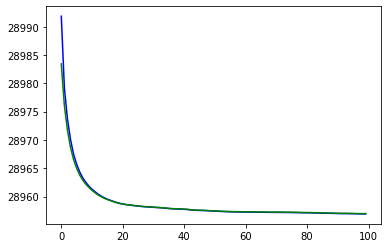

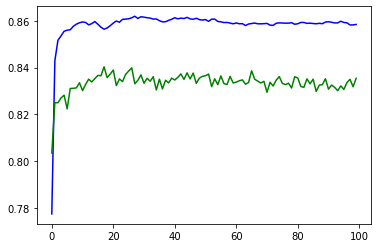

Minimum val_loss at epoch 99 = 28956.9774


In [245]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [246]:
model.load_weights(save_best_weights)

In [247]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

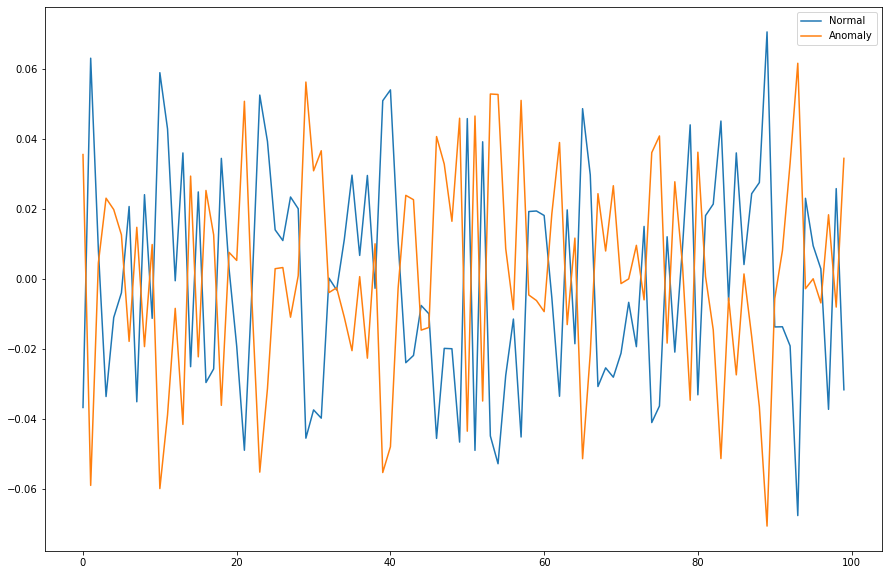

In [248]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

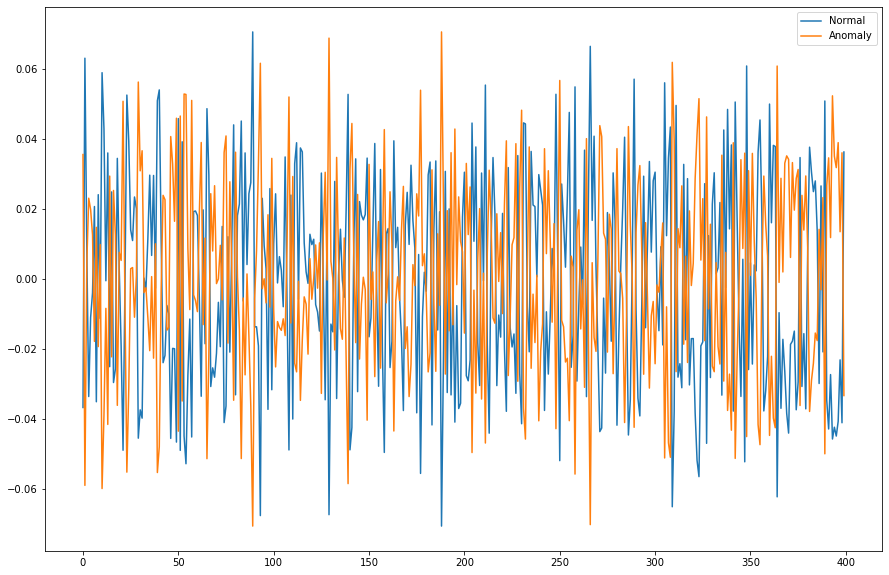

In [249]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [250]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(251946, 400)

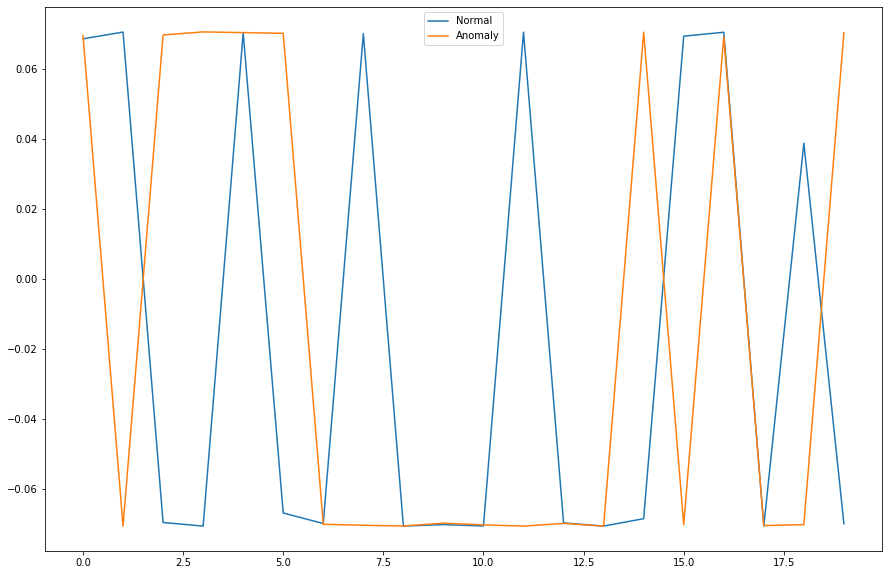

In [251]:

import matplotlib.pyplot as plt

limit = 20
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [252]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.030854


In [253]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [254]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.3367193044712562
0.5692423704755145


In [255]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.693665720369056
F1 =  0.6618683901292598
Precision_score =  0.890396522197339
recall_score =  0.5266890049092184
roc_auc_score =  0.9149920106330489
pr_auc =  0.924778727650677
matthews_corr_score =  0.46209766217335296


In [286]:
threshold = 0.45
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8898154719659332
F1 =  0.9079454491550548
Precision_score =  0.8656632040138507
recall_score =  0.9545702485778852
roc_auc_score =  0.9149920106330489
pr_auc =  0.924778727650677
matthews_corr_score =  0.7772819446658178


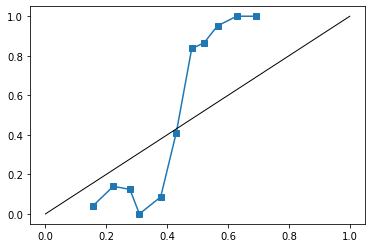

In [287]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

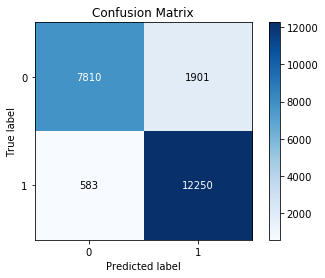

In [288]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## Graficas training dataset

In [289]:
model.load_weights(save_best_weights)

In [290]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [291]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.935312744110628

In [292]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [293]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

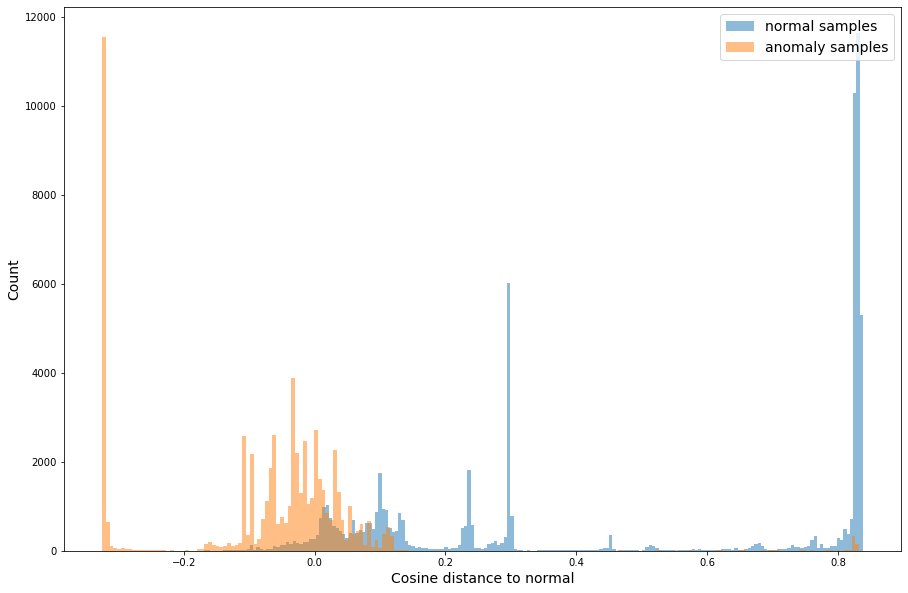

In [294]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, training dataset

In [295]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [296]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


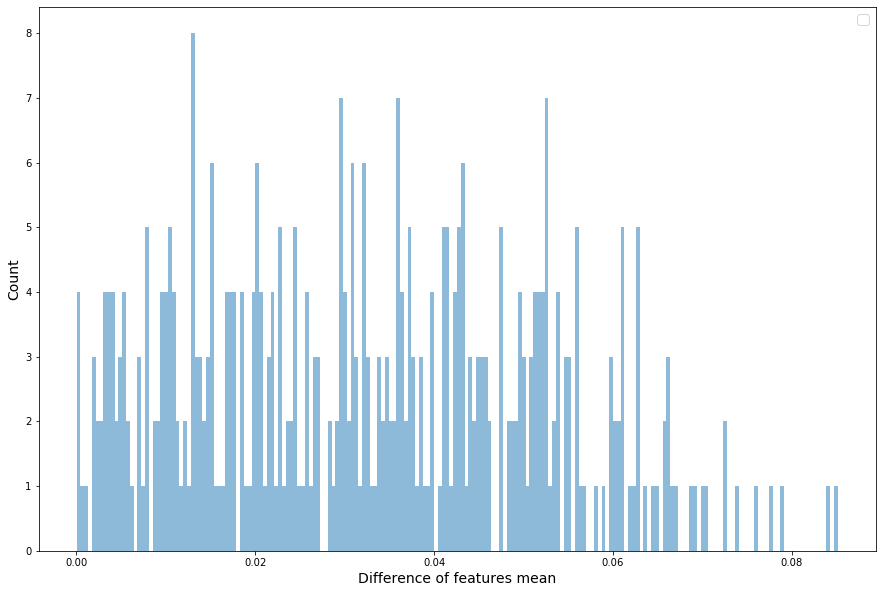

In [297]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [298]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

33.877654627844414 1.8768368121824697e-119


## Graficas Test dataset

In [299]:
model.load_weights(save_best_weights)

In [300]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [301]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.935312744110628

In [302]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [303]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

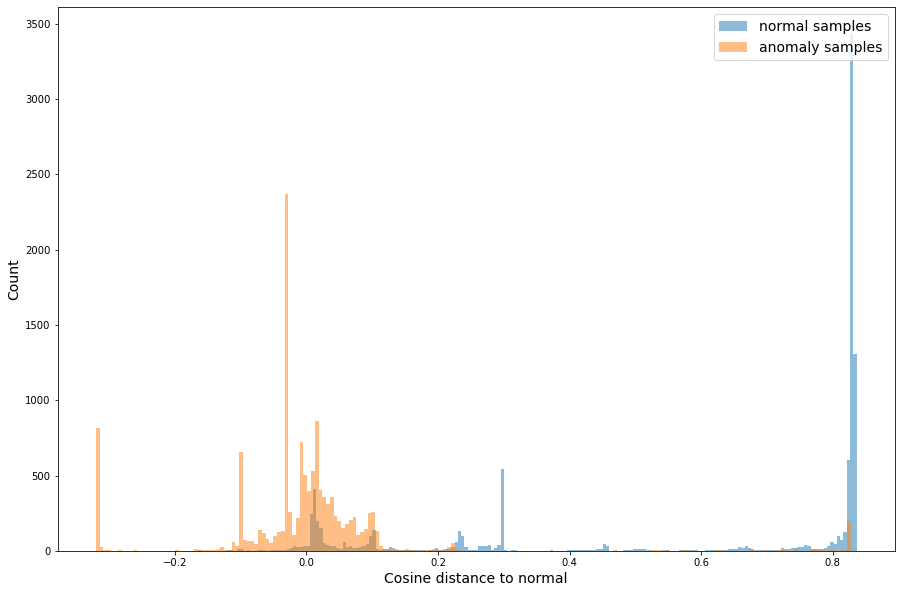

In [304]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, test dataset

In [305]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [306]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


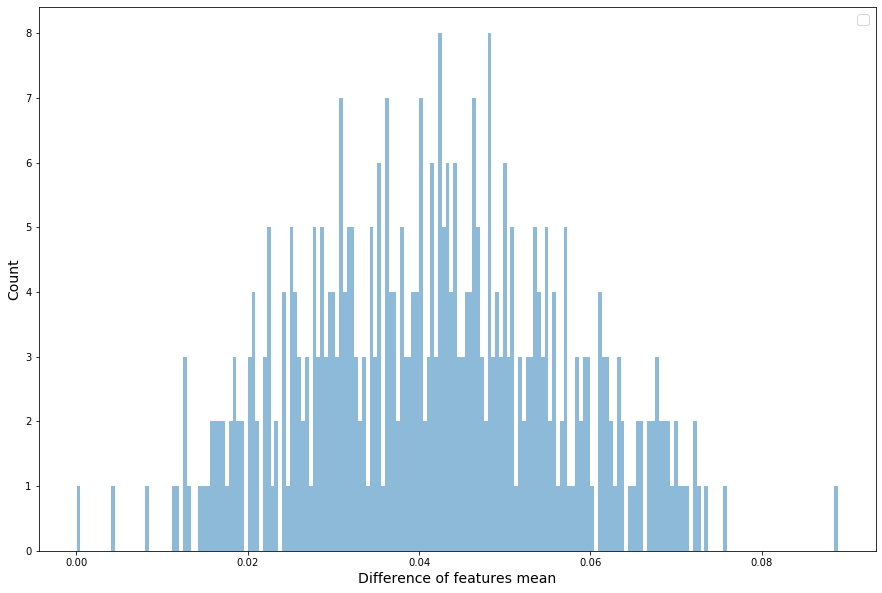

In [307]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [308]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

55.29305087429159 3.700416346929416e-189


## logloss+contractive, 
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.01

In [77]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [78]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [79]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 5new'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [80]:
np.random.seed(24537889)
tf.random.set_seed(32248573)

In [81]:
def cosine_act(x):
    return tf.math.cos(x)

In [82]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [83]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [84]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [85]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [86]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [87]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [88]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [89]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1374
alpha_val = 0.01

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

Instructions for updating:
If using Keras pass *_constraint arguments to layers.


In [91]:
W2.numpy()

AttributeError: 'Tensor' object has no attribute 'numpy'

In [92]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_2 (InputLayer)            [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_1[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_2[0][0]                    
______________________________________________________________________________________________

In [93]:
model_embed_x.summary()

Model: "model_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [94]:
model_embed_label.summary()

Model: "model_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [95]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [96]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 9s 45us/sample - loss: 2930.5815 - accuracy: 0.8232 - val_loss: 2929.7419 - val_accuracy: 0.8553
Epoch 2/100
201556/201556 [==============================] - 8s 42us/sample - loss: 2929.2940 - accuracy: 0.8930 - val_loss: 2929.0048 - val_accuracy: 0.8784
Epoch 3/100
201556/201556 [==============================] - 8s 41us/sample - loss: 2928.7356 - accuracy: 0.9015 - val_loss: 2928.5624 - val_accuracy: 0.8740
Epoch 4/100
201556/201556 [==============================] - 8s 42us/sample - loss: 2928.3598 - accuracy: 0.9041 - val_loss: 2928.2413 - val_accuracy: 0.8913
Epoch 5/100
201556/201556 [==============================] - 8s 41us/sample - loss: 2928.0850 - accuracy: 0.9105 - val_loss: 2928.0064 - val_accuracy: 0.8955
Epoch 6/100
201556/201556 [==============================] - 8s 41us/sample - loss: 2927.8854 - accuracy: 0.9132 - val_loss: 2927.8361 - val_accuracy: 0.8980
E

In [97]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [98]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

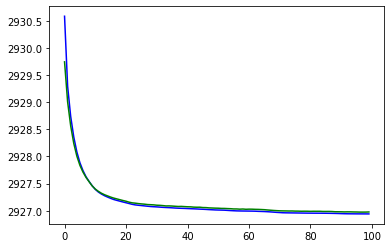

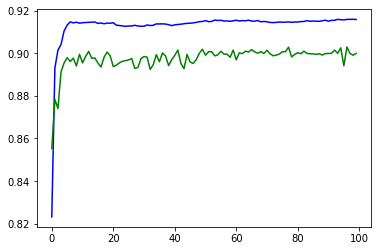

Minimum val_loss at epoch 98 = 2926.9756


In [99]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [92]:
model.load_weights(save_best_weights)

In [93]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

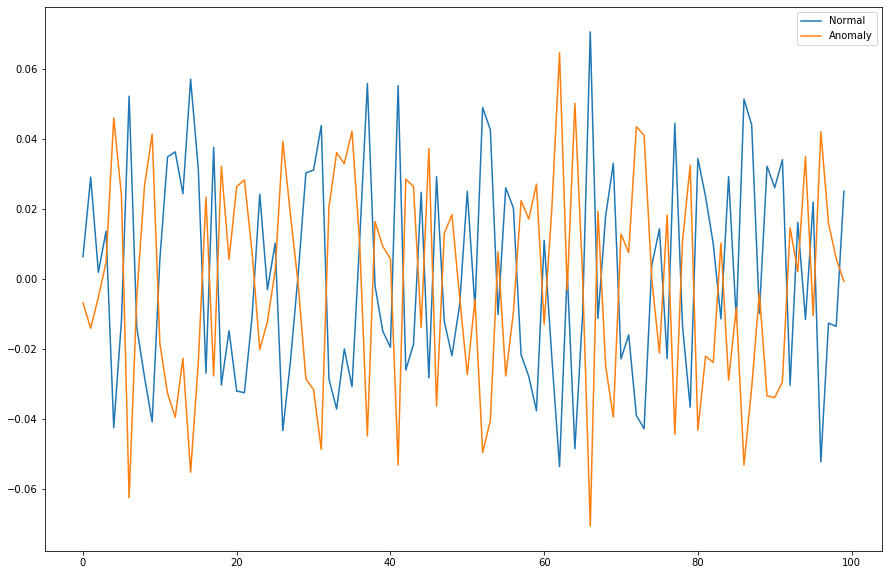

In [300]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

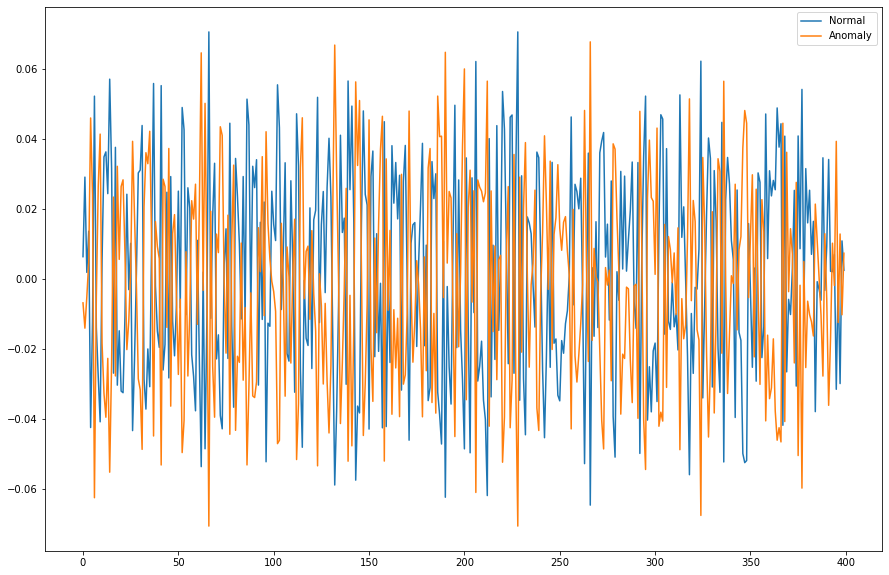

In [301]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [302]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(251946, 400)

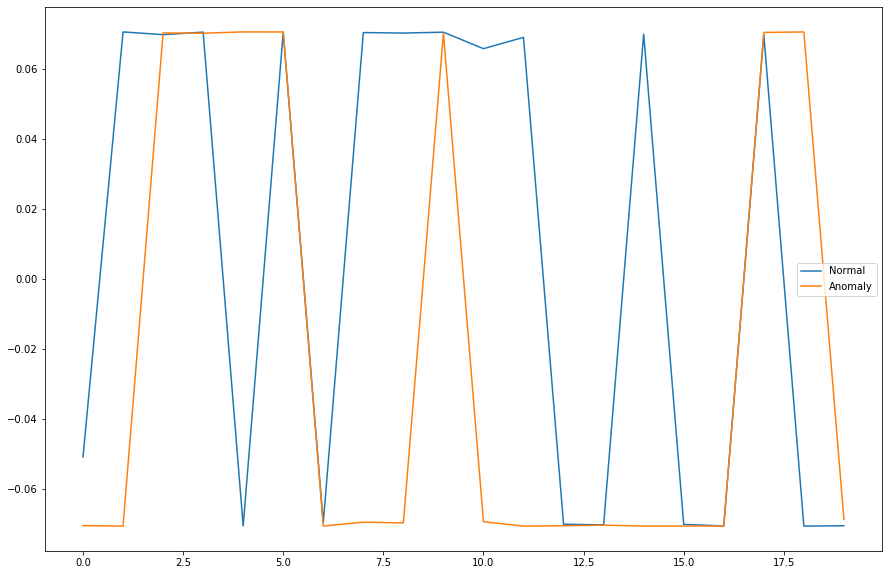

In [303]:

import matplotlib.pyplot as plt

limit = 20
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [106]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.029820


In [107]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [108]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.3934528034066714
0.5692423704755145


In [109]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7577625975869411
F1 =  0.7483758005805649
Precision_score =  0.9155580608793686
recall_score =  0.6328216317306943
roc_auc_score =  0.9420991183502931
pr_auc =  0.9452051092557655
matthews_corr_score =  0.5632757987963511


In [138]:
threshold = 0.46
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.9082682753726047
F1 =  0.9210506222799114
Precision_score =  0.902851582965347
recall_score =  0.9399984415179615
roc_auc_score =  0.9420991183502931
pr_auc =  0.9452051092557655
matthews_corr_score =  0.8126436131146052


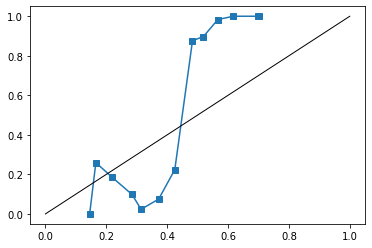

In [111]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

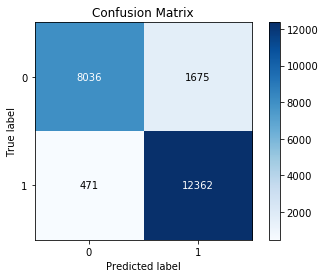

In [112]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## Graficas training dataset

In [102]:
model.load_weights(save_best_weights)

In [103]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [104]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9474324787096632

In [105]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [106]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

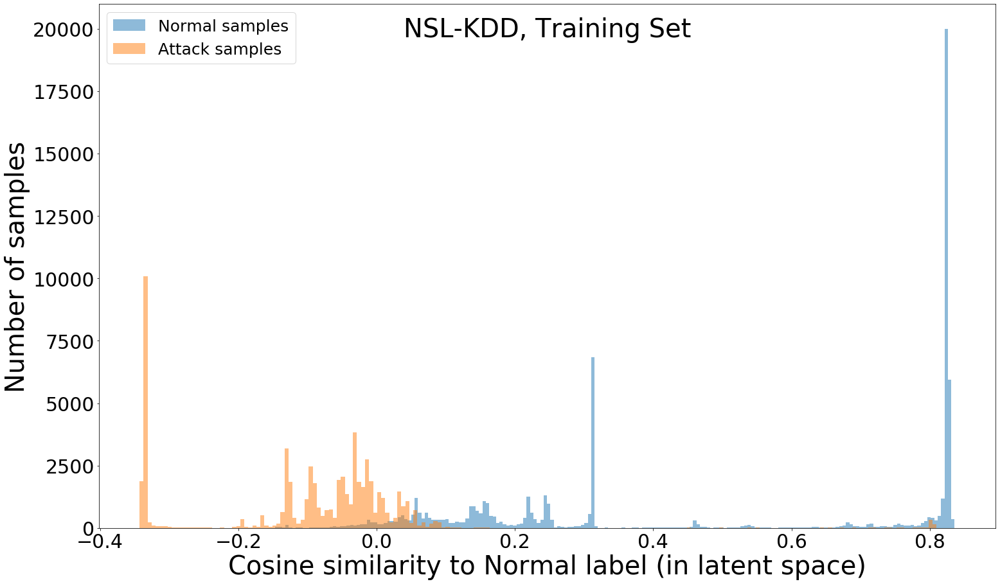

In [108]:
plt.ion()
plt.figure(figsize=(25,15))

plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="Normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="Attack samples")

plt.xlabel("Cosine similarity to Normal label (in latent space)", fontsize=40)
plt.ylabel("Number of samples", fontsize=40)
plt.tick_params(axis='both', labelsize=30)
plt.legend(fontsize=25, loc=2)
plt.title(label="NSL-KDD, Training Set", fontsize=40, position=(0.5, 0.93))
plt.savefig('x21.svg',dpi=1000, bbox_inches ='tight')

plt.show()

## Comparacion de los valores medios de las features, training dataset

In [119]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [120]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


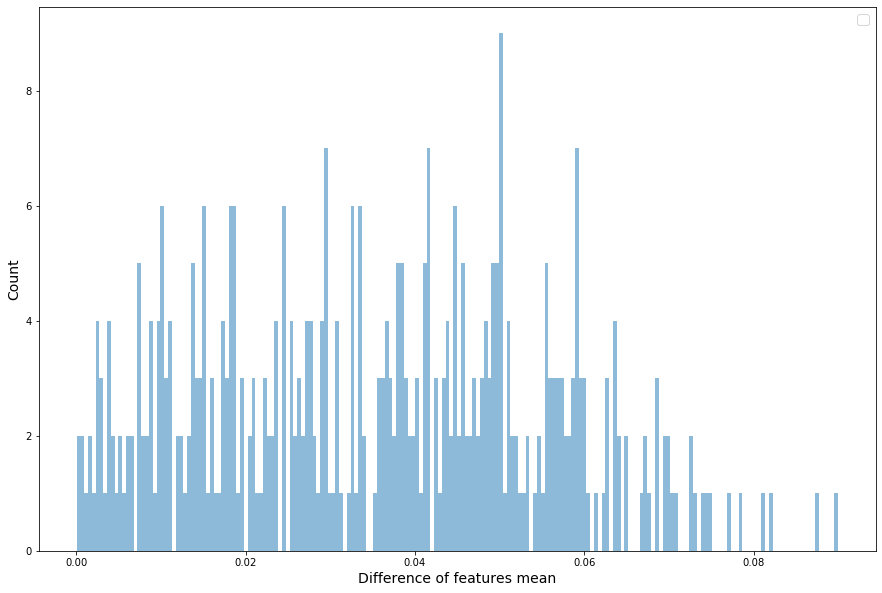

In [121]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [122]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

35.279261313538825 1.0059954506883521e-124


## Graficas Test dataset

In [109]:
model.load_weights(save_best_weights)

In [110]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [111]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9474324787096632

In [112]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [113]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

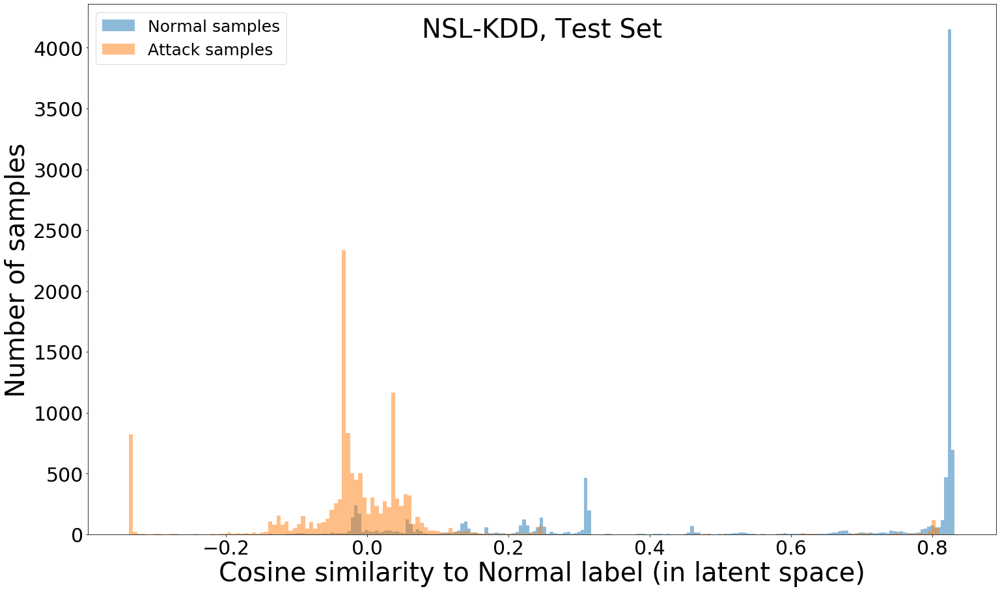

In [114]:
plt.ion()
plt.figure(figsize=(25,15))

plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="Normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="Attack samples")

plt.xlabel("Cosine similarity to Normal label (in latent space)", fontsize=40)
plt.ylabel("Number of samples", fontsize=40)
plt.tick_params(axis='both', labelsize=30)
plt.legend(fontsize=25, loc=2)
plt.title(label="NSL-KDD, Test Set", fontsize=40, position=(0.5, 0.93))
plt.savefig('x22.svg',dpi=1000, bbox_inches ='tight')

plt.show()

## Comparacion de los valores medios de las features, test dataset

In [129]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [130]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


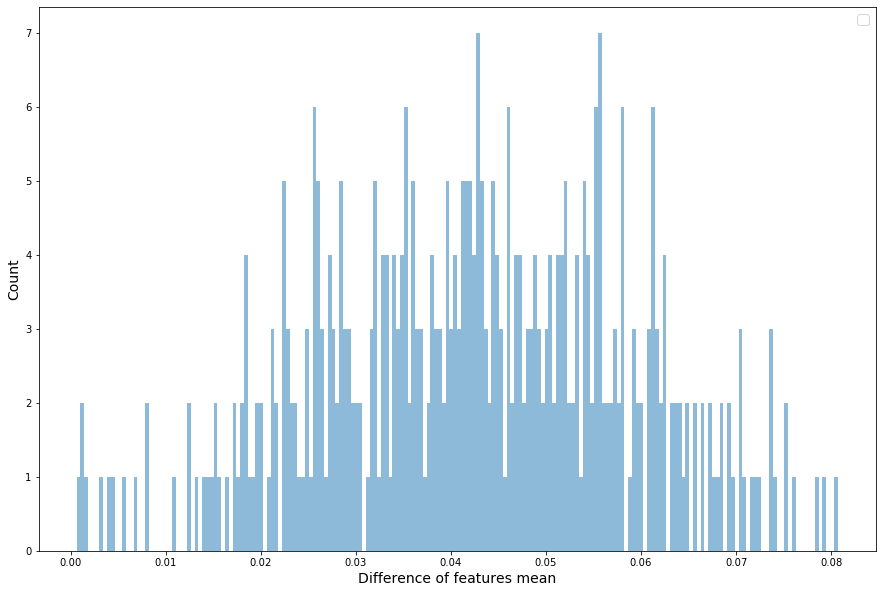

In [131]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [132]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

51.96499779815476 1.0381088317478639e-179


In [ ]:
#aqui

## logloss+contractive, 
rff_dim = 500
gamma = 3
seed = 1234
alpha_val = 0.0001

In [77]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [78]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [79]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 500 5new'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [80]:
np.random.seed(24537889)
tf.random.set_seed(32248573)

In [81]:
def cosine_act(x):
    return tf.math.cos(x)

In [82]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [83]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [84]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [85]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [86]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [87]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [88]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [89]:
#crear modelo
rff_dim = 500
gamma = 3
seed = 1374
alpha_val = 0.0001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

Instructions for updating:
If using Keras pass *_constraint arguments to layers.


In [90]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_2 (InputLayer)            [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 500)          61500       input_1[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 500)          1500        input_2[0][0]                    
______________________________________________________________________________________________

In [91]:
model_embed_x.summary()

Model: "model_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 500)               61500     
_________________________________________________________________
layer_x_out (Lambda)         (None, 500)               0         
Total params: 61,500
Trainable params: 61,500
Non-trainable params: 0
_________________________________________________________________


In [92]:
model_embed_label.summary()

Model: "model_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 500)               1500      
_________________________________________________________________
layer_l_out (Lambda)         (None, 500)               0         
Total params: 1,500
Trainable params: 1,500
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [93]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [95]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=50,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/50
201556/201556 [==============================] - 9s 47us/sample - loss: 36.6156 - accuracy: 0.9873 - val_loss: 36.6136 - val_accuracy: 0.9886
Epoch 2/50
201556/201556 [==============================] - 10s 47us/sample - loss: 36.6124 - accuracy: 0.9897 - val_loss: 36.6107 - val_accuracy: 0.9907
Epoch 3/50
201556/201556 [==============================] - 9s 46us/sample - loss: 36.6099 - accuracy: 0.9905 - val_loss: 36.6084 - val_accuracy: 0.9910
Epoch 4/50
201556/201556 [==============================] - 10s 48us/sample - loss: 36.6077 - accuracy: 0.9907 - val_loss: 36.6063 - val_accuracy: 0.9915
Epoch 5/50
201556/201556 [==============================] - 9s 47us/sample - loss: 36.6058 - accuracy: 0.9909 - val_loss: 36.6046 - val_accuracy: 0.9916
Epoch 6/50
201556/201556 [==============================] - 10s 48us/sample - loss: 36.6043 - accuracy: 0.9911 - val_loss: 36.6032 - val_accuracy: 0.9917
Epoch 7/50
201556/201556 [==

In [96]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [97]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

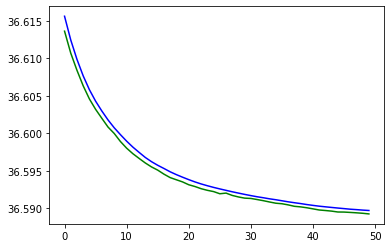

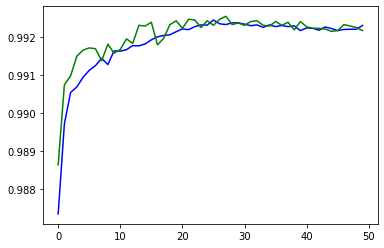

Minimum val_loss at epoch 50 = 36.5893


In [98]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Prediccion modelo entrenado

In [99]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.032398


In [100]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [101]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.38595635202271117
0.5692423704755145


In [102]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7902767920511
F1 =  0.7804402340484814
Precision_score =  0.9657510630961958
recall_score =  0.6547962284734669
roc_auc_score =  0.9558439236809851
pr_auc =  0.9641873157503529
matthews_corr_score =  0.6348294844289207


In [113]:
threshold = 0.1
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8867104329311568
F1 =  0.9036880609397391
Precision_score =  0.8755571793934965
recall_score =  0.9336865892620587
roc_auc_score =  0.9558439236809851
pr_auc =  0.9641873157503529
matthews_corr_score =  0.7688346448470396


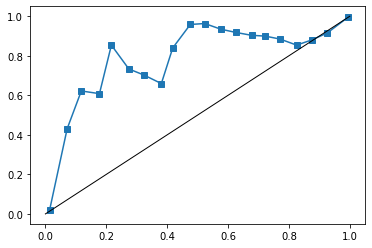

In [114]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

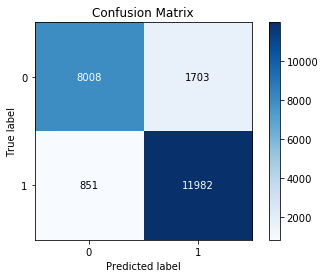

In [115]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

In [ ]:
#aqui 1

## logloss+contractive, 
rff_dim = 600
gamma = 3
seed = 1234
alpha_val = 0.0001

In [116]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [117]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [118]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 600 5new'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [119]:
np.random.seed(24537889)
tf.random.set_seed(32248573)

In [120]:
def cosine_act(x):
    return tf.math.cos(x)

In [121]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [122]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [123]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [124]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [125]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [126]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [127]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [128]:
#crear modelo
rff_dim = 600
gamma = 3
seed = 1374
alpha_val = 0.0001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [129]:
model.summary()

Model: "model_3"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_3 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_4 (InputLayer)            [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 600)          73800       input_3[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 600)          1800        input_4[0][0]                    
____________________________________________________________________________________________

In [130]:
model_embed_x.summary()

Model: "model_4"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_3 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 600)               73800     
_________________________________________________________________
layer_x_out (Lambda)         (None, 600)               0         
Total params: 73,800
Trainable params: 73,800
Non-trainable params: 0
_________________________________________________________________


In [131]:
model_embed_label.summary()

Model: "model_5"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_4 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 600)               1800      
_________________________________________________________________
layer_l_out (Lambda)         (None, 600)               0         
Total params: 1,800
Trainable params: 1,800
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [132]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [133]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=50,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/50
201556/201556 [==============================] - 12s 59us/sample - loss: 44.1761 - accuracy: 0.9525 - val_loss: 44.0590 - val_accuracy: 0.9800
Epoch 2/50
201556/201556 [==============================] - 11s 54us/sample - loss: 44.0142 - accuracy: 0.9817 - val_loss: 43.9837 - val_accuracy: 0.9835
Epoch 3/50
201556/201556 [==============================] - 11s 56us/sample - loss: 43.9637 - accuracy: 0.9831 - val_loss: 43.9491 - val_accuracy: 0.9841
Epoch 4/50
201556/201556 [==============================] - 11s 56us/sample - loss: 43.9380 - accuracy: 0.9834 - val_loss: 43.9295 - val_accuracy: 0.9835
Epoch 5/50
201556/201556 [==============================] - 11s 56us/sample - loss: 43.9226 - accuracy: 0.9833 - val_loss: 43.9169 - val_accuracy: 0.9842
Epoch 6/50
201556/201556 [==============================] - 11s 55us/sample - loss: 43.9124 - accuracy: 0.9841 - val_loss: 43.9084 - val_accuracy: 0.9849
Epoch 7/50
201556/201556 

In [134]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [135]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

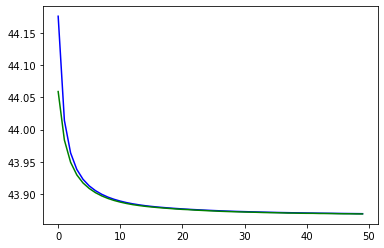

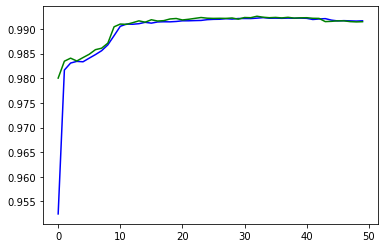

Minimum val_loss at epoch 50 = 43.8688


In [136]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Prediccion modelo entrenado

In [138]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.034476


In [139]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [140]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.38693222143364087
0.5692423704755145


In [141]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.790542938254081
F1 =  0.7809426609760624
Precision_score =  0.9649203255760633
recall_score =  0.655887165900413
roc_auc_score =  0.9555481796071991
pr_auc =  0.963688455772866
matthews_corr_score =  0.6348044446803933


In [166]:
threshold = 0.11
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8777945351312988
F1 =  0.8949074957085638
Precision_score =  0.8765505903452399
recall_score =  0.914049715577028
roc_auc_score =  0.9555481796071991
pr_auc =  0.963688455772866
matthews_corr_score =  0.7500227685430552


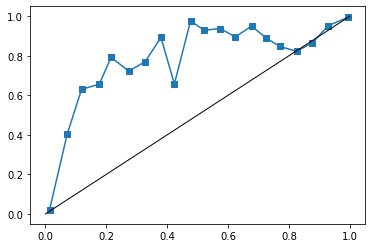

In [167]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

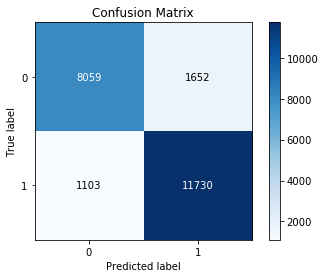

In [168]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

In [137]:
#aqui 2

## logloss+contractive, 
rff_dim = 50
gamma = 3
seed = 1234
alpha_val = 0.0001

In [169]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [170]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [171]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 50 5new'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [172]:
np.random.seed(24537889)
tf.random.set_seed(32248573)

In [173]:
def cosine_act(x):
    return tf.math.cos(x)

In [174]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [175]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [176]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [177]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [178]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [179]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [180]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [181]:
#crear modelo
rff_dim = 50
gamma = 3
seed = 1374
alpha_val = 0.0001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [182]:
model.summary()

Model: "model_6"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_5 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_6 (InputLayer)            [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 50)           6150        input_5[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 50)           150         input_6[0][0]                    
____________________________________________________________________________________________

In [183]:
model_embed_x.summary()

Model: "model_7"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_5 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 50)                6150      
_________________________________________________________________
layer_x_out (Lambda)         (None, 50)                0         
Total params: 6,150
Trainable params: 6,150
Non-trainable params: 0
_________________________________________________________________


In [184]:
model_embed_label.summary()

Model: "model_8"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_6 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 50)                150       
_________________________________________________________________
layer_l_out (Lambda)         (None, 50)                0         
Total params: 150
Trainable params: 150
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [185]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [186]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=50,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 9s 43us/sample - loss: 3.7857 - accuracy: 0.9328 - val_loss: 3.6746 - val_accuracy: 0.9710
Epoch 2/100
201556/201556 [==============================] - 8s 41us/sample - loss: 3.6383 - accuracy: 0.9738 - val_loss: 3.6139 - val_accuracy: 0.9765
Epoch 3/100
201556/201556 [==============================] - 8s 40us/sample - loss: 3.6009 - accuracy: 0.9772 - val_loss: 3.5909 - val_accuracy: 0.9795
Epoch 4/100
201556/201556 [==============================] - 8s 41us/sample - loss: 3.5839 - accuracy: 0.9800 - val_loss: 3.5782 - val_accuracy: 0.9812
Epoch 5/100
201556/201556 [==============================] - 9s 43us/sample - loss: 3.5736 - accuracy: 0.9826 - val_loss: 3.5697 - val_accuracy: 0.9833
Epoch 6/100
201556/201556 [==============================] - 9s 44us/sample - loss: 3.5666 - accuracy: 0.9839 - val_loss: 3.5637 - val_accuracy: 0.9842
Epoch 7/100
201556/201556 [==========

In [187]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [188]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

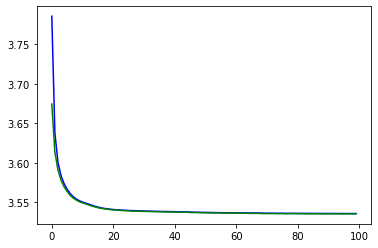

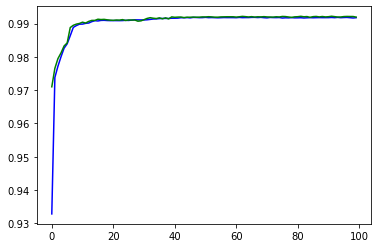

Minimum val_loss at epoch 99 = 3.5354


In [189]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Prediccion modelo entrenado

In [190]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.021843


In [191]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [192]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.3928761533002129
0.5692423704755145


In [193]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7970191625266146
F1 =  0.7890272014753343
Precision_score =  0.9661284859433217
recall_score =  0.6667965401698746
roc_auc_score =  0.954443608872749
pr_auc =  0.9627221939418413
matthews_corr_score =  0.6447479890210849


In [203]:
threshold = 0.2
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8642654364797729
F1 =  0.8760129659643436
Precision_score =  0.9124672912973749
recall_score =  0.8423595418062807
roc_auc_score =  0.954443608872749
pr_auc =  0.9627221939418413
matthews_corr_score =  0.7294355264844986


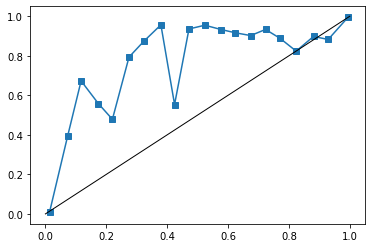

In [195]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

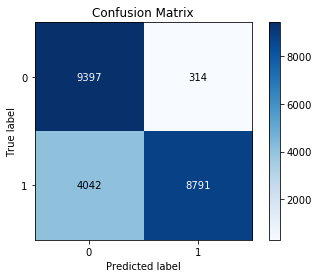

In [196]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

In [ ]:
#aqui 3

## logloss+contractive, 
rff_dim = 100
gamma = 3
seed = 1234
alpha_val = 0.0001

In [262]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [263]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [264]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 100 5new'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [265]:
np.random.seed(24537889)
tf.random.set_seed(32248573)

In [266]:
def cosine_act(x):
    return tf.math.cos(x)

In [267]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [268]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [269]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [270]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [271]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [272]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [273]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [274]:
#crear modelo
rff_dim = 100
gamma = 3
seed = 1374
alpha_val = 0.0001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [217]:
model.summary()

Model: "model_9"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_7 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_8 (InputLayer)            [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 100)          12300       input_7[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 100)          300         input_8[0][0]                    
____________________________________________________________________________________________

In [218]:
model_embed_x.summary()

Model: "model_10"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_7 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 100)               12300     
_________________________________________________________________
layer_x_out (Lambda)         (None, 100)               0         
Total params: 12,300
Trainable params: 12,300
Non-trainable params: 0
_________________________________________________________________


In [219]:
model_embed_label.summary()

Model: "model_11"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_8 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 100)               300       
_________________________________________________________________
layer_l_out (Lambda)         (None, 100)               0         
Total params: 300
Trainable params: 300
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [220]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [221]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=50,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 11s 53us/sample - loss: 7.5560 - accuracy: 0.9420 - val_loss: 7.4423 - val_accuracy: 0.9748
Epoch 2/100
201556/201556 [==============================] - 10s 49us/sample - loss: 7.4042 - accuracy: 0.9773 - val_loss: 7.3788 - val_accuracy: 0.9798
Epoch 3/100
201556/201556 [==============================] - 10s 48us/sample - loss: 7.3643 - accuracy: 0.9799 - val_loss: 7.3535 - val_accuracy: 0.9823
Epoch 4/100
201556/201556 [==============================] - 10s 48us/sample - loss: 7.3463 - accuracy: 0.9819 - val_loss: 7.3399 - val_accuracy: 0.9836
Epoch 5/100
201556/201556 [==============================] - 10s 48us/sample - loss: 7.3355 - accuracy: 0.9836 - val_loss: 7.3310 - val_accuracy: 0.9858
Epoch 6/100
201556/201556 [==============================] - 10s 48us/sample - loss: 7.3283 - accuracy: 0.9867 - val_loss: 7.3253 - val_accuracy: 0.9882
Epoch 7/100
201556/201556 [====

Epoch 54/100
201556/201556 [==============================] - 10s 51us/sample - loss: 7.3014 - accuracy: 0.9913 - val_loss: 7.3009 - val_accuracy: 0.9916
Epoch 55/100
201556/201556 [==============================] - 10s 50us/sample - loss: 7.3013 - accuracy: 0.9913 - val_loss: 7.3009 - val_accuracy: 0.9916
Epoch 56/100
201556/201556 [==============================] - 10s 50us/sample - loss: 7.3013 - accuracy: 0.9913 - val_loss: 7.3008 - val_accuracy: 0.9915
Epoch 57/100
201556/201556 [==============================] - 10s 51us/sample - loss: 7.3012 - accuracy: 0.9913 - val_loss: 7.3008 - val_accuracy: 0.9917
Epoch 58/100
201556/201556 [==============================] - 10s 50us/sample - loss: 7.3012 - accuracy: 0.9914 - val_loss: 7.3007 - val_accuracy: 0.9915
Epoch 59/100
201556/201556 [==============================] - 10s 50us/sample - loss: 7.3011 - accuracy: 0.9912 - val_loss: 7.3007 - val_accuracy: 0.9916
Epoch 60/100
201556/201556 [==============================] - 10s 50us/sampl

In [222]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [223]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

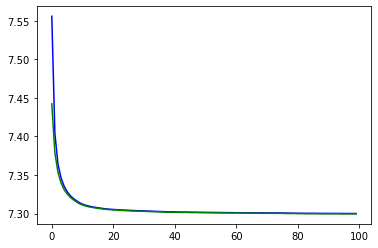

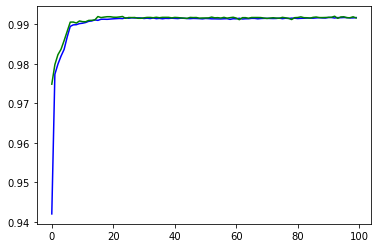

Minimum val_loss at epoch 99 = 7.2995


In [224]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Prediccion modelo entrenado

In [275]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.026095


In [276]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [277]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.40108232789212206
0.5692423704755145


In [278]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8057576295244855
F1 =  0.7998171428571429
Precision_score =  0.9674850696748507
recall_score =  0.6816800436374971
roc_auc_score =  0.9616922996519461
pr_auc =  0.9682583316016866
matthews_corr_score =  0.6581364191431787


In [284]:
threshold = 0.05
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8772622427253371
F1 =  0.9019524467595054
Precision_score =  0.8270730439303353
recall_score =  0.9917400451959791
roc_auc_score =  0.9616922996519461
pr_auc =  0.9682583316016866
matthews_corr_score =  0.763528772431164


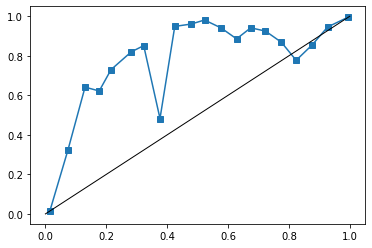

In [230]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

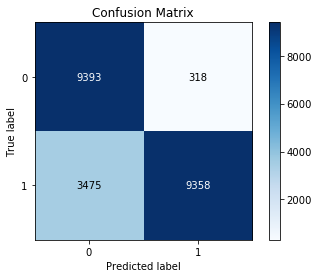

In [231]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

In [232]:
#aqui 4

## logloss+contractive, 
rff_dim = 200
gamma = 3
seed = 1234
alpha_val = 0.0001

In [233]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [234]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [235]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 200 5new'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [236]:
np.random.seed(24537889)
tf.random.set_seed(32248573)

In [237]:
def cosine_act(x):
    return tf.math.cos(x)

In [238]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [239]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [240]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [241]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [242]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [243]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [244]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [245]:
#crear modelo
rff_dim = 200
gamma = 3
seed = 1374
alpha_val = 0.0001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [246]:
model.summary()

Model: "model_12"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_9 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_10 (InputLayer)           [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 200)          24600       input_9[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 200)          600         input_10[0][0]                   
___________________________________________________________________________________________

In [247]:
model_embed_x.summary()

Model: "model_13"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_9 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 200)               24600     
_________________________________________________________________
layer_x_out (Lambda)         (None, 200)               0         
Total params: 24,600
Trainable params: 24,600
Non-trainable params: 0
_________________________________________________________________


In [248]:
model_embed_label.summary()

Model: "model_14"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_10 (InputLayer)        [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 200)               600       
_________________________________________________________________
layer_l_out (Lambda)         (None, 200)               0         
Total params: 600
Trainable params: 600
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [249]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [250]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=50,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/50
201556/201556 [==============================] - 8s 41us/sample - loss: 15.3896 - accuracy: 0.9342 - val_loss: 15.2720 - val_accuracy: 0.9720
Epoch 2/50
201556/201556 [==============================] - 7s 37us/sample - loss: 15.2281 - accuracy: 0.9761 - val_loss: 15.1972 - val_accuracy: 0.9791
Epoch 3/50
201556/201556 [==============================] - 8s 37us/sample - loss: 15.1770 - accuracy: 0.9803 - val_loss: 15.1619 - val_accuracy: 0.9819
Epoch 4/50
201556/201556 [==============================] - 8s 39us/sample - loss: 15.1509 - accuracy: 0.9819 - val_loss: 15.1421 - val_accuracy: 0.9825
Epoch 5/50
201556/201556 [==============================] - 7s 37us/sample - loss: 15.1355 - accuracy: 0.9824 - val_loss: 15.1298 - val_accuracy: 0.9832
Epoch 6/50
201556/201556 [==============================] - 7s 36us/sample - loss: 15.1255 - accuracy: 0.9829 - val_loss: 15.1215 - val_accuracy: 0.9837
Epoch 7/50
201556/201556 [=====

In [251]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [252]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

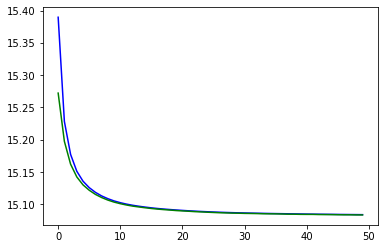

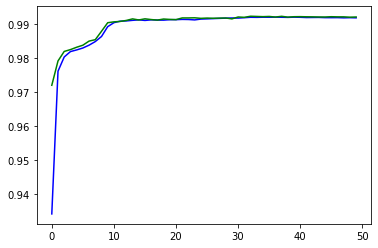

Minimum val_loss at epoch 50 = 15.0832


In [253]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Prediccion modelo entrenado

In [254]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.030529


In [255]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [256]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.39518275372604683
0.5692423704755145


In [257]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7987934705464869
F1 =  0.7913715389568576
Precision_score =  0.9656527107419464
recall_score =  0.6703810488584119
roc_auc_score =  0.9574311809053002
pr_auc =  0.9652665833468126
matthews_corr_score =  0.6470931229340028


In [261]:
threshold = 0.1
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8912349183818311
F1 =  0.9076946243035687
Precision_score =  0.8780132546791931
recall_score =  0.9394529728044885
roc_auc_score =  0.9574311809053002
pr_auc =  0.9652665833468126
matthews_corr_score =  0.7783240344034348


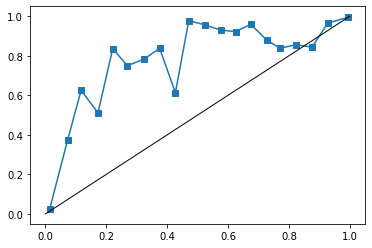

In [259]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

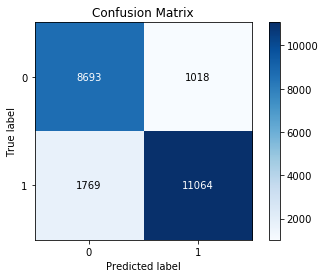

In [260]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## logloss+contractive, 
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.001

In [170]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [88]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [89]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X dim10 v1.0'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [203]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [204]:
def cosine_act(x):
    return tf.math.cos(x)

In [205]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [206]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [207]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [208]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [209]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [210]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)


In [296]:
vocab_size = in_dim_label  # no usado de momento
embed_dim = 10

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [297]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [214]:
model.summary()

Model: "model_42"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_3 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_4 (InputLayer)            [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_3[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_4[0][0]                    
___________________________________________________________________________________________

In [215]:
model_embed_x.summary()

Model: "model_43"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_3 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [216]:
model_embed_label.summary()

Model: "model_44"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_4 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [217]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [219]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 10s 49us/sample - loss: 291.4708 - accuracy: 0.9304 - val_loss: 291.3378 - val_accuracy: 0.9666
Epoch 2/100
201556/201556 [==============================] - 9s 43us/sample - loss: 291.2496 - accuracy: 0.9701 - val_loss: 291.2144 - val_accuracy: 0.9734
Epoch 3/100
201556/201556 [==============================] - 8s 42us/sample - loss: 291.1597 - accuracy: 0.9733 - val_loss: 291.1471 - val_accuracy: 0.9744
Epoch 4/100
201556/201556 [==============================] - 9s 43us/sample - loss: 291.1040 - accuracy: 0.9741 - val_loss: 291.1007 - val_accuracy: 0.9755
Epoch 5/100
201556/201556 [==============================] - 9s 43us/sample - loss: 291.0646 - accuracy: 0.9748 - val_loss: 291.0670 - val_accuracy: 0.9758
Epoch 6/100
201556/201556 [==============================] - 9s 43us/sample - loss: 291.0366 - accuracy: 0.9748 - val_loss: 291.0425 - val_accuracy: 0.9758
Epoch 7/100


Epoch 53/100
201556/201556 [==============================] - 8s 42us/sample - loss: 290.9201 - accuracy: 0.9725 - val_loss: 290.9376 - val_accuracy: 0.9734
Epoch 54/100
201556/201556 [==============================] - 8s 42us/sample - loss: 290.9200 - accuracy: 0.9725 - val_loss: 290.9374 - val_accuracy: 0.9733
Epoch 55/100
201556/201556 [==============================] - 8s 42us/sample - loss: 290.9199 - accuracy: 0.9724 - val_loss: 290.9381 - val_accuracy: 0.9732
Epoch 56/100
201556/201556 [==============================] - 9s 43us/sample - loss: 290.9197 - accuracy: 0.9724 - val_loss: 290.9375 - val_accuracy: 0.9733
Epoch 57/100
201556/201556 [==============================] - 9s 42us/sample - loss: 290.9196 - accuracy: 0.9724 - val_loss: 290.9379 - val_accuracy: 0.9733
Epoch 58/100
201556/201556 [==============================] - 9s 43us/sample - loss: 290.9194 - accuracy: 0.9723 - val_loss: 290.9356 - val_accuracy: 0.9732
Epoch 59/100
201556/201556 [==============================

In [220]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [221]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

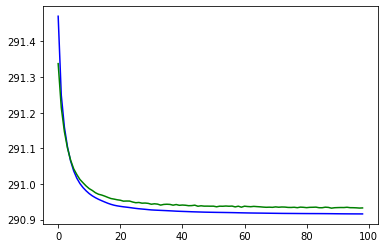

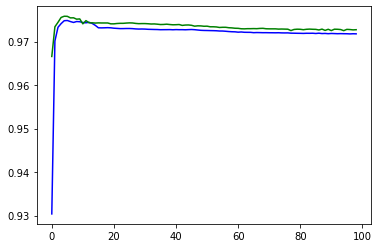

Minimum val_loss at epoch 89 = 290.9321


In [222]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [171]:
model.load_weights(save_best_weights)

In [286]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

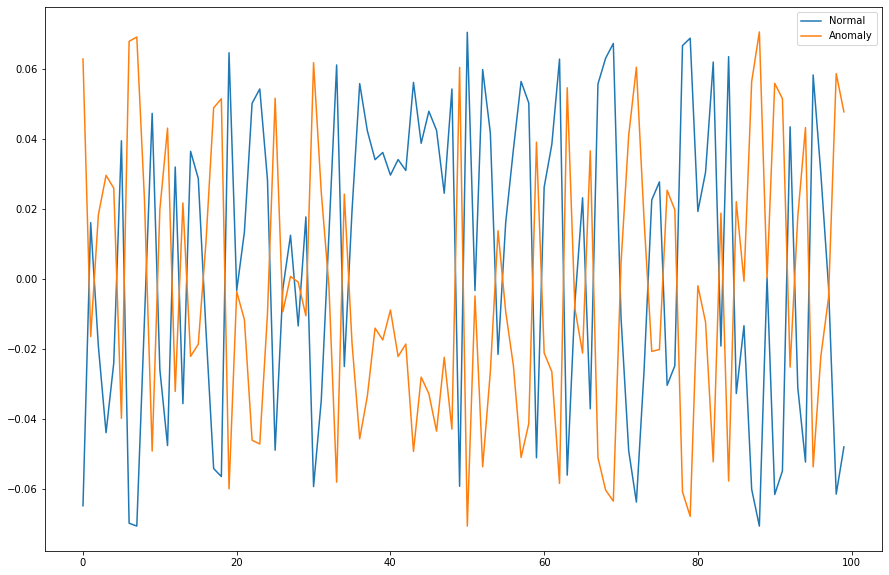

In [287]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

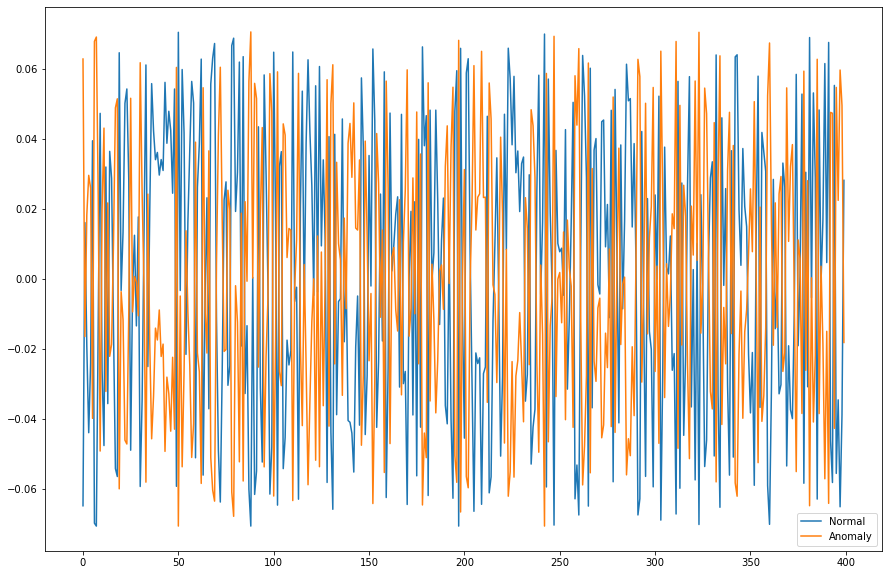

In [288]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [289]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(125973, 400)

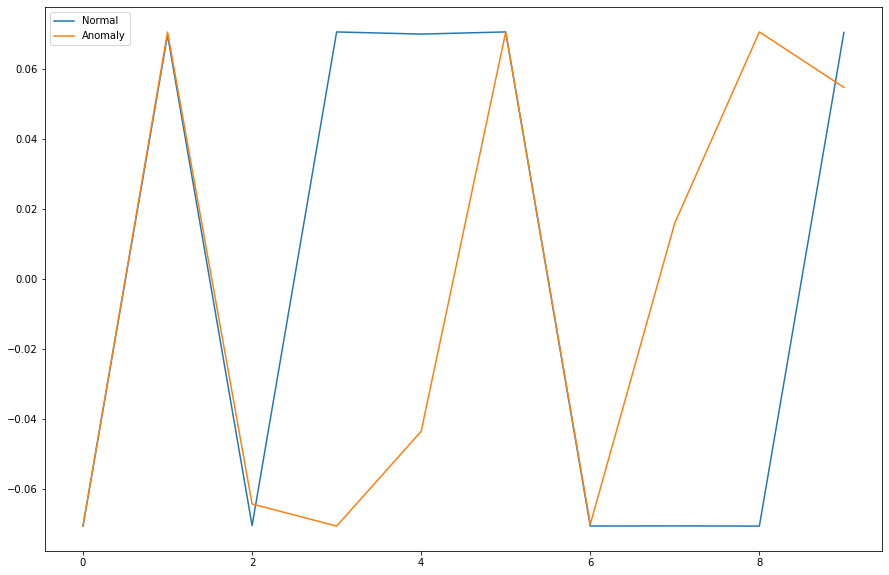

In [303]:

import matplotlib.pyplot as plt

limit = 10
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [295]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.028669


In [225]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [226]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.37814939673527326
0.5692423704755145


In [227]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7844215755855216
F1 =  0.7724506039891376
Precision_score =  0.9676246334310851
recall_score =  0.6427959167770592
roc_auc_score =  0.9415493967510182
pr_auc =  0.9382666284132986
matthews_corr_score =  0.6273697461711097


In [239]:
threshold = 0.21
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8826295244854506
F1 =  0.9049159120310479
Precision_score =  0.8396798932977659
recall_score =  0.9811423673342164
roc_auc_score =  0.9415493967510182
pr_auc =  0.9382666284132986
matthews_corr_score =  0.7697157498208321


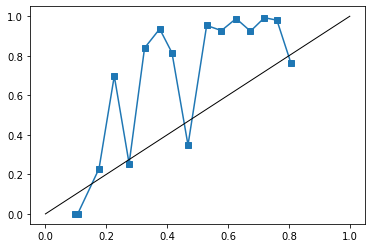

In [240]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

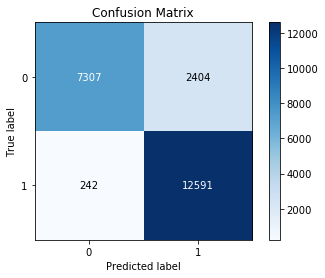

In [241]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## logloss+contractive, 
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.0001

In [469]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [470]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [471]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 2'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [472]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [473]:
def cosine_act(x):
    return tf.math.cos(x)

In [474]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [475]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [476]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [477]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [478]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [479]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)


In [480]:
vocab_size = in_dim_label  # no usado de momento
embed_dim = 10

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [481]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.0001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [317]:
W2.numpy()

AttributeError: 'Tensor' object has no attribute 'numpy'

In [318]:
model.summary()

Model: "model_48"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_7 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_8 (InputLayer)            [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_7[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_8[0][0]                    
___________________________________________________________________________________________

In [319]:
model_embed_x.summary()

Model: "model_49"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_7 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [320]:
model_embed_label.summary()

Model: "model_50"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_8 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [321]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [322]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 9s 47us/sample - loss: 29.5400 - accuracy: 0.9469 - val_loss: 29.4213 - val_accuracy: 0.9792
Epoch 2/100
201556/201556 [==============================] - 9s 44us/sample - loss: 29.3765 - accuracy: 0.9809 - val_loss: 29.3451 - val_accuracy: 0.9830
Epoch 3/100
201556/201556 [==============================] - 9s 43us/sample - loss: 29.3251 - accuracy: 0.9830 - val_loss: 29.3101 - val_accuracy: 0.9842
Epoch 4/100
201556/201556 [==============================] - 9s 43us/sample - loss: 29.2994 - accuracy: 0.9834 - val_loss: 29.2910 - val_accuracy: 0.9837
Epoch 5/100
201556/201556 [==============================] - 9s 42us/sample - loss: 29.2845 - accuracy: 0.9834 - val_loss: 29.2789 - val_accuracy: 0.9843
Epoch 6/100
201556/201556 [==============================] - 9s 42us/sample - loss: 29.2745 - accuracy: 0.9836 - val_loss: 29.2707 - val_accuracy: 0.9846
Epoch 7/100
201556/201556

In [323]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [324]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

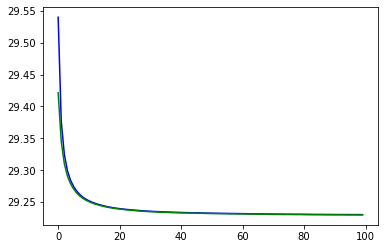

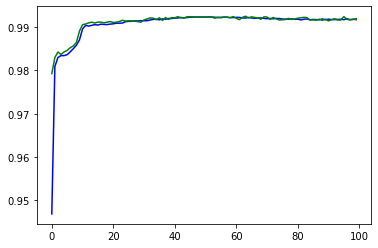

Minimum val_loss at epoch 99 = 29.2298


In [325]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [171]:
model.load_weights(save_best_weights)

In [326]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

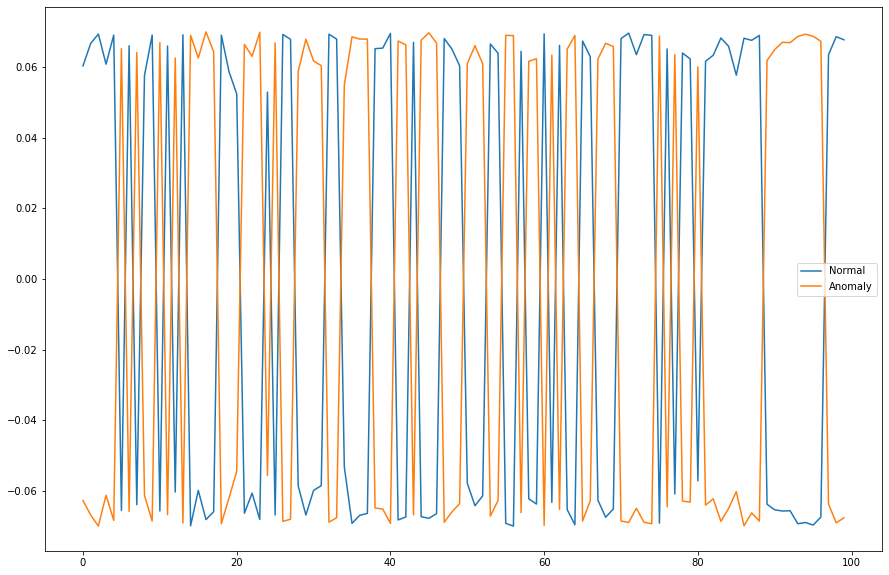

In [327]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

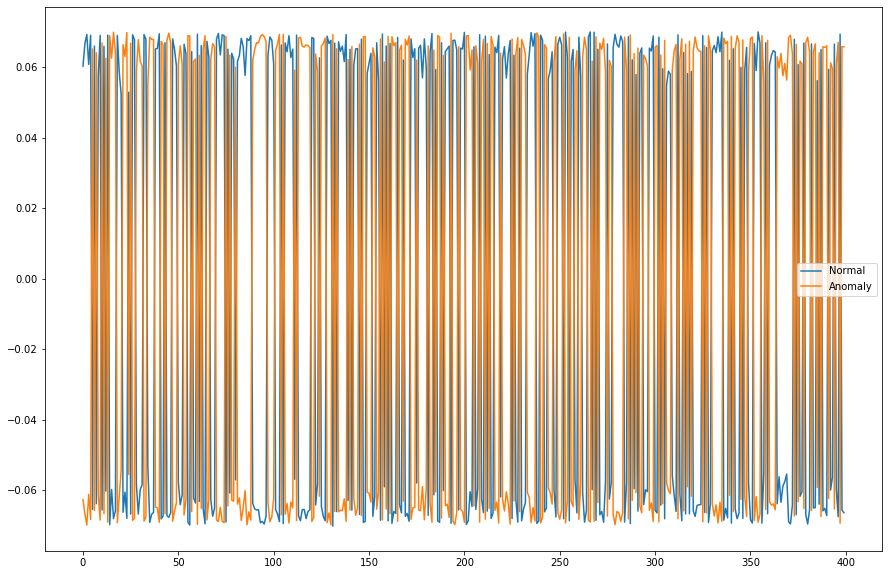

In [328]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [329]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(251946, 400)

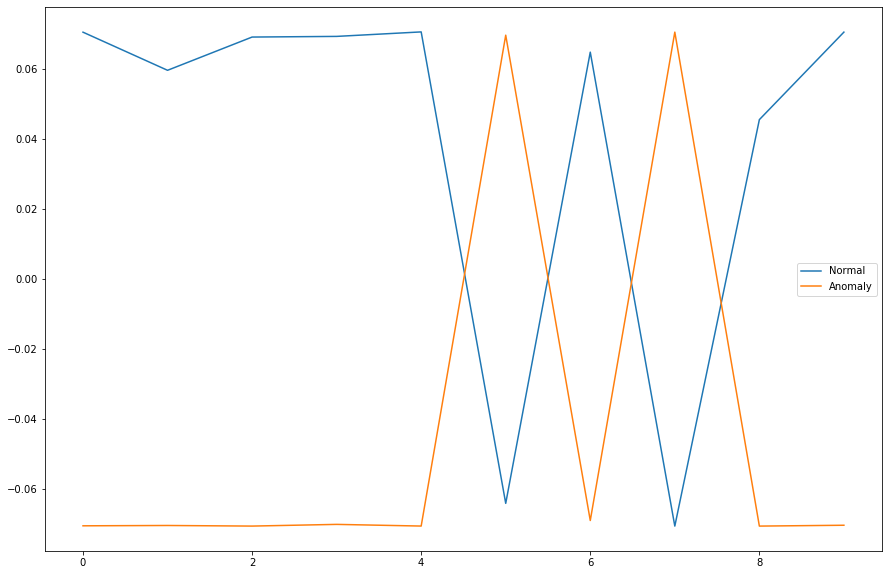

In [338]:

import matplotlib.pyplot as plt

limit = 10
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [482]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.035441


In [483]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [484]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.3868878637331441
0.5692423704755145


In [485]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7910308729595458
F1 =  0.7814428206912549
Precision_score =  0.9656042192157762
recall_score =  0.6562767864100366
roc_auc_score =  0.9592496747525341
pr_auc =  0.9666511892275398
matthews_corr_score =  0.6358421937833106


In [486]:
threshold = 0.09
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))


attack_name = 'PROBE'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'DOS'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'NORMAL'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(1-y_test[index_single_attack],1-ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'U2R'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'R2L'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]
print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8934971611071683
F1 =  0.9105939303667845
Precision_score =  0.8719868777635145
recall_score =  0.9527779942336164
roc_auc_score =  0.9592496747525341
pr_auc =  0.9666511892275398
matthews_corr_score =  0.784233500760354
.......
 single attack PROBE
Accuracy =  1.0
F1 =  1.0
Precision_score =  1.0
recall_score =  1.0
.......
 single attack DOS
Accuracy =  0.9840439796192009
F1 =  0.9919578292897209
Precision_score =  1.0
recall_score =  0.9840439796192009
.......
 single attack NORMAL
Accuracy =  0.8151580681701164
F1 =  0.8981675838202756
Precision_score =  1.0
recall_score =  0.8151580681701164
.......
 single attack U2R
Accuracy =  0.885
F1 =  0.9389920424403183
Precision_score =  1.0
recall_score =  0.885
.......
 single attack R2L
Accuracy =  0.8273296789350039
F1 =  0.9055067495178915
Precision_score =  1.0
recall_score =  0.8273296789350039


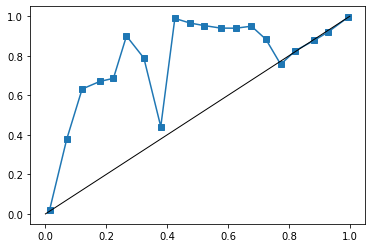

In [345]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

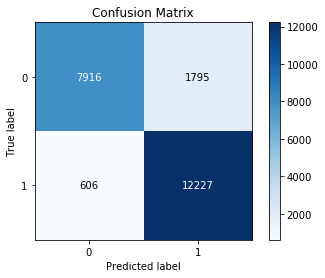

In [354]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

In [360]:
# missing samples

## logloss+contractive,  sin una etiqueta, missing PROBE
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.0001

In [380]:
index_PROBE = np.where(YTrainAN5.values=='PROBE')[0]
index_PROBE

rounds = 2
XTrainM_small = np.delete(XTrainM,index_PROBE,0)
YTrainANMOhe_small = np.delete(YTrainANMOhe,index_PROBE,0)

In [381]:
XTrainM_extended_small = XTrainM_small.copy()

In [382]:
XTrainM_extended_small = ExtendX (XTrainM_extended_small,XTrainM_small)
XTrainM_extended_small.shape

(228634, 122)

In [383]:
YTrainANMOhe_extended_small = YTrainANMOhe_small.copy()

In [384]:
YTrainANMOhe_extended_small = ExtendY(YTrainANMOhe_extended_small,YTrainANMOhe_small)
YTrainANMOhe_extended_small.shape

(228634, 2)

In [385]:
YTrainOutput_small = np.append(np.ones(XTrainM_small.shape[0]), np.zeros((rounds-1)*XTrainM_small.shape[0]))

In [386]:
YTrainAN5_small = YTrainAN5.drop(index_PROBE)
YTrainAN_small = YTrainAN.drop(index_PROBE)
print(XTrainM_extended_small.shape,YTrainOutput_small.shape, YTrainANMOhe_extended_small.shape )

(228634, 122) (228634,) (228634, 2)


In [387]:
x_train, x_test, label_train, label_test, y_train, y_test = XTrainM_extended_small, XTestM_extended, \
                                                            YTrainANMOhe_extended_small, YTestANMOhe_extended,\
                                                            YTrainOutput_small, YTestOutput
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape)


(228634, 122) (45088, 122) (228634, 2) (45088, 2) (228634,) (45088,)


In [388]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 2 unknown attack 1'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [389]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [390]:
def cosine_act(x):
    return tf.math.cos(x)

In [391]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [392]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [393]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [394]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [395]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [396]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)


In [397]:
vocab_size = in_dim_label  # no usado de momento
embed_dim = 10

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [398]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.0001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [399]:
model.summary()

Model: "model_15"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_11 (InputLayer)           [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_12 (InputLayer)           [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_11[0][0]                   
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_12[0][0]                   
___________________________________________________________________________________________

In [400]:
model_embed_x.summary()

Model: "model_16"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_11 (InputLayer)        [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [401]:
model_embed_label.summary()

Model: "model_17"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_12 (InputLayer)        [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [402]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [403]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 182907 samples, validate on 45727 samples
Epoch 1/100
182907/182907 [==============================] - 9s 49us/sample - loss: 29.6801 - accuracy: 0.9463 - val_loss: 29.5569 - val_accuracy: 0.9813
Epoch 2/100
182907/182907 [==============================] - 9s 47us/sample - loss: 29.5105 - accuracy: 0.9825 - val_loss: 29.4783 - val_accuracy: 0.9846
Epoch 3/100
182907/182907 [==============================] - 8s 46us/sample - loss: 29.4569 - accuracy: 0.9846 - val_loss: 29.4413 - val_accuracy: 0.9855
Epoch 4/100
182907/182907 [==============================] - 8s 46us/sample - loss: 29.4291 - accuracy: 0.9852 - val_loss: 29.4203 - val_accuracy: 0.9857
Epoch 5/100
182907/182907 [==============================] - 8s 46us/sample - loss: 29.4124 - accuracy: 0.9858 - val_loss: 29.4067 - val_accuracy: 0.9864
Epoch 6/100
182907/182907 [==============================] - 8s 46us/sample - loss: 29.4013 - accuracy: 0.9862 - val_loss: 29.3973 - val_accuracy: 0.9871
Epoch 7/100
182907/182907

In [404]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [405]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

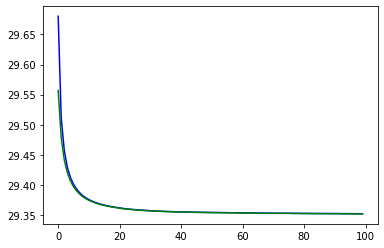

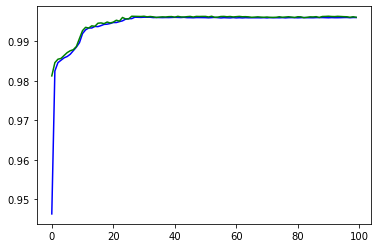

Minimum val_loss at epoch 99 = 29.3521


In [406]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [407]:
model.load_weights(save_best_weights)

In [408]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

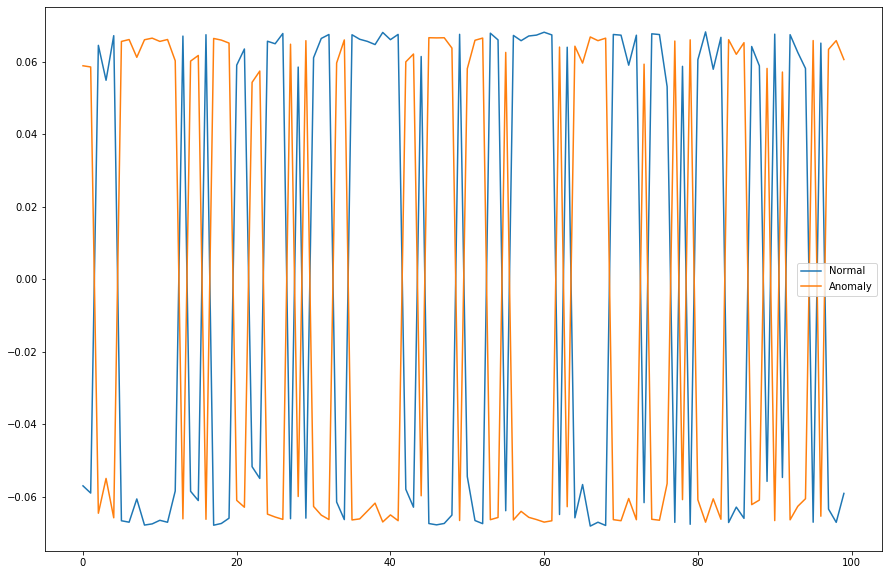

In [409]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

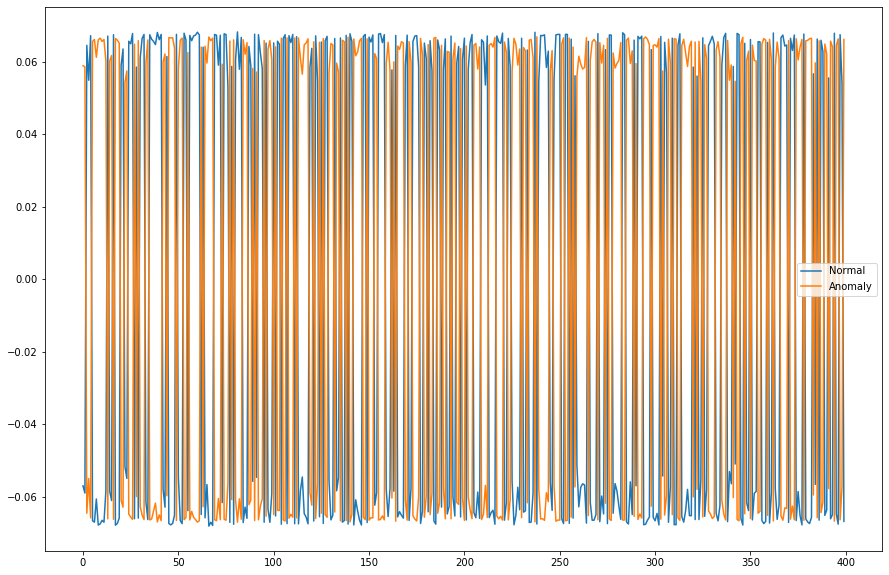

In [410]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [411]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(228634, 400)

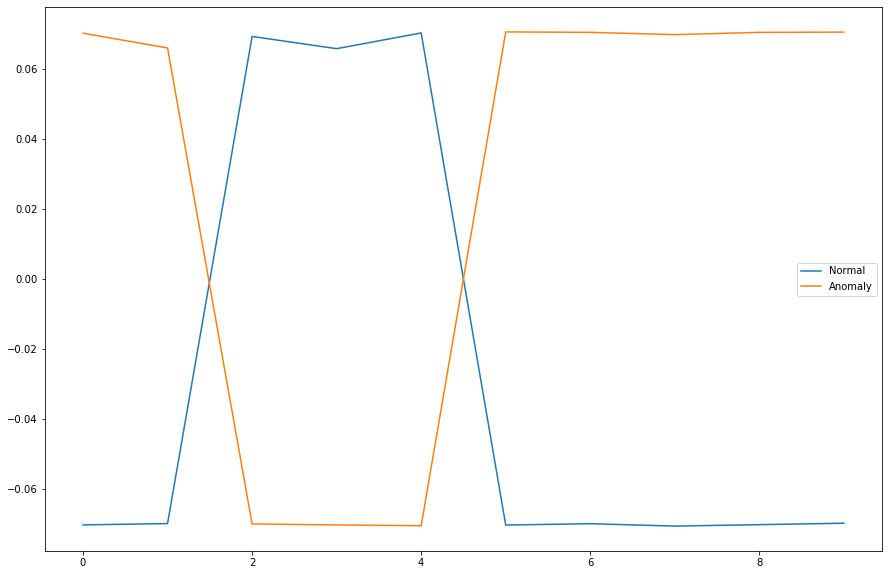

In [412]:

import matplotlib.pyplot as plt

limit = 10
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [413]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.034828


In [414]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [415]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.35047019162526616
0.5692423704755145


In [416]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7703158268275373
F1 =  0.7502652647824829
Precision_score =  0.9844323503354006
recall_score =  0.6060936647705135
roc_auc_score =  0.9570809116258114
pr_auc =  0.9686020921415539
matthews_corr_score =  0.6158965410443752


In [424]:
threshold = 0.08
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))


attack_name = 'PROBE'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'DOS'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'NORMAL'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(1-y_test[index_single_attack],1-ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'U2R'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'R2L'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]
print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8741572036905607
F1 =  0.8870935646913678
Precision_score =  0.906539775500244
recall_score =  0.8684641159510637
roc_auc_score =  0.9570809116258114
pr_auc =  0.9686020921415539
matthews_corr_score =  0.7459892570274768
.......
 single attack PROBE
Accuracy =  0.9644774886410574
F1 =  0.9819175777964676
Precision_score =  1.0
recall_score =  0.9644774886410574
.......
 single attack DOS
Accuracy =  0.9741217484580317
F1 =  0.9868912585750187
Precision_score =  1.0
recall_score =  0.9741217484580317
.......
 single attack NORMAL
Accuracy =  0.8816805684275564
F1 =  0.9371203414874405
Precision_score =  1.0
recall_score =  0.8816805684275564
.......
 single attack U2R
Accuracy =  0.1675
F1 =  0.28693790149892934
Precision_score =  1.0
recall_score =  0.1675
.......
 single attack R2L
Accuracy =  0.5787000783085356
F1 =  0.7331349206349207
Precision_score =  1.0
recall_score =  0.5787000783085356


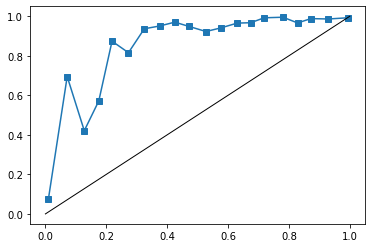

In [418]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

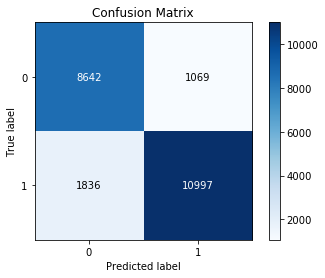

In [419]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## logloss+contractive,  sin una etiqueta, missing DOS
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.0001

In [425]:
index_PROBE = np.where(YTrainAN5.values=='DOS')[0]
index_PROBE

rounds = 2
XTrainM_small = np.delete(XTrainM,index_PROBE,0)
YTrainANMOhe_small = np.delete(YTrainANMOhe,index_PROBE,0)

In [426]:
XTrainM_extended_small = XTrainM_small.copy()

In [427]:
XTrainM_extended_small = ExtendX (XTrainM_extended_small,XTrainM_small)
XTrainM_extended_small.shape

(160092, 122)

In [428]:
YTrainANMOhe_extended_small = YTrainANMOhe_small.copy()

In [429]:
YTrainANMOhe_extended_small = ExtendY(YTrainANMOhe_extended_small,YTrainANMOhe_small)
YTrainANMOhe_extended_small.shape

(160092, 2)

In [430]:
YTrainOutput_small = np.append(np.ones(XTrainM_small.shape[0]), np.zeros((rounds-1)*XTrainM_small.shape[0]))

In [431]:
YTrainAN5_small = YTrainAN5.drop(index_PROBE)
YTrainAN_small = YTrainAN.drop(index_PROBE)
print(XTrainM_extended_small.shape,YTrainOutput_small.shape, YTrainANMOhe_extended_small.shape )

(160092, 122) (160092,) (160092, 2)


In [432]:
x_train, x_test, label_train, label_test, y_train, y_test = XTrainM_extended_small, XTestM_extended, \
                                                            YTrainANMOhe_extended_small, YTestANMOhe_extended,\
                                                            YTrainOutput_small, YTestOutput
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape)


(160092, 122) (45088, 122) (160092, 2) (45088, 2) (160092,) (45088,)


In [433]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 2 unknown attack 2'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [434]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [435]:
def cosine_act(x):
    return tf.math.cos(x)

In [436]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [437]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [438]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [439]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [440]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [441]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)


In [442]:
vocab_size = in_dim_label  # no usado de momento
embed_dim = 10

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [443]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.0001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [444]:
model.summary()

Model: "model_18"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_13 (InputLayer)           [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_14 (InputLayer)           [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_13[0][0]                   
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_14[0][0]                   
___________________________________________________________________________________________

In [445]:
model_embed_x.summary()

Model: "model_19"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_13 (InputLayer)        [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [446]:
model_embed_label.summary()

Model: "model_20"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_14 (InputLayer)        [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [447]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [448]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 128073 samples, validate on 32019 samples
Epoch 1/100
128073/128073 [==============================] - 7s 58us/sample - loss: 29.2764 - accuracy: 0.9422 - val_loss: 29.1577 - val_accuracy: 0.9773
Epoch 2/100
128073/128073 [==============================] - 6s 47us/sample - loss: 29.1238 - accuracy: 0.9811 - val_loss: 29.0981 - val_accuracy: 0.9841
Epoch 3/100
128073/128073 [==============================] - 6s 47us/sample - loss: 29.0831 - accuracy: 0.9850 - val_loss: 29.0684 - val_accuracy: 0.9862
Epoch 4/100
128073/128073 [==============================] - 6s 46us/sample - loss: 29.0591 - accuracy: 0.9864 - val_loss: 29.0490 - val_accuracy: 0.9883
Epoch 5/100
128073/128073 [==============================] - 6s 46us/sample - loss: 29.0428 - accuracy: 0.9879 - val_loss: 29.0350 - val_accuracy: 0.9882
Epoch 6/100
128073/128073 [==============================] - 6s 46us/sample - loss: 29.0308 - accuracy: 0.9885 - val_loss: 29.0248 - val_accuracy: 0.9901
Epoch 7/100
128073/128073

In [449]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [450]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

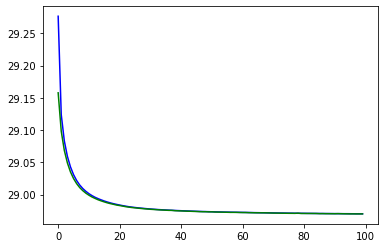

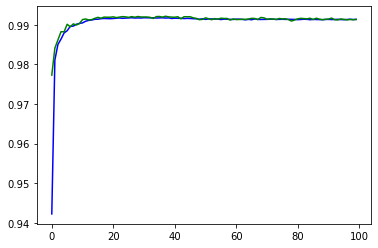

Minimum val_loss at epoch 98 = 28.9699


In [451]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [452]:
model.load_weights(save_best_weights)

In [453]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

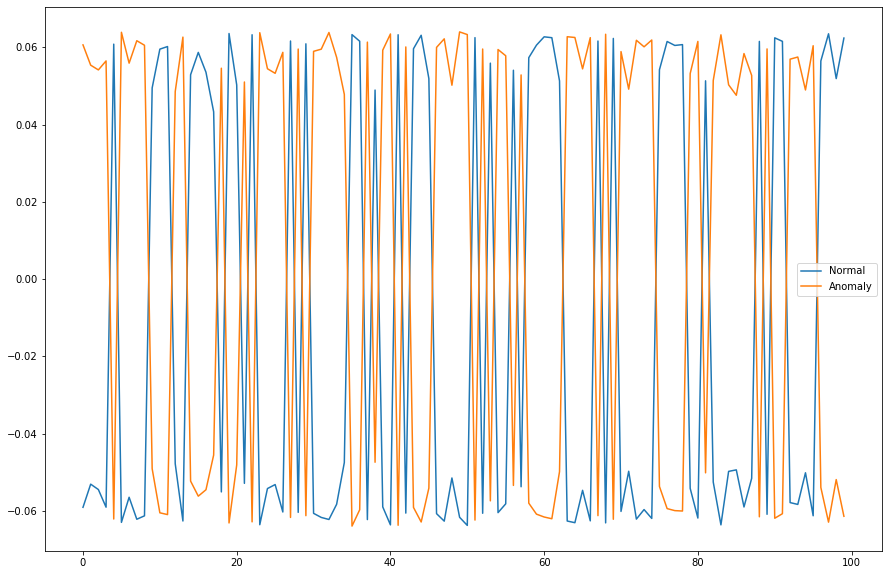

In [454]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

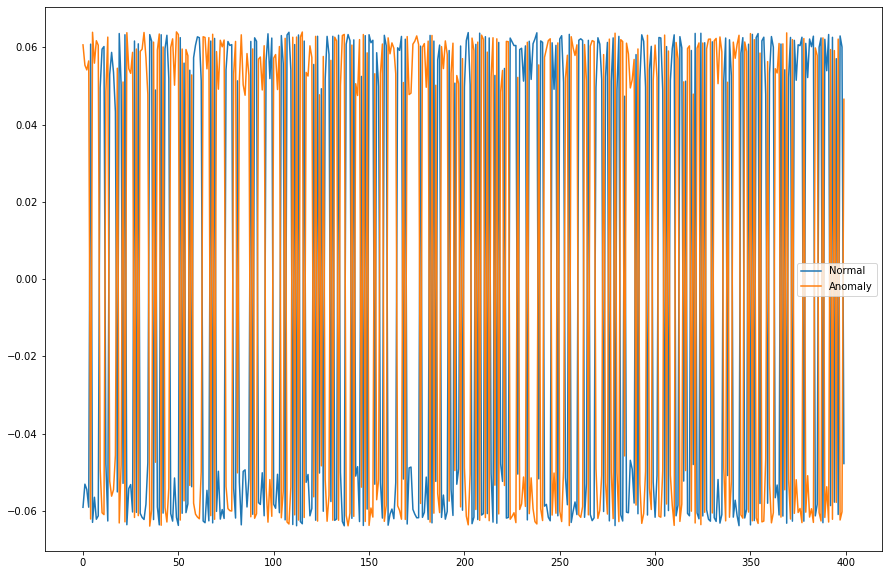

In [455]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [456]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(160092, 400)

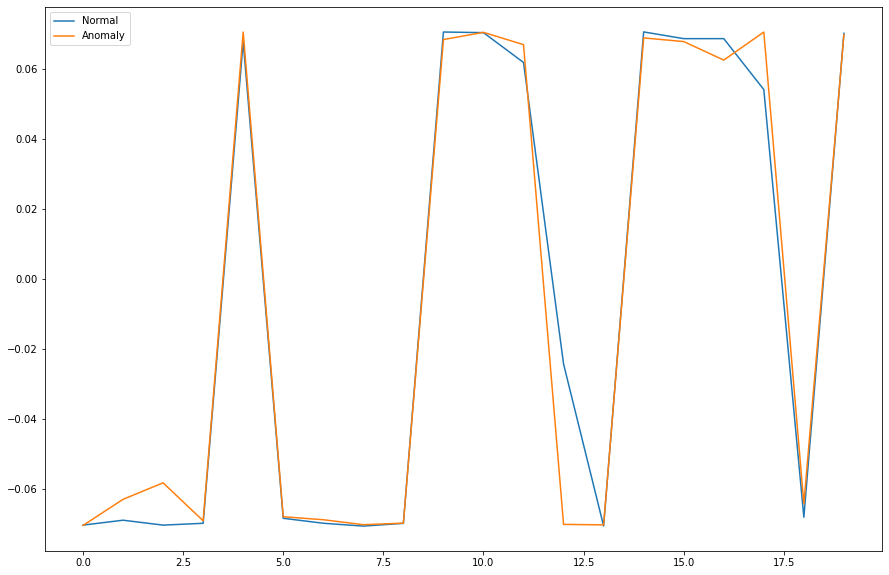

In [465]:

import matplotlib.pyplot as plt

limit = 20
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [458]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.034467


In [459]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [460]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.29639815471965936
0.5692423704755145


In [461]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.6695794889992903
F1 =  0.6182936202920829
Precision_score =  0.9028733912002395
recall_score =  0.47011610691186784
roc_auc_score =  0.9215325477803896
pr_auc =  0.9023565724473874
matthews_corr_score =  0.43729608438187806


In [468]:
threshold = 0.09
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))


attack_name = 'PROBE'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'DOS'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'NORMAL'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(1-y_test[index_single_attack],1-ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'U2R'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'R2L'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]
print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8744677075940384
F1 =  0.8902505235399054
Precision_score =  0.8861267660001544
recall_score =  0.8944128418919972
roc_auc_score =  0.9215325477803896
pr_auc =  0.9023565724473874
matthews_corr_score =  0.743684949440016
.......
 single attack PROBE
Accuracy =  1.0
F1 =  1.0
Precision_score =  1.0
recall_score =  1.0
.......
 single attack DOS
Accuracy =  0.9655403593456691
F1 =  0.9824681083293539
Precision_score =  1.0
recall_score =  0.9655403593456691
.......
 single attack NORMAL
Accuracy =  0.848110390279065
F1 =  0.9178135621552349
Precision_score =  1.0
recall_score =  0.848110390279065
.......
 single attack U2R
Accuracy =  0.8575
F1 =  0.9232839838492598
Precision_score =  1.0
recall_score =  0.8575
.......
 single attack R2L
Accuracy =  0.5924040720438528
F1 =  0.7440373739857389
Precision_score =  1.0
recall_score =  0.5924040720438528


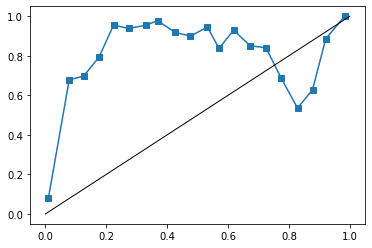

In [463]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

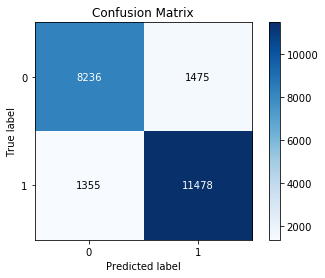

In [464]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## logloss+contractive, 
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.00001

In [261]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [262]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [263]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 3'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [264]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [265]:
def cosine_act(x):
    return tf.math.cos(x)

In [266]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [267]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [268]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [269]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [270]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [271]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [272]:
vocab_size = in_dim_label  # no usado de momento
embed_dim = 10

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [273]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.00001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [387]:
W2.numpy()

AttributeError: 'Tensor' object has no attribute 'numpy'

In [388]:
model.summary()

Model: "model_57"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_13 (InputLayer)           [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_14 (InputLayer)           [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_13[0][0]                   
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_14[0][0]                   
___________________________________________________________________________________________

In [389]:
model_embed_x.summary()

Model: "model_58"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_13 (InputLayer)        [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [390]:
model_embed_label.summary()

Model: "model_59"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_14 (InputLayer)        [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [391]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [392]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 10s 51us/sample - loss: 3.2470 - accuracy: 0.9436 - val_loss: 3.1344 - val_accuracy: 0.9782
Epoch 2/100
201556/201556 [==============================] - 10s 49us/sample - loss: 3.0944 - accuracy: 0.9815 - val_loss: 3.0680 - val_accuracy: 0.9839
Epoch 3/100
201556/201556 [==============================] - 10s 49us/sample - loss: 3.0514 - accuracy: 0.9840 - val_loss: 3.0394 - val_accuracy: 0.9853
Epoch 4/100
201556/201556 [==============================] - 10s 48us/sample - loss: 3.0305 - accuracy: 0.9849 - val_loss: 3.0234 - val_accuracy: 0.9853
Epoch 5/100
201556/201556 [==============================] - 9s 47us/sample - loss: 3.0179 - accuracy: 0.9856 - val_loss: 3.0132 - val_accuracy: 0.9867
Epoch 6/100
201556/201556 [==============================] - 9s 47us/sample - loss: 3.0095 - accuracy: 0.9870 - val_loss: 3.0062 - val_accuracy: 0.9878
Epoch 7/100
201556/201556 [======

Epoch 54/100
201556/201556 [==============================] - 10s 48us/sample - loss: 2.9738 - accuracy: 0.9944 - val_loss: 2.9737 - val_accuracy: 0.9945
Epoch 55/100
201556/201556 [==============================] - 10s 47us/sample - loss: 2.9737 - accuracy: 0.9945 - val_loss: 2.9737 - val_accuracy: 0.9945
Epoch 56/100
201556/201556 [==============================] - 10s 48us/sample - loss: 2.9737 - accuracy: 0.9945 - val_loss: 2.9736 - val_accuracy: 0.9945
Epoch 57/100
201556/201556 [==============================] - 9s 47us/sample - loss: 2.9736 - accuracy: 0.9944 - val_loss: 2.9736 - val_accuracy: 0.9945
Epoch 58/100
201556/201556 [==============================] - 10s 49us/sample - loss: 2.9736 - accuracy: 0.9945 - val_loss: 2.9735 - val_accuracy: 0.9944
Epoch 59/100
201556/201556 [==============================] - 10s 48us/sample - loss: 2.9735 - accuracy: 0.9945 - val_loss: 2.9734 - val_accuracy: 0.9945
Epoch 60/100
201556/201556 [==============================] - 9s 47us/sample 

In [393]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [394]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

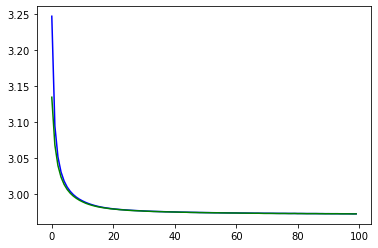

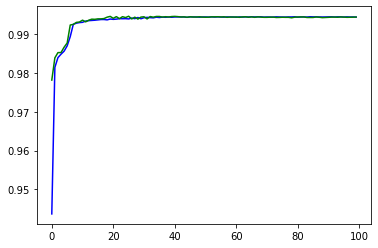

Minimum val_loss at epoch 99 = 2.9721


In [395]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [208]:
model.load_weights(save_best_weights)

In [209]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

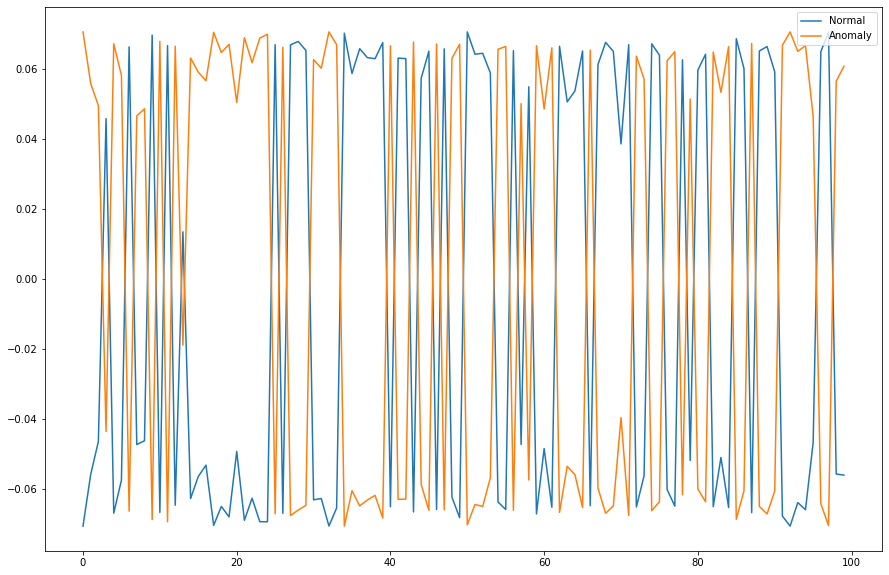

In [210]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

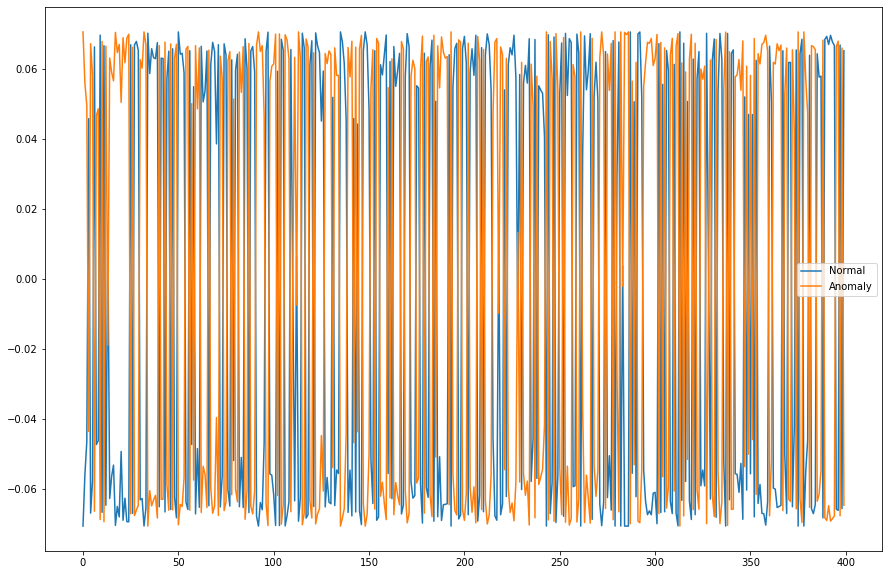

In [211]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [212]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(251946, 400)

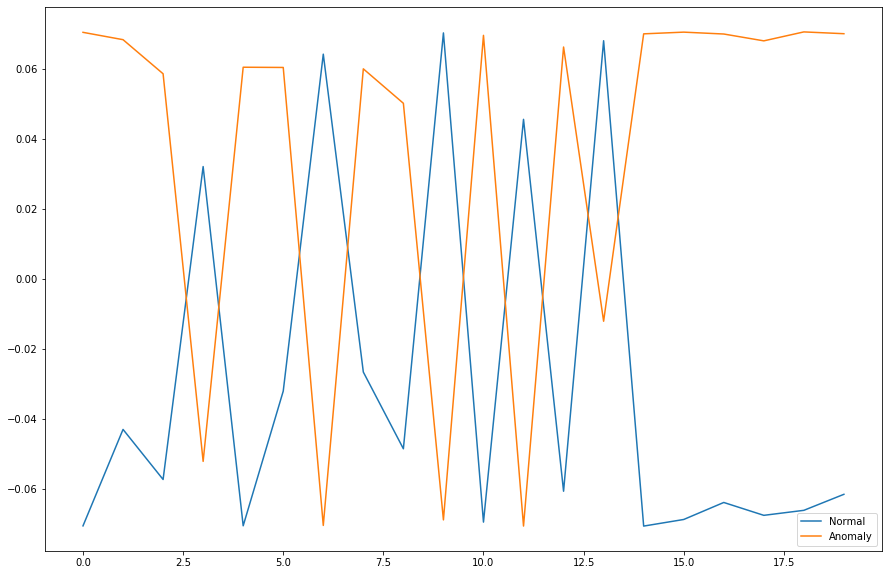

In [214]:

import matplotlib.pyplot as plt

limit = 20
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [426]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.032641


In [402]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [403]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.3785929737402413
0.5692423704755145


In [404]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7845102909865153
F1 =  0.7726506926244852
Precision_score =  0.9671939074399531
recall_score =  0.6432634613886075
roc_auc_score =  0.9529495620663064
pr_auc =  0.9614929480238118
matthews_corr_score =  0.6272826607780463


In [423]:
threshold = 0.16
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.9013041163946061
F1 =  0.9151508217976585
Precision_score =  0.8961165048543689
recall_score =  0.9350112989947791
roc_auc_score =  0.9529495620663064
pr_auc =  0.9614929480238118
matthews_corr_score =  0.7983627991005646


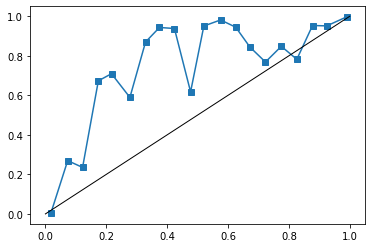

In [406]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

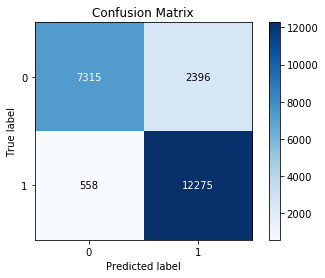

In [407]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## Graficas training dataset

In [274]:
model.load_weights(save_best_weights)

In [275]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [276]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9997751335285183

In [277]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [278]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

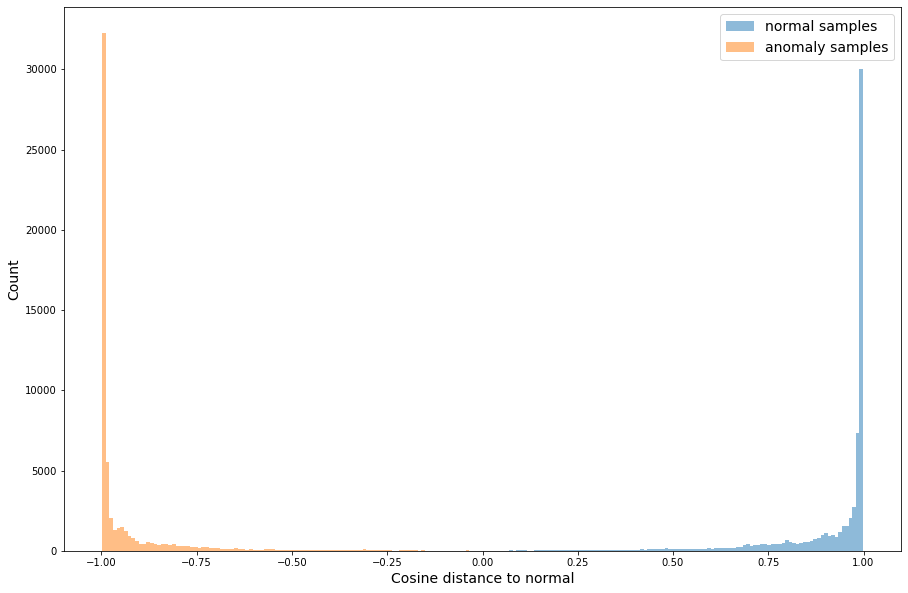

In [279]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, training dataset

In [296]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [297]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


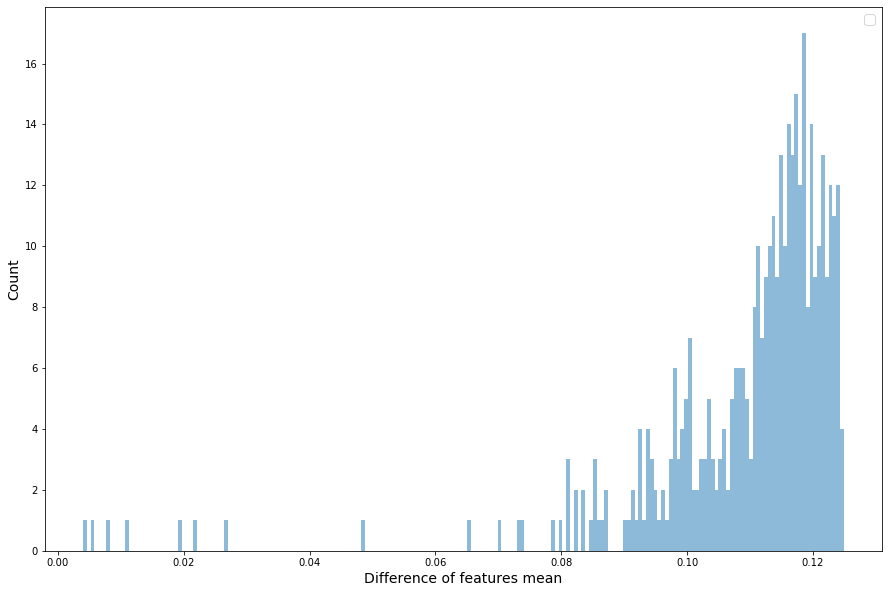

In [298]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [299]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

127.35309770137984 0.0


## Graficas Test dataset

In [285]:
model.load_weights(save_best_weights)

In [286]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [287]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9997751335285183

In [288]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [289]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

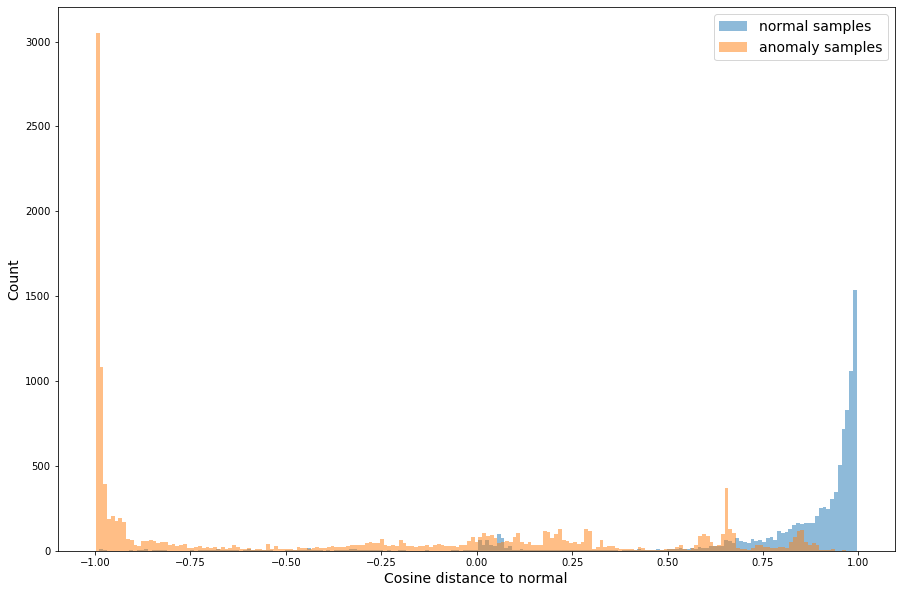

In [290]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, test dataset

In [291]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [292]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


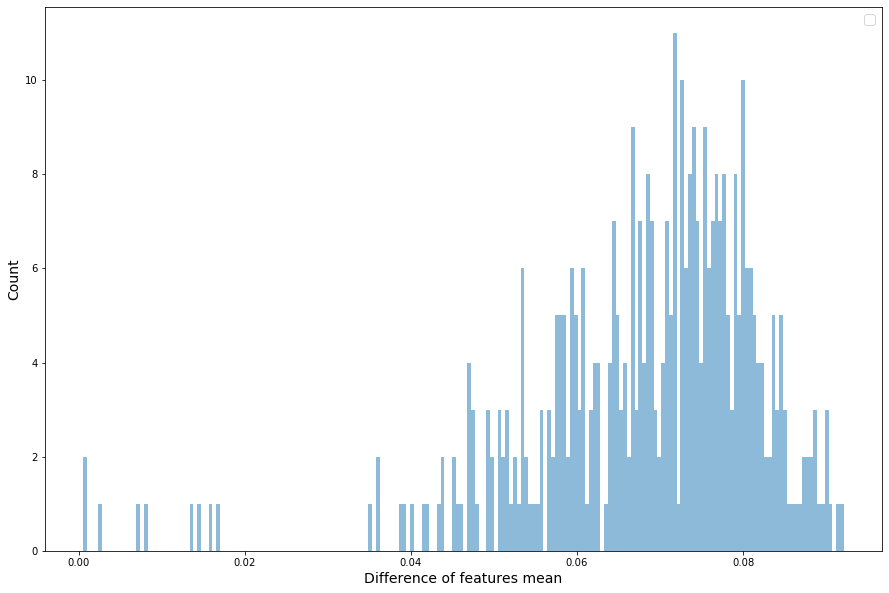

In [293]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [295]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

93.17668384357071 7.216400281495056e-273


## logloss+contractive, 
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.000001

In [156]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [157]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [158]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 4'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [159]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [160]:
def cosine_act(x):
    return tf.math.cos(x)

In [161]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [162]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [163]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [164]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [165]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [166]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [167]:
vocab_size = in_dim_label  # no usado de momento
embed_dim = 10

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [168]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.000001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [458]:
W2.numpy()

AttributeError: 'Tensor' object has no attribute 'numpy'

In [169]:
model.summary()

Model: "model_6"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_11 (InputLayer)           [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_12 (InputLayer)           [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_11[0][0]                   
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_12[0][0]                   
____________________________________________________________________________________________

In [170]:
model_embed_x.summary()

Model: "model_7"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_11 (InputLayer)        [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [459]:
model_embed_label.summary()

Model: "model_65"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_18 (InputLayer)        [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [460]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [461]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 11s 54us/sample - loss: 0.6091 - accuracy: 0.9505 - val_loss: 0.4989 - val_accuracy: 0.9794
Epoch 2/100
201556/201556 [==============================] - 10s 51us/sample - loss: 0.4606 - accuracy: 0.9815 - val_loss: 0.4351 - val_accuracy: 0.9836
Epoch 3/100
201556/201556 [==============================] - 10s 51us/sample - loss: 0.4192 - accuracy: 0.9837 - val_loss: 0.4078 - val_accuracy: 0.9854
Epoch 4/100
201556/201556 [==============================] - 10s 49us/sample - loss: 0.3993 - accuracy: 0.9852 - val_loss: 0.3927 - val_accuracy: 0.9860
Epoch 5/100
201556/201556 [==============================] - 10s 48us/sample - loss: 0.3873 - accuracy: 0.9865 - val_loss: 0.3829 - val_accuracy: 0.9876
Epoch 6/100
201556/201556 [==============================] - 10s 47us/sample - loss: 0.3793 - accuracy: 0.9880 - val_loss: 0.3762 - val_accuracy: 0.9887
Epoch 7/100
201556/201556 [====

Epoch 54/100
201556/201556 [==============================] - 9s 47us/sample - loss: 0.3431 - accuracy: 0.9947 - val_loss: 0.3430 - val_accuracy: 0.9945
Epoch 55/100
201556/201556 [==============================] - 9s 47us/sample - loss: 0.3431 - accuracy: 0.9947 - val_loss: 0.3431 - val_accuracy: 0.9946
Epoch 56/100
201556/201556 [==============================] - 10s 47us/sample - loss: 0.3430 - accuracy: 0.9947 - val_loss: 0.3429 - val_accuracy: 0.9946
Epoch 57/100
201556/201556 [==============================] - 9s 47us/sample - loss: 0.3429 - accuracy: 0.9947 - val_loss: 0.3428 - val_accuracy: 0.9946
Epoch 58/100
201556/201556 [==============================] - 9s 47us/sample - loss: 0.3428 - accuracy: 0.9947 - val_loss: 0.3427 - val_accuracy: 0.9945
Epoch 59/100
201556/201556 [==============================] - 10s 47us/sample - loss: 0.3428 - accuracy: 0.9947 - val_loss: 0.3427 - val_accuracy: 0.9945
Epoch 60/100
201556/201556 [==============================] - 10s 48us/sample - 

In [462]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [463]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

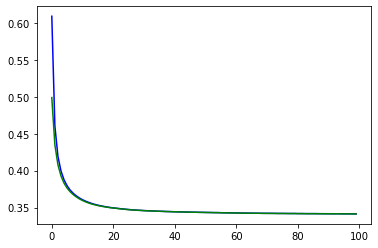

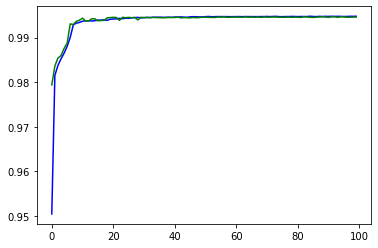

Minimum val_loss at epoch 99 = 0.3413


In [464]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [171]:
model.load_weights(save_best_weights)

In [172]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

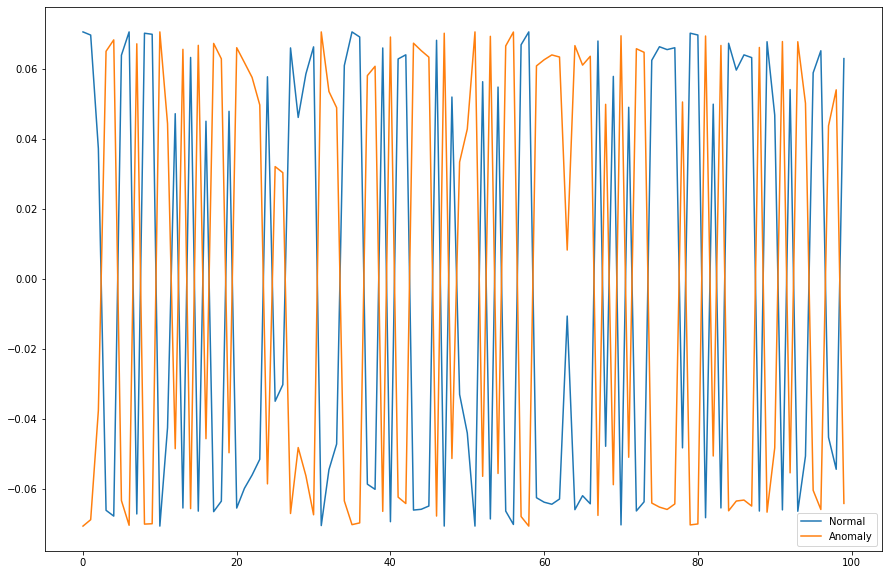

In [173]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

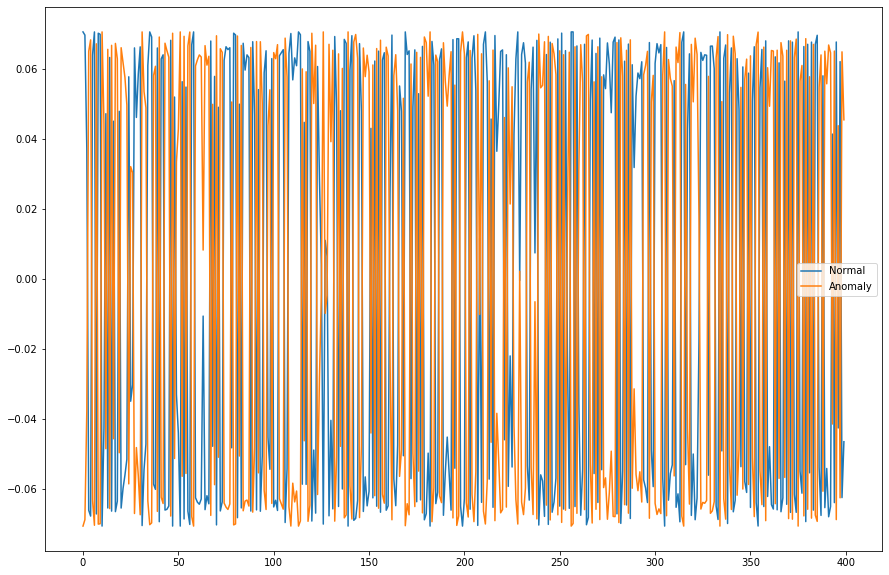

In [174]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [175]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(251946, 400)

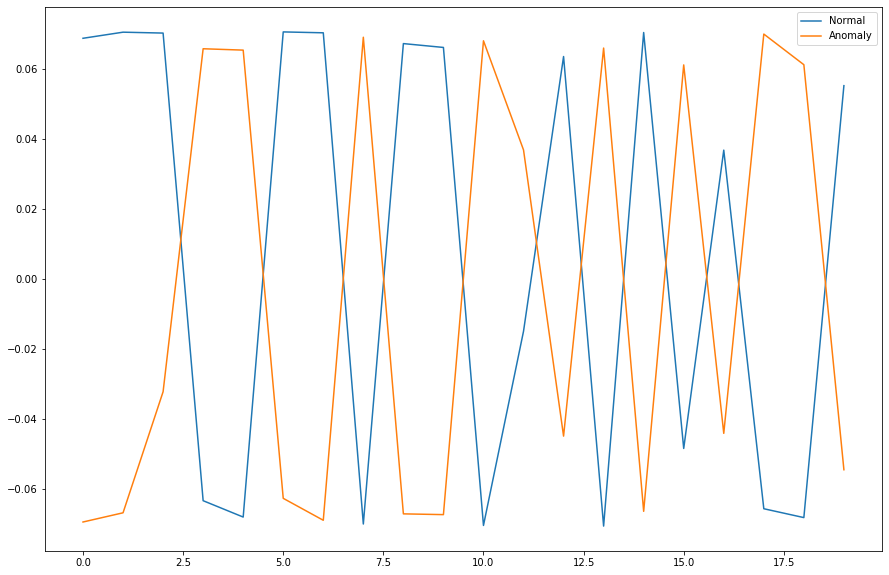

In [178]:

import matplotlib.pyplot as plt

limit = 20
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [490]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.033565


In [471]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [472]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.38435947480482613
0.5692423704755145


In [473]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7667672107877928
F1 =  0.7554191087543026
Precision_score =  0.9371032890940566
recall_score =  0.6327437076287695
roc_auc_score =  0.9478582559382343
pr_auc =  0.957825641950569
matthews_corr_score =  0.5869806005478725


In [485]:
threshold = 0.12
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8852909865152591
F1 =  0.9038232668848557
Precision_score =  0.8645321949484169
recall_score =  0.9468557624873374
roc_auc_score =  0.9478582559382343
pr_auc =  0.957825641950569
matthews_corr_score =  0.7673094403211246


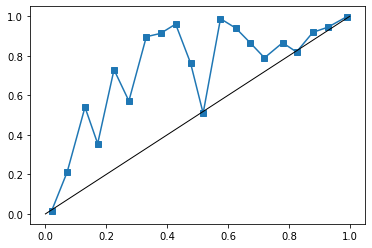

In [486]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

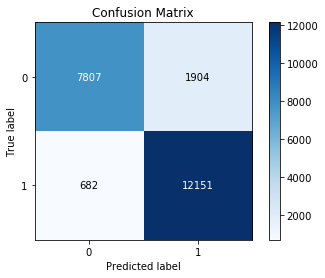

In [487]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## logloss
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = NA

In [300]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [301]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [302]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 1_1'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [303]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [304]:
def cosine_act(x):
    return tf.math.cos(x)

In [305]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [306]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [307]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [308]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [309]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [310]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)

    return (logloss)



In [311]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [312]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.00001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [504]:
W2.numpy()

AttributeError: 'Tensor' object has no attribute 'numpy'

In [505]:
model.summary()

Model: "model_66"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_19 (InputLayer)           [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_20 (InputLayer)           [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_19[0][0]                   
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_20[0][0]                   
___________________________________________________________________________________________

In [506]:
model_embed_x.summary()

Model: "model_67"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_19 (InputLayer)        [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [507]:
model_embed_label.summary()

Model: "model_68"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_20 (InputLayer)        [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [508]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [509]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 11s 53us/sample - loss: 0.3229 - accuracy: 0.9429 - val_loss: 0.2124 - val_accuracy: 0.9779
Epoch 2/100
201556/201556 [==============================] - 9s 45us/sample - loss: 0.1730 - accuracy: 0.9807 - val_loss: 0.1465 - val_accuracy: 0.9830
Epoch 3/100
201556/201556 [==============================] - 9s 46us/sample - loss: 0.1295 - accuracy: 0.9838 - val_loss: 0.1170 - val_accuracy: 0.9851
Epoch 4/100
201556/201556 [==============================] - 9s 47us/sample - loss: 0.1079 - accuracy: 0.9854 - val_loss: 0.1006 - val_accuracy: 0.9856
Epoch 5/100
201556/201556 [==============================] - 9s 46us/sample - loss: 0.0950 - accuracy: 0.9865 - val_loss: 0.0901 - val_accuracy: 0.9874
Epoch 6/100
201556/201556 [==============================] - 9s 47us/sample - loss: 0.0863 - accuracy: 0.9882 - val_loss: 0.0829 - val_accuracy: 0.9887
Epoch 7/100
201556/201556 [=========

In [510]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [511]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

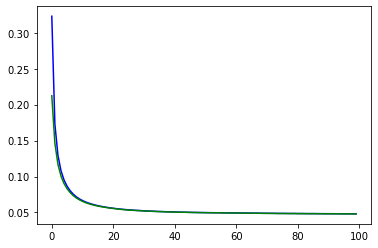

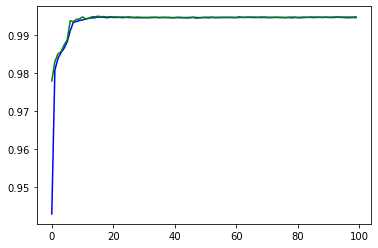

Minimum val_loss at epoch 99 = 0.0480


In [512]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [108]:
model.load_weights(save_best_weights)

In [109]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

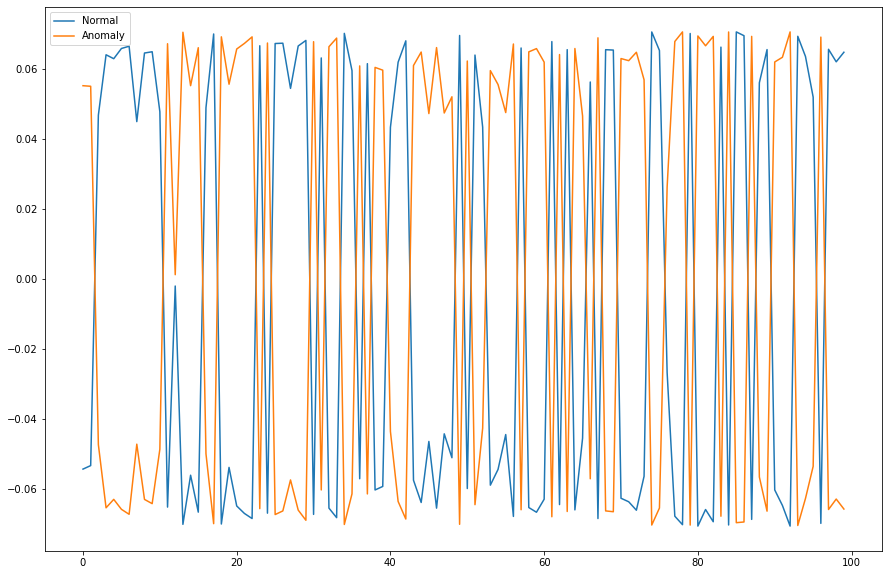

In [110]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

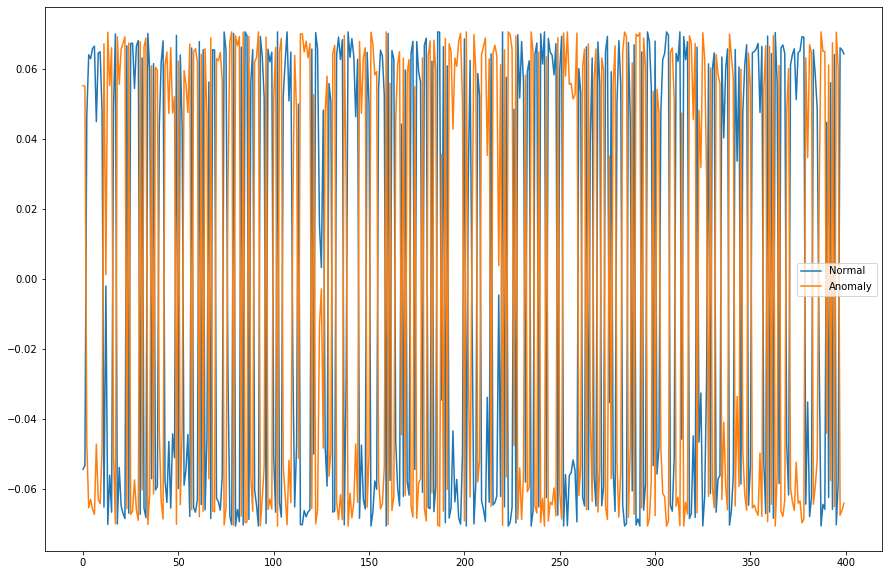

In [111]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [112]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(125973, 400)

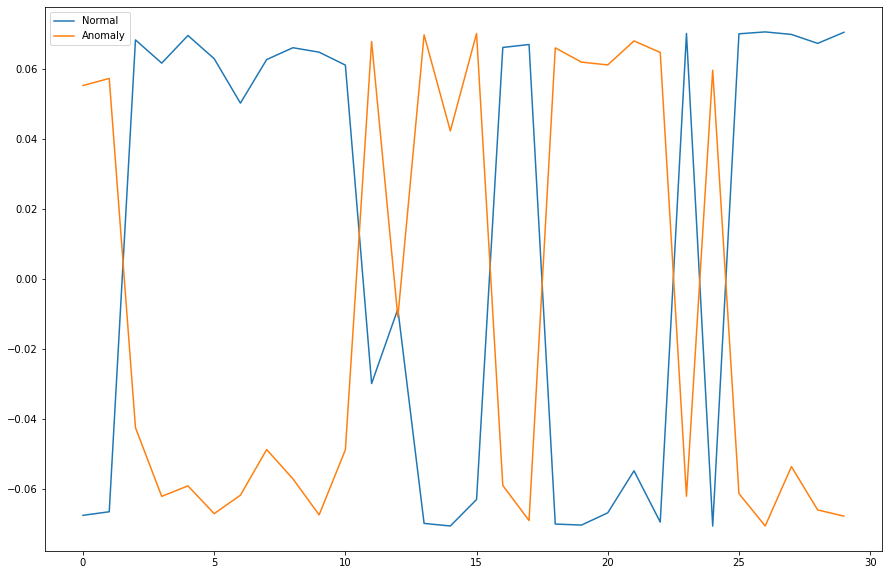

In [113]:

import matplotlib.pyplot as plt

limit = 30
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [91]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.032796


In [92]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [93]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.3734474804826118
0.5692423704755145


In [94]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7796309439318666
F1 =  0.7662337662337663
Precision_score =  0.9670982301936097
recall_score =  0.6344580378711135
roc_auc_score =  0.9492269950754711
pr_auc =  0.9590745553087281
matthews_corr_score =  0.6202927239716158


In [95]:
threshold = 0.09
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.868124556422995
F1 =  0.8914448460948625
Precision_score =  0.8387384911364574
recall_score =  0.9512195121951219
roc_auc_score =  0.9492269950754711
pr_auc =  0.9590745553087281
matthews_corr_score =  0.7345226885742188


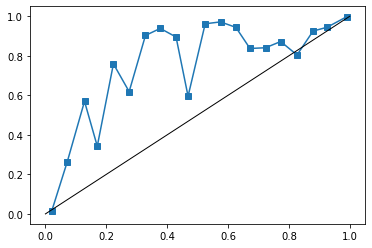

In [96]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

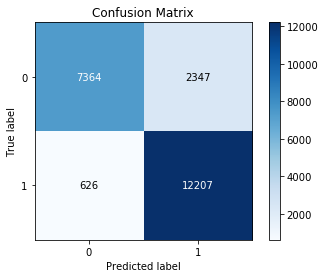

In [97]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## Graficas Training dataset

In [317]:
model.load_weights(save_best_weights)

In [318]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [319]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9998293023243188

In [320]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [321]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

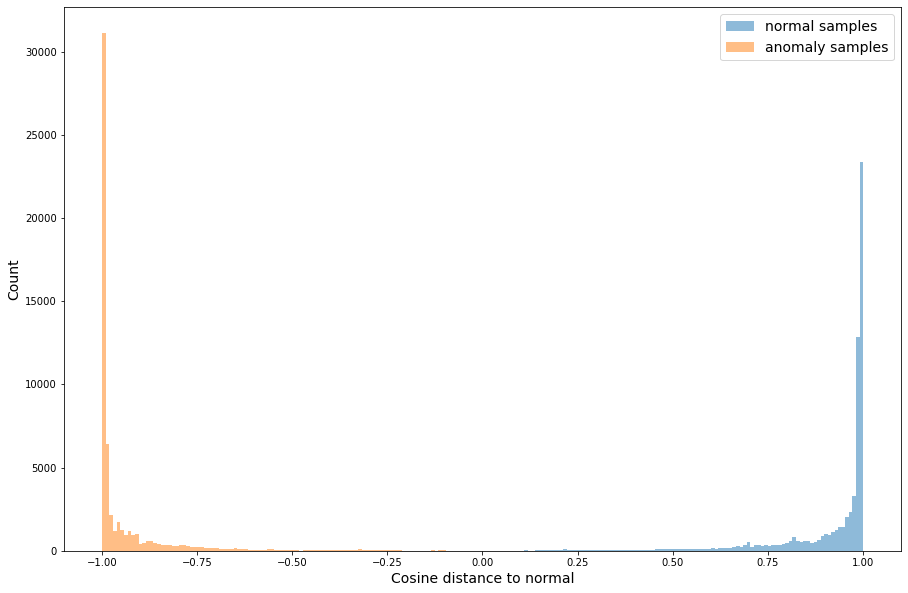

In [322]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, training dataset

In [323]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [324]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


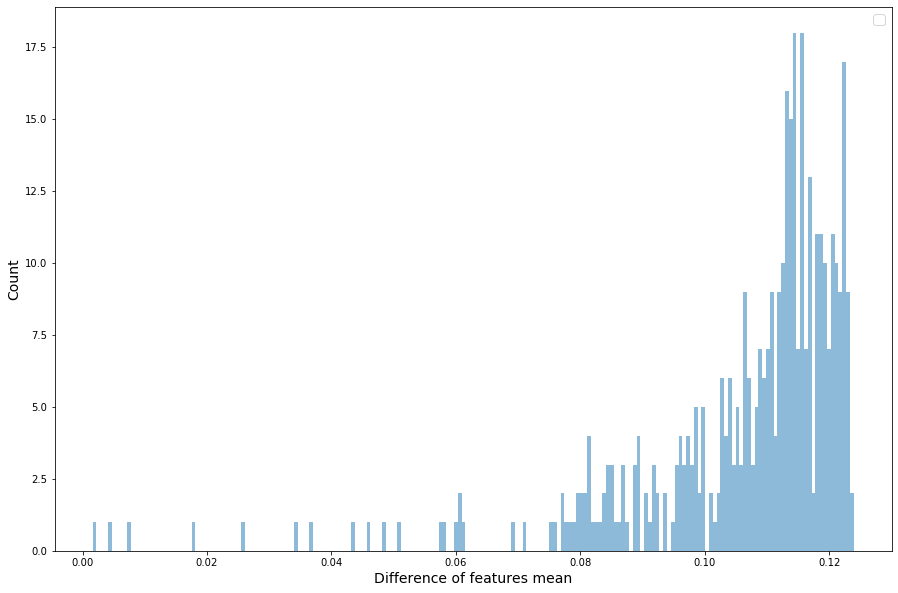

In [325]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [326]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

112.73118425337596 1.142694646616419e-304


## Graficas Test dataset

In [327]:
model.load_weights(save_best_weights)

In [328]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [329]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9998293023243188

In [330]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [331]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

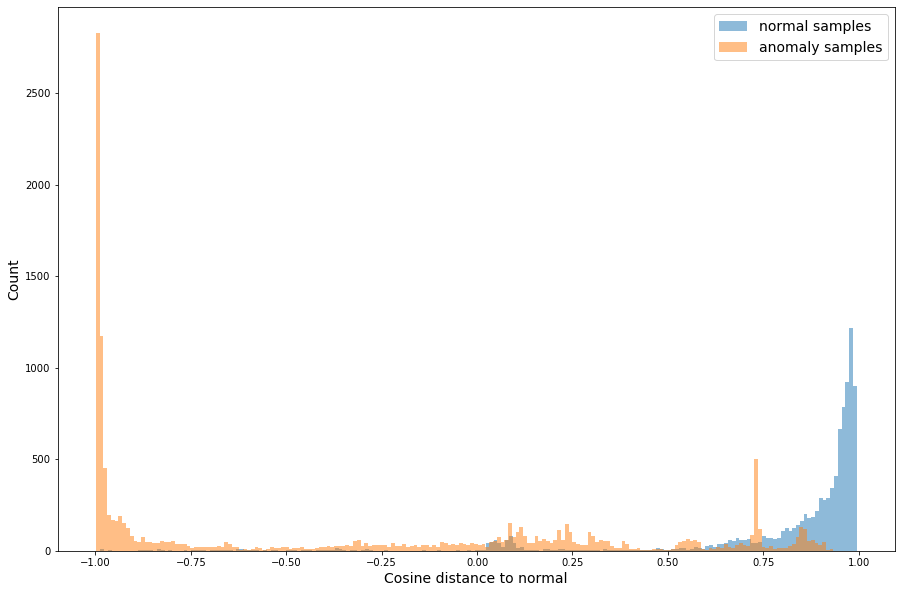

In [332]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, test dataset

In [333]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [334]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


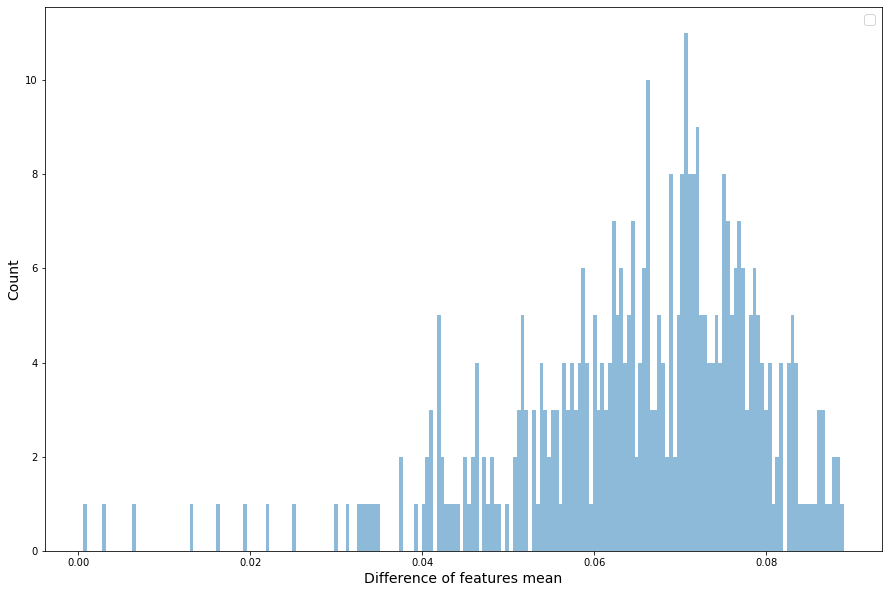

In [335]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [336]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

90.36871903853144 8.343681339890424e-268


## logloss + L2 regularization
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = NA

In [190]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [191]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [192]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 1_1reg 1'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [193]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [194]:
def cosine_act(x):
    return tf.math.cos(x)

In [195]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [196]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [197]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [198]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [199]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [200]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)

    return (logloss)



In [201]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val,L2reg):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x, 
                      kernel_regularizer=tf.keras.regularizers.l2(L2reg),
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l, 
                      kernel_regularizer=tf.keras.regularizers.l2(L2reg),
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [205]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.00001
L2reg = 0.01

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val,L2reg)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
#model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])
model.compile(loss='binary_crossentropy', optimizer=Adam(0.001), metrics=['accuracy'])

In [206]:
W2.numpy()

AttributeError: 'Tensor' object has no attribute 'numpy'

In [207]:
model.summary()

Model: "model_9"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_7 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_8 (InputLayer)            [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_7[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_8[0][0]                    
____________________________________________________________________________________________

In [208]:
model_embed_x.summary()

Model: "model_10"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_7 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [209]:
model_embed_label.summary()

Model: "model_11"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_8 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [210]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [211]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 9s 45us/sample - loss: 1656.7747 - accuracy: 0.8193 - val_loss: 804.3053 - val_accuracy: 0.8295
Epoch 2/100
201556/201556 [==============================] - 9s 44us/sample - loss: 433.6690 - accuracy: 0.9166 - val_loss: 190.1249 - val_accuracy: 0.8463
Epoch 3/100
201556/201556 [==============================] - 9s 43us/sample - loss: 93.1047 - accuracy: 0.9075 - val_loss: 34.2020 - val_accuracy: 0.8860
Epoch 4/100
201556/201556 [==============================] - 8s 42us/sample - loss: 14.8693 - accuracy: 0.9192 - val_loss: 4.3670 - val_accuracy: 0.9421
Epoch 5/100
201556/201556 [==============================] - 9s 42us/sample - loss: 1.6884 - accuracy: 0.9683 - val_loss: 0.4188 - val_accuracy: 0.9742
Epoch 6/100
201556/201556 [==============================] - 9s 43us/sample - loss: 0.2059 - accuracy: 0.9763 - val_loss: 0.1365 - val_accuracy: 0.9785
Epoch 7/100
201556/201556

In [212]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [213]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

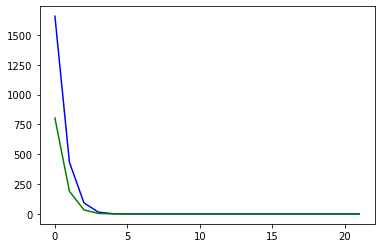

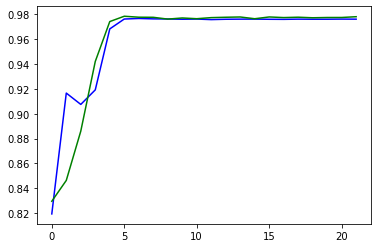

Minimum val_loss at epoch 12 = 0.1101


In [214]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [215]:
model.load_weights(save_best_weights)

In [216]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

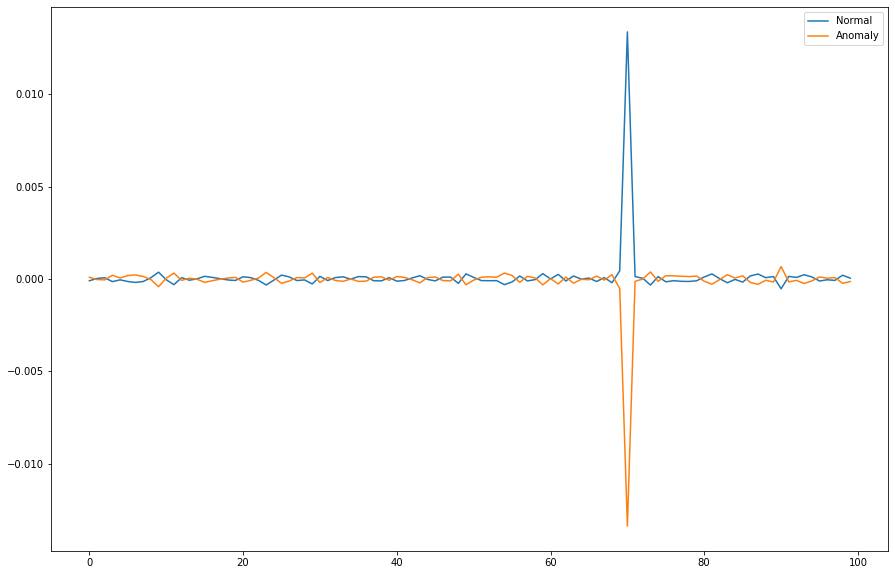

In [217]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

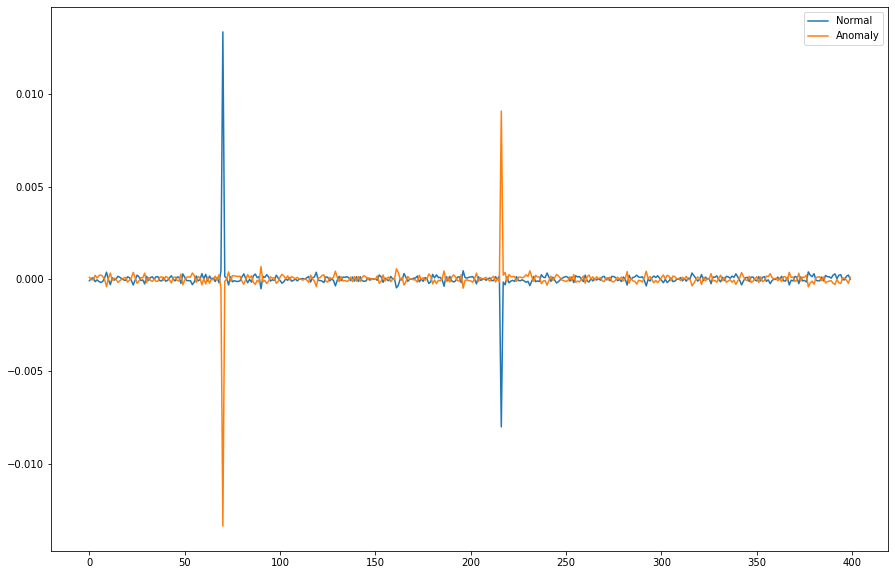

In [218]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [219]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(251946, 400)

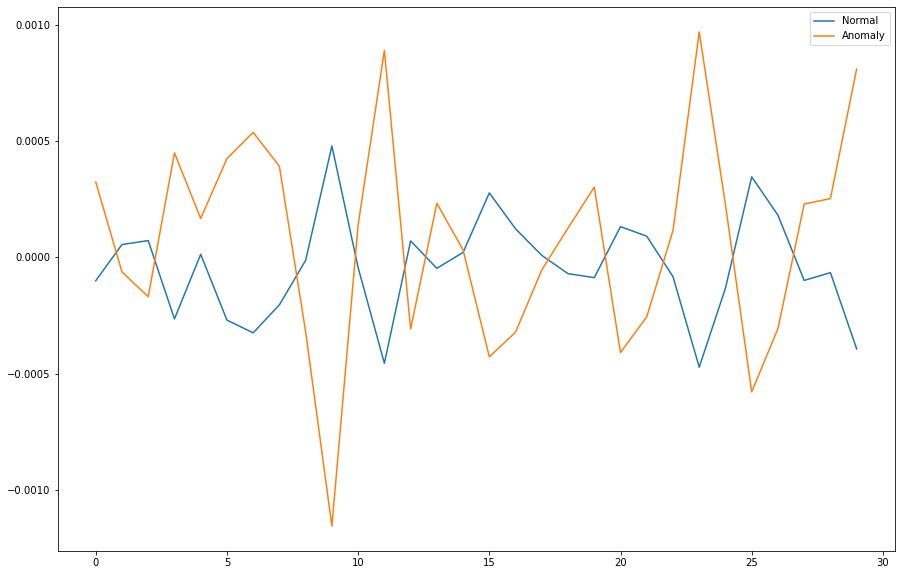

In [220]:

import matplotlib.pyplot as plt

limit = 30
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [221]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.030596


In [222]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [223]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.37979063165365506
0.5692423704755145


In [224]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7478264726756565
F1 =  0.7342837111474645
Precision_score =  0.9174258350852604
recall_score =  0.6120938206187174
roc_auc_score =  0.8515956542664794
pr_auc =  0.9099685853362125
matthews_corr_score =  0.5502322061041797


In [255]:
threshold = 0.04
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7690294535131299
F1 =  0.8090225563909774
Precision_score =  0.7642045454545454
recall_score =  0.8594249201277955
roc_auc_score =  0.8515956542664794
pr_auc =  0.9099685853362125
matthews_corr_score =  0.5251514292857631


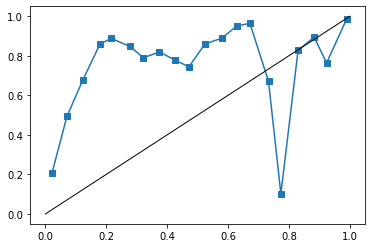

In [256]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

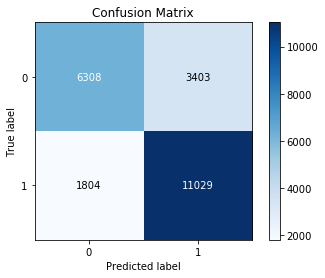

In [257]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## Graficas Training dataset

In [258]:
model.load_weights(save_best_weights)

In [259]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [260]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9979214852631849

In [261]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [262]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

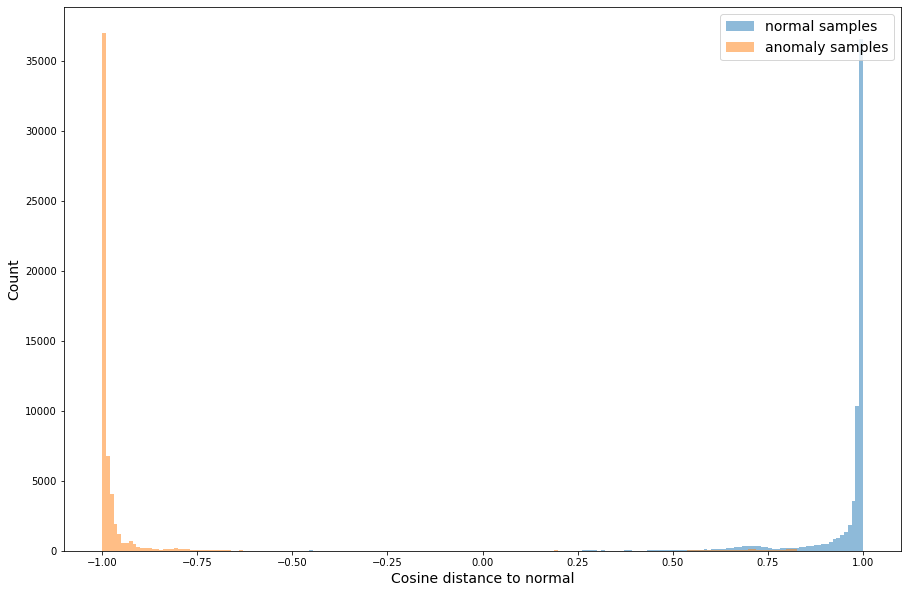

In [263]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, training dataset

In [264]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [265]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


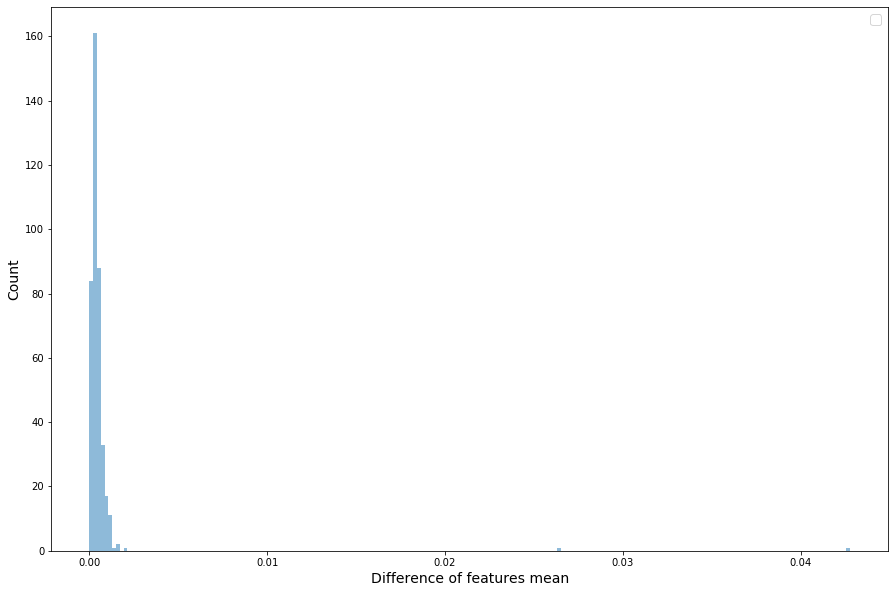

In [266]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [267]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

4.7433899220431845 2.9313732247747885e-06


## Graficas Test dataset

In [268]:
model.load_weights(save_best_weights)

In [269]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [270]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9979214852631849

In [271]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [272]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

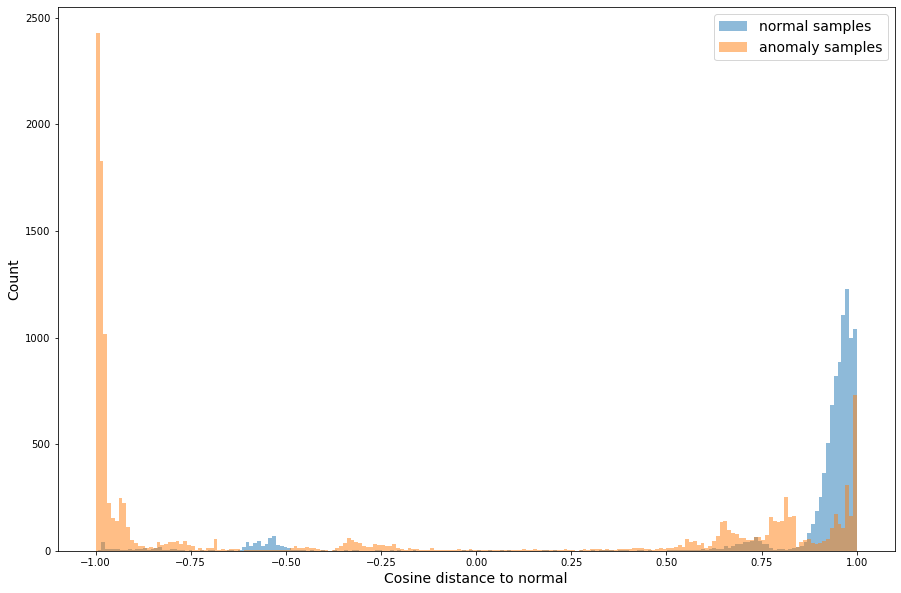

In [273]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, test dataset

In [274]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [275]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


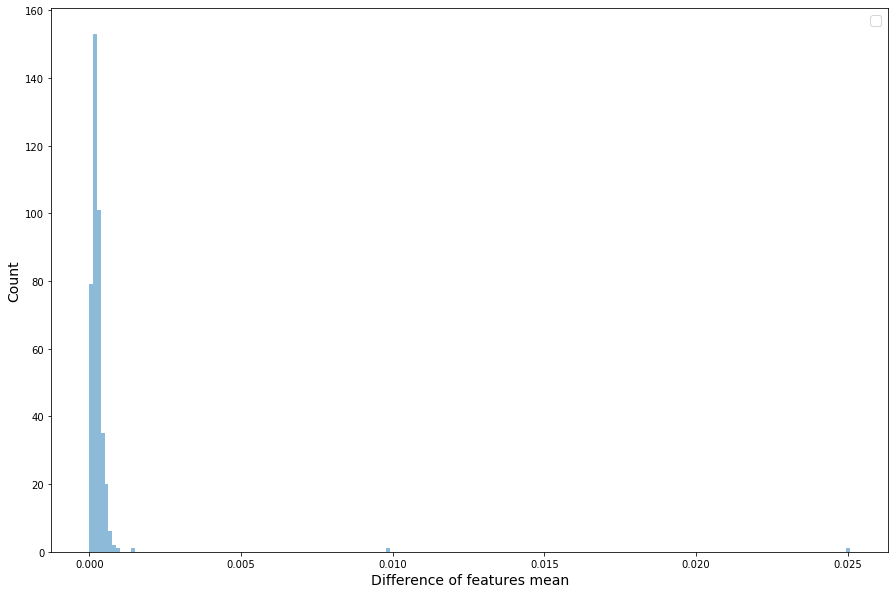

In [276]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [277]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

5.087496642906202 5.596368877502291e-07


## logloss + L2 regularization
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = NA

In [487]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [488]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [489]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 1_1reg 2'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [490]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [491]:
def cosine_act(x):
    return tf.math.cos(x)

In [492]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [493]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [494]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [495]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [496]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [497]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)

    return (logloss)



In [498]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val,L2reg):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x, 
                      kernel_regularizer=tf.keras.regularizers.l2(L2reg),
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l, 
                      kernel_regularizer=tf.keras.regularizers.l2(L2reg),
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [499]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.00001
L2reg = 0.1

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val,L2reg)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
#model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])
model.compile(loss='binary_crossentropy', optimizer=Adam(0.001), metrics=['accuracy'])

In [291]:
W2.numpy()

AttributeError: 'Tensor' object has no attribute 'numpy'

In [292]:
model.summary()

Model: "model_12"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_9 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_10 (InputLayer)           [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_9[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_10[0][0]                   
___________________________________________________________________________________________

In [293]:
model_embed_x.summary()

Model: "model_13"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_9 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [294]:
model_embed_label.summary()

Model: "model_14"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_10 (InputLayer)        [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [295]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [296]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 9s 47us/sample - loss: 16693.4248 - accuracy: 0.7992 - val_loss: 8147.5861 - val_accuracy: 0.8053
Epoch 2/100
201556/201556 [==============================] - 9s 43us/sample - loss: 4415.0314 - accuracy: 0.8872 - val_loss: 1952.2545 - val_accuracy: 0.8516
Epoch 3/100
201556/201556 [==============================] - 9s 44us/sample - loss: 963.3887 - accuracy: 0.8975 - val_loss: 358.2666 - val_accuracy: 0.8091
Epoch 4/100
201556/201556 [==============================] - 9s 43us/sample - loss: 158.0693 - accuracy: 0.9115 - val_loss: 47.6159 - val_accuracy: 0.8587
Epoch 5/100
201556/201556 [==============================] - 9s 43us/sample - loss: 18.5100 - accuracy: 0.9269 - val_loss: 4.2347 - val_accuracy: 0.9591
Epoch 6/100
201556/201556 [==============================] - 9s 43us/sample - loss: 1.4537 - accuracy: 0.9709 - val_loss: 0.3139 - val_accuracy: 0.9758
Epoch 7/100
2015

In [297]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [298]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

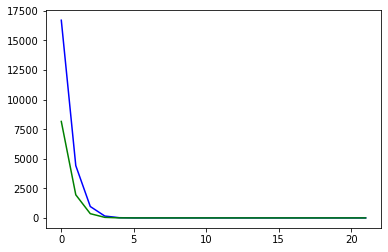

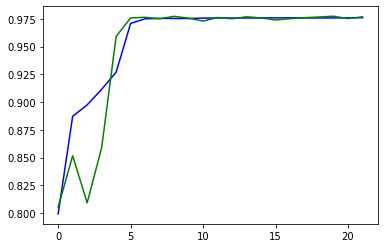

Minimum val_loss at epoch 12 = 0.0975


In [299]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [300]:
model.load_weights(save_best_weights)

In [301]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

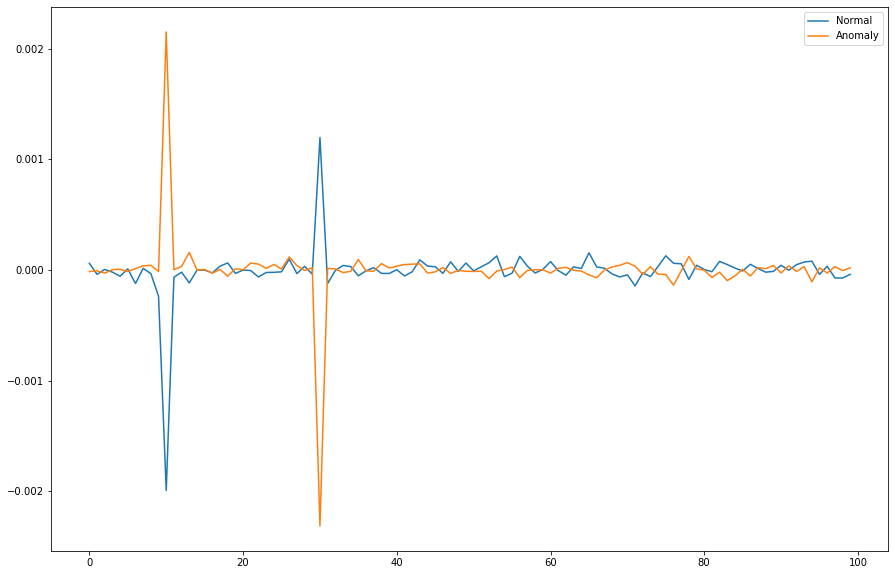

In [302]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

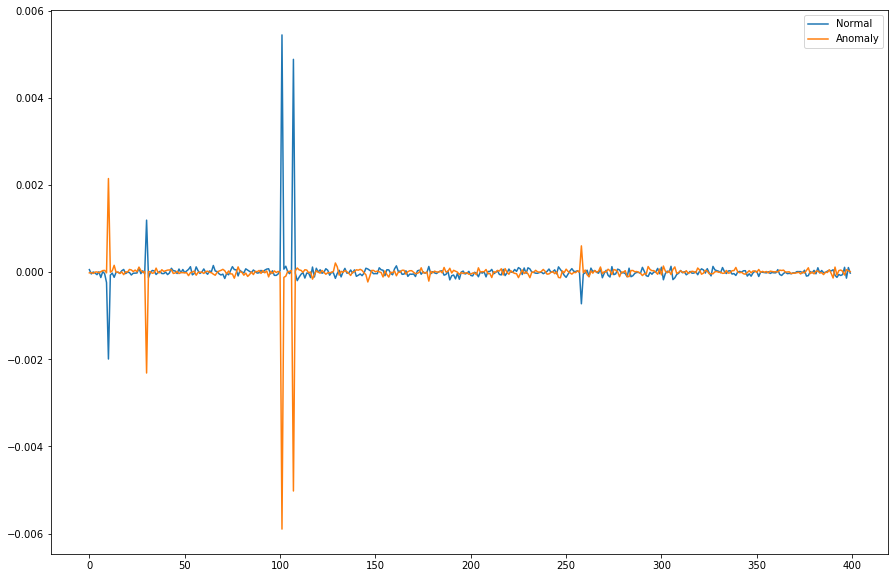

In [303]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [304]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(251946, 400)

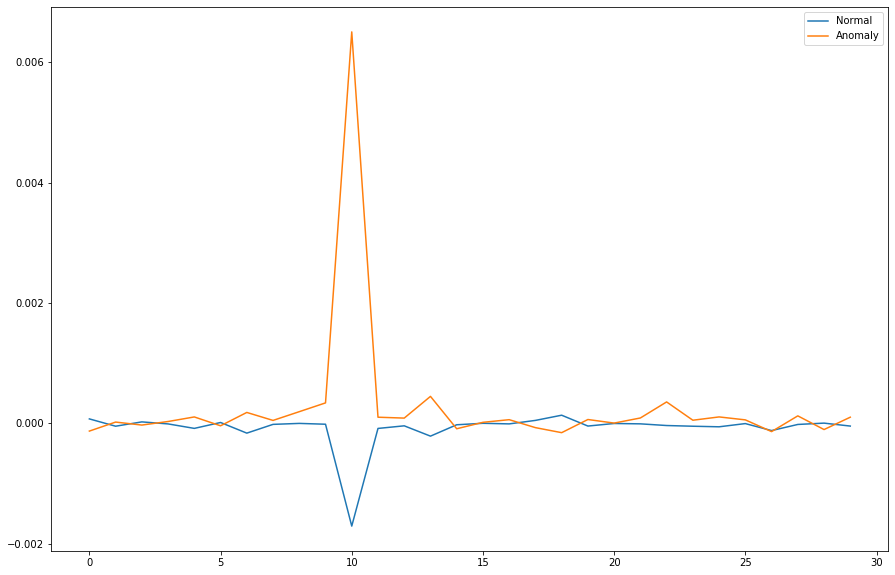

In [305]:

import matplotlib.pyplot as plt

limit = 30
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [500]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.034270


In [501]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [502]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.3675922640170334
0.5692423704755145


In [503]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7322569198012775
F1 =  0.7142045454545455
Precision_score =  0.9101001568722095
recall_score =  0.5877035767162784
roc_auc_score =  0.8004818648002308
pr_auc =  0.8755824355921917
matthews_corr_score =  0.5247986575849368


In [504]:
threshold = 0.04
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))


attack_name = 'PROBE'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'DOS'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'NORMAL'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(1-y_test[index_single_attack],1-ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'U2R'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'R2L'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]
print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8303317955997161
F1 =  0.843205574912892
Precision_score =  0.8895519806261892
recall_score =  0.8014493882957999
roc_auc_score =  0.8004818648002308
pr_auc =  0.8755824355921917
matthews_corr_score =  0.663713472401501
.......
 single attack PROBE
Accuracy =  0.9756299049979348
F1 =  0.9876646456199037
Precision_score =  1.0
recall_score =  0.9756299049979348
.......
 single attack DOS
Accuracy =  0.8994368463395012
F1 =  0.9470563320626852
Precision_score =  1.0
recall_score =  0.8994368463395012
.......
 single attack NORMAL
Accuracy =  0.8684996395839769
F1 =  0.9296224855332048
Precision_score =  1.0
recall_score =  0.8684996395839769
.......
 single attack U2R
Accuracy =  0.165
F1 =  0.2832618025751073
Precision_score =  1.0
recall_score =  0.165
.......
 single attack R2L
Accuracy =  0.4498825371965544
F1 =  0.6205779098028625
Precision_score =  1.0
recall_score =  0.4498825371965544


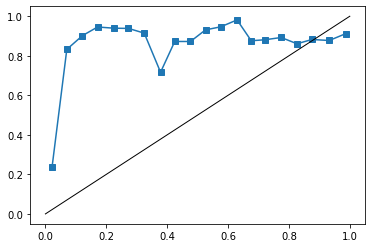

In [338]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

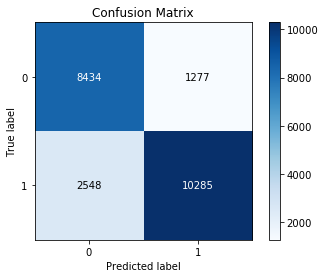

In [339]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## Graficas Training dataset

In [340]:
model.load_weights(save_best_weights)

In [341]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [342]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9821821848785535

In [343]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [344]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

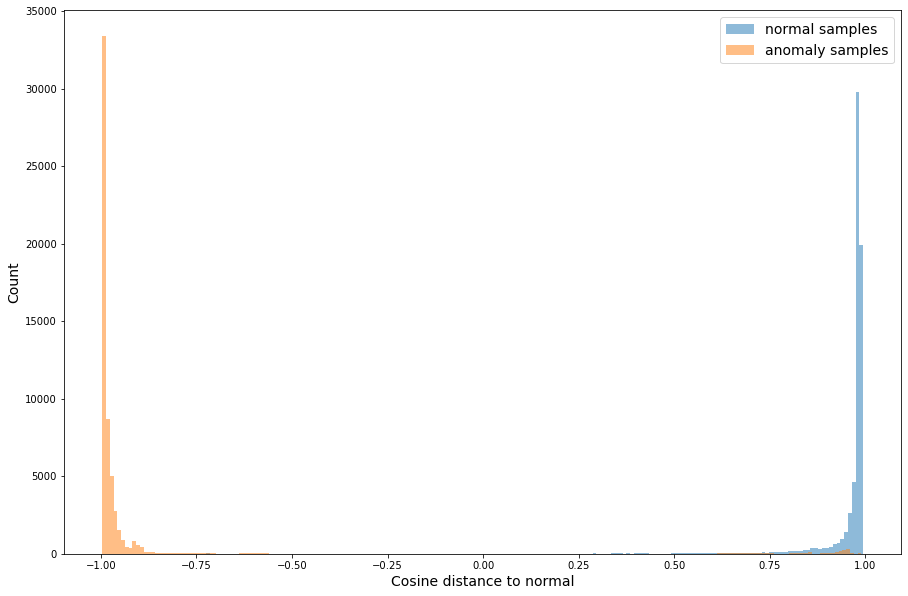

In [345]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, training dataset

In [346]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [347]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


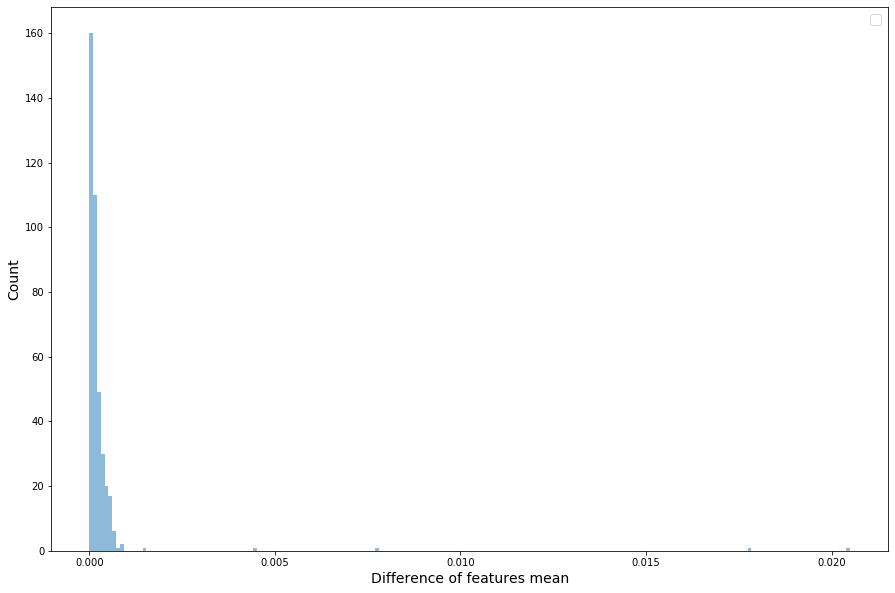

In [348]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [349]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

4.3725487238519545 1.5688768683037672e-05


## Graficas Test dataset

In [350]:
model.load_weights(save_best_weights)

In [351]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [352]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9821821848785535

In [353]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [354]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

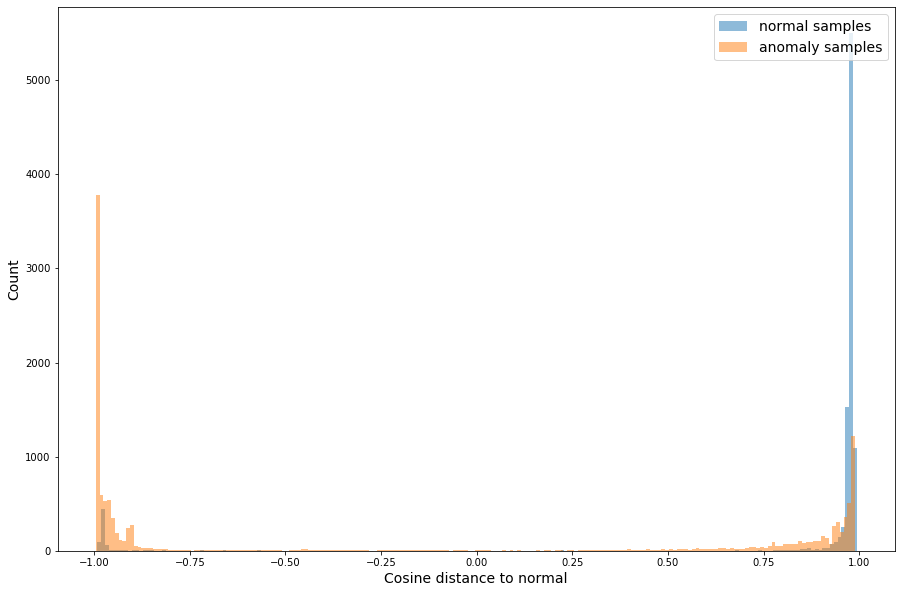

In [355]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, test dataset

In [356]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [357]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


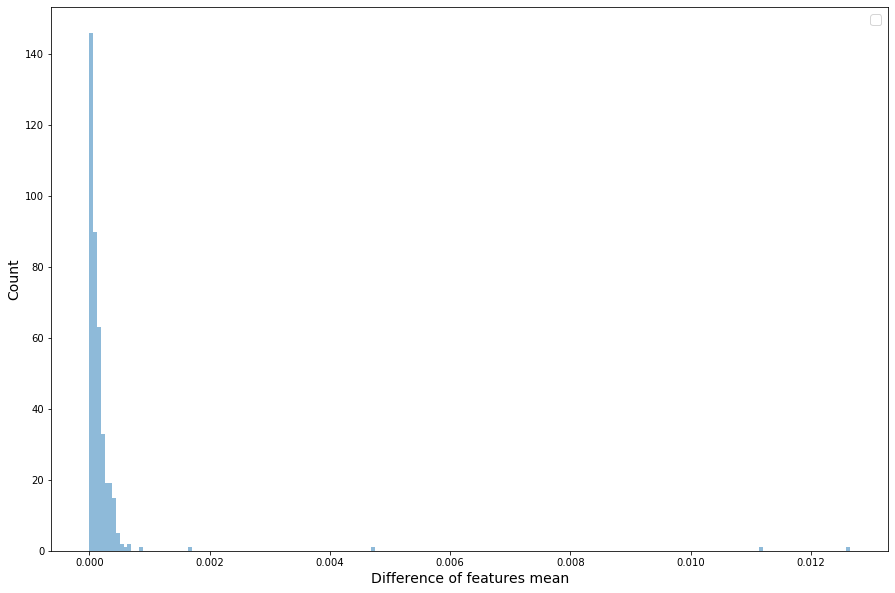

In [358]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [359]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

4.835555379694005 1.8988374399861893e-06


In [ ]:
# missing attack

## logloss + L2 regularization, missing attack PROBE
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = NA

In [661]:
index_PROBE = np.where(YTrainAN5.values=='PROBE')[0]
index_PROBE

rounds = 2
XTrainM_small = np.delete(XTrainM,index_PROBE,0)
YTrainANMOhe_small = np.delete(YTrainANMOhe,index_PROBE,0)

In [662]:
XTrainM_extended_small = XTrainM_small.copy()

In [663]:
XTrainM_extended_small = ExtendX (XTrainM_extended_small,XTrainM_small)
XTrainM_extended_small.shape

(228634, 122)

In [664]:
YTrainANMOhe_extended_small = YTrainANMOhe_small.copy()

In [665]:
YTrainANMOhe_extended_small = ExtendY(YTrainANMOhe_extended_small,YTrainANMOhe_small)
YTrainANMOhe_extended_small.shape

(228634, 2)

In [666]:
YTrainOutput_small = np.append(np.ones(XTrainM_small.shape[0]), np.zeros((rounds-1)*XTrainM_small.shape[0]))

In [667]:
YTrainAN5_small = YTrainAN5.drop(index_PROBE)
YTrainAN_small = YTrainAN.drop(index_PROBE)
print(XTrainM_extended_small.shape,YTrainOutput_small.shape, YTrainANMOhe_extended_small.shape )

(228634, 122) (228634,) (228634, 2)


In [668]:
x_train, x_test, label_train, label_test, y_train, y_test = XTrainM_extended_small, XTestM_extended, \
                                                            YTrainANMOhe_extended_small, YTestANMOhe_extended,\
                                                            YTrainOutput_small, YTestOutput
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape)


(228634, 122) (45088, 122) (228634, 2) (45088, 2) (228634,) (45088,)


In [669]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 1_1reg 2 missing attack 1'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [670]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [671]:
def cosine_act(x):
    return tf.math.cos(x)

In [672]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [673]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [674]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [675]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [676]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [677]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)

    return (logloss)



In [678]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val,L2reg):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x, 
                      kernel_regularizer=tf.keras.regularizers.l2(L2reg),
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l, 
                      kernel_regularizer=tf.keras.regularizers.l2(L2reg),
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [679]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.00001
L2reg = 0.1

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val,L2reg)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
#model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])
model.compile(loss='binary_crossentropy', optimizer=Adam(0.001), metrics=['accuracy'])

In [524]:
W2.numpy()

AttributeError: 'Tensor' object has no attribute 'numpy'

In [525]:
model.summary()

Model: "model_27"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_19 (InputLayer)           [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_20 (InputLayer)           [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_19[0][0]                   
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_20[0][0]                   
___________________________________________________________________________________________

In [526]:
model_embed_x.summary()

Model: "model_28"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_19 (InputLayer)        [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [527]:
model_embed_label.summary()

Model: "model_29"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_20 (InputLayer)        [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [528]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [529]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 182907 samples, validate on 45727 samples
Epoch 1/100
182907/182907 [==============================] - 10s 55us/sample - loss: 17482.8041 - accuracy: 0.8398 - val_loss: 9156.0535 - val_accuracy: 0.8180
Epoch 2/100
182907/182907 [==============================] - 9s 47us/sample - loss: 5237.9149 - accuracy: 0.9252 - val_loss: 2544.2521 - val_accuracy: 0.9062
Epoch 3/100
182907/182907 [==============================] - 9s 47us/sample - loss: 1348.7555 - accuracy: 0.9308 - val_loss: 572.6490 - val_accuracy: 0.8485
Epoch 4/100
182907/182907 [==============================] - 9s 48us/sample - loss: 276.7114 - accuracy: 0.9303 - val_loss: 100.3989 - val_accuracy: 0.9120
Epoch 5/100
182907/182907 [==============================] - 9s 47us/sample - loss: 44.4394 - accuracy: 0.9477 - val_loss: 13.8396 - val_accuracy: 0.9470
Epoch 6/100
182907/182907 [==============================] - 9s 48us/sample - loss: 5.6496 - accuracy: 0.9598 - val_loss: 1.4718 - val_accuracy: 0.9780
Epoch 7/100


In [530]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [531]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

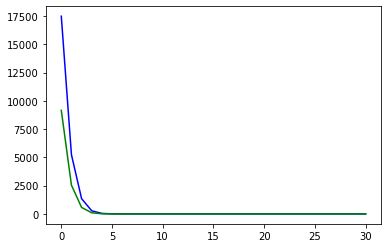

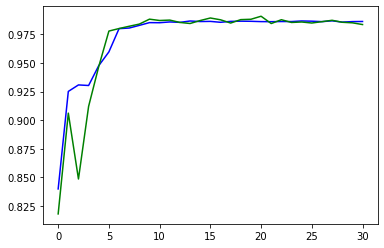

Minimum val_loss at epoch 21 = 0.0597


In [532]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [533]:
model.load_weights(save_best_weights)

In [534]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

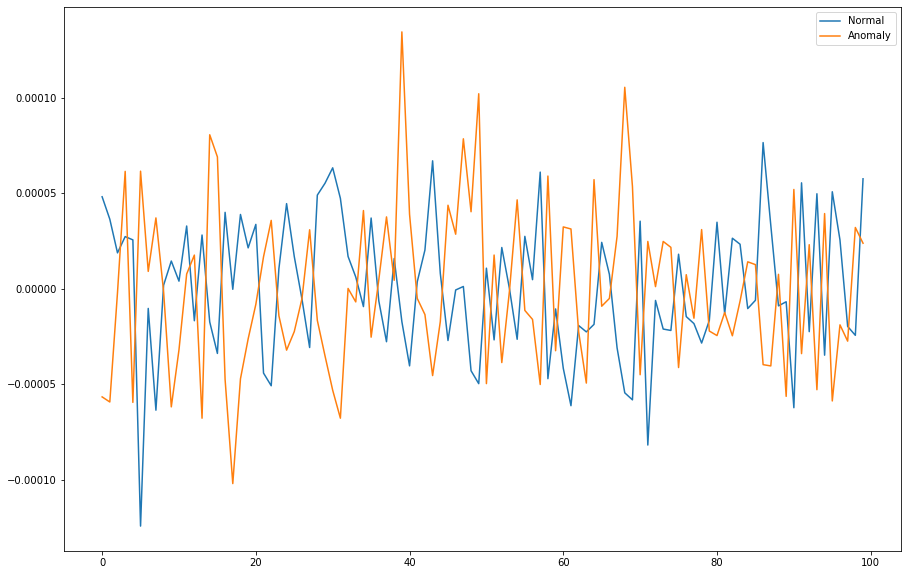

In [535]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

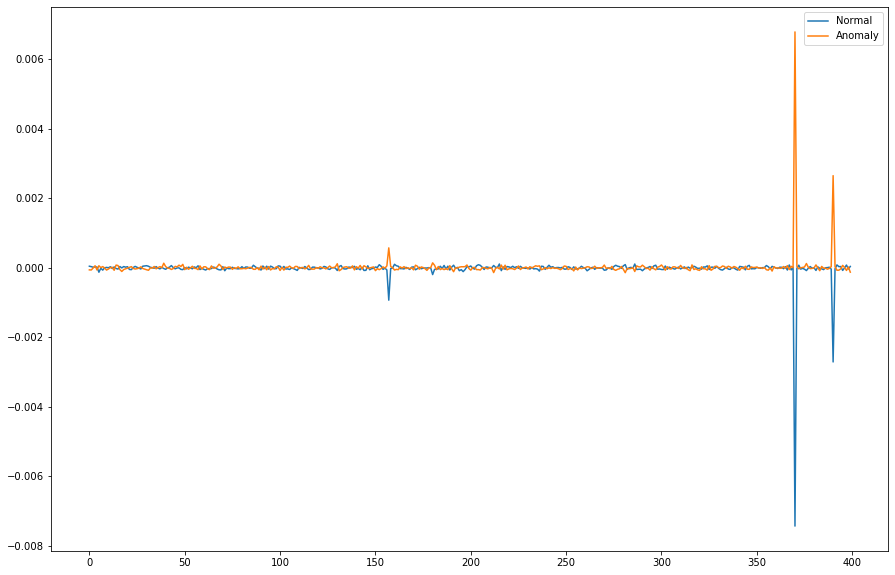

In [536]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [537]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(228634, 400)

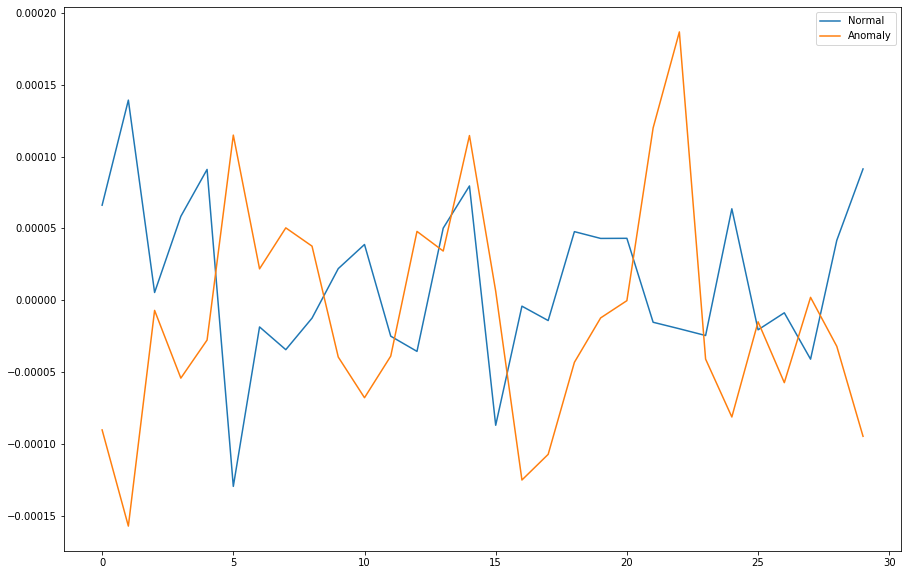

In [538]:

import matplotlib.pyplot as plt

limit = 30
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [680]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.036347


In [681]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [682]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.3330819730305181
0.5692423704755145


In [683]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7152235628105039
F1 =  0.68439681447252
Precision_score =  0.9270209082434412
recall_score =  0.542429673498013
roc_auc_score =  0.8055917070909481
pr_auc =  0.8821764199113098
matthews_corr_score =  0.5106090668794242


In [689]:
threshold = 0.09
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))


attack_name = 'PROBE'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'DOS'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'NORMAL'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(1-y_test[index_single_attack],1-ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'U2R'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'R2L'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]
print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7597586941092974
F1 =  0.7577384147432458
Precision_score =  0.8894256011760999
recall_score =  0.6600171433024234
roc_auc_score =  0.8055917070909481
pr_auc =  0.8821764199113098
matthews_corr_score =  0.5529657171596769
.......
 single attack PROBE
Accuracy =  0.4031391986782321
F1 =  0.5746246688254343
Precision_score =  1.0
recall_score =  0.4031391986782321
.......
 single attack DOS
Accuracy =  0.8668543845534996
F1 =  0.9286791639732815
Precision_score =  1.0
recall_score =  0.8668543845534996
.......
 single attack NORMAL
Accuracy =  0.891566265060241
F1 =  0.9426751592356688
Precision_score =  1.0
recall_score =  0.891566265060241
.......
 single attack U2R
Accuracy =  0.1275
F1 =  0.2261640798226164
Precision_score =  1.0
recall_score =  0.1275
.......
 single attack R2L
Accuracy =  0.38292873923257637
F1 =  0.5537938844847112
Precision_score =  1.0
recall_score =  0.38292873923257637


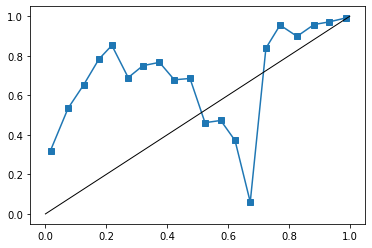

In [571]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

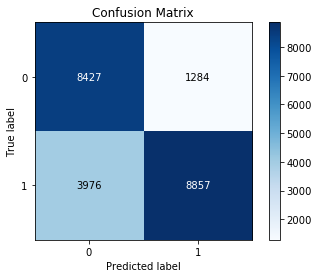

In [572]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## Graficas Training dataset

In [573]:
model.load_weights(save_best_weights)

In [574]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [575]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9956665855741875

In [576]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [577]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

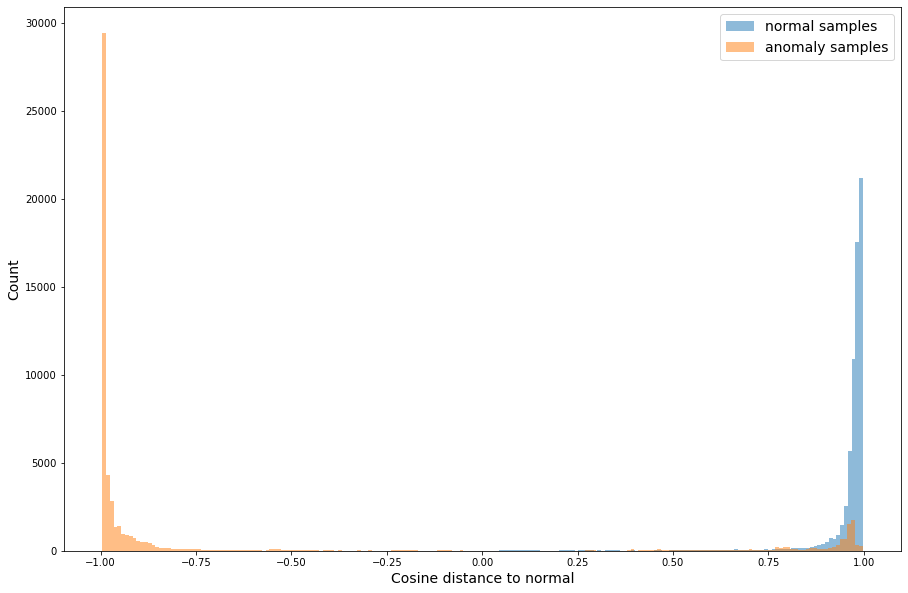

In [578]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, training dataset

In [579]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [580]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


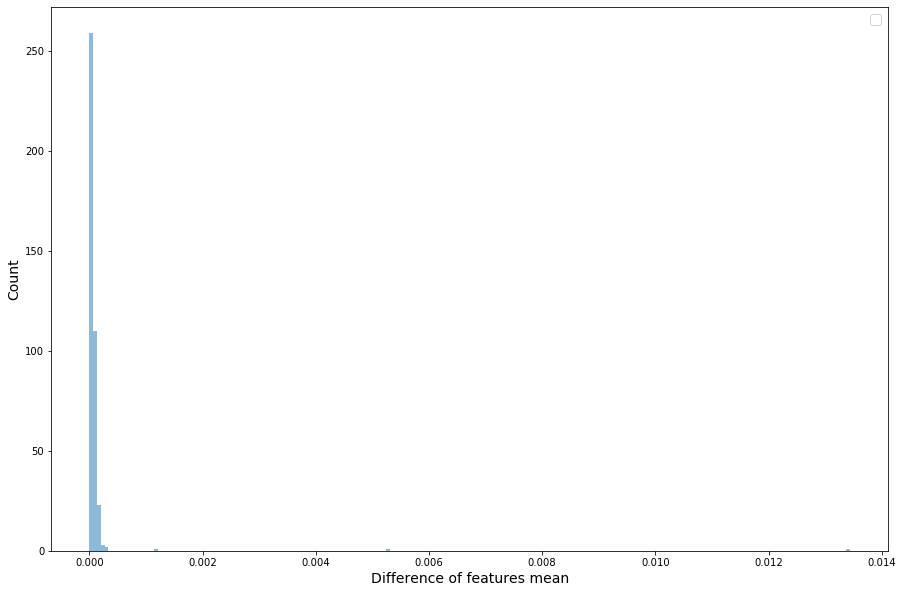

In [581]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [582]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

2.9985570561721175 0.0028824555423145547


## Graficas Test dataset

In [583]:
model.load_weights(save_best_weights)

In [584]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [585]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9956665855741875

In [586]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [587]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

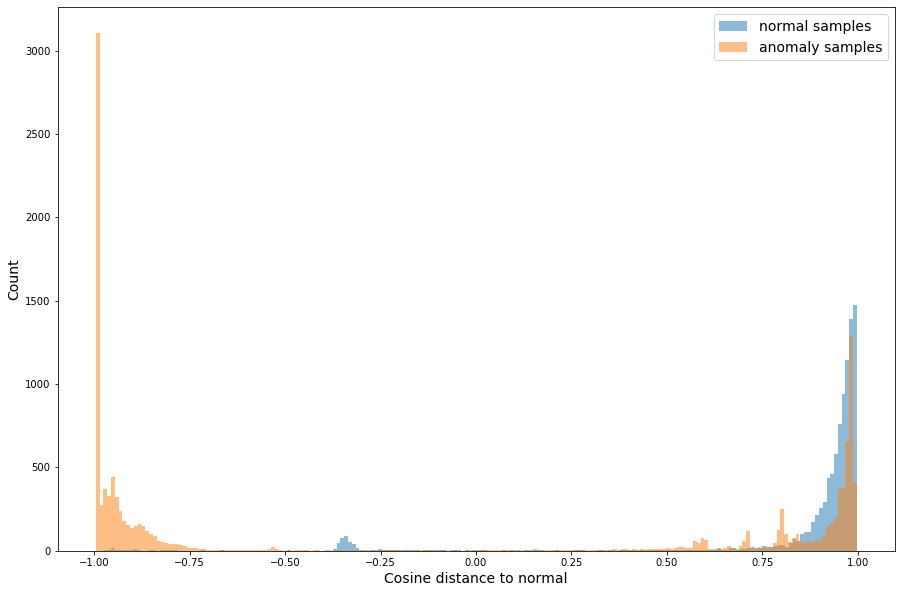

In [588]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, test dataset

In [589]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [590]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


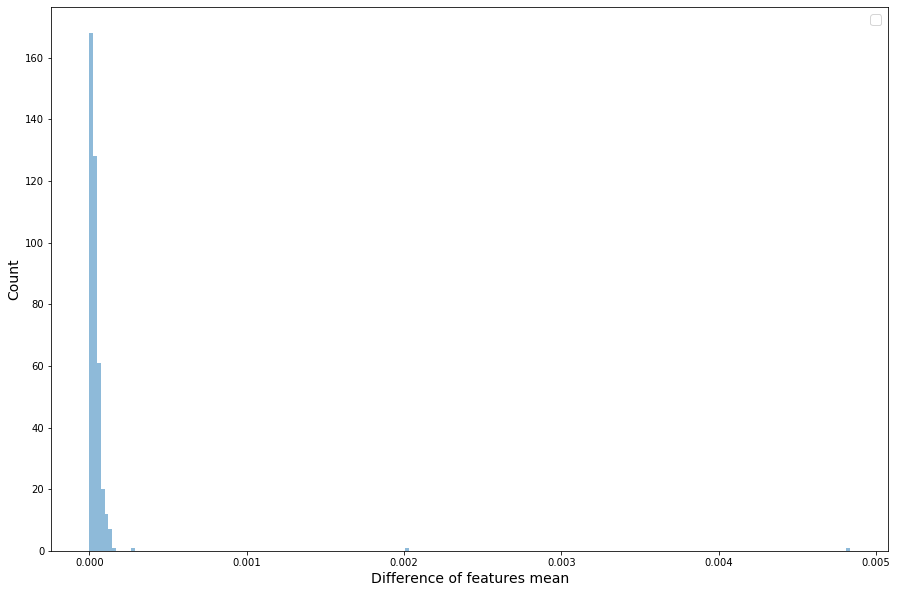

In [591]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [592]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

4.112130464195912 4.762332037390099e-05


In [ ]:
# missing attack 2

## logloss + L2 regularization, missing attack DOS
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = NA

In [593]:
index_PROBE = np.where(YTrainAN5.values=='DOS')[0]
index_PROBE

rounds = 2
XTrainM_small = np.delete(XTrainM,index_PROBE,0)
YTrainANMOhe_small = np.delete(YTrainANMOhe,index_PROBE,0)

In [594]:
XTrainM_extended_small = XTrainM_small.copy()

In [595]:
XTrainM_extended_small = ExtendX (XTrainM_extended_small,XTrainM_small)
XTrainM_extended_small.shape

(160092, 122)

In [596]:
YTrainANMOhe_extended_small = YTrainANMOhe_small.copy()

In [597]:
YTrainANMOhe_extended_small = ExtendY(YTrainANMOhe_extended_small,YTrainANMOhe_small)
YTrainANMOhe_extended_small.shape

(160092, 2)

In [598]:
YTrainOutput_small = np.append(np.ones(XTrainM_small.shape[0]), np.zeros((rounds-1)*XTrainM_small.shape[0]))

In [599]:
YTrainAN5_small = YTrainAN5.drop(index_PROBE)
YTrainAN_small = YTrainAN.drop(index_PROBE)
print(XTrainM_extended_small.shape,YTrainOutput_small.shape, YTrainANMOhe_extended_small.shape )

(160092, 122) (160092,) (160092, 2)


In [600]:
x_train, x_test, label_train, label_test, y_train, y_test = XTrainM_extended_small, XTestM_extended, \
                                                            YTrainANMOhe_extended_small, YTestANMOhe_extended,\
                                                            YTrainOutput_small, YTestOutput
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape)


(160092, 122) (45088, 122) (160092, 2) (45088, 2) (160092,) (45088,)


In [601]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 1_1reg 2 missing attack 2'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [602]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [603]:
def cosine_act(x):
    return tf.math.cos(x)

In [604]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [605]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [606]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [607]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [608]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [609]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)

    return (logloss)



In [610]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val,L2reg):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x, 
                      kernel_regularizer=tf.keras.regularizers.l2(L2reg),
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l, 
                      kernel_regularizer=tf.keras.regularizers.l2(L2reg),
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [611]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.00001
L2reg = 0.1

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val,L2reg)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
#model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])
model.compile(loss='binary_crossentropy', optimizer=Adam(0.001), metrics=['accuracy'])

In [612]:
W2.numpy()

AttributeError: 'Tensor' object has no attribute 'numpy'

In [613]:
model.summary()

Model: "model_30"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_21 (InputLayer)           [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_22 (InputLayer)           [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_21[0][0]                   
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_22[0][0]                   
___________________________________________________________________________________________

In [614]:
model_embed_x.summary()

Model: "model_31"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_21 (InputLayer)        [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [615]:
model_embed_label.summary()

Model: "model_32"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_22 (InputLayer)        [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [616]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [617]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 128073 samples, validate on 32019 samples
Epoch 1/100
128073/128073 [==============================] - 8s 63us/sample - loss: 20179.6891 - accuracy: 0.8072 - val_loss: 13024.1791 - val_accuracy: 0.8001
Epoch 2/100
128073/128073 [==============================] - 7s 53us/sample - loss: 8824.8225 - accuracy: 0.8977 - val_loss: 5576.7837 - val_accuracy: 0.8450
Epoch 3/100
128073/128073 [==============================] - 6s 50us/sample - loss: 3668.3348 - accuracy: 0.8927 - val_loss: 2212.4064 - val_accuracy: 0.8432
Epoch 4/100
128073/128073 [==============================] - 7s 54us/sample - loss: 1395.0558 - accuracy: 0.8433 - val_loss: 790.2362 - val_accuracy: 0.8432
Epoch 5/100
128073/128073 [==============================] - 7s 54us/sample - loss: 474.1520 - accuracy: 0.8408 - val_loss: 249.4615 - val_accuracy: 0.8432
Epoch 6/100
128073/128073 [==============================] - 7s 54us/sample - loss: 141.8462 - accuracy: 0.8409 - val_loss: 68.7976 - val_accuracy: 0.8432
Epoch

In [618]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [619]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

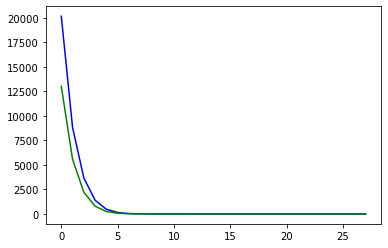

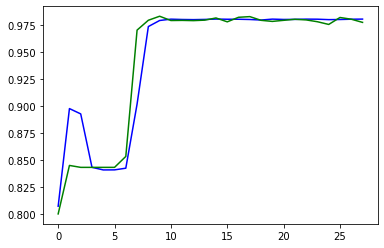

Minimum val_loss at epoch 18 = 0.0728


In [620]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [621]:
model.load_weights(save_best_weights)

In [622]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

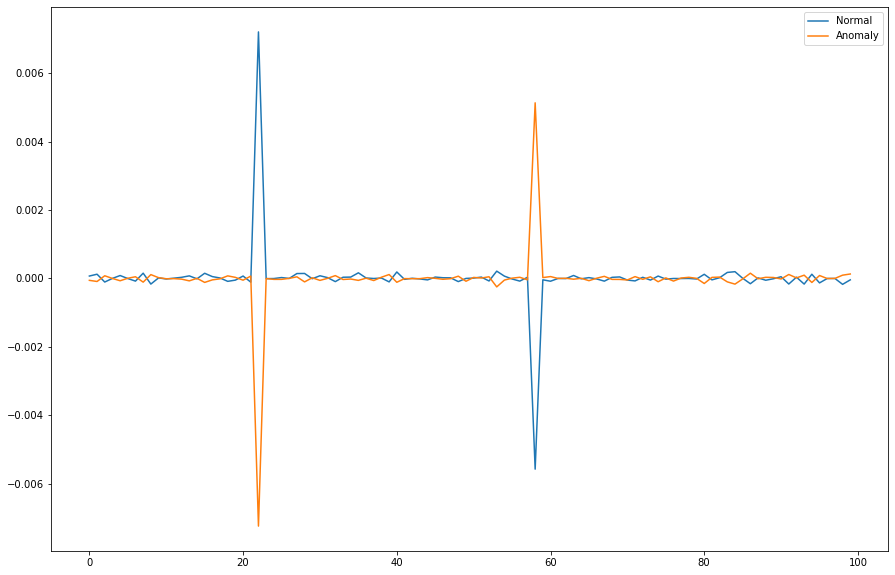

In [623]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

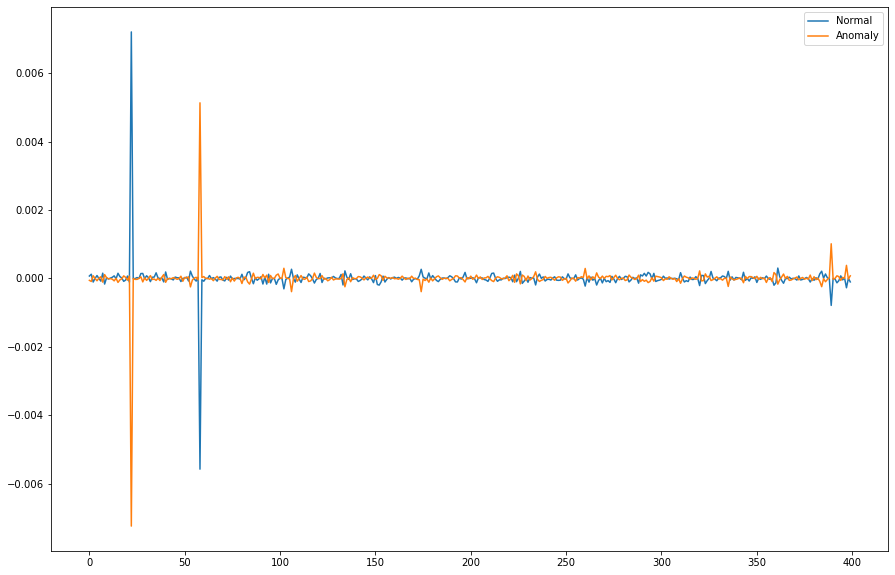

In [624]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [625]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(160092, 400)

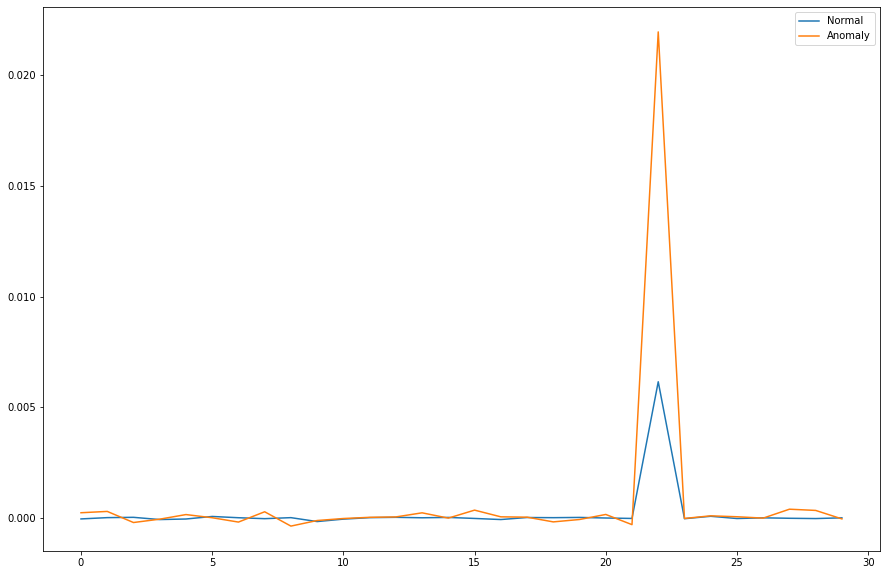

In [626]:

import matplotlib.pyplot as plt

limit = 30
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [627]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.037993


In [628]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [629]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.3244765791341377
0.5692423704755145


In [630]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.6949077359829666
F1 =  0.6586261663688704
Precision_score =  0.9070403280929596
recall_score =  0.5170264162705525
roc_auc_score =  0.9100145374068307
pr_auc =  0.9136616526979686
matthews_corr_score =  0.47278467734606106


In [636]:
threshold = 0.04
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))


attack_name = 'PROBE'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'DOS'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'NORMAL'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(1-y_test[index_single_attack],1-ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'U2R'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'R2L'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]
print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8023864442867282
F1 =  0.8070342617057219
Precision_score =  0.9085235030232105
recall_score =  0.7259409335307411
roc_auc_score =  0.9100145374068307
pr_auc =  0.9136616526979686
matthews_corr_score =  0.6258428945081258
.......
 single attack PROBE
Accuracy =  0.9888475836431226
F1 =  0.994392523364486
Precision_score =  1.0
recall_score =  0.9888475836431226
.......
 single attack DOS
Accuracy =  0.7680343255564495
F1 =  0.868800242681632
Precision_score =  1.0
recall_score =  0.7680343255564495
.......
 single attack NORMAL
Accuracy =  0.9034085058181444
F1 =  0.9492534083531703
Precision_score =  1.0
recall_score =  0.9034085058181444
.......
 single attack U2R
Accuracy =  0.1375
F1 =  0.2417582417582418
Precision_score =  1.0
recall_score =  0.1375
.......
 single attack R2L
Accuracy =  0.44596711041503523
F1 =  0.6168426753317086
Precision_score =  1.0
recall_score =  0.44596711041503523


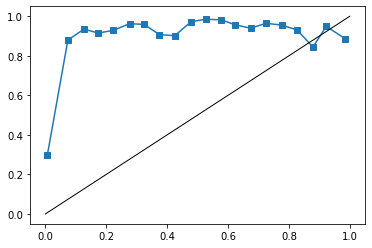

In [637]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

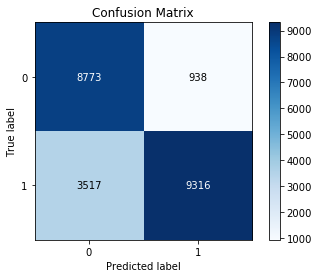

In [638]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## Graficas Training dataset

In [639]:
model.load_weights(save_best_weights)

In [640]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [641]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9953218029772667

In [642]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [643]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

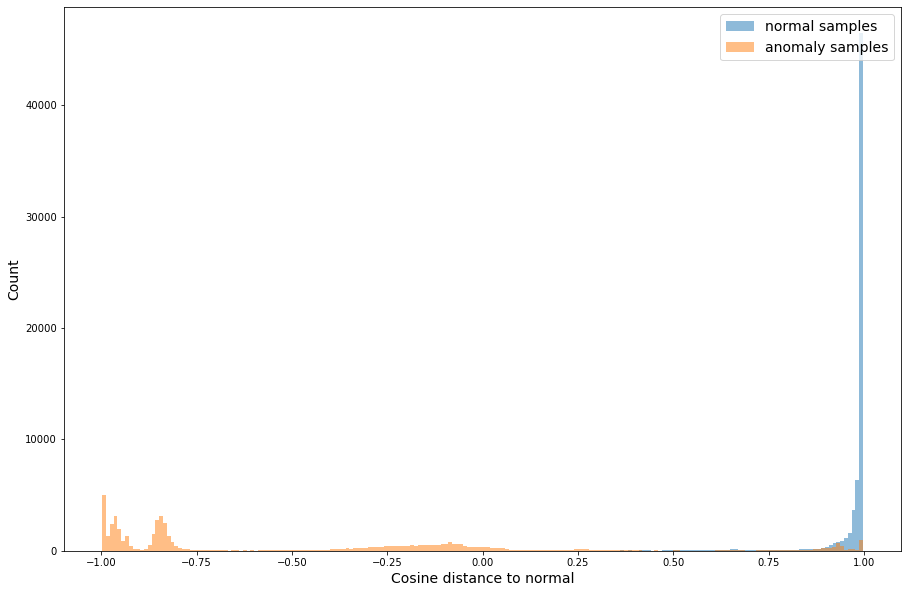

In [644]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, training dataset

In [645]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTrainM[YTrainANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [646]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


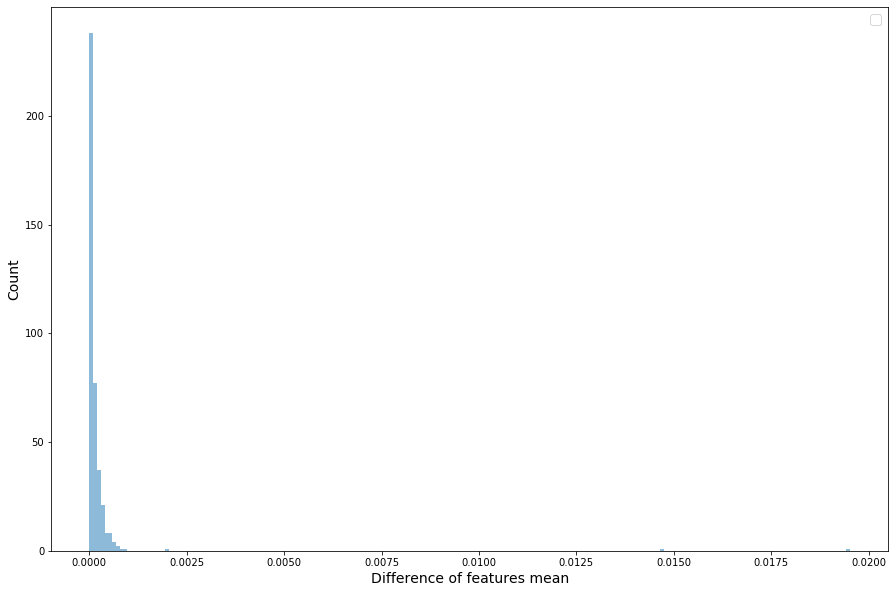

In [647]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [648]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

3.5155665493185797 0.0004891837342646826


## Graficas Test dataset

In [649]:
model.load_weights(save_best_weights)

In [650]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

In [651]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[0,:]
a = label_embeddings[1,:]
cos_sim = dot(a, ref)/(norm(a)*norm(ref))
cos_sim


-0.9953218029772667

In [652]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [653]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_anomaly = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_anomaly])

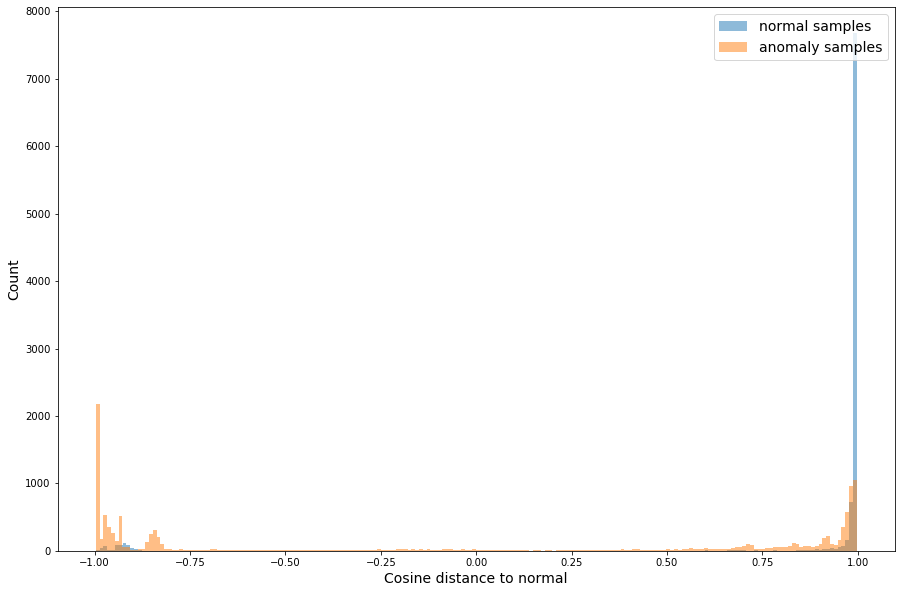

In [654]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_anomaly, bins=200, alpha=0.5, density=False, label="anomaly samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, test dataset

In [655]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==0]) # embeddings de las muestras normales
x_embeddings_anomaly = model_embed_x.predict(XTestM[YTestANMOhe[:,1]==1]) # embeddings de las muestras anomalas

In [656]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_anomaly_mean = np.mean(x_embeddings_anomaly, axis=0)

No handles with labels found to put in legend.


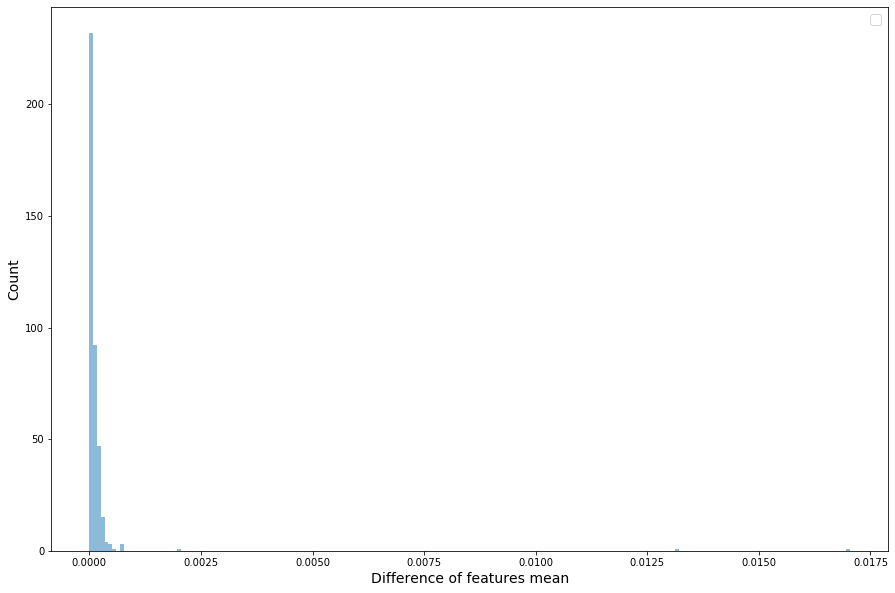

In [657]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [658]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

3.2881393541961703 0.0010979527796831092


## logloss+contractive, 
latent = 400
Dense-RELU
seed = 1234
alpha_val = 0.0001

In [97]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [98]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [99]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 2 denserelu'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [100]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [101]:
def cosine_act(x):
    return tf.math.cos(x)

In [102]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [103]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [104]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [105]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [106]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [107]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = tf.math.sign(h_cos)  # N_batch x N_hidden, por ser relu

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)


In [108]:
vocab_size = in_dim_label  # no usado de momento
embed_dim = 10

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, seed, alpha_val):
    
    tf.random.set_seed(seed)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "relu", trainable = True, 
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "relu", trainable = True, 
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [109]:
#crear modelo
rff_dim = 400
seed = 1234
alpha_val = 0.0001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [110]:
model.summary()

Model: "model_3"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_3 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_4 (InputLayer)            [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_3[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_4[0][0]                    
____________________________________________________________________________________________

In [111]:
model_embed_x.summary()

Model: "model_4"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_3 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [112]:
model_embed_label.summary()

Model: "model_5"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_4 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [113]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [114]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 9s 43us/sample - loss: 0.7033 - accuracy: 0.6709 - val_loss: 0.6048 - val_accuracy: 0.8647
Epoch 2/100
201556/201556 [==============================] - 9s 42us/sample - loss: 0.2116 - accuracy: 0.9728 - val_loss: 0.2433 - val_accuracy: 0.9728
Epoch 3/100
201556/201556 [==============================] - 9s 44us/sample - loss: 0.1514 - accuracy: 0.9776 - val_loss: 0.2259 - val_accuracy: 0.9734
Epoch 4/100
201556/201556 [==============================] - 9s 43us/sample - loss: 0.1429 - accuracy: 0.9787 - val_loss: 0.2139 - val_accuracy: 0.9770
Epoch 5/100
201556/201556 [==============================] - 10s 47us/sample - loss: 0.1392 - accuracy: 0.9795 - val_loss: 0.2118 - val_accuracy: 0.9775
Epoch 6/100
201556/201556 [==============================] - 10s 50us/sample - loss: 0.1367 - accuracy: 0.9801 - val_loss: 0.2062 - val_accuracy: 0.9779
Epoch 7/100
201556/201556 [========

In [115]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [116]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

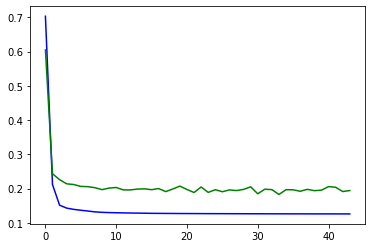

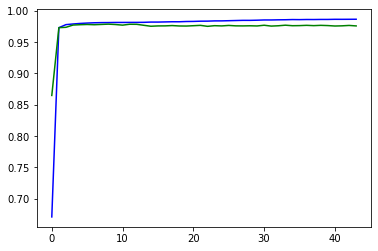

Minimum val_loss at epoch 34 = 0.1828


In [117]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [118]:
model.load_weights(save_best_weights)

In [119]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

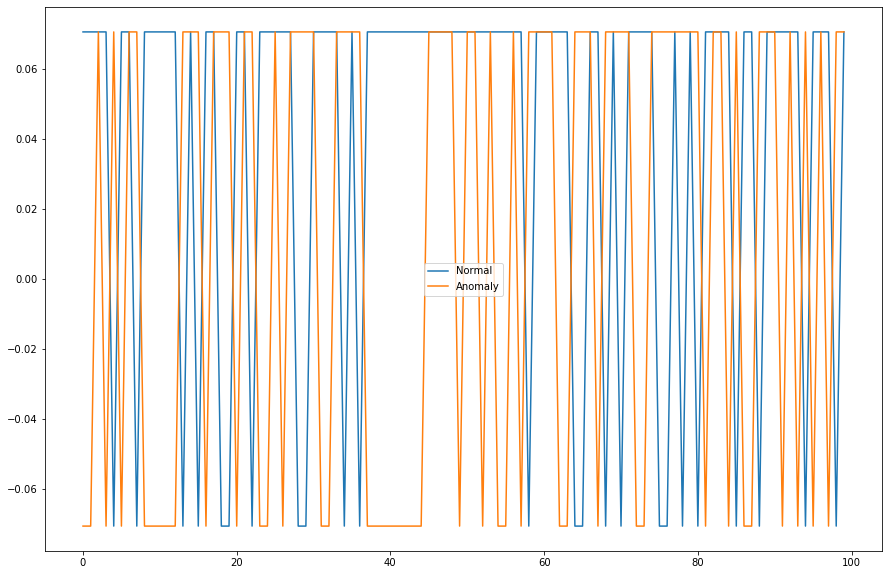

In [120]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

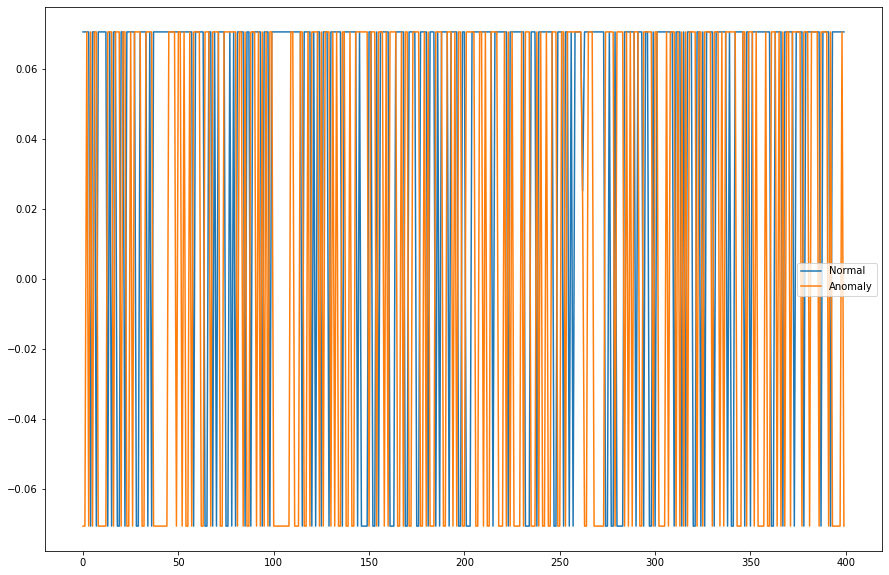

In [121]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [122]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(251946, 400)

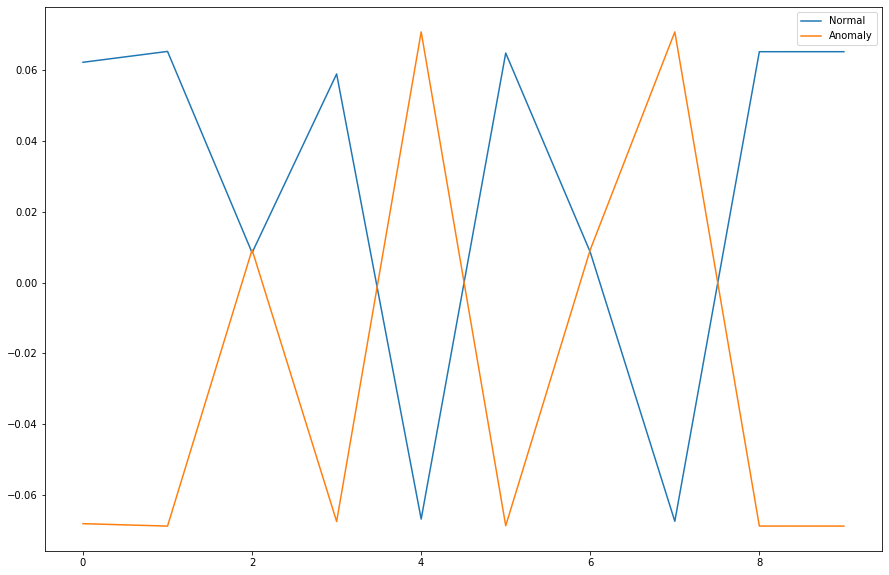

In [123]:

import matplotlib.pyplot as plt

limit = 10
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [124]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.024938


In [125]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [126]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.35095812633073104
0.5692423704755145


In [131]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.72138928317956
F1 =  0.697228247770547
Precision_score =  0.9140546006066734
recall_score =  0.5635471051196135
roc_auc_score =  0.8215456940121044
pr_auc =  0.8692805295884177
matthews_corr_score =  0.5120458563504511


In [141]:
threshold = 0.16
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))


attack_name = 'PROBE'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'DOS'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'NORMAL'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(1-y_test[index_single_attack],1-ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'U2R'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'R2L'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]
print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8113466997870831
F1 =  0.8266275325098855
Precision_score =  0.8667293554453753
recall_score =  0.79007246941479
roc_auc_score =  0.8215456940121044
pr_auc =  0.8692805295884177
matthews_corr_score =  0.6239127778720858
.......
 single attack PROBE
Accuracy =  0.9045848822800495
F1 =  0.9499024072869225
Precision_score =  1.0
recall_score =  0.9045848822800495
.......
 single attack DOS
Accuracy =  0.9396621078037007
F1 =  0.9688925756947324
Precision_score =  1.0
recall_score =  0.9396621078037007
.......
 single attack NORMAL
Accuracy =  0.839460405725466
F1 =  0.9127246263225662
Precision_score =  1.0
recall_score =  0.839460405725466
.......
 single attack U2R
Accuracy =  0.4575
F1 =  0.6277873070325901
Precision_score =  1.0
recall_score =  0.4575
.......
 single attack R2L
Accuracy =  0.29678935003915424
F1 =  0.45772946859903374
Precision_score =  1.0
recall_score =  0.29678935003915424


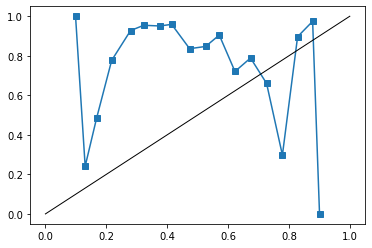

In [142]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

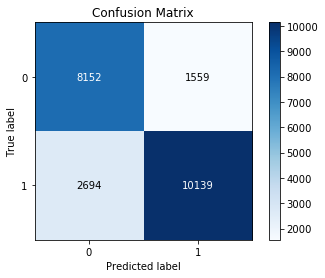

In [143]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## logloss+contractive, 
latent = 400
Dense-RELU
seed = 1234
alpha_val = 0.01

In [144]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [145]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [146]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 2 denserelu 2'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [147]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [148]:
def cosine_act(x):
    return tf.math.cos(x)

In [149]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [150]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [151]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [152]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [153]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [154]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = tf.math.sign(h_cos)  # N_batch x N_hidden, por ser relu

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)


In [155]:
vocab_size = in_dim_label  # no usado de momento
embed_dim = 10

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, seed, alpha_val):
    
    tf.random.set_seed(seed)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "relu", trainable = True, 
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "relu", trainable = True, 
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [156]:
#crear modelo
rff_dim = 400
seed = 1234
alpha_val = 0.01

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [157]:
model.summary()

Model: "model_6"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_5 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_6 (InputLayer)            [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_5[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_6[0][0]                    
____________________________________________________________________________________________

In [158]:
model_embed_x.summary()

Model: "model_7"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_5 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [159]:
model_embed_label.summary()

Model: "model_8"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_6 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [160]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [161]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 9s 47us/sample - loss: 1.3869 - accuracy: 0.6648 - val_loss: 1.4477 - val_accuracy: 0.8537
Epoch 2/100
201556/201556 [==============================] - 9s 44us/sample - loss: 0.9518 - accuracy: 0.9725 - val_loss: 0.8898 - val_accuracy: 0.9729
Epoch 3/100
201556/201556 [==============================] - 9s 46us/sample - loss: 0.7996 - accuracy: 0.9776 - val_loss: 0.8730 - val_accuracy: 0.9737
Epoch 4/100
201556/201556 [==============================] - 9s 44us/sample - loss: 0.7856 - accuracy: 0.9790 - val_loss: 0.8432 - val_accuracy: 0.9782
Epoch 5/100
201556/201556 [==============================] - 9s 43us/sample - loss: 0.7806 - accuracy: 0.9799 - val_loss: 0.8517 - val_accuracy: 0.9784
Epoch 6/100
201556/201556 [==============================] - 9s 44us/sample - loss: 0.7819 - accuracy: 0.9804 - val_loss: 0.8487 - val_accuracy: 0.9784
Epoch 7/100
201556/201556 [==========

In [162]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [163]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

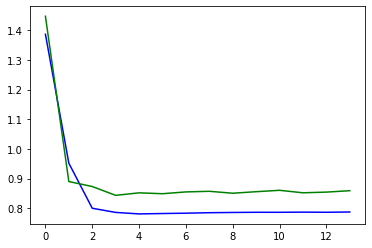

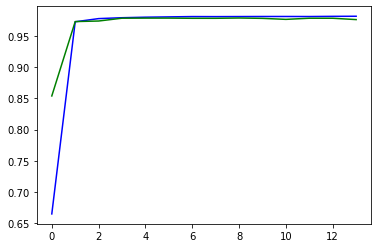

Minimum val_loss at epoch 4 = 0.8432


In [164]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [165]:
model.load_weights(save_best_weights)

In [166]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

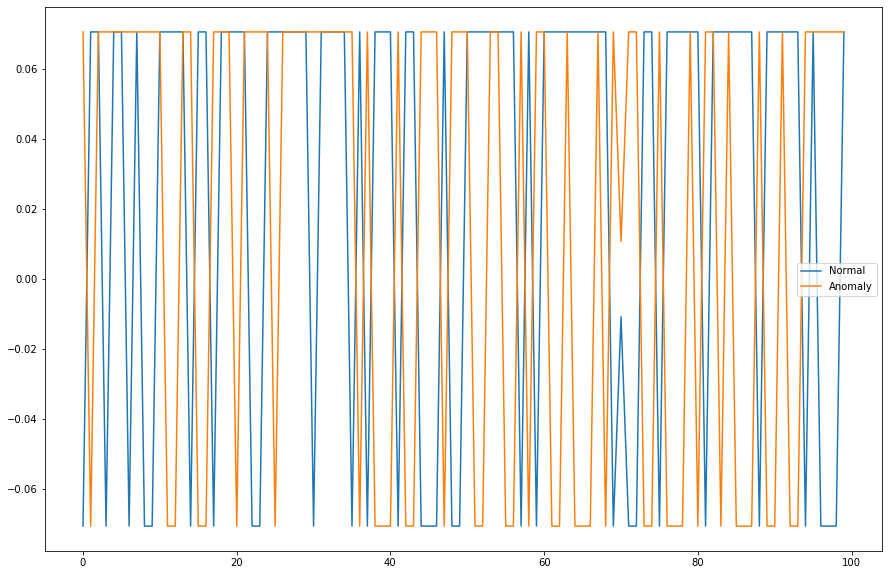

In [167]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

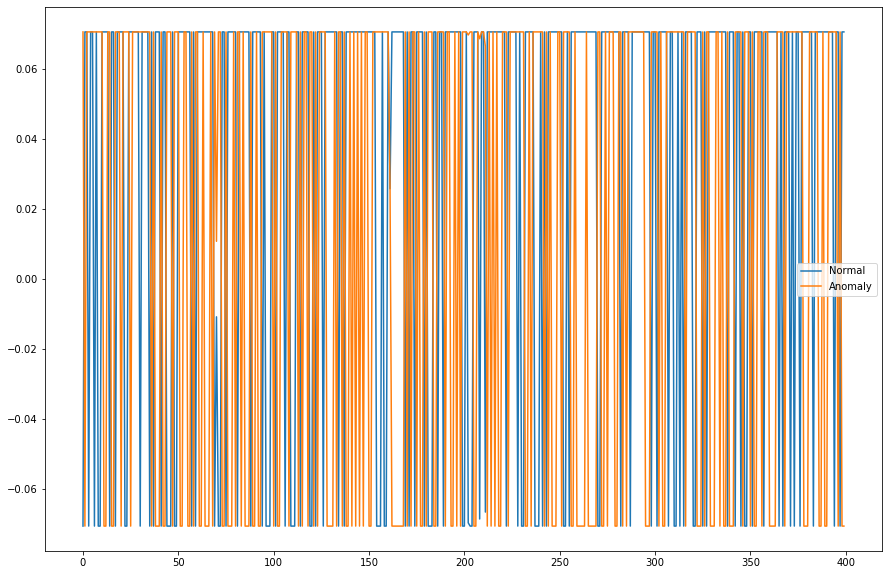

In [168]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [169]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(251946, 400)

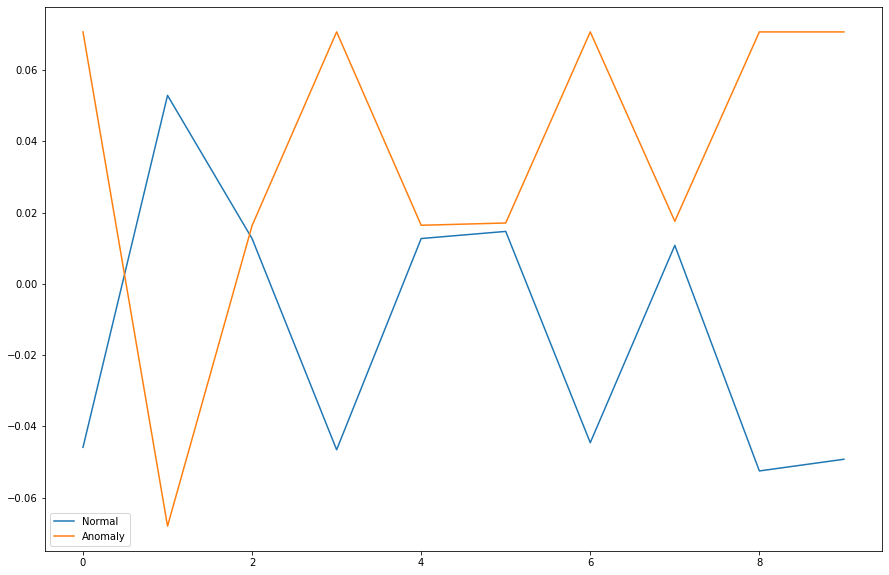

In [170]:

import matplotlib.pyplot as plt

limit = 10
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [171]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.026118


In [172]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [173]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.36346699787083037
0.5692423704755145


In [174]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7317689850958127
F1 =  0.7124173681457174
Precision_score =  0.914083475713937
recall_score =  0.5836515234161926
roc_auc_score =  0.7768467328083491
pr_auc =  0.8055674198532813
matthews_corr_score =  0.5262304312811351


In [184]:
threshold = 0.16
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))


attack_name = 'PROBE'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'DOS'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'NORMAL'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(1-y_test[index_single_attack],1-ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'U2R'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'R2L'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]
print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7966643009226402
F1 =  0.8111559693499217
Precision_score =  0.8605017043964689
recall_score =  0.7671627834489207
roc_auc_score =  0.7768467328083491
pr_auc =  0.8055674198532813
matthews_corr_score =  0.5970718230101721
.......
 single attack PROBE
Accuracy =  0.9756299049979348
F1 =  0.9876646456199037
Precision_score =  1.0
recall_score =  0.9756299049979348
.......
 single attack DOS
Accuracy =  0.8621614373826764
F1 =  0.9259792626728112
Precision_score =  1.0
recall_score =  0.8621614373826764
.......
 single attack NORMAL
Accuracy =  0.8356502934816188
F1 =  0.9104678559407607
Precision_score =  1.0
recall_score =  0.8356502934816188
.......
 single attack U2R
Accuracy =  0.1075
F1 =  0.19413092550790068
Precision_score =  1.0
recall_score =  0.1075
.......
 single attack R2L
Accuracy =  0.39545810493343775
F1 =  0.5667789001122334
Precision_score =  1.0
recall_score =  0.39545810493343775


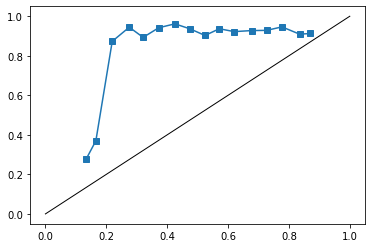

In [176]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

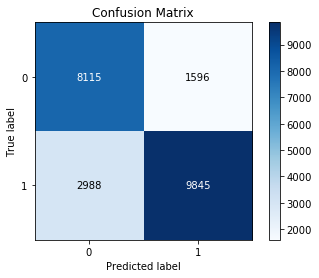

In [177]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## logloss+contractive, 
latent = 400
Dense-RELU
seed = 1234
alpha_val = 0.000001

In [185]:
x_train, x_test, label_train, label_test, y_train, y_test, y_train_zeros, y_test_zeros = XTrainM_extended, XTestM_extended, \
                                                            YTrainANMOhe_extended, YTestANMOhe_extended,\
                                                            YTrainOutput, YTestOutput, \
                                                            np.zeros(len(YTrainOutput)), np.zeros(len(YTestOutput))
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape, y_train_zeros.shape, y_test_zeros.shape)


(251946, 122) (45088, 122) (251946, 2) (45088, 2) (251946,) (45088,) (251946,) (45088,)


In [186]:
pd.Series(label_train[:,1]).value_counts()

1    125973
0    125973
dtype: int64

In [187]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 2 denserelu 3'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [188]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [189]:
def cosine_act(x):
    return tf.math.cos(x)

In [190]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [191]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [192]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [193]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [194]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [195]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = tf.math.sign(h_cos)  # N_batch x N_hidden, por ser relu

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)


In [196]:
vocab_size = in_dim_label  # no usado de momento
embed_dim = 10

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, seed, alpha_val):
    
    tf.random.set_seed(seed)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "relu", trainable = True, 
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "relu", trainable = True, 
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [197]:
#crear modelo
rff_dim = 400
seed = 1234
alpha_val = 0.000001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [198]:
model.summary()

Model: "model_9"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_7 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_8 (InputLayer)            [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_7[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_8[0][0]                    
____________________________________________________________________________________________

In [199]:
model_embed_x.summary()

Model: "model_10"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_7 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [200]:
model_embed_label.summary()

Model: "model_11"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_8 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [201]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [202]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 201556 samples, validate on 50390 samples
Epoch 1/100
201556/201556 [==============================] - 12s 60us/sample - loss: 0.7192 - accuracy: 0.6490 - val_loss: 0.6789 - val_accuracy: 0.7310
Epoch 2/100
201556/201556 [==============================] - 11s 54us/sample - loss: 0.2252 - accuracy: 0.9703 - val_loss: 0.2497 - val_accuracy: 0.9723
Epoch 3/100
201556/201556 [==============================] - 10s 48us/sample - loss: 0.1551 - accuracy: 0.9775 - val_loss: 0.2328 - val_accuracy: 0.9732
Epoch 4/100
201556/201556 [==============================] - 9s 44us/sample - loss: 0.1462 - accuracy: 0.9788 - val_loss: 0.2201 - val_accuracy: 0.9778
Epoch 5/100
201556/201556 [==============================] - 9s 47us/sample - loss: 0.1426 - accuracy: 0.9796 - val_loss: 0.2179 - val_accuracy: 0.9782
Epoch 6/100
201556/201556 [==============================] - 9s 47us/sample - loss: 0.1402 - accuracy: 0.9803 - val_loss: 0.2121 - val_accuracy: 0.9781
Epoch 7/100
201556/201556 [=======

In [203]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [204]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

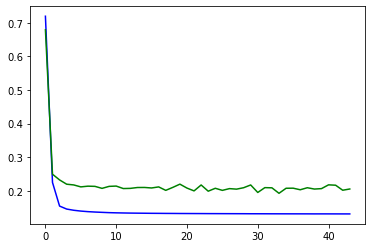

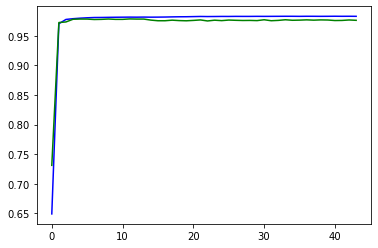

Minimum val_loss at epoch 34 = 0.1930


In [205]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [206]:
model.load_weights(save_best_weights)

In [207]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

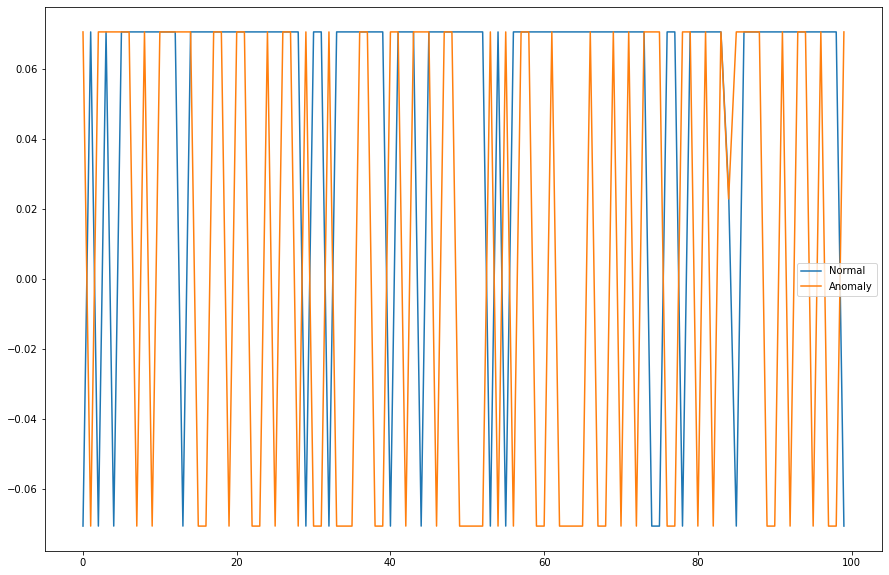

In [208]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

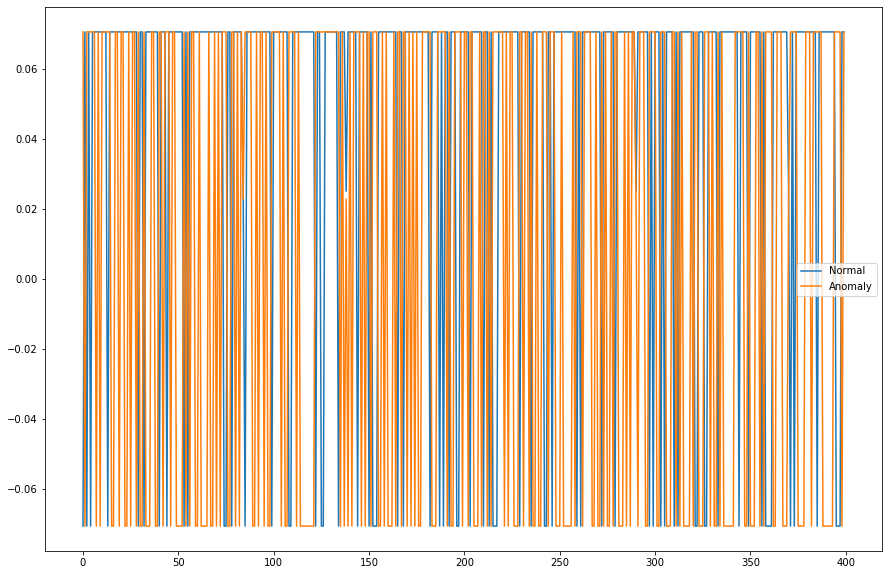

In [209]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [210]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(251946, 400)

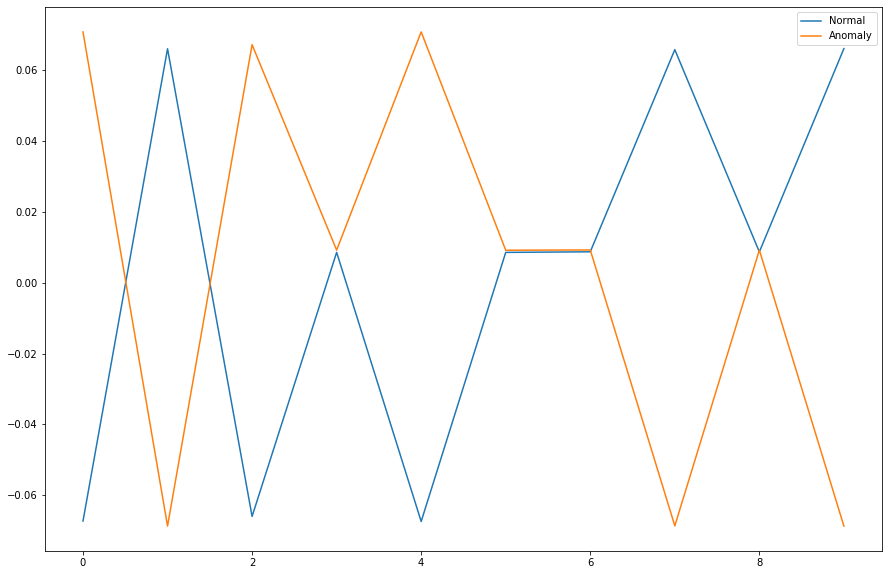

In [211]:

import matplotlib.pyplot as plt

limit = 10
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [212]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.028072


In [213]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [214]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.3501153300212917
0.5692423704755145


In [215]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.721167494677076
F1 =  0.6967094470713114
Precision_score =  0.9147345749398201
recall_score =  0.5626120158965168
roc_auc_score =  0.8155753565103894
pr_auc =  0.8653951492954276
matthews_corr_score =  0.5121068338929506


In [223]:
threshold = 0.17
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))


attack_name = 'PROBE'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'DOS'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'NORMAL'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(1-y_test[index_single_attack],1-ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'U2R'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'R2L'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]
print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.814318665720369
F1 =  0.8265948632974317
Precision_score =  0.8823737507738569
recall_score =  0.7774487649029845
roc_auc_score =  0.8155753565103894
pr_auc =  0.8653951492954276
matthews_corr_score =  0.6343223292922775
.......
 single attack PROBE
Accuracy =  0.899215200330442
F1 =  0.9469334493257939
Precision_score =  1.0
recall_score =  0.899215200330442
.......
 single attack DOS
Accuracy =  0.9368463395012068
F1 =  0.9673935617860852
Precision_score =  1.0
recall_score =  0.9368463395012068
.......
 single attack NORMAL
Accuracy =  0.8630419112346823
F1 =  0.926486845014371
Precision_score =  1.0
recall_score =  0.8630419112346823
.......
 single attack U2R
Accuracy =  0.485
F1 =  0.6531986531986532
Precision_score =  1.0
recall_score =  0.485
.......
 single attack R2L
Accuracy =  0.24236491777603758
F1 =  0.3901670343523479
Precision_score =  1.0
recall_score =  0.24236491777603758


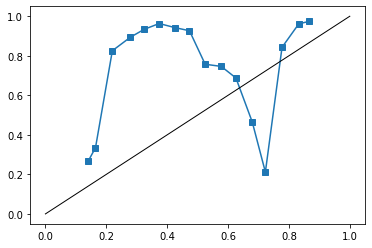

In [217]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

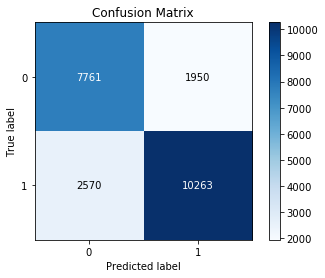

In [218]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

In [ ]:
# missing attacks

## logloss+contractive, missing PROBE
latent = 400
Dense-RELU
seed = 1234
alpha_val = 0.0001

In [327]:
index_PROBE = np.where(YTrainAN5.values=='PROBE')[0]
index_PROBE

rounds = 2
XTrainM_small = np.delete(XTrainM,index_PROBE,0)
YTrainANMOhe_small = np.delete(YTrainANMOhe,index_PROBE,0)

In [328]:
XTrainM_extended_small = XTrainM_small.copy()

In [329]:
XTrainM_extended_small = ExtendX (XTrainM_extended_small,XTrainM_small)
XTrainM_extended_small.shape

(228634, 122)

In [330]:
YTrainANMOhe_extended_small = YTrainANMOhe_small.copy()

In [331]:
YTrainANMOhe_extended_small = ExtendY(YTrainANMOhe_extended_small,YTrainANMOhe_small)
YTrainANMOhe_extended_small.shape

(228634, 2)

In [332]:
YTrainOutput_small = np.append(np.ones(XTrainM_small.shape[0]), np.zeros((rounds-1)*XTrainM_small.shape[0]))

In [333]:
YTrainAN5_small = YTrainAN5.drop(index_PROBE)
YTrainAN_small = YTrainAN.drop(index_PROBE)
print(XTrainM_extended_small.shape,YTrainOutput_small.shape, YTrainANMOhe_extended_small.shape )

(228634, 122) (228634,) (228634, 2)


In [334]:
x_train, x_test, label_train, label_test, y_train, y_test = XTrainM_extended_small, XTestM_extended, \
                                                            YTrainANMOhe_extended_small, YTestANMOhe_extended,\
                                                            YTrainOutput_small, YTestOutput
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape)


(228634, 122) (45088, 122) (228634, 2) (45088, 2) (228634,) (45088,)


In [335]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 2 denserelu missing 1'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [336]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [234]:
def cosine_act(x):
    return tf.math.cos(x)

In [235]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [236]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [237]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [238]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [239]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [240]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = tf.math.sign(h_cos)  # N_batch x N_hidden, por ser relu

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)


In [337]:
vocab_size = in_dim_label  # no usado de momento
embed_dim = 10

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, seed, alpha_val):
    
    tf.random.set_seed(seed)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "relu", trainable = True, 
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "relu", trainable = True, 
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [338]:
#crear modelo
rff_dim = 400
seed = 1234
alpha_val = 0.0001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [243]:
model.summary()

Model: "model_12"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_9 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_10 (InputLayer)           [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_9[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_10[0][0]                   
___________________________________________________________________________________________

In [244]:
model_embed_x.summary()

Model: "model_13"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_9 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [245]:
model_embed_label.summary()

Model: "model_14"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_10 (InputLayer)        [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [246]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [247]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 182907 samples, validate on 45727 samples
Epoch 1/100
182907/182907 [==============================] - 9s 51us/sample - loss: 0.6957 - accuracy: 0.6976 - val_loss: 0.5722 - val_accuracy: 0.9046
Epoch 2/100
182907/182907 [==============================] - 9s 48us/sample - loss: 0.2126 - accuracy: 0.9790 - val_loss: 0.2464 - val_accuracy: 0.9802
Epoch 3/100
182907/182907 [==============================] - 9s 47us/sample - loss: 0.1531 - accuracy: 0.9817 - val_loss: 0.2257 - val_accuracy: 0.9819
Epoch 4/100
182907/182907 [==============================] - 8s 46us/sample - loss: 0.1460 - accuracy: 0.9821 - val_loss: 0.2277 - val_accuracy: 0.9828
Epoch 5/100
182907/182907 [==============================] - 8s 46us/sample - loss: 0.1422 - accuracy: 0.9821 - val_loss: 0.2223 - val_accuracy: 0.9827
Epoch 6/100
182907/182907 [==============================] - 9s 47us/sample - loss: 0.1389 - accuracy: 0.9822 - val_loss: 0.2050 - val_accuracy: 0.9828
Epoch 7/100
182907/182907 [==========

In [248]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [249]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

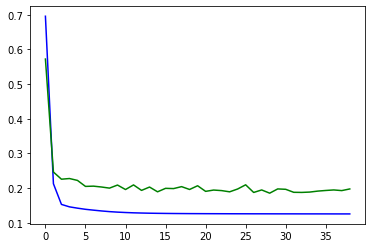

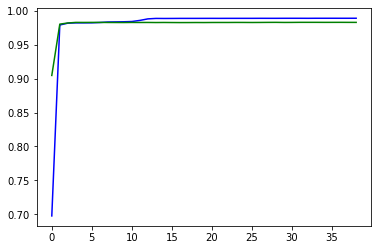

Minimum val_loss at epoch 29 = 0.1855


In [250]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [251]:
model.load_weights(save_best_weights)

In [252]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

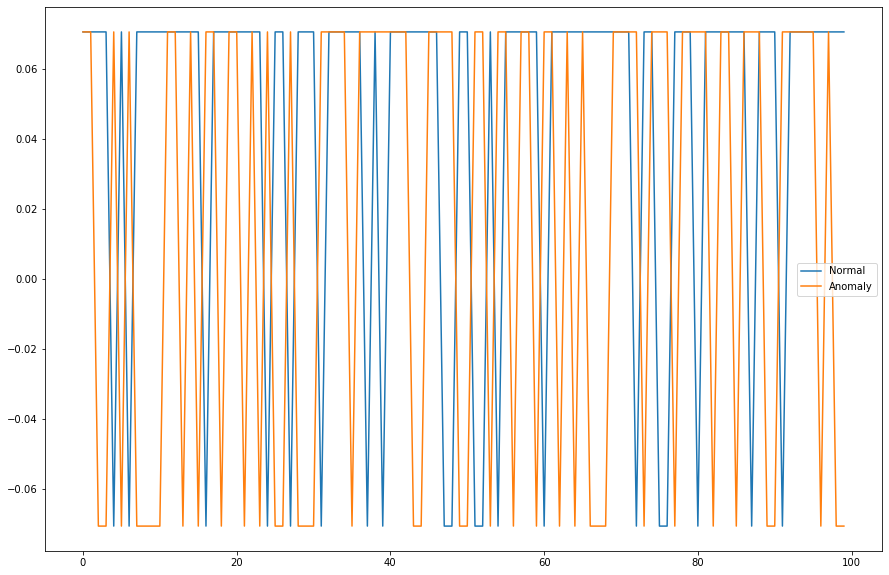

In [253]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

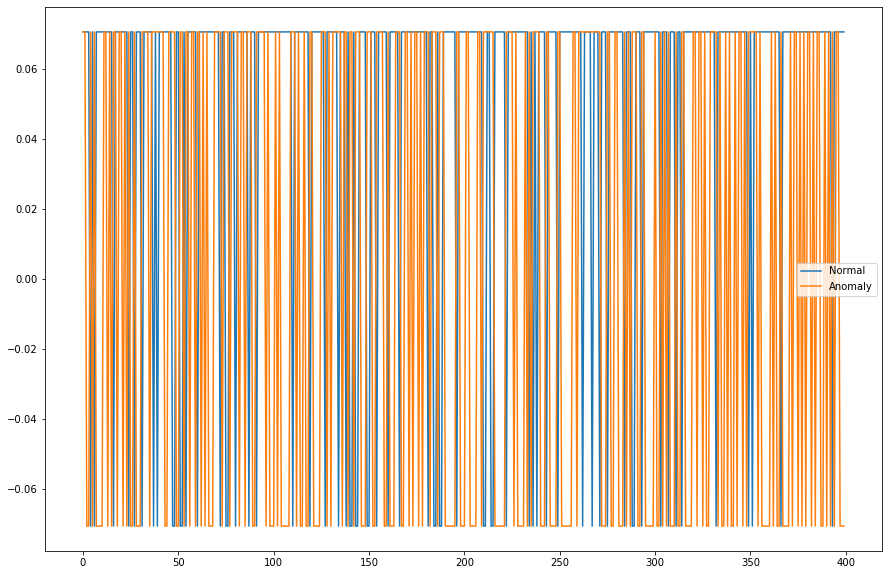

In [254]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [255]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(228634, 400)

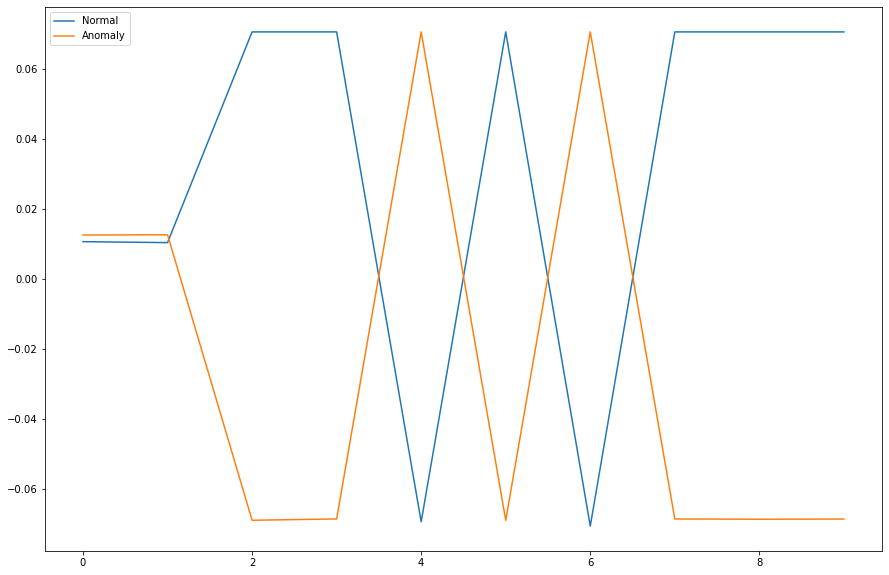

In [256]:

import matplotlib.pyplot as plt

limit = 10
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [339]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.031456


In [340]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [341]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.3132540809084457
0.5692423704755145


In [342]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7353176011355571
F1 =  0.7000753958280975
Precision_score =  0.9861229113565562
recall_score =  0.5426634458037871
roc_auc_score =  0.8198616555507063
pr_auc =  0.9060424152479546
matthews_corr_score =  0.5685869009796645


In [343]:
threshold = 0.164
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))


attack_name = 'PROBE'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'DOS'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'NORMAL'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(1-y_test[index_single_attack],1-ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'U2R'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'R2L'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]
print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.807931156848829
F1 =  0.8220596695980932
Precision_score =  0.8696635075210851
recall_score =  0.7793968674511026
roc_auc_score =  0.8198616555507063
pr_auc =  0.9060424152479546
matthews_corr_score =  0.6191411260940664
.......
 single attack PROBE
Accuracy =  0.815365551425031
F1 =  0.8982935153583619
Precision_score =  1.0
recall_score =  0.815365551425031
.......
 single attack DOS
Accuracy =  0.9757307589165997
F1 =  0.9877163216830674
Precision_score =  1.0
recall_score =  0.9757307589165997
.......
 single attack NORMAL
Accuracy =  0.8456389661208938
F1 =  0.9163644479160855
Precision_score =  1.0
recall_score =  0.8456389661208938
.......
 single attack U2R
Accuracy =  0.115
F1 =  0.2062780269058296
Precision_score =  1.0
recall_score =  0.115
.......
 single attack R2L
Accuracy =  0.2760375880971026
F1 =  0.4326480515495551
Precision_score =  1.0
recall_score =  0.2760375880971026


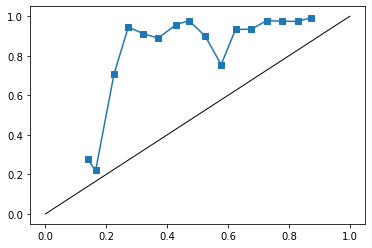

In [269]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

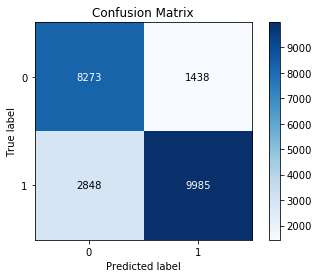

In [270]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

## logloss+contractive, missing DOS
latent = 400
Dense-RELU
seed = 1234
alpha_val = 0.0001

In [271]:
index_PROBE = np.where(YTrainAN5.values=='DOS')[0]
index_PROBE

rounds = 2
XTrainM_small = np.delete(XTrainM,index_PROBE,0)
YTrainANMOhe_small = np.delete(YTrainANMOhe,index_PROBE,0)

In [272]:
XTrainM_extended_small = XTrainM_small.copy()

In [273]:
XTrainM_extended_small = ExtendX (XTrainM_extended_small,XTrainM_small)
XTrainM_extended_small.shape

(160092, 122)

In [274]:
YTrainANMOhe_extended_small = YTrainANMOhe_small.copy()

In [275]:
YTrainANMOhe_extended_small = ExtendY(YTrainANMOhe_extended_small,YTrainANMOhe_small)
YTrainANMOhe_extended_small.shape

(160092, 2)

In [276]:
YTrainOutput_small = np.append(np.ones(XTrainM_small.shape[0]), np.zeros((rounds-1)*XTrainM_small.shape[0]))

In [277]:
YTrainAN5_small = YTrainAN5.drop(index_PROBE)
YTrainAN_small = YTrainAN.drop(index_PROBE)
print(XTrainM_extended_small.shape,YTrainOutput_small.shape, YTrainANMOhe_extended_small.shape )

(160092, 122) (160092,) (160092, 2)


In [314]:
x_train, x_test, label_train, label_test, y_train, y_test = XTrainM_extended_small, XTestM_extended, \
                                                            YTrainANMOhe_extended_small, YTestANMOhe_extended,\
                                                            YTrainOutput_small, YTestOutput
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape)


(160092, 122) (45088, 122) (160092, 2) (45088, 2) (160092,) (45088,)


In [280]:
# save the best weights for predicting the test question pairs
file_name = 'contractive CLC_NSL_X  v1.0 2 denserelu missing 2'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
2
1


### Preparar modelo

In [281]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [282]:
def cosine_act(x):
    return tf.math.cos(x)

In [283]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [284]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [285]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [286]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [287]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [288]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = tf.math.sign(h_cos)  # N_batch x N_hidden, por ser relu

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)


In [289]:
vocab_size = in_dim_label  # no usado de momento
embed_dim = 10

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, seed, alpha_val):
    
    tf.random.set_seed(seed)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "relu", trainable = True, 
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "relu", trainable = True, 
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [290]:
#crear modelo
rff_dim = 400
seed = 1234
alpha_val = 0.0001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [291]:
model.summary()

Model: "model_15"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_11 (InputLayer)           [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_12 (InputLayer)           [(None, 2)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_11[0][0]                   
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          1200        input_12[0][0]                   
___________________________________________________________________________________________

In [292]:
model_embed_x.summary()

Model: "model_16"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_11 (InputLayer)        [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [293]:
model_embed_label.summary()

Model: "model_17"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_12 (InputLayer)        [(None, 2)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               1200      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 1,200
Trainable params: 1,200
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [294]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [295]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit(
                    #[x_train,label_train],[y_train,y_train_zeros],
                    [x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 128073 samples, validate on 32019 samples
Epoch 1/100
128073/128073 [==============================] - 7s 51us/sample - loss: 0.7713 - accuracy: 0.7032 - val_loss: 0.5849 - val_accuracy: 0.8345
Epoch 2/100
128073/128073 [==============================] - 6s 47us/sample - loss: 0.2707 - accuracy: 0.9441 - val_loss: 0.3023 - val_accuracy: 0.9694
Epoch 3/100
128073/128073 [==============================] - 6s 48us/sample - loss: 0.1802 - accuracy: 0.9759 - val_loss: 0.2457 - val_accuracy: 0.9719
Epoch 4/100
128073/128073 [==============================] - 6s 48us/sample - loss: 0.1569 - accuracy: 0.9791 - val_loss: 0.2264 - val_accuracy: 0.9752
Epoch 5/100
128073/128073 [==============================] - 6s 46us/sample - loss: 0.1494 - accuracy: 0.9822 - val_loss: 0.2252 - val_accuracy: 0.9763
Epoch 6/100
128073/128073 [==============================] - 6s 47us/sample - loss: 0.1437 - accuracy: 0.9840 - val_loss: 0.2308 - val_accuracy: 0.9775
Epoch 7/100
128073/128073 [==========

In [296]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [297]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

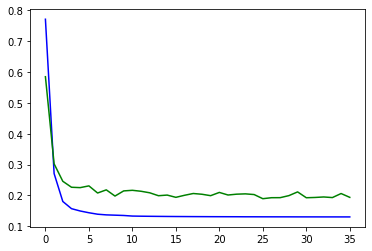

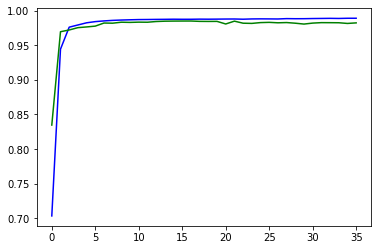

Minimum val_loss at epoch 26 = 0.1893


In [298]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Visualizar embeddings

In [299]:
model.load_weights(save_best_weights)

In [300]:
label_embeddings = model_embed_label.predict((np.array([[1,0],[0,1]])))
label_embeddings.shape

(2, 400)

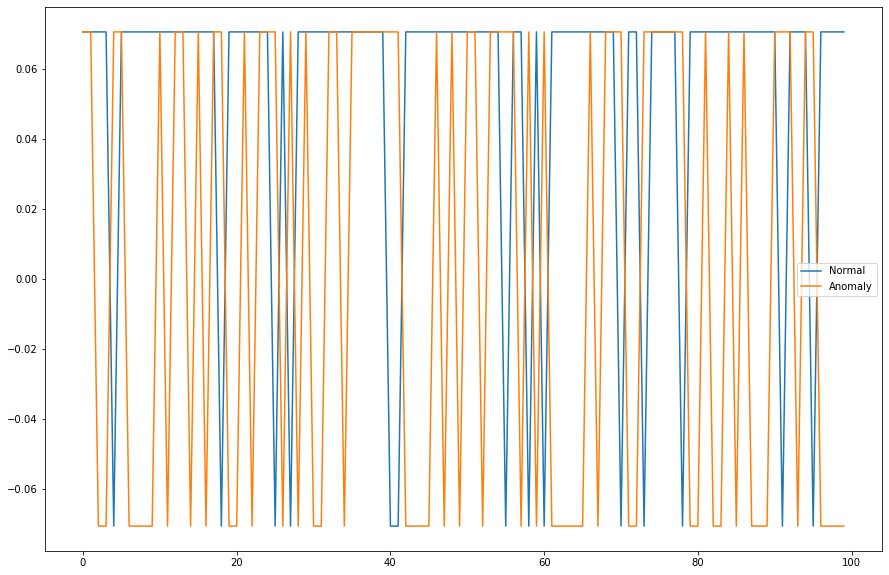

In [301]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

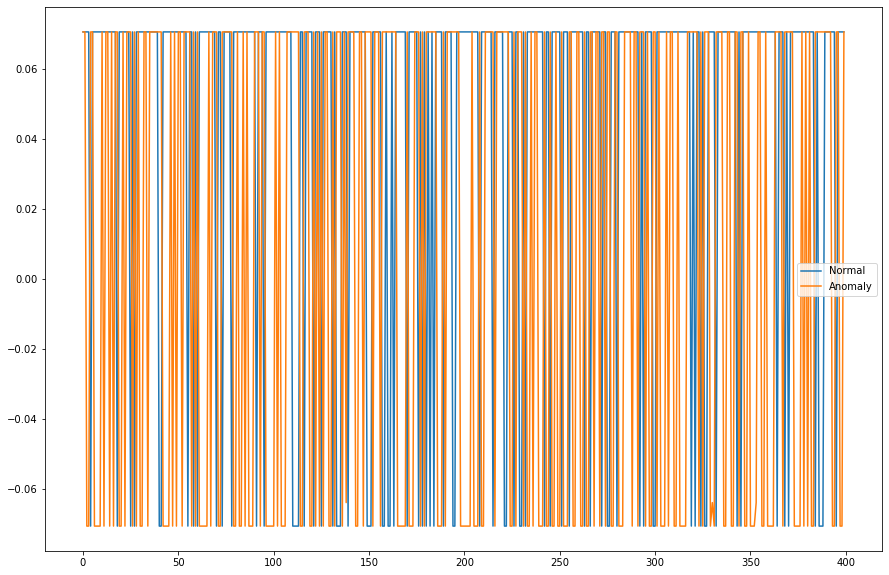

In [302]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(15,10))
plt.plot(label_embeddings[0,0:limit],label = "Normal")
plt.plot(label_embeddings[1,0:limit],label = "Anomaly")
plt.legend()
plt.show()

In [303]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(160092, 400)

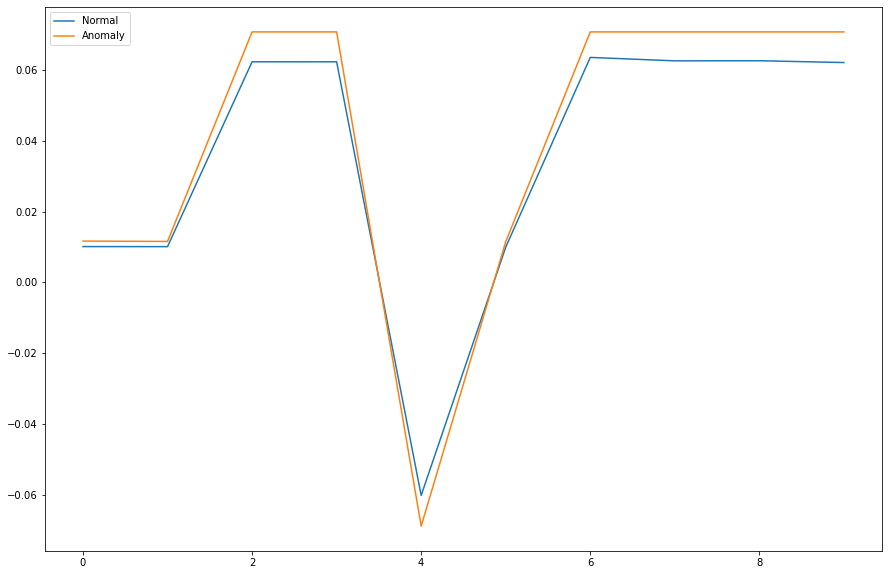

In [304]:

import matplotlib.pyplot as plt

limit = 10
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "Normal")
plt.plot(x_embeddings[2,0:limit],label = "Anomaly")
plt.legend()
plt.show()


###  Prediccion modelo entrenado

In [317]:
from sklearn.preprocessing import normalize
model.load_weights(save_best_weights)

t0 = time.time()

num_labels = YTestANMOhe.shape[1]
test_samples = YTestANMOhe.shape[0]
model_mat_prob_hat = np.zeros([test_samples, num_labels])
labels_ohe_lst = [[1,0],[0,1]]
labels_lst = invTransLabels2labels_bis(labels_ohe_lst)
for i in range (num_labels):
    rep_label = np.tile(labels_ohe_lst[i],(test_samples,1))
    model_mat_prob_hat[:,i] = np.squeeze(model.predict([XTestM,rep_label]))

model_mat_prob_hat = normalize(model_mat_prob_hat, axis=1, norm='l1')

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.026073


In [318]:
ytest_prob_hat = model_mat_prob_hat[:,1]
#renombramos variables para lo que viene despues
y_test = YTestANMOhe[:,1]
x_test = XTestM
x_train = XTrainM
label_train = YTrainANMOhe
label_test = YTestANMOhe
y_train = YTrainANMOhe[:,1]

num_classes = ['normal', 'anomaly']

In [319]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(22544,)
0.3140525195173882
0.5692423704755145


In [320]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7088804116394606
F1 =  0.670416310952644
Precision_score =  0.9427966101694916
recall_score =  0.5201433803475415
roc_auc_score =  0.7711325714938388
pr_auc =  0.8492181333699076
matthews_corr_score =  0.510439506071305


In [324]:
threshold = 0.16
ytest_hat = ((ytest_prob_hat > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat))) 
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))


attack_name = 'PROBE'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'DOS'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'NORMAL'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(1-y_test[index_single_attack],1-ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(1-y_test[index_single_attack], 1-ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'U2R'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]

print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

attack_name = 'R2L'
index_single_attack = np.where(YTestAN5.values==attack_name)[0]
print('.......')
print (' single attack {}'.format(attack_name))
print('Accuracy =  {}'.format(accuracy_score(y_test[index_single_attack], ytest_hat[index_single_attack])))
print('F1 =  {}'.format(f1_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test[index_single_attack], ytest_hat[index_single_attack], pos_label=1, average='binary')))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.7371362668559261
F1 =  0.7220189511211184
Precision_score =  0.9070123747790219
recall_score =  0.5997038884126861
roc_auc_score =  0.7711325714938388
pr_auc =  0.8492181333699076
matthews_corr_score =  0.5299131402196731
.......
 single attack PROBE
Accuracy =  0.9558033870301529
F1 =  0.9774023231256601
Precision_score =  1.0
recall_score =  0.9558033870301529
.......
 single attack DOS
Accuracy =  0.638508983641727
F1 =  0.7793780687397709
Precision_score =  1.0
recall_score =  0.638508983641727
.......
 single attack NORMAL
Accuracy =  0.9187519308001235
F1 =  0.9576557720173885
Precision_score =  1.0
recall_score =  0.9187519308001235
.......
 single attack U2R
Accuracy =  0.0975
F1 =  0.17767653758542143
Precision_score =  1.0
recall_score =  0.0975
.......
 single attack R2L
Accuracy =  0.2274862960062647
F1 =  0.3706539074960128
Precision_score =  1.0
recall_score =  0.2274862960062647


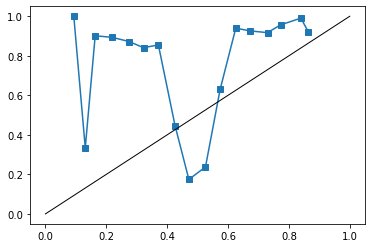

In [325]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

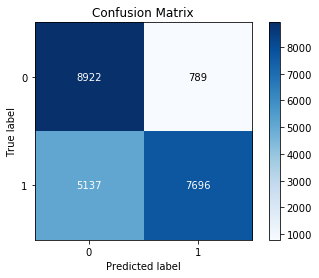

In [326]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

# Modelos con 5 Labels

## logloss+contractive, 
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.00001

In [312]:
x_train, x_test, label_train, label_test, y_train, y_test = XTrainM5_extended, XTestM5_extended, \
                                                            YTrainANMOhe5_extended, YTestANMOhe5_extended,\
                                                            YTrainOutput5, YTestOutput5
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape)


(629865, 122) (112720, 122) (629865, 5) (112720, 5) (629865,) (112720,)


In [313]:
pd.Series(label_train[:,1]).value_counts()

0    503892
1    125973
dtype: int64

In [432]:
# save the best weights for predicting the test question pairs
file_name = 'contracted CLC_5NSL_3 dim 10 v1.0 1'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
5
1


### Preparar modelo

In [433]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [434]:
def cosine_act(x):
    return tf.math.cos(x)

In [435]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [436]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [437]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [438]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [439]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [449]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [450]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [451]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.00001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [452]:
model.summary()

Model: "model_30"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_27 (InputLayer)           [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_28 (InputLayer)           [(None, 5)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_27[0][0]                   
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          2400        input_28[0][0]                   
___________________________________________________________________________________________

In [453]:
model_embed_x.summary()

Model: "model_31"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_27 (InputLayer)        [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [454]:
model_embed_label.summary()

Model: "model_32"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_28 (InputLayer)        [(None, 5)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               2400      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 2,400
Trainable params: 2,400
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [455]:
np.random.seed(247531338)
tf.random.set_seed(31722973)

In [456]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit([x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 503892 samples, validate on 125973 samples
Epoch 1/100
503892/503892 [==============================] - 25s 49us/sample - loss: 3.2434 - accuracy: 0.9574 - val_loss: 3.7138 - val_accuracy: 0.3854
Epoch 2/100
503892/503892 [==============================] - 24s 47us/sample - loss: 3.1344 - accuracy: 0.9834 - val_loss: 3.7258 - val_accuracy: 0.3797
Epoch 3/100
503892/503892 [==============================] - 23s 46us/sample - loss: 3.1119 - accuracy: 0.9844 - val_loss: 3.7307 - val_accuracy: 0.3785
Epoch 4/100
503892/503892 [==============================] - 24s 47us/sample - loss: 3.1015 - accuracy: 0.9851 - val_loss: 3.7341 - val_accuracy: 0.3790
Epoch 5/100
503892/503892 [==============================] - 24s 48us/sample - loss: 3.0953 - accuracy: 0.9848 - val_loss: 3.7342 - val_accuracy: 0.3789
Epoch 6/100
503892/503892 [==============================] - 24s 47us/sample - loss: 3.0913 - accuracy: 0.9856 - val_loss: 3.7415 - val_accuracy: 0.3779
Epoch 7/100
503892/503892 [===

In [457]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [458]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

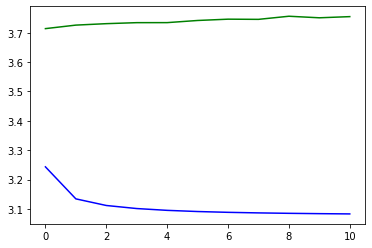

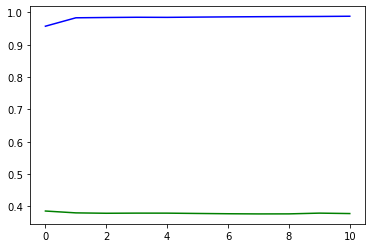

Minimum val_loss at epoch 1 = 3.7138


In [459]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Prediccion

In [460]:
model.load_weights(save_best_weights)

### prediccion sobre el conjunto de test y fake para deteccion de aciertos (deteccion binaria)

In [461]:
t0 = time.time()

ytest_prob_hat_binary = model.predict([x_test,label_test])

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.086429


In [462]:
pd.Series(ytest_prob_hat_binary.flatten()).describe()

count    112720.000000
mean          0.404744
std           0.244971
min           0.013257
25%           0.174037
50%           0.439686
75%           0.547729
max           0.984925
dtype: float64

In [463]:
#ytest_prob_hat_binary = (ytest_prob_hat_binary-min(ytest_prob_hat_binary))/(max(ytest_prob_hat_binary)-min(ytest_prob_hat_binary)) # escalamos 0-1

In [464]:
#pd.Series(ytest_prob_hat_binary.flatten()).describe()

In [465]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat_binary > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(112720,)
0.3471167494677076
0.2


In [466]:
threshold = 0.7
ytest_hat = ((ytest_prob_hat_binary > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat_binary)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat_binary)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.9022090134847409
F1 =  0.6976106218966889
Precision_score =  0.9141563016751744
recall_score =  0.5640081618168914
roc_auc_score =  0.8765479743484674
pr_auc =  0.7476116032639439
matthews_corr_score =  0.6698515824962119


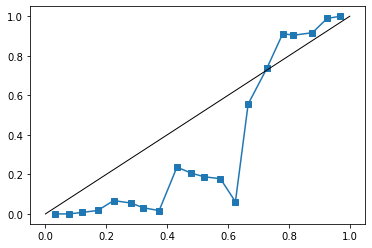

In [467]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat_binary, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

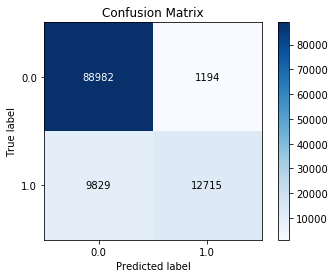

In [468]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

### prediccion real sobre el conjunto de test para predecir la clase en concreto

In [469]:
lb5.inverse_transform(labelOHEncodedFromPrediction([[0.8,0.7,0,0,0],[0,0.6,0,0,0],[0,0,1,0,0],[0,0,0,1,0],[0,0,0,0,1]]))

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype='<U6')

In [470]:
lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'])

array([[1, 0, 0, 0, 0],
       [0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 0, 0, 1]])

In [471]:
t0 = time.time()

total_label_test =[np.tile(lb5.transform([i]),(len(YTestAN5MOhe),1)) for i in ['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']]
ytest_prob_hat = np.column_stack([model.predict([XTestM,i]) for i in total_label_test])
ytest_prob_hat.shape

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.082781


In [491]:
ytest_prob_hat

array([[0.97299978, 0.28902227, 0.10133585, 0.16136193, 0.36844883],
       [0.9081492 , 0.31236863, 0.1597364 , 0.21315618, 0.3933817 ],
       [0.56335423, 0.66191488, 0.29838367, 0.28064553, 0.26319094],
       ...,
       [0.66167261, 0.65280539, 0.18494778, 0.1667136 , 0.18410542],
       [0.5817626 , 0.75840912, 0.2008853 , 0.15953525, 0.12757589],
       [0.48283246, 0.50278825, 0.51704868, 0.50946466, 0.50530931]])

In [472]:
y_test_hat = lb5.inverse_transform(labelOHEncodedFromPrediction(ytest_prob_hat))
y_test_hat

array(['DOS', 'DOS', 'NORMAL', ..., 'DOS', 'NORMAL', 'PROBE'], dtype='<U6')

In [473]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef


average_type = 'weighted' # micro' , 'weighted'
print('Performance measures on Test data')
print('Accuracy =  {}'.format(accuracy_score( lb5.inverse_transform(YTestAN5MOhe),y_test_hat)))

print('F1 =  {}'.format(f1_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('Precision_score =  {}'.format(precision_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('recall_score =  {}'.format(recall_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('roc_auc_score =  {}'.format(roc_auc_score(YTestAN5MOhe,normalize(ytest_prob_hat, axis=1, norm='l1'))))

print('matthews_corr_score =  {}'.format(matthews_corrcoef(lb5.inverse_transform(YTestAN5MOhe), y_test_hat)))

Performance measures on Test data
Accuracy =  0.660486160397445
F1 =  0.5914038248310068
Precision_score =  0.5611191801043485
recall_score =  0.660486160397445
roc_auc_score =  0.7675679662526356
matthews_corr_score =  0.4780280496487926


In [474]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef

average_type = 'micro' # micro' , 'weighted'
print('Performance measures on Test data')
print('Accuracy =  {}'.format(accuracy_score( lb5.inverse_transform(YTestAN5MOhe),y_test_hat)))

print('F1 =  {}'.format(f1_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('Precision_score =  {}'.format(precision_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('recall_score =  {}'.format(recall_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('roc_auc_score =  {}'.format(roc_auc_score(YTestAN5MOhe,normalize(ytest_prob_hat, axis=1, norm='l1'))))

print('matthews_corr_score =  {}'.format(matthews_corrcoef(lb5.inverse_transform(YTestAN5MOhe), y_test_hat)))

Performance measures on Test data
Accuracy =  0.660486160397445
F1 =  0.660486160397445
Precision_score =  0.660486160397445
recall_score =  0.660486160397445
roc_auc_score =  0.7675679662526356
matthews_corr_score =  0.4780280496487926


### Perform test evaluation one vs. rest

Percentage per label class

In [475]:
(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts()/pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts().sum())*100

NORMAL    43.075763
DOS       33.081973
R2L       11.328957
PROBE     10.738999
U2R        1.774308
dtype: float64

In [476]:
(pd.Series(y_test_hat).value_counts()/pd.Series(y_test_hat).value_counts().sum())*100

NORMAL    63.240774
DOS       32.044003
PROBE      3.184883
U2R        0.882718
R2L        0.647622
dtype: float64

In [477]:
yt_app = lb5.inverse_transform(YTestAN5MOhe)
perf_per_class = pd.DataFrame(index=range(len(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).unique())),columns=['name', 'acc','f1', 'pre','rec'])
for i,x in enumerate(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts().index):
    y_test_hat_check = y_test_hat.copy()
    y_test_hat_check[y_test_hat_check != x] = 'OTHER'
    yt_app = lb5.inverse_transform(YTestAN5MOhe).copy()
    yt_app[yt_app != x] = 'OTHER'
    ac=accuracy_score( yt_app,y_test_hat_check)
    f1=f1_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    pr=precision_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    re=recall_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    perf_per_class.iloc[i]=[x,ac,f1,pr,re]

In [478]:
# performance measures per class for test data
perf_per_class

,name,acc,f1,pre,rec
0,NORMAL,0.741838,0.757176,0.636459,0.934404
1,DOS,0.853353,0.774826,0.787375,0.762671
2,R2L,0.881299,0.00888889,0.0821918,0.00469851
3,PROBE,0.870786,0.0719975,0.157382,0.0466749
4,U2R,0.973696,0.0100167,0.0150754,0.0075


###  Visualizar embeddings

In [479]:
model.load_weights(save_best_weights)

In [480]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

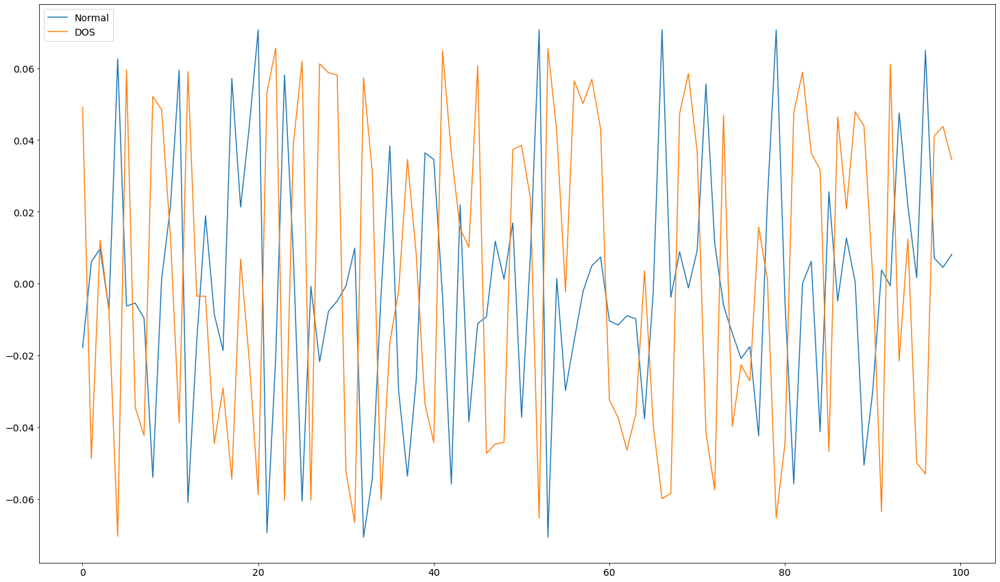

In [481]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[0,0:limit],label = "DOS")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

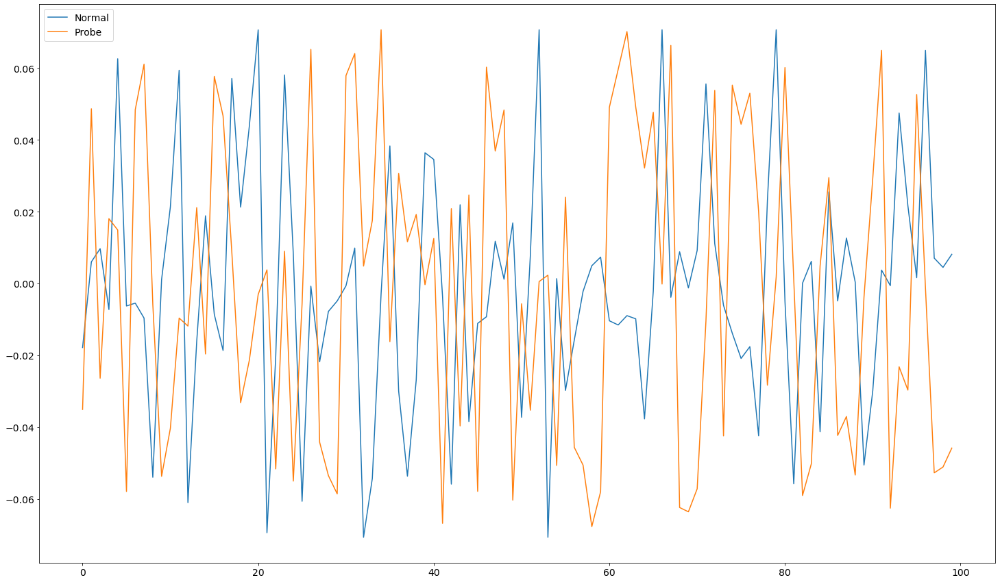

In [482]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[2,0:limit],label = "Probe")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

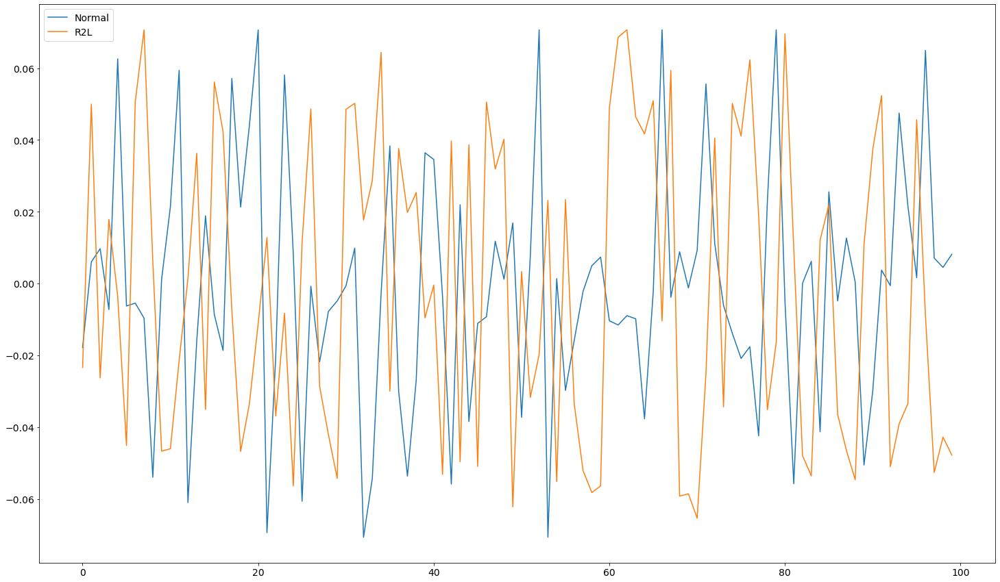

In [483]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[3,0:limit],label = "R2L")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

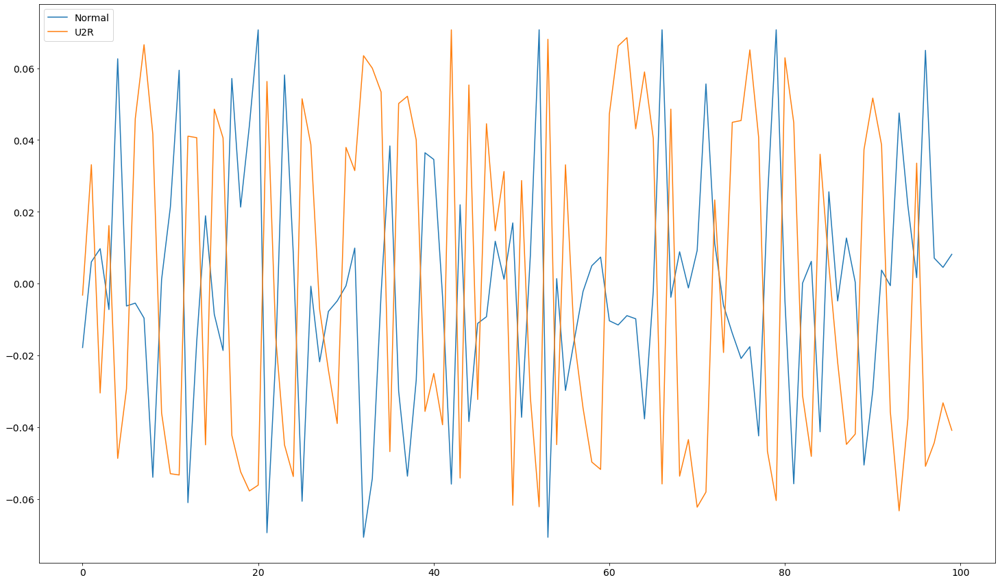

In [484]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[4,0:limit],label = "U2R")
plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

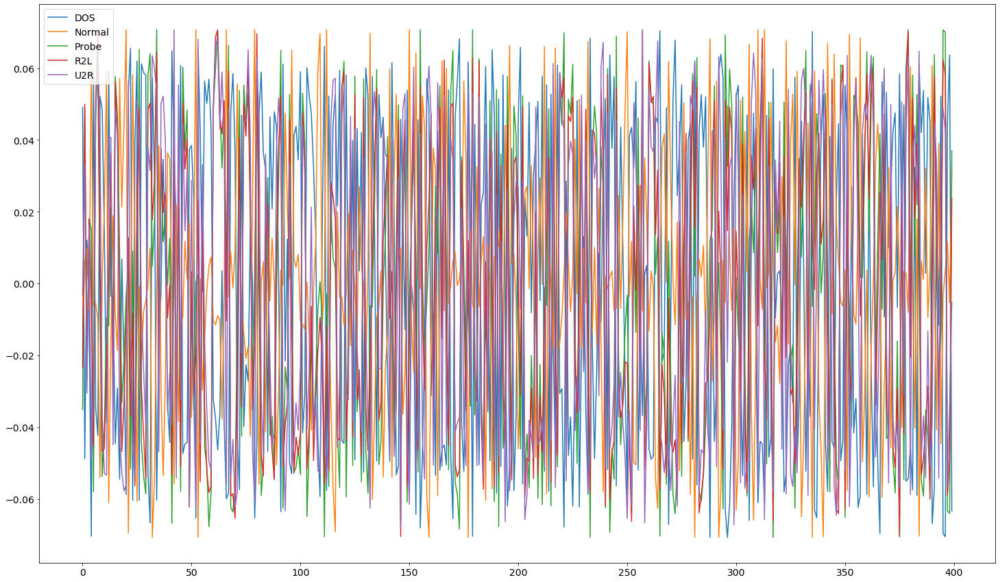

In [485]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[0,0:limit],label = "DOS")
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[2,0:limit],label = "Probe")
plt.plot(label_embeddings[3,0:limit],label = "R2L")
plt.plot(label_embeddings[4,0:limit],label = "U2R")
plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

In [486]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(629865, 400)

In [487]:
YTestAN5M

array(['DOS', 'DOS', 'NORMAL', ..., 'DOS', 'NORMAL', 'PROBE'],
      dtype=object)

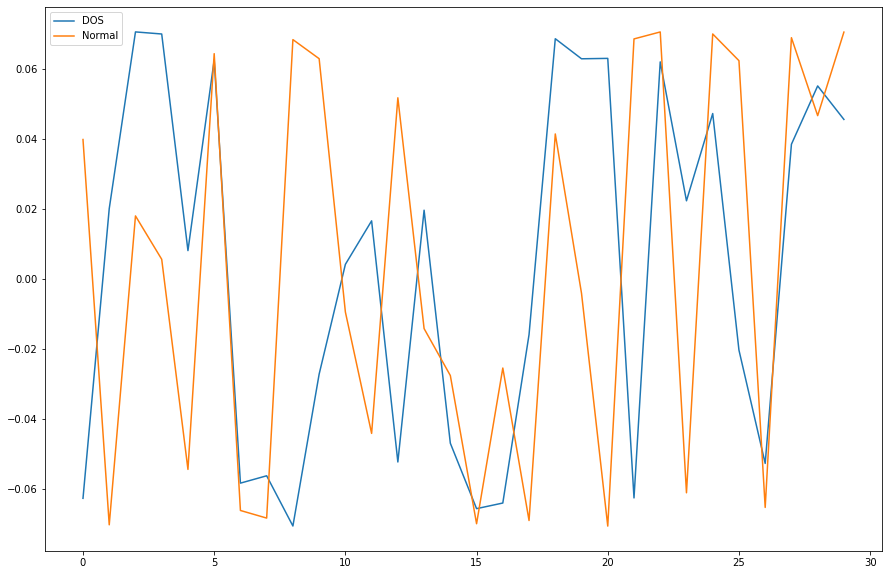

In [490]:
import matplotlib.pyplot as plt

limit = 30
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "DOS")
plt.plot(x_embeddings[2,0:limit],label = "Normal")
plt.legend()
plt.show()


## Graficas Training dataset

In [493]:
model.load_weights(save_best_weights)

In [494]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

In [496]:
def cosine_sim (a,ref):
    return( dot(a, ref)/(norm(a)*norm(ref)))

In [499]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[1,:]  #ref es el label embedding de normal
print("Normal to Dos",cosine_sim (label_embeddings[0,:],ref))
print("Normal to probe",cosine_sim (label_embeddings[2,:],ref))
print("Normal to R2L",cosine_sim (label_embeddings[3,:],ref))
print("Normal to U2R",cosine_sim (label_embeddings[4,:],ref))

Normal to Dos -0.5450231489937754
Normal to probe -0.1328910350587909
Normal to R2L -0.32777109666126397
Normal to U2R -0.7405365210763222


In [503]:
np.unique(YTrainAN5M)

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype=object)

In [504]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTrainM[YTrainAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTrainM[YTrainAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTrainM[YTrainAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTrainM[YTrainAN5M=='U2R']) # embeddings de las muestras u2r

In [505]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_dos = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_dos])
cos_sim_x_embeddings_probe = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_probe])
cos_sim_x_embeddings_R2L = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_R2L])
cos_sim_x_embeddings_U2R = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_U2R])

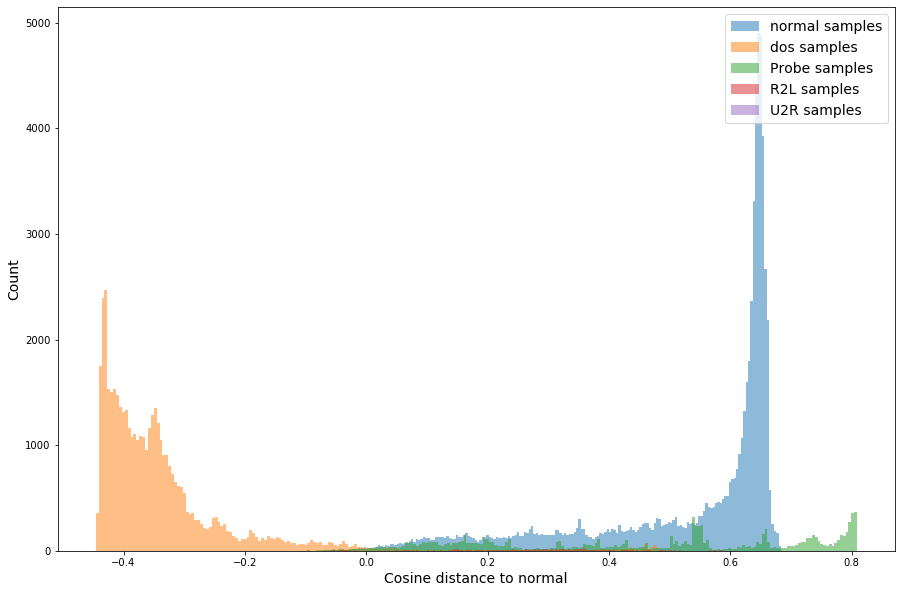

In [506]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_dos, bins=200, alpha=0.5, density=False, label="dos samples")
plt.hist(cos_sim_x_embeddings_probe, bins=200, alpha=0.5, density=False, label="Probe samples")
plt.hist(cos_sim_x_embeddings_R2L, bins=200, alpha=0.5, density=False, label="R2L samples")
plt.hist(cos_sim_x_embeddings_U2R, bins=200, alpha=0.5, density=False, label="U2R samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, training dataset

In [509]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTrainM[YTrainAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTrainM[YTrainAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTrainM[YTrainAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTrainM[YTrainAN5M=='U2R']) # embeddings de las muestras u2r

In [510]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_dos_mean = np.mean(x_embeddings_dos, axis=0)

No handles with labels found to put in legend.


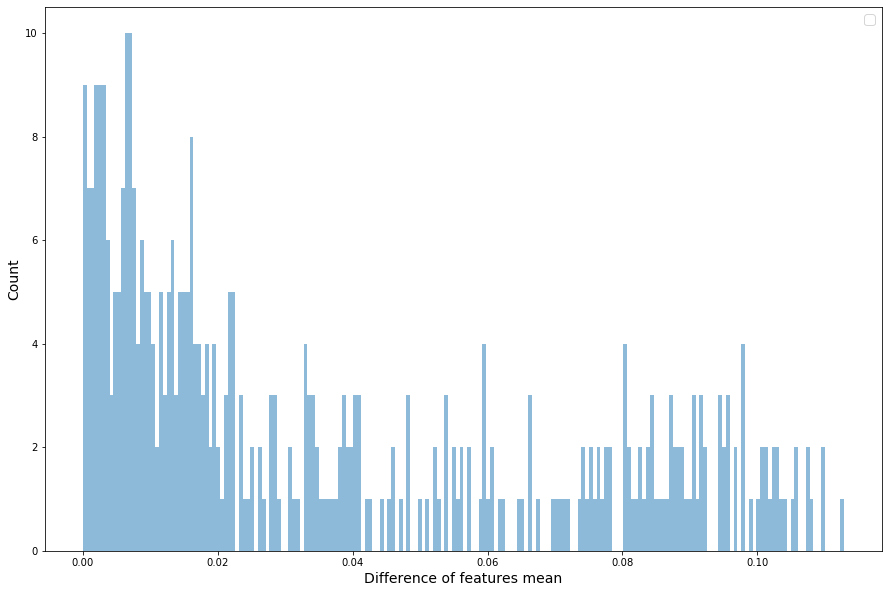

In [511]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [512]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

39.74432666983432 8.317265042295155e-141


## Graficas Test dataset

In [514]:
model.load_weights(save_best_weights)

In [515]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

In [516]:
def cosine_sim (a,ref):
    return( dot(a, ref)/(norm(a)*norm(ref)))

In [517]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[1,:]  #ref es el label embedding de normal
print("Normal to Dos",cosine_sim (label_embeddings[0,:],ref))
print("Normal to probe",cosine_sim (label_embeddings[2,:],ref))
print("Normal to R2L",cosine_sim (label_embeddings[3,:],ref))
print("Normal to U2R",cosine_sim (label_embeddings[4,:],ref))

Normal to Dos -0.5450231489937754
Normal to probe -0.1328910350587909
Normal to R2L -0.32777109666126397
Normal to U2R -0.7405365210763222


In [518]:
np.unique(YTestAN5M)

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype=object)

In [519]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTestM[YTestAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTestM[YTestAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTestM[YTestAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTestM[YTestAN5M=='U2R']) # embeddings de las muestras u2r

In [520]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_dos = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_dos])
cos_sim_x_embeddings_probe = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_probe])
cos_sim_x_embeddings_R2L = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_R2L])
cos_sim_x_embeddings_U2R = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_U2R])

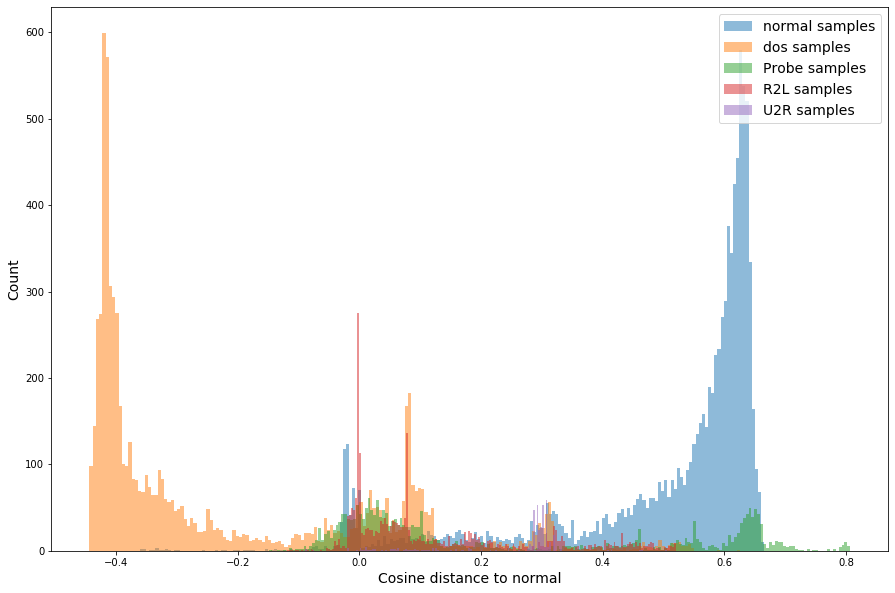

In [521]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_dos, bins=200, alpha=0.5, density=False, label="dos samples")
plt.hist(cos_sim_x_embeddings_probe, bins=200, alpha=0.5, density=False, label="Probe samples")
plt.hist(cos_sim_x_embeddings_R2L, bins=200, alpha=0.5, density=False, label="R2L samples")
plt.hist(cos_sim_x_embeddings_U2R, bins=200, alpha=0.5, density=False, label="U2R samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, test dataset

In [522]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTestM[YTestAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTestM[YTestAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTestM[YTestAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTestM[YTestAN5M=='U2R']) # embeddings de las muestras u2r

In [523]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_dos_mean = np.mean(x_embeddings_dos, axis=0)

No handles with labels found to put in legend.


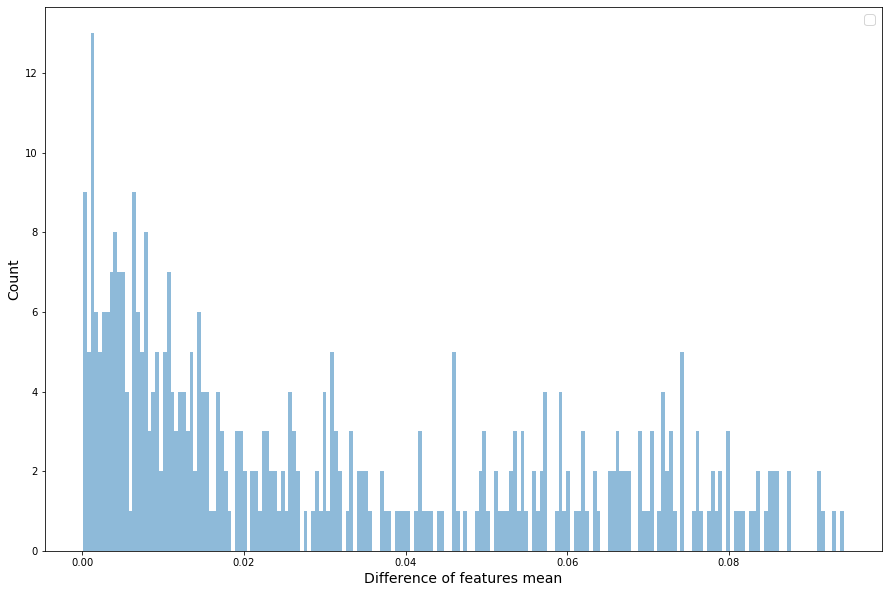

In [524]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [525]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

36.83674183979076 1.8662818045598346e-130


## logloss+contractive, 
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.001

In [598]:
x_train, x_test, label_train, label_test, y_train, y_test = XTrainM5_extended, XTestM5_extended, \
                                                            YTrainANMOhe5_extended, YTestANMOhe5_extended,\
                                                            YTrainOutput5, YTestOutput5
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape)


(629865, 122) (112720, 122) (629865, 5) (112720, 5) (629865,) (112720,)


In [599]:
pd.Series(label_train[:,1]).value_counts()

0    503892
1    125973
dtype: int64

In [600]:
# save the best weights for predicting the test question pairs
file_name = 'contracted CLC_5NSL_3 dim 10 v1.0 2'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
5
1


### Preparar modelo

In [601]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [602]:
def cosine_act(x):
    return tf.math.cos(x)

In [603]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [604]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [605]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [606]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [607]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [608]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [609]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [610]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.001

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [611]:
model.summary()

Model: "model_36"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_31 (InputLayer)           [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_32 (InputLayer)           [(None, 5)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_31[0][0]                   
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          2400        input_32[0][0]                   
___________________________________________________________________________________________

In [612]:
model_embed_x.summary()

Model: "model_37"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_31 (InputLayer)        [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [613]:
model_embed_label.summary()

Model: "model_38"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_32 (InputLayer)        [(None, 5)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               2400      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 2,400
Trainable params: 2,400
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [614]:
np.random.seed(247531338)
tf.random.set_seed(31722973)

In [615]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit([x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 503892 samples, validate on 125973 samples
Epoch 1/100
503892/503892 [==============================] - 28s 55us/sample - loss: 296.2254 - accuracy: 0.9219 - val_loss: 296.4048 - val_accuracy: 0.3935
Epoch 2/100
503892/503892 [==============================] - 26s 51us/sample - loss: 295.9987 - accuracy: 0.9614 - val_loss: 296.3195 - val_accuracy: 0.3901
Epoch 3/100
503892/503892 [==============================] - 26s 52us/sample - loss: 295.9227 - accuracy: 0.9637 - val_loss: 296.2764 - val_accuracy: 0.3875
Epoch 4/100
503892/503892 [==============================] - 27s 53us/sample - loss: 295.8849 - accuracy: 0.9639 - val_loss: 296.2547 - val_accuracy: 0.3857
Epoch 5/100
503892/503892 [==============================] - 26s 52us/sample - loss: 295.8645 - accuracy: 0.9625 - val_loss: 296.2386 - val_accuracy: 0.3852
Epoch 6/100
503892/503892 [==============================] - 26s 51us/sample - loss: 295.8519 - accuracy: 0.9623 - val_loss: 296.2313 - val_accuracy: 0.3832
Epoch 

In [616]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [617]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

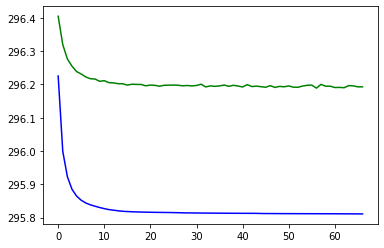

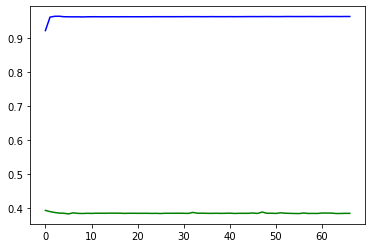

Minimum val_loss at epoch 57 = 296.1889


In [618]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Prediccion

In [619]:
model.load_weights(save_best_weights)

### prediccion sobre el conjunto de test y fake para deteccion de aciertos (deteccion binaria)

In [620]:
t0 = time.time()

ytest_prob_hat_binary = model.predict([x_test,label_test])

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.080682


In [621]:
pd.Series(ytest_prob_hat_binary.flatten()).describe()

count    112720.000000
mean          0.416572
std           0.217946
min           0.045398
25%           0.287424
50%           0.433856
75%           0.543356
max           0.906364
dtype: float64

In [622]:
#ytest_prob_hat_binary = (ytest_prob_hat_binary-min(ytest_prob_hat_binary))/(max(ytest_prob_hat_binary)-min(ytest_prob_hat_binary)) # escalamos 0-1

In [623]:
#pd.Series(ytest_prob_hat_binary.flatten()).describe()

In [624]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat_binary > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(112720,)
0.32867281760113554
0.2


In [625]:
threshold = 0.7
ytest_hat = ((ytest_prob_hat_binary > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat_binary)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat_binary)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8685770049680624
F1 =  0.54697247706422
Precision_score =  0.8805632138637258
recall_score =  0.3966909155429382
roc_auc_score =  0.862697240556721
pr_auc =  0.7437763560548294
matthews_corr_score =  0.5353925830271189


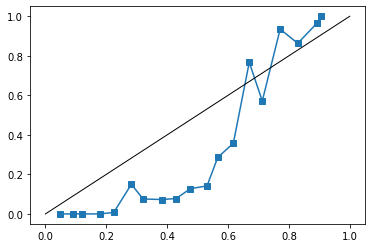

In [626]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat_binary, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

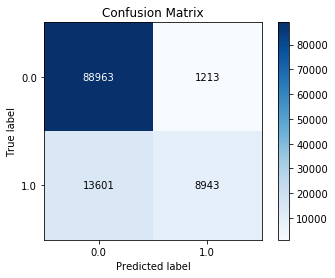

In [627]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

### prediccion real sobre el conjunto de test para predecir la clase en concreto

In [628]:
lb5.inverse_transform(labelOHEncodedFromPrediction([[0.8,0.7,0,0,0],[0,0.6,0,0,0],[0,0,1,0,0],[0,0,0,1,0],[0,0,0,0,1]]))

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype='<U6')

In [629]:
lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'])

array([[1, 0, 0, 0, 0],
       [0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 0, 0, 1]])

In [630]:
t0 = time.time()

total_label_test =[np.tile(lb5.transform([i]),(len(YTestAN5MOhe),1)) for i in ['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']]
ytest_prob_hat = np.column_stack([model.predict([XTestM,i]) for i in total_label_test])
ytest_prob_hat.shape

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.080569


In [631]:
ytest_prob_hat

array([[0.65348927, 0.4453311 , 0.3943239 , 0.3890605 , 0.44945971],
       [0.65346732, 0.44550824, 0.39415552, 0.38883132, 0.44921839],
       [0.53187854, 0.70663626, 0.27817358, 0.27405374, 0.25241678],
       ...,
       [0.5797528 , 0.86448449, 0.08882888, 0.09460229, 0.0629272 ],
       [0.54601281, 0.67699503, 0.30724855, 0.29445057, 0.28612812],
       [0.51656581, 0.50692419, 0.47289718, 0.46054998, 0.46915264]])

In [632]:
y_test_hat = lb5.inverse_transform(labelOHEncodedFromPrediction(ytest_prob_hat))
y_test_hat

array(['DOS', 'DOS', 'NORMAL', ..., 'NORMAL', 'NORMAL', 'DOS'],
      dtype='<U6')

In [633]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef


average_type = 'weighted' # micro' , 'weighted'
print('Performance measures on Test data')
print('Accuracy =  {}'.format(accuracy_score( lb5.inverse_transform(YTestAN5MOhe),y_test_hat)))

print('F1 =  {}'.format(f1_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('Precision_score =  {}'.format(precision_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('recall_score =  {}'.format(recall_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('roc_auc_score =  {}'.format(roc_auc_score(YTestAN5MOhe,normalize(ytest_prob_hat, axis=1, norm='l1'))))

print('matthews_corr_score =  {}'.format(matthews_corrcoef(lb5.inverse_transform(YTestAN5MOhe), y_test_hat)))

Performance measures on Test data
Accuracy =  0.6901614620298083
F1 =  0.614893023063949
Precision_score =  0.6582449549364564
recall_score =  0.6901614620298083
roc_auc_score =  0.6984877145905436
matthews_corr_score =  0.5412949679227665


In [634]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef

average_type = 'micro' # micro' , 'weighted'
print('Performance measures on Test data')
print('Accuracy =  {}'.format(accuracy_score( lb5.inverse_transform(YTestAN5MOhe),y_test_hat)))

print('F1 =  {}'.format(f1_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('Precision_score =  {}'.format(precision_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('recall_score =  {}'.format(recall_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('roc_auc_score =  {}'.format(roc_auc_score(YTestAN5MOhe,normalize(ytest_prob_hat, axis=1, norm='l1'))))

print('matthews_corr_score =  {}'.format(matthews_corrcoef(lb5.inverse_transform(YTestAN5MOhe), y_test_hat)))

Performance measures on Test data
Accuracy =  0.6901614620298083
F1 =  0.6901614620298083
Precision_score =  0.6901614620298083
recall_score =  0.6901614620298083
roc_auc_score =  0.6984877145905436
matthews_corr_score =  0.5412949679227665


### Perform test evaluation one vs. rest

Percentage per label class

In [635]:
(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts()/pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts().sum())*100

NORMAL    43.075763
DOS       33.081973
R2L       11.328957
PROBE     10.738999
U2R        1.774308
dtype: float64

In [636]:
(pd.Series(y_test_hat).value_counts()/pd.Series(y_test_hat).value_counts().sum())*100

NORMAL    69.721434
DOS       28.970014
PROBE      1.042406
U2R        0.155252
R2L        0.110894
dtype: float64

In [637]:
yt_app = lb5.inverse_transform(YTestAN5MOhe)
perf_per_class = pd.DataFrame(index=range(len(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).unique())),columns=['name', 'acc','f1', 'pre','rec'])
for i,x in enumerate(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts().index):
    y_test_hat_check = y_test_hat.copy()
    y_test_hat_check[y_test_hat_check != x] = 'OTHER'
    yt_app = lb5.inverse_transform(YTestAN5MOhe).copy()
    yt_app[yt_app != x] = 'OTHER'
    ac=accuracy_score( yt_app,y_test_hat_check)
    f1=f1_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    pr=precision_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    re=recall_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    perf_per_class.iloc[i]=[x,ac,f1,pr,re]

In [638]:
# performance measures per class for test data
perf_per_class

,name,acc,f1,pre,rec
0,NORMAL,0.722897,0.754336,0.610192,0.987643
1,DOS,0.888618,0.820502,0.878732,0.769509
2,R2L,0.885601,0,0,0
3,PROBE,0.902413,0.171687,0.970213,0.094176
4,U2R,0.980793,0.0045977,0.0285714,0.0025


###  Visualizar embeddings

In [639]:
model.load_weights(save_best_weights)

In [640]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

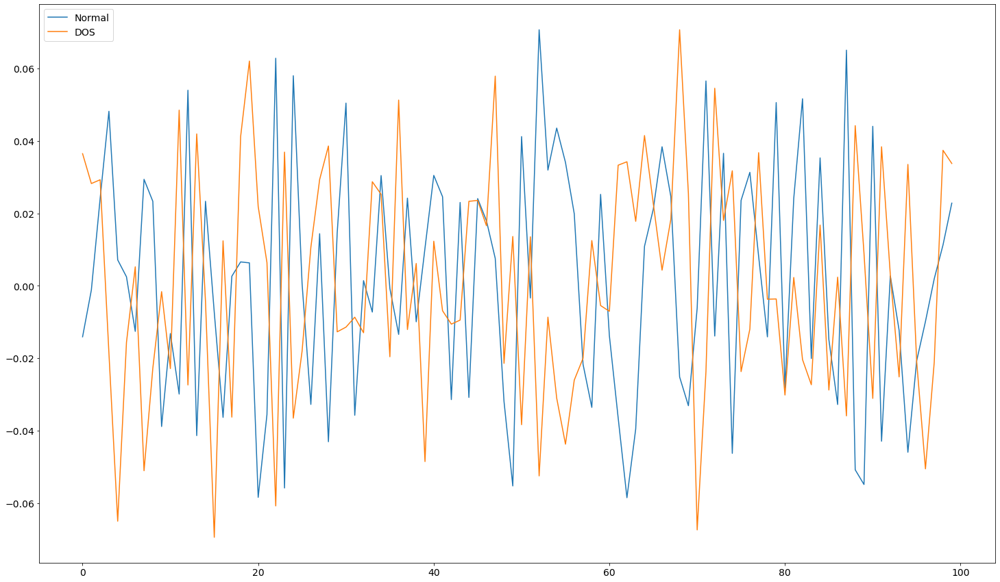

In [641]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[0,0:limit],label = "DOS")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

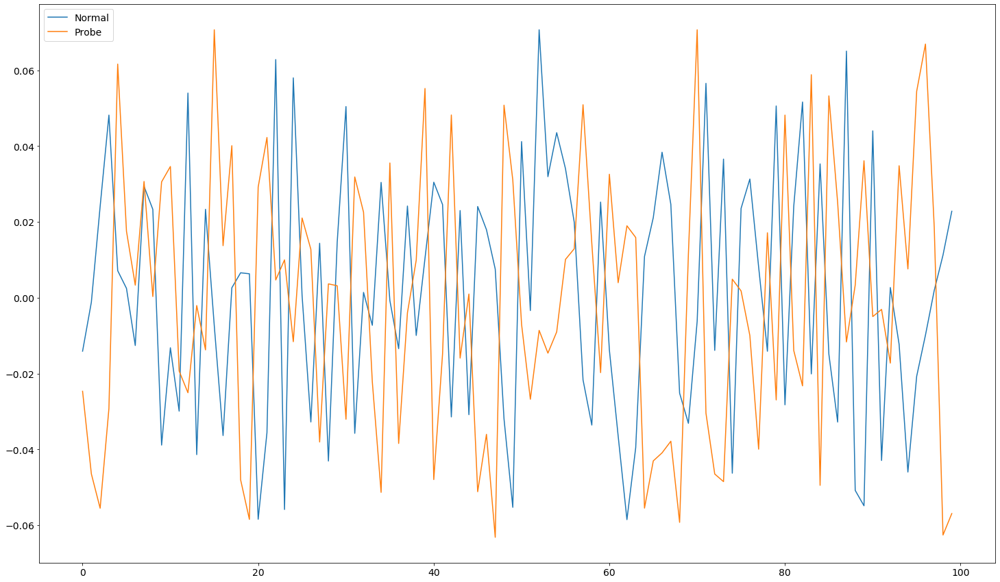

In [642]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[2,0:limit],label = "Probe")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

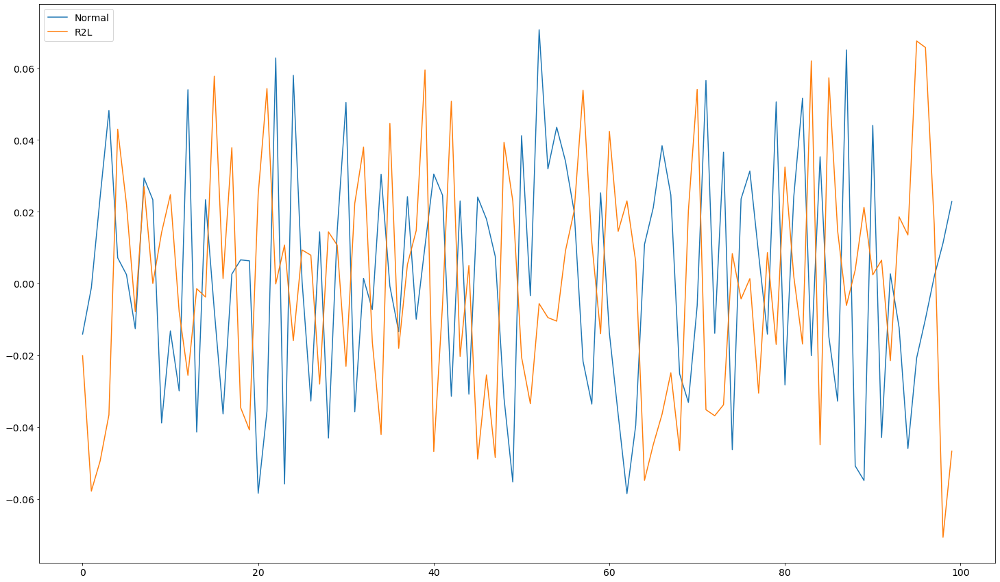

In [643]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[3,0:limit],label = "R2L")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

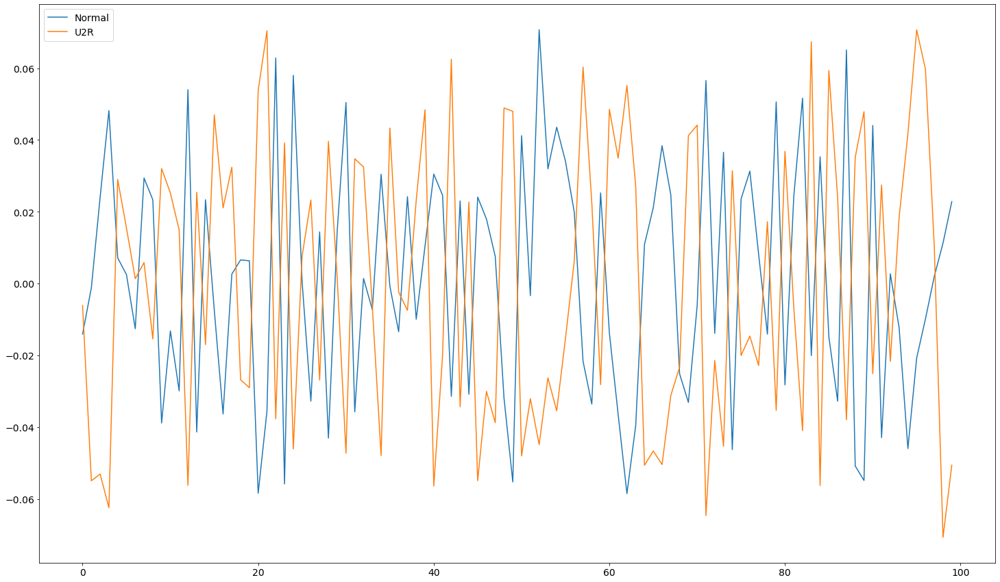

In [644]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[4,0:limit],label = "U2R")
plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

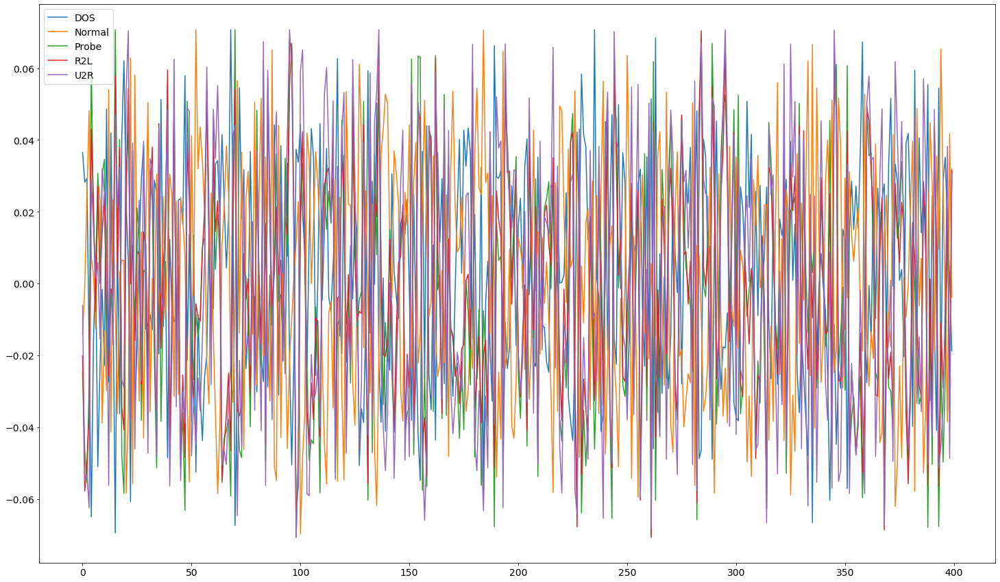

In [645]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[0,0:limit],label = "DOS")
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[2,0:limit],label = "Probe")
plt.plot(label_embeddings[3,0:limit],label = "R2L")
plt.plot(label_embeddings[4,0:limit],label = "U2R")
plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

In [646]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(629865, 400)

In [647]:
YTestAN5M

array(['DOS', 'DOS', 'NORMAL', ..., 'DOS', 'NORMAL', 'PROBE'],
      dtype=object)

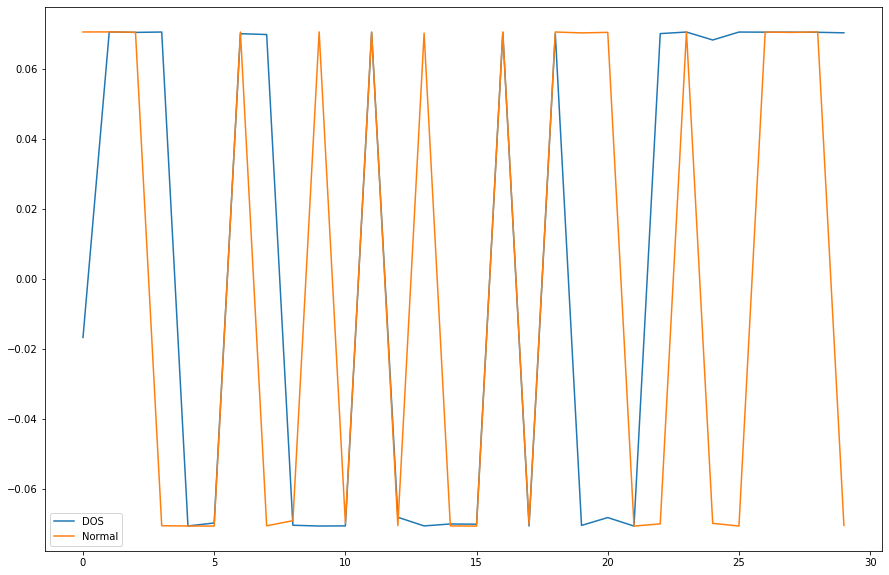

In [648]:
import matplotlib.pyplot as plt

limit = 30
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "DOS")
plt.plot(x_embeddings[2,0:limit],label = "Normal")
plt.legend()
plt.show()


## Graficas Training dataset

In [649]:
model.load_weights(save_best_weights)

In [650]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

In [651]:
def cosine_sim (a,ref):
    return( dot(a, ref)/(norm(a)*norm(ref)))

In [652]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[1,:]  #ref es el label embedding de normal
print("Normal to Dos",cosine_sim (label_embeddings[0,:],ref))
print("Normal to probe",cosine_sim (label_embeddings[2,:],ref))
print("Normal to R2L",cosine_sim (label_embeddings[3,:],ref))
print("Normal to U2R",cosine_sim (label_embeddings[4,:],ref))

Normal to Dos -0.40271419308103173
Normal to probe -0.5101134767325687
Normal to R2L -0.5352299619933268
Normal to U2R -0.8320680400864755


In [653]:
np.unique(YTrainAN5M)

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype=object)

In [654]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTrainM[YTrainAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTrainM[YTrainAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTrainM[YTrainAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTrainM[YTrainAN5M=='U2R']) # embeddings de las muestras u2r

In [655]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_dos = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_dos])
cos_sim_x_embeddings_probe = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_probe])
cos_sim_x_embeddings_R2L = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_R2L])
cos_sim_x_embeddings_U2R = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_U2R])

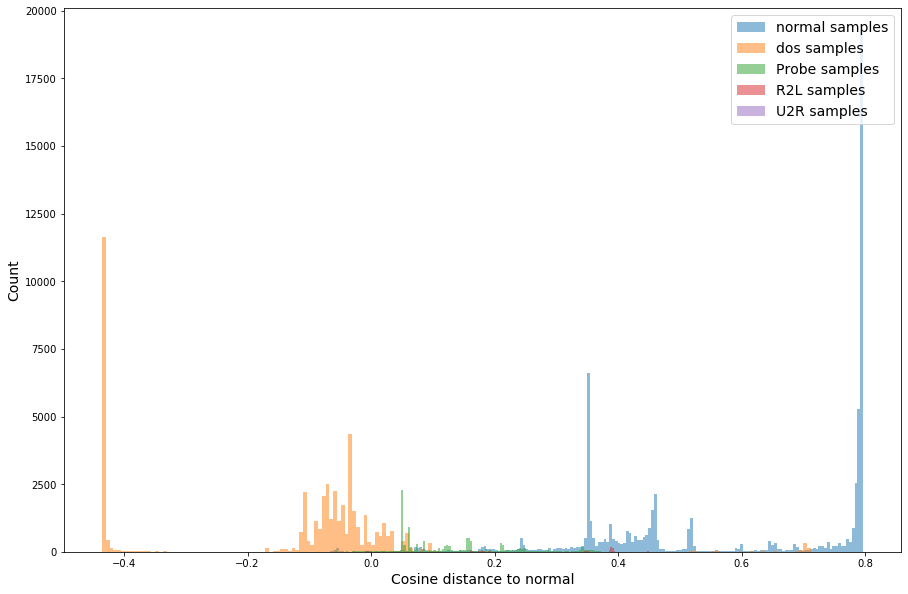

In [656]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_dos, bins=200, alpha=0.5, density=False, label="dos samples")
plt.hist(cos_sim_x_embeddings_probe, bins=200, alpha=0.5, density=False, label="Probe samples")
plt.hist(cos_sim_x_embeddings_R2L, bins=200, alpha=0.5, density=False, label="R2L samples")
plt.hist(cos_sim_x_embeddings_U2R, bins=200, alpha=0.5, density=False, label="U2R samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, training dataset

In [657]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTrainM[YTrainAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTrainM[YTrainAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTrainM[YTrainAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTrainM[YTrainAN5M=='U2R']) # embeddings de las muestras u2r

In [658]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_dos_mean = np.mean(x_embeddings_dos, axis=0)

No handles with labels found to put in legend.


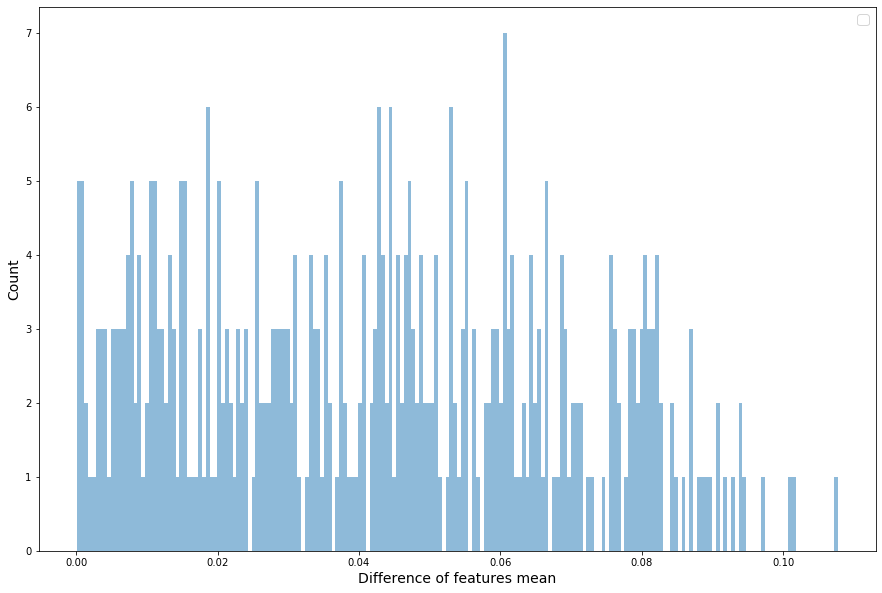

In [659]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [660]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

33.68624964179317 1.0035177611411882e-118


## Graficas Test dataset

In [661]:
model.load_weights(save_best_weights)

In [662]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

In [663]:
def cosine_sim (a,ref):
    return( dot(a, ref)/(norm(a)*norm(ref)))

In [664]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[1,:]  #ref es el label embedding de normal
print("Normal to Dos",cosine_sim (label_embeddings[0,:],ref))
print("Normal to probe",cosine_sim (label_embeddings[2,:],ref))
print("Normal to R2L",cosine_sim (label_embeddings[3,:],ref))
print("Normal to U2R",cosine_sim (label_embeddings[4,:],ref))

Normal to Dos -0.40271419308103173
Normal to probe -0.5101134767325687
Normal to R2L -0.5352299619933268
Normal to U2R -0.8320680400864755


In [665]:
np.unique(YTestAN5M)

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype=object)

In [666]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTestM[YTestAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTestM[YTestAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTestM[YTestAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTestM[YTestAN5M=='U2R']) # embeddings de las muestras u2r

In [667]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_dos = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_dos])
cos_sim_x_embeddings_probe = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_probe])
cos_sim_x_embeddings_R2L = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_R2L])
cos_sim_x_embeddings_U2R = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_U2R])

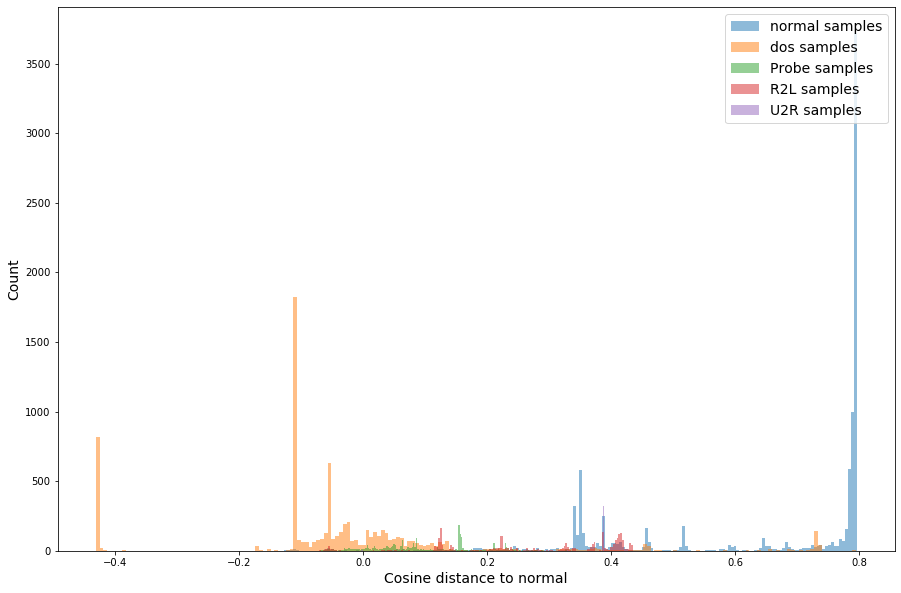

In [668]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_dos, bins=200, alpha=0.5, density=False, label="dos samples")
plt.hist(cos_sim_x_embeddings_probe, bins=200, alpha=0.5, density=False, label="Probe samples")
plt.hist(cos_sim_x_embeddings_R2L, bins=200, alpha=0.5, density=False, label="R2L samples")
plt.hist(cos_sim_x_embeddings_U2R, bins=200, alpha=0.5, density=False, label="U2R samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, test dataset

In [669]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTestM[YTestAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTestM[YTestAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTestM[YTestAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTestM[YTestAN5M=='U2R']) # embeddings de las muestras u2r

In [670]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_dos_mean = np.mean(x_embeddings_dos, axis=0)

No handles with labels found to put in legend.


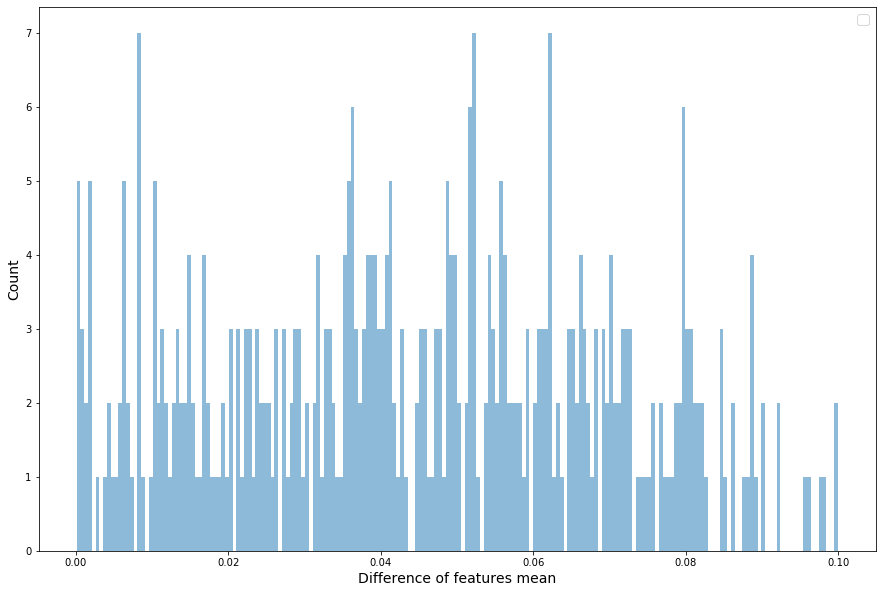

In [671]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [672]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

41.57589087654833 4.2453811618146804e-147


## logloss+contractive, 
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.01

In [673]:
x_train, x_test, label_train, label_test, y_train, y_test = XTrainM5_extended, XTestM5_extended, \
                                                            YTrainANMOhe5_extended, YTestANMOhe5_extended,\
                                                            YTrainOutput5, YTestOutput5
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape)


(629865, 122) (112720, 122) (629865, 5) (112720, 5) (629865,) (112720,)


In [674]:
pd.Series(label_train[:,1]).value_counts()

0    503892
1    125973
dtype: int64

In [675]:
# save the best weights for predicting the test question pairs
file_name = 'contracted CLC_5NSL_3 dim 10 v1.0 3'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
5
1


### Preparar modelo

In [676]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [677]:
def cosine_act(x):
    return tf.math.cos(x)

In [678]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [679]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [680]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [681]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [682]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [683]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [684]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [685]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.01

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [686]:
model.summary()

Model: "model_39"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_33 (InputLayer)           [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_34 (InputLayer)           [(None, 5)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_33[0][0]                   
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          2400        input_34[0][0]                   
___________________________________________________________________________________________

In [687]:
model_embed_x.summary()

Model: "model_40"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_33 (InputLayer)        [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [688]:
model_embed_label.summary()

Model: "model_41"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_34 (InputLayer)        [(None, 5)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               2400      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 2,400
Trainable params: 2,400
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [689]:
np.random.seed(247531338)
tf.random.set_seed(31722973)

In [690]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit([x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 503892 samples, validate on 125973 samples
Epoch 1/100
503892/503892 [==============================] - 29s 57us/sample - loss: 2890.1129 - accuracy: 0.8410 - val_loss: 2889.3769 - val_accuracy: 0.3946
Epoch 2/100
503892/503892 [==============================] - 27s 55us/sample - loss: 2888.6980 - accuracy: 0.8911 - val_loss: 2888.6340 - val_accuracy: 0.4157
Epoch 3/100
503892/503892 [==============================] - 28s 55us/sample - loss: 2888.1813 - accuracy: 0.8972 - val_loss: 2888.2912 - val_accuracy: 0.3885
Epoch 4/100
503892/503892 [==============================] - 27s 55us/sample - loss: 2887.9245 - accuracy: 0.9015 - val_loss: 2888.1120 - val_accuracy: 0.4115
Epoch 5/100
503892/503892 [==============================] - 28s 55us/sample - loss: 2887.7837 - accuracy: 0.9067 - val_loss: 2888.0071 - val_accuracy: 0.4035
Epoch 6/100
503892/503892 [==============================] - 28s 55us/sample - loss: 2887.6982 - accuracy: 0.9106 - val_loss: 2887.9391 - val_accuracy: 0

Epoch 52/100
503892/503892 [==============================] - 29s 57us/sample - loss: 2887.3662 - accuracy: 0.9168 - val_loss: 2887.6449 - val_accuracy: 0.3814
Epoch 53/100
503892/503892 [==============================] - 28s 56us/sample - loss: 2887.3661 - accuracy: 0.9164 - val_loss: 2887.6408 - val_accuracy: 0.3819
Epoch 54/100
503892/503892 [==============================] - 28s 56us/sample - loss: 2887.3659 - accuracy: 0.9168 - val_loss: 2887.6449 - val_accuracy: 0.3799
Epoch 55/100
503892/503892 [==============================] - 28s 56us/sample - loss: 2887.3657 - accuracy: 0.9166 - val_loss: 2887.6462 - val_accuracy: 0.3784
Epoch 56/100
503892/503892 [==============================] - 28s 56us/sample - loss: 2887.3655 - accuracy: 0.9166 - val_loss: 2887.6447 - val_accuracy: 0.3725
Epoch 57/100
503892/503892 [==============================] - 29s 58us/sample - loss: 2887.3653 - accuracy: 0.9168 - val_loss: 2887.6391 - val_accuracy: 0.3787
Epoch 58/100
503892/503892 [============

In [691]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [692]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

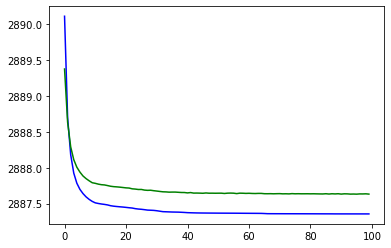

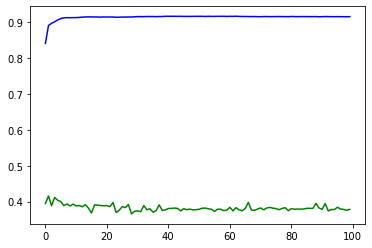

Minimum val_loss at epoch 96 = 2887.6313


In [693]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Prediccion

In [694]:
model.load_weights(save_best_weights)

### prediccion sobre el conjunto de test y fake para deteccion de aciertos (deteccion binaria)

In [748]:
t0 = time.time()

ytest_prob_hat_binary = model.predict([x_test,label_test])

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.091023


In [696]:
pd.Series(ytest_prob_hat_binary.flatten()).describe()

count    112720.000000
mean          0.443603
std           0.195885
min           0.060691
25%           0.420123
50%           0.484632
75%           0.525365
max           0.897585
dtype: float64

In [697]:
#ytest_prob_hat_binary = (ytest_prob_hat_binary-min(ytest_prob_hat_binary))/(max(ytest_prob_hat_binary)-min(ytest_prob_hat_binary)) # escalamos 0-1

In [698]:
#pd.Series(ytest_prob_hat_binary.flatten()).describe()

In [699]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat_binary > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(112720,)
0.40486160397445
0.2


In [700]:
threshold = 0.7
ytest_hat = ((ytest_prob_hat_binary > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat_binary)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat_binary)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8621007806955288
F1 =  0.48461538461538467
Precision_score =  0.9595588235294118
recall_score =  0.32416607523066004
roc_auc_score =  0.87568006548884
pr_auc =  0.7488243166355485
matthews_corr_score =  0.5111581236244367


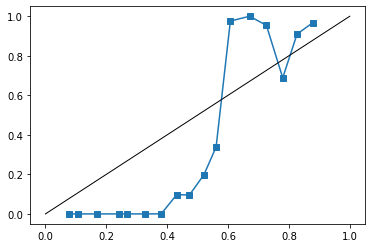

In [701]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat_binary, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

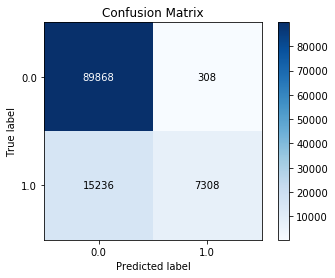

In [702]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

### prediccion real sobre el conjunto de test para predecir la clase en concreto

In [703]:
lb5.inverse_transform(labelOHEncodedFromPrediction([[0.8,0.7,0,0,0],[0,0.6,0,0,0],[0,0,1,0,0],[0,0,0,1,0],[0,0,0,0,1]]))

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype='<U6')

In [704]:
lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'])

array([[1, 0, 0, 0, 0],
       [0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 0, 0, 1]])

In [705]:
t0 = time.time()

total_label_test =[np.tile(lb5.transform([i]),(len(YTestAN5MOhe),1)) for i in ['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']]
ytest_prob_hat = np.column_stack([model.predict([XTestM,i]) for i in total_label_test])
ytest_prob_hat.shape

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.089464


In [706]:
ytest_prob_hat

array([[0.60555743, 0.45038594, 0.4501143 , 0.45428991, 0.50189525],
       [0.60552046, 0.45031989, 0.45018275, 0.45430037, 0.50192667],
       [0.4874637 , 0.53091945, 0.47146652, 0.45047585, 0.44782028],
       ...,
       [0.55709499, 0.86945006, 0.10247834, 0.09867421, 0.06729178],
       [0.47889061, 0.66272496, 0.37515966, 0.38255169, 0.34011201],
       [0.49486232, 0.52882794, 0.48234403, 0.48121946, 0.475078  ]])

In [707]:
y_test_hat = lb5.inverse_transform(labelOHEncodedFromPrediction(ytest_prob_hat))
y_test_hat

array(['DOS', 'DOS', 'NORMAL', ..., 'NORMAL', 'NORMAL', 'NORMAL'],
      dtype='<U6')

In [708]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef


average_type = 'weighted' # micro' , 'weighted'
print('Performance measures on Test data')
print('Accuracy =  {}'.format(accuracy_score( lb5.inverse_transform(YTestAN5MOhe),y_test_hat)))

print('F1 =  {}'.format(f1_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('Precision_score =  {}'.format(precision_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('recall_score =  {}'.format(recall_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('roc_auc_score =  {}'.format(roc_auc_score(YTestAN5MOhe,normalize(ytest_prob_hat, axis=1, norm='l1'))))

print('matthews_corr_score =  {}'.format(matthews_corrcoef(lb5.inverse_transform(YTestAN5MOhe), y_test_hat)))

Performance measures on Test data
Accuracy =  0.683374733853797
F1 =  0.6508425737606934
Precision_score =  0.6464586259906284
recall_score =  0.683374733853797
roc_auc_score =  0.725663459631329
matthews_corr_score =  0.5263213017242926


In [709]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef

average_type = 'micro' # micro' , 'weighted'
print('Performance measures on Test data')
print('Accuracy =  {}'.format(accuracy_score( lb5.inverse_transform(YTestAN5MOhe),y_test_hat)))

print('F1 =  {}'.format(f1_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('Precision_score =  {}'.format(precision_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('recall_score =  {}'.format(recall_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('roc_auc_score =  {}'.format(roc_auc_score(YTestAN5MOhe,normalize(ytest_prob_hat, axis=1, norm='l1'))))

print('matthews_corr_score =  {}'.format(matthews_corrcoef(lb5.inverse_transform(YTestAN5MOhe), y_test_hat)))

Performance measures on Test data
Accuracy =  0.683374733853797
F1 =  0.683374733853797
Precision_score =  0.683374733853797
recall_score =  0.683374733853797
roc_auc_score =  0.725663459631329
matthews_corr_score =  0.5263213017242926


### Perform test evaluation one vs. rest

Percentage per label class

In [710]:
(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts()/pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts().sum())*100

NORMAL    43.075763
DOS       33.081973
R2L       11.328957
PROBE     10.738999
U2R        1.774308
dtype: float64

In [711]:
(pd.Series(y_test_hat).value_counts()/pd.Series(y_test_hat).value_counts().sum())*100

NORMAL    55.908446
DOS       27.546132
PROBE     12.380234
R2L        2.546132
U2R        1.619056
dtype: float64

In [712]:
yt_app = lb5.inverse_transform(YTestAN5MOhe)
perf_per_class = pd.DataFrame(index=range(len(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).unique())),columns=['name', 'acc','f1', 'pre','rec'])
for i,x in enumerate(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts().index):
    y_test_hat_check = y_test_hat.copy()
    y_test_hat_check[y_test_hat_check != x] = 'OTHER'
    yt_app = lb5.inverse_transform(YTestAN5MOhe).copy()
    yt_app[yt_app != x] = 'OTHER'
    ac=accuracy_score( yt_app,y_test_hat_check)
    f1=f1_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    pr=precision_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    re=recall_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    perf_per_class.iloc[i]=[x,ac,f1,pr,re]

In [713]:
# performance measures per class for test data
perf_per_class

,name,acc,f1,pre,rec
0,NORMAL,0.8298,0.828053,0.733021,0.951395
1,DOS,0.841199,0.738074,0.812238,0.676321
2,R2L,0.871718,0.0754476,0.205575,0.046202
3,PROBE,0.857612,0.384114,0.358653,0.413466
4,U2R,0.966421,0.0104575,0.0109589,0.01


###  Visualizar embeddings

In [714]:
model.load_weights(save_best_weights)

In [715]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

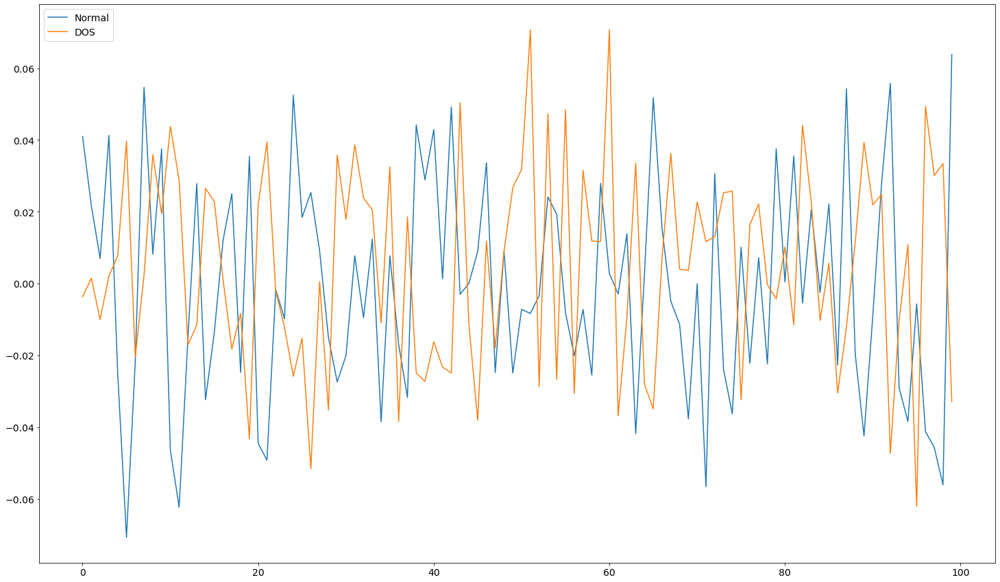

In [716]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[0,0:limit],label = "DOS")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

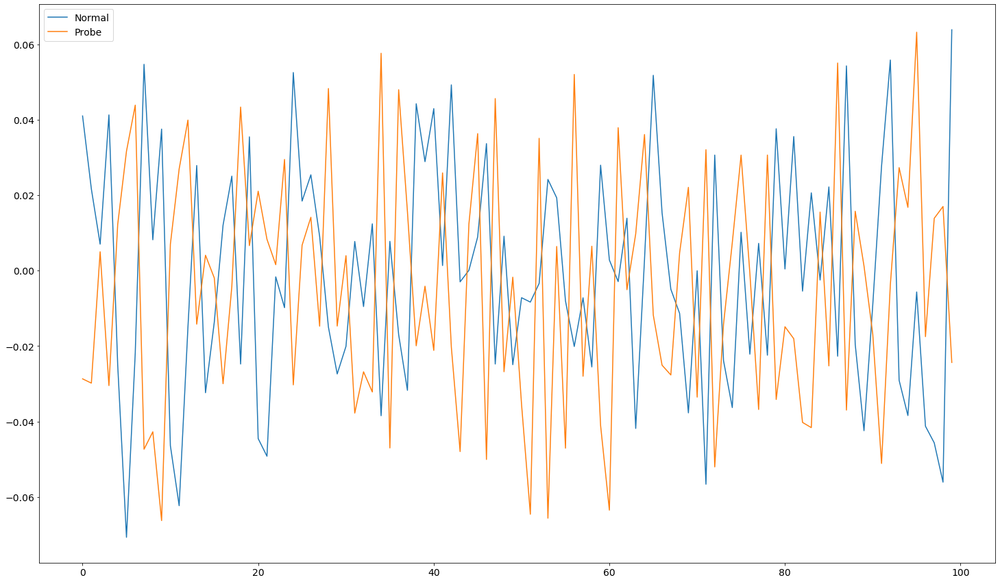

In [717]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[2,0:limit],label = "Probe")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

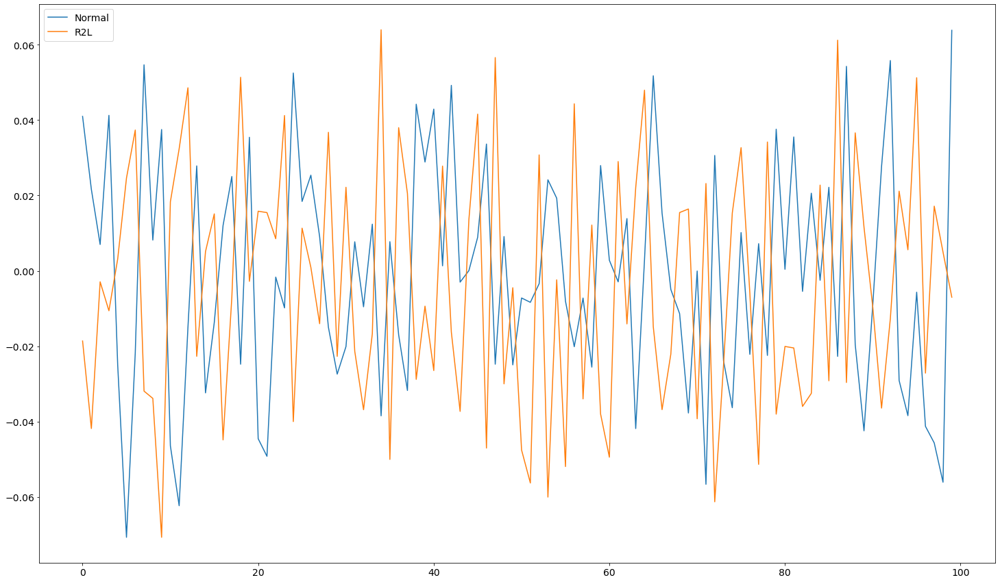

In [718]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[3,0:limit],label = "R2L")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

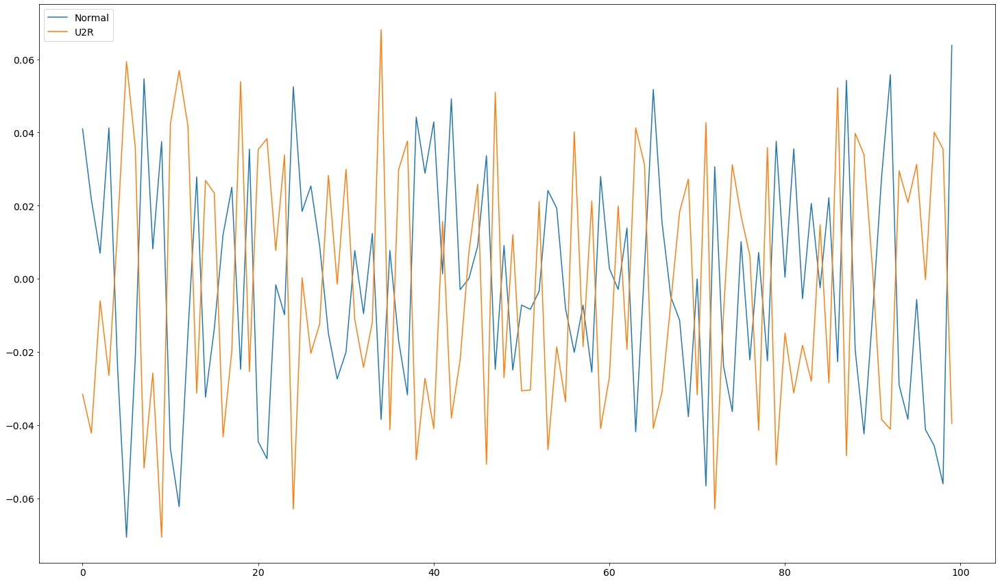

In [719]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[4,0:limit],label = "U2R")
plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

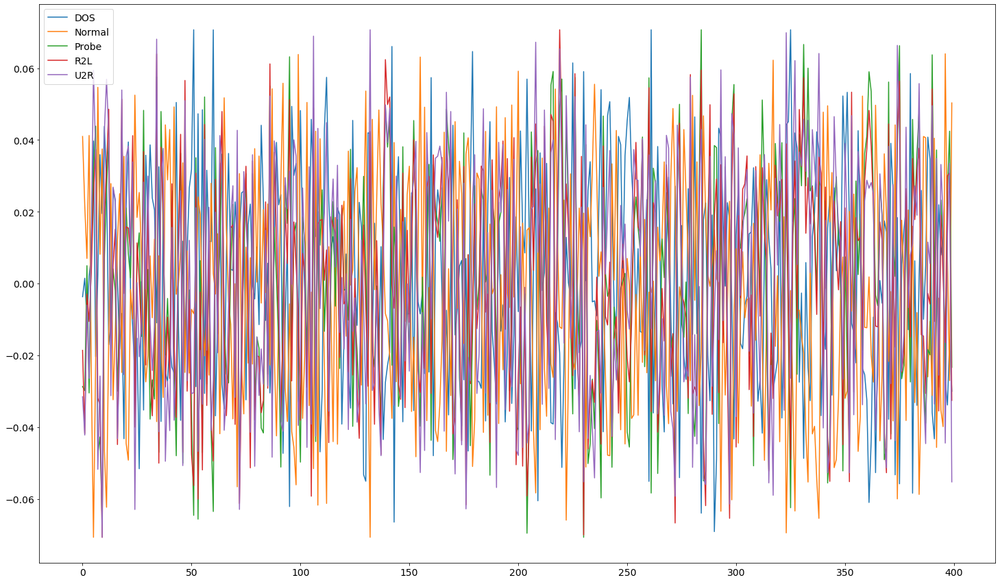

In [720]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[0,0:limit],label = "DOS")
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[2,0:limit],label = "Probe")
plt.plot(label_embeddings[3,0:limit],label = "R2L")
plt.plot(label_embeddings[4,0:limit],label = "U2R")
plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

In [721]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(629865, 400)

In [722]:
YTestAN5M

array(['DOS', 'DOS', 'NORMAL', ..., 'DOS', 'NORMAL', 'PROBE'],
      dtype=object)

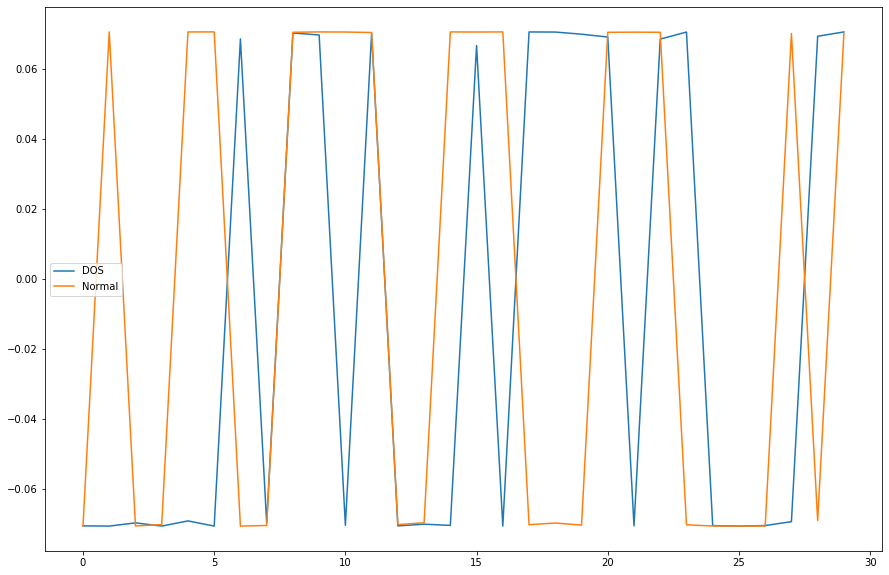

In [723]:
import matplotlib.pyplot as plt

limit = 30
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "DOS")
plt.plot(x_embeddings[2,0:limit],label = "Normal")
plt.legend()
plt.show()


## Graficas Training dataset

In [724]:
model.load_weights(save_best_weights)

In [725]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

In [726]:
def cosine_sim (a,ref):
    return( dot(a, ref)/(norm(a)*norm(ref)))

In [727]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[1,:]  #ref es el label embedding de normal
print("Normal to Dos",cosine_sim (label_embeddings[0,:],ref))
print("Normal to probe",cosine_sim (label_embeddings[2,:],ref))
print("Normal to R2L",cosine_sim (label_embeddings[3,:],ref))
print("Normal to U2R",cosine_sim (label_embeddings[4,:],ref))

Normal to Dos -0.40033255038843035
Normal to probe -0.5224364963913821
Normal to R2L -0.5211416597124188
Normal to U2R -0.845135678080007


In [728]:
np.unique(YTrainAN5M)

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype=object)

In [729]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTrainM[YTrainAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTrainM[YTrainAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTrainM[YTrainAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTrainM[YTrainAN5M=='U2R']) # embeddings de las muestras u2r

In [730]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_dos = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_dos])
cos_sim_x_embeddings_probe = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_probe])
cos_sim_x_embeddings_R2L = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_R2L])
cos_sim_x_embeddings_U2R = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_U2R])

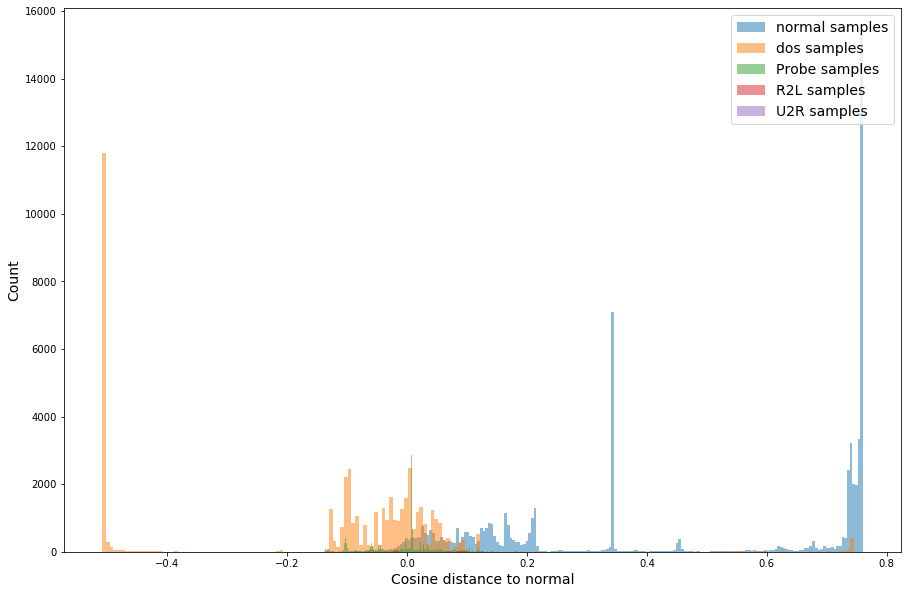

In [731]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_dos, bins=200, alpha=0.5, density=False, label="dos samples")
plt.hist(cos_sim_x_embeddings_probe, bins=200, alpha=0.5, density=False, label="Probe samples")
plt.hist(cos_sim_x_embeddings_R2L, bins=200, alpha=0.5, density=False, label="R2L samples")
plt.hist(cos_sim_x_embeddings_U2R, bins=200, alpha=0.5, density=False, label="U2R samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, training dataset

In [732]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTrainM[YTrainAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTrainM[YTrainAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTrainM[YTrainAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTrainM[YTrainAN5M=='U2R']) # embeddings de las muestras u2r

In [733]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_dos_mean = np.mean(x_embeddings_dos, axis=0)

No handles with labels found to put in legend.


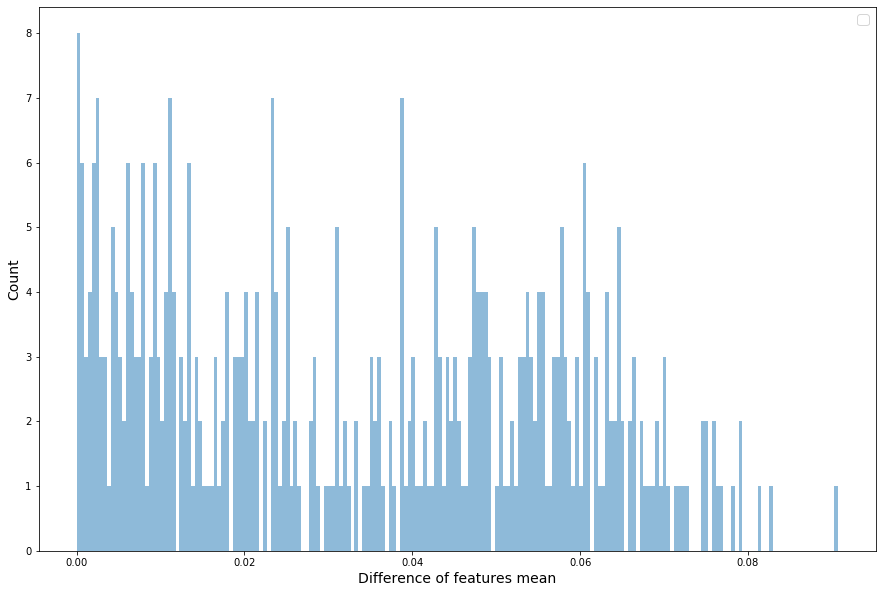

In [734]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [735]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

31.766115014106106 2.60418659566137e-111


## Graficas Test dataset

In [736]:
model.load_weights(save_best_weights)

In [737]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

In [738]:
def cosine_sim (a,ref):
    return( dot(a, ref)/(norm(a)*norm(ref)))

In [739]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[1,:]  #ref es el label embedding de normal
print("Normal to Dos",cosine_sim (label_embeddings[0,:],ref))
print("Normal to probe",cosine_sim (label_embeddings[2,:],ref))
print("Normal to R2L",cosine_sim (label_embeddings[3,:],ref))
print("Normal to U2R",cosine_sim (label_embeddings[4,:],ref))

Normal to Dos -0.40033255038843035
Normal to probe -0.5224364963913821
Normal to R2L -0.5211416597124188
Normal to U2R -0.845135678080007


In [740]:
np.unique(YTestAN5M)

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype=object)

In [741]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTestM[YTestAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTestM[YTestAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTestM[YTestAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTestM[YTestAN5M=='U2R']) # embeddings de las muestras u2r

In [742]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_dos = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_dos])
cos_sim_x_embeddings_probe = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_probe])
cos_sim_x_embeddings_R2L = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_R2L])
cos_sim_x_embeddings_U2R = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_U2R])

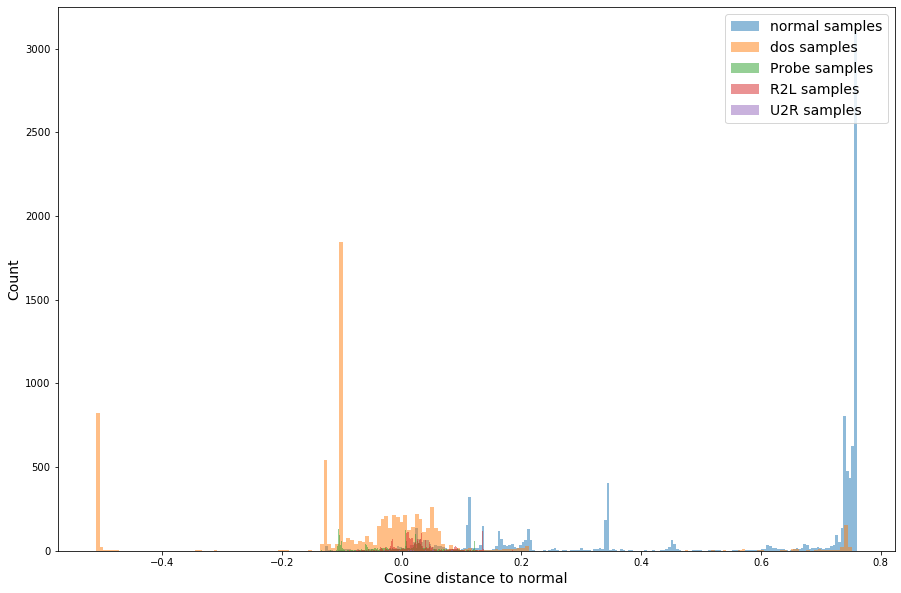

In [743]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_dos, bins=200, alpha=0.5, density=False, label="dos samples")
plt.hist(cos_sim_x_embeddings_probe, bins=200, alpha=0.5, density=False, label="Probe samples")
plt.hist(cos_sim_x_embeddings_R2L, bins=200, alpha=0.5, density=False, label="R2L samples")
plt.hist(cos_sim_x_embeddings_U2R, bins=200, alpha=0.5, density=False, label="U2R samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, test dataset

In [744]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTestM[YTestAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTestM[YTestAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTestM[YTestAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTestM[YTestAN5M=='U2R']) # embeddings de las muestras u2r

In [745]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_dos_mean = np.mean(x_embeddings_dos, axis=0)

No handles with labels found to put in legend.


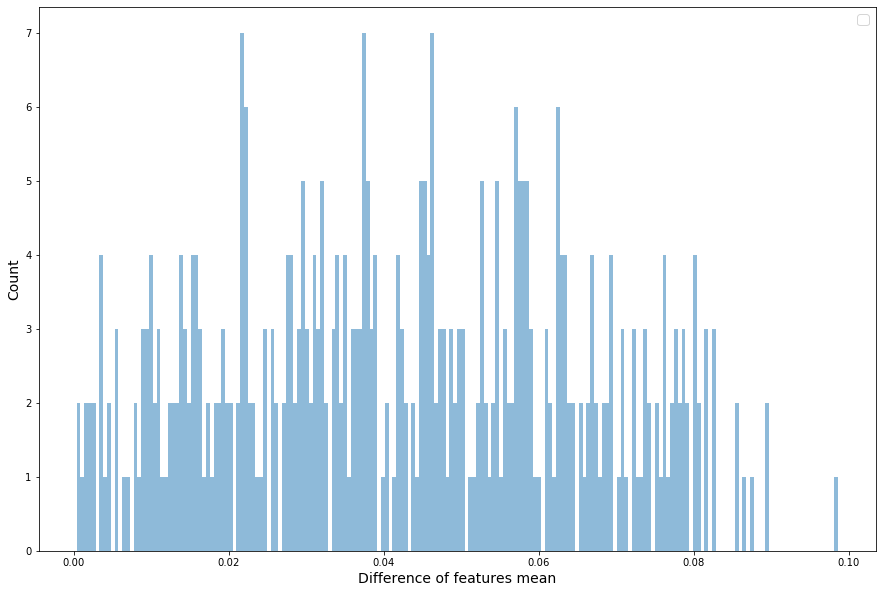

In [746]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [747]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_anomaly_mean), 0) 
print (stat, pvalue)

39.89940542714028 2.4014938462625845e-141


## logloss+contractive, 
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.1

In [77]:
x_train, x_test, label_train, label_test, y_train, y_test = XTrainM5_extended, XTestM5_extended, \
                                                            YTrainANMOhe5_extended, YTestANMOhe5_extended,\
                                                            YTrainOutput5, YTestOutput5
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape)


(629865, 122) (112720, 122) (629865, 5) (112720, 5) (629865,) (112720,)


In [78]:
pd.Series(label_train[:,1]).value_counts()

0    503892
1    125973
dtype: int64

In [79]:
# save the best weights for predicting the test question pairs
file_name = 'contracted CLC_5NSL_3 dim 10 v1.0 4'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
5
1


### Preparar modelo

In [80]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [81]:
def cosine_act(x):
    return tf.math.cos(x)

In [82]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [83]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [84]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [85]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [86]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [87]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    #W = model.get_layer('contracted_layer').get_weights()[0]  # N x N_hidden
    W = K.variable(value=model.get_layer('layer_x').get_weights()[0])  # N x N_hidden
    W = K.transpose(W)  # N_hidden x N
    h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(h_cos)  # N_batch x N_hidden, por ser cosine

    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W**2, axis=1), axis=1))

    return (logloss + contractive_loss)



In [88]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [89]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
alpha_val = 0.1

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

Instructions for updating:
If using Keras pass *_constraint arguments to layers.


In [90]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_2 (InputLayer)            [(None, 5)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_1[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          2400        input_2[0][0]                    
______________________________________________________________________________________________

In [91]:
model_embed_x.summary()

Model: "model_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [92]:
model_embed_label.summary()

Model: "model_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 5)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               2400      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 2,400
Trainable params: 2,400
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [93]:
np.random.seed(247531338)
tf.random.set_seed(31722973)

In [94]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit([x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 503892 samples, validate on 125973 samples
Epoch 1/100
503892/503892 [==============================] - 27s 53us/sample - loss: 29377.3053 - accuracy: 0.8366 - val_loss: 29367.4581 - val_accuracy: 0.4822
Epoch 2/100
503892/503892 [==============================] - 23s 46us/sample - loss: 29363.0046 - accuracy: 0.8847 - val_loss: 29360.0709 - val_accuracy: 0.4813
Epoch 3/100
503892/503892 [==============================] - 23s 46us/sample - loss: 29357.8521 - accuracy: 0.8921 - val_loss: 29356.6325 - val_accuracy: 0.4873
Epoch 4/100
503892/503892 [==============================] - 22s 44us/sample - loss: 29355.3534 - accuracy: 0.8972 - val_loss: 29354.7511 - val_accuracy: 0.4781
Epoch 5/100
503892/503892 [==============================] - 22s 43us/sample - loss: 29353.8660 - accuracy: 0.8993 - val_loss: 29353.6443 - val_accuracy: 0.4758
Epoch 6/100
503892/503892 [==============================] - 22s 43us/sample - loss: 29352.9896 - accuracy: 0.8997 - val_loss: 29352.9549 - val

In [95]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [96]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

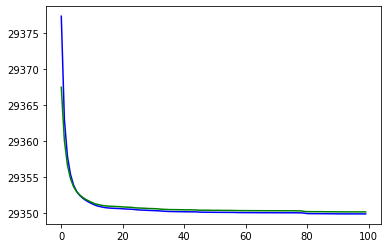

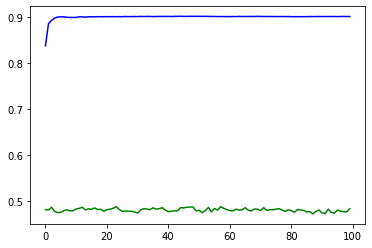

Minimum val_loss at epoch 100 = 29350.1482


In [97]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Prediccion

In [98]:
model.load_weights(save_best_weights)

### prediccion sobre el conjunto de test y fake para deteccion de aciertos (deteccion binaria)

In [99]:
t0 = time.time()

ytest_prob_hat_binary = model.predict([x_test,label_test])

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.102796


In [100]:
pd.Series(ytest_prob_hat_binary.flatten()).describe()

count    112720.000000
mean          0.444009
std           0.195848
min           0.061213
25%           0.409945
50%           0.478993
75%           0.522112
max           0.899919
dtype: float64

In [101]:
#ytest_prob_hat_binary = (ytest_prob_hat_binary-min(ytest_prob_hat_binary))/(max(ytest_prob_hat_binary)-min(ytest_prob_hat_binary)) # escalamos 0-1

In [102]:
#pd.Series(ytest_prob_hat_binary.flatten()).describe()

In [103]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat_binary > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(112720,)
0.36618168914123495
0.2


In [104]:
threshold = 0.7
ytest_hat = ((ytest_prob_hat_binary > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat_binary)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat_binary)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.8620031937544358
F1 =  0.48402826151855904
Precision_score =  0.9596212021570433
recall_score =  0.32363378282469835
roc_auc_score =  0.8561636827167035
pr_auc =  0.7231586215536283
matthews_corr_score =  0.5107320394629979


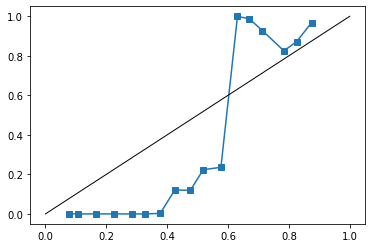

In [105]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat_binary, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

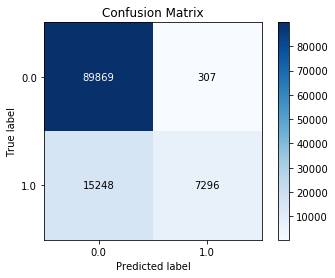

In [106]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

### prediccion real sobre el conjunto de test para predecir la clase en concreto

In [113]:
from sklearn.preprocessing import normalize
lb5.inverse_transform(labelOHEncodedFromPrediction([[0.8,0.7,0,0,0],[0,0.6,0,0,0],[0,0,1,0,0],[0,0,0,1,0],[0,0,0,0,1]]))

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype='<U6')

In [108]:
lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'])

array([[1, 0, 0, 0, 0],
       [0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 0, 0, 1]])

In [109]:
t0 = time.time()

total_label_test =[np.tile(lb5.transform([i]),(len(YTestAN5MOhe),1)) for i in ['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']]
ytest_prob_hat = np.column_stack([model.predict([XTestM,i]) for i in total_label_test])
ytest_prob_hat.shape

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.084300


In [110]:
ytest_prob_hat

array([[0.62609285, 0.46467345, 0.40916463, 0.41001854, 0.45706746],
       [0.62626147, 0.46458354, 0.40907132, 0.40993558, 0.45706183],
       [0.52674756, 0.53220388, 0.44257387, 0.44549205, 0.44517956],
       ...,
       [0.58123096, 0.86814808, 0.09808995, 0.1033559 , 0.06575507],
       [0.46949473, 0.64765056, 0.40066573, 0.39810019, 0.36595992],
       [0.51266126, 0.5022023 , 0.48649293, 0.49039211, 0.49223357]])

In [111]:
y_test_hat = lb5.inverse_transform(labelOHEncodedFromPrediction(ytest_prob_hat))
y_test_hat

array(['DOS', 'DOS', 'NORMAL', ..., 'NORMAL', 'NORMAL', 'DOS'],
      dtype='<U6')

In [114]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef


average_type = 'weighted' # micro' , 'weighted'
print('Performance measures on Test data')
print('Accuracy =  {}'.format(accuracy_score( lb5.inverse_transform(YTestAN5MOhe),y_test_hat)))

print('F1 =  {}'.format(f1_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('Precision_score =  {}'.format(precision_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('recall_score =  {}'.format(recall_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('roc_auc_score =  {}'.format(roc_auc_score(YTestAN5MOhe,normalize(ytest_prob_hat, axis=1, norm='l1'))))

print('matthews_corr_score =  {}'.format(matthews_corrcoef(lb5.inverse_transform(YTestAN5MOhe), y_test_hat)))

Performance measures on Test data
Accuracy =  0.6762331440738112
F1 =  0.6483972228635522
Precision_score =  0.6764238964311989
recall_score =  0.6762331440738112
roc_auc_score =  0.7073041637649687
matthews_corr_score =  0.5207842990577141


In [115]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef

average_type = 'micro' # micro' , 'weighted'
print('Performance measures on Test data')
print('Accuracy =  {}'.format(accuracy_score( lb5.inverse_transform(YTestAN5MOhe),y_test_hat)))

print('F1 =  {}'.format(f1_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('Precision_score =  {}'.format(precision_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('recall_score =  {}'.format(recall_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('roc_auc_score =  {}'.format(roc_auc_score(YTestAN5MOhe,normalize(ytest_prob_hat, axis=1, norm='l1'))))

print('matthews_corr_score =  {}'.format(matthews_corrcoef(lb5.inverse_transform(YTestAN5MOhe), y_test_hat)))

Performance measures on Test data
Accuracy =  0.6762331440738112
F1 =  0.6762331440738112
Precision_score =  0.6762331440738112
recall_score =  0.6762331440738112
roc_auc_score =  0.7073041637649687
matthews_corr_score =  0.5207842990577141


### Perform test evaluation one vs. rest

Percentage per label class

In [116]:
(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts()/pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts().sum())*100

NORMAL    43.075763
DOS       33.081973
R2L       11.328957
PROBE     10.738999
U2R        1.774308
dtype: float64

In [117]:
(pd.Series(y_test_hat).value_counts()/pd.Series(y_test_hat).value_counts().sum())*100

NORMAL    56.014904
DOS       25.483499
PROBE     14.726757
U2R        1.960610
R2L        1.814230
dtype: float64

In [118]:
yt_app = lb5.inverse_transform(YTestAN5MOhe)
perf_per_class = pd.DataFrame(index=range(len(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).unique())),columns=['name', 'acc','f1', 'pre','rec'])
for i,x in enumerate(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts().index):
    y_test_hat_check = y_test_hat.copy()
    y_test_hat_check[y_test_hat_check != x] = 'OTHER'
    yt_app = lb5.inverse_transform(YTestAN5MOhe).copy()
    yt_app[yt_app != x] = 'OTHER'
    ac=accuracy_score( yt_app,y_test_hat_check)
    f1=f1_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    pr=precision_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    re=recall_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    perf_per_class.iloc[i]=[x,ac,f1,pr,re]

In [119]:
# performance measures per class for test data
perf_per_class

,name,acc,f1,pre,rec
0,NORMAL,0.82634,0.824746,0.72949,0.948615
1,DOS,0.83113,0.711656,0.817755,0.629928
2,R2L,0.886134,0.133648,0.484108,0.0775255
3,PROBE,0.845768,0.394356,0.340964,0.467575
4,U2R,0.963094,0.0118765,0.0113122,0.0125


###  Visualizar embeddings

In [120]:
model.load_weights(save_best_weights)

In [121]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

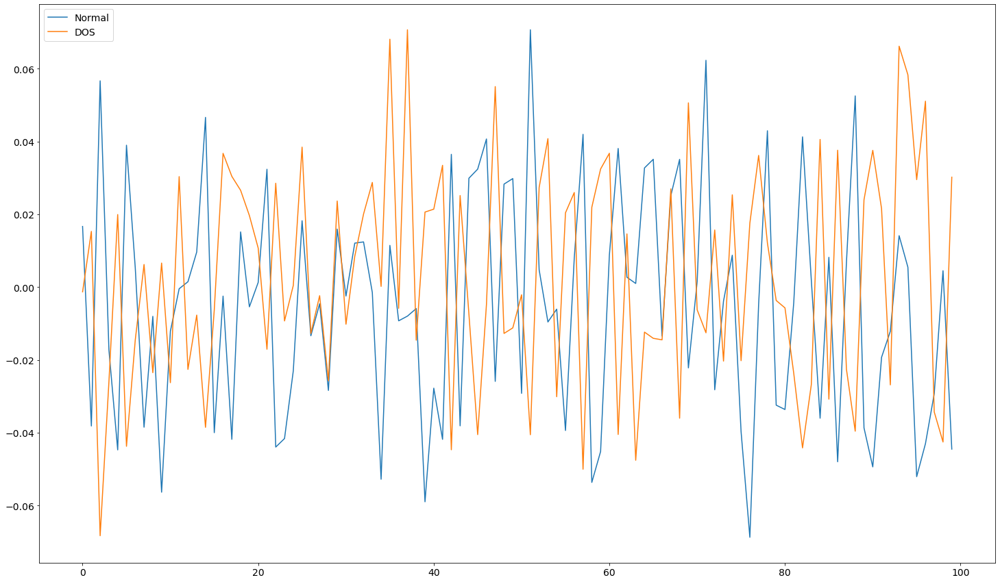

In [122]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[0,0:limit],label = "DOS")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

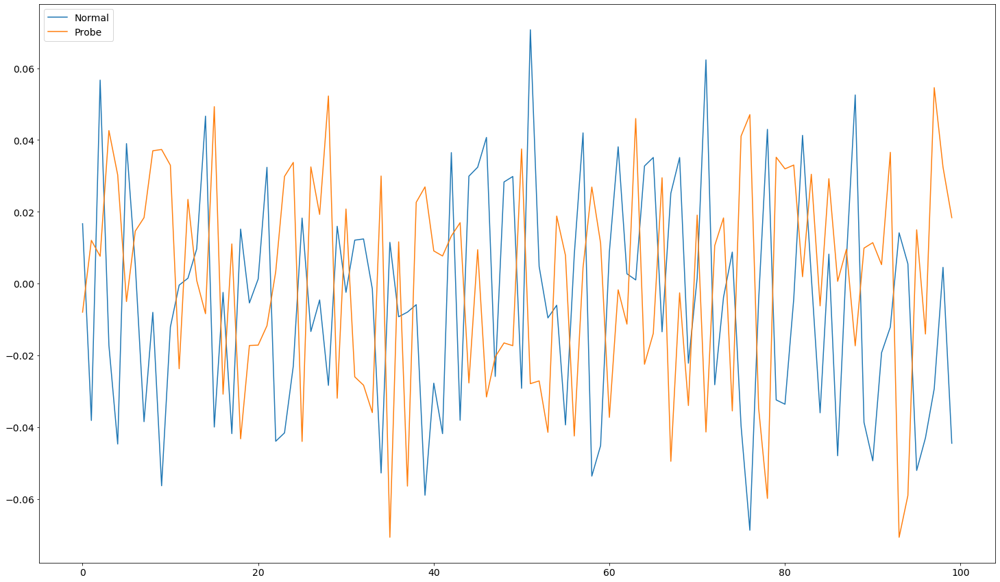

In [123]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[2,0:limit],label = "Probe")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

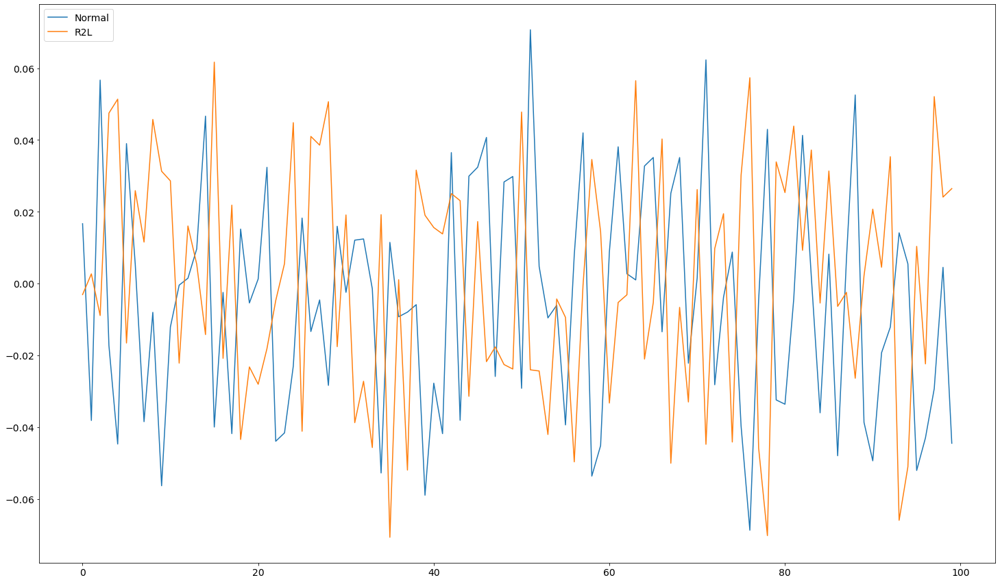

In [124]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[3,0:limit],label = "R2L")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

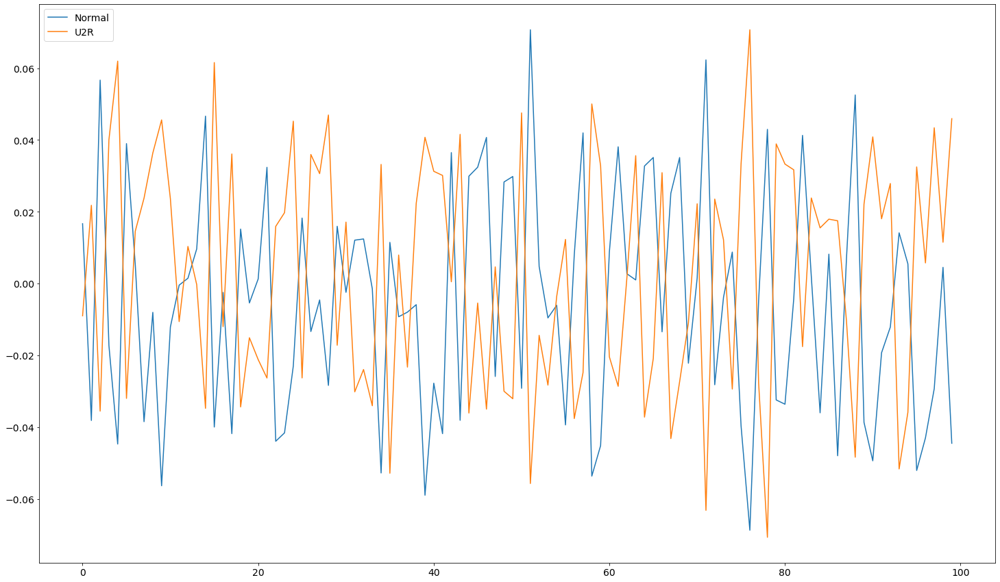

In [125]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[4,0:limit],label = "U2R")
plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

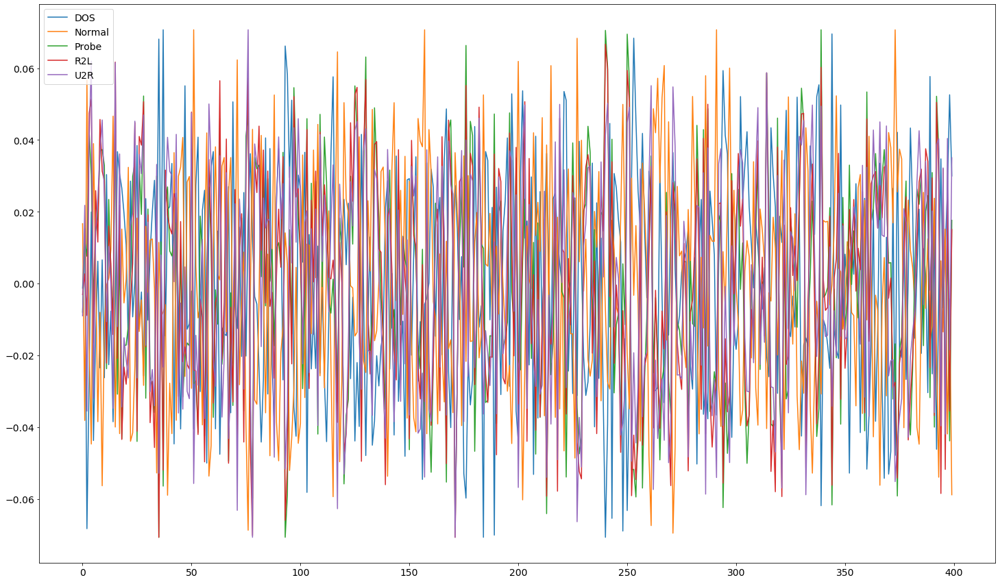

In [126]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[0,0:limit],label = "DOS")
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[2,0:limit],label = "Probe")
plt.plot(label_embeddings[3,0:limit],label = "R2L")
plt.plot(label_embeddings[4,0:limit],label = "U2R")
plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

In [127]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(629865, 400)

In [128]:
YTestAN5M

array(['DOS', 'DOS', 'NORMAL', ..., 'DOS', 'NORMAL', 'PROBE'],
      dtype=object)

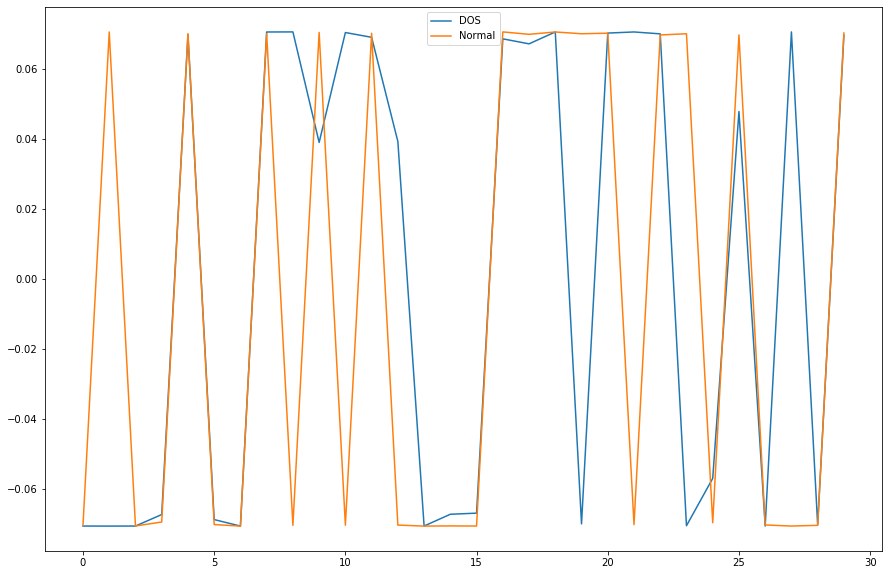

In [129]:
import matplotlib.pyplot as plt

limit = 30
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "DOS")
plt.plot(x_embeddings[2,0:limit],label = "Normal")
plt.legend()
plt.show()


## Graficas Training dataset

In [130]:
model.load_weights(save_best_weights)

In [131]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

In [132]:
def cosine_sim (a,ref):
    return( dot(a, ref)/(norm(a)*norm(ref)))

In [133]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[1,:]  #ref es el label embedding de normal
print("Normal to Dos",cosine_sim (label_embeddings[0,:],ref))
print("Normal to probe",cosine_sim (label_embeddings[2,:],ref))
print("Normal to R2L",cosine_sim (label_embeddings[3,:],ref))
print("Normal to U2R",cosine_sim (label_embeddings[4,:],ref))

Normal to Dos -0.35580985200009707
Normal to probe -0.5325382593543321
Normal to R2L -0.526822503430403
Normal to U2R -0.8361229473801268


In [134]:
np.unique(YTrainAN5M)

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype=object)

In [135]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTrainM[YTrainAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTrainM[YTrainAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTrainM[YTrainAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTrainM[YTrainAN5M=='U2R']) # embeddings de las muestras u2r

In [136]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_dos = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_dos])
cos_sim_x_embeddings_probe = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_probe])
cos_sim_x_embeddings_R2L = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_R2L])
cos_sim_x_embeddings_U2R = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_U2R])

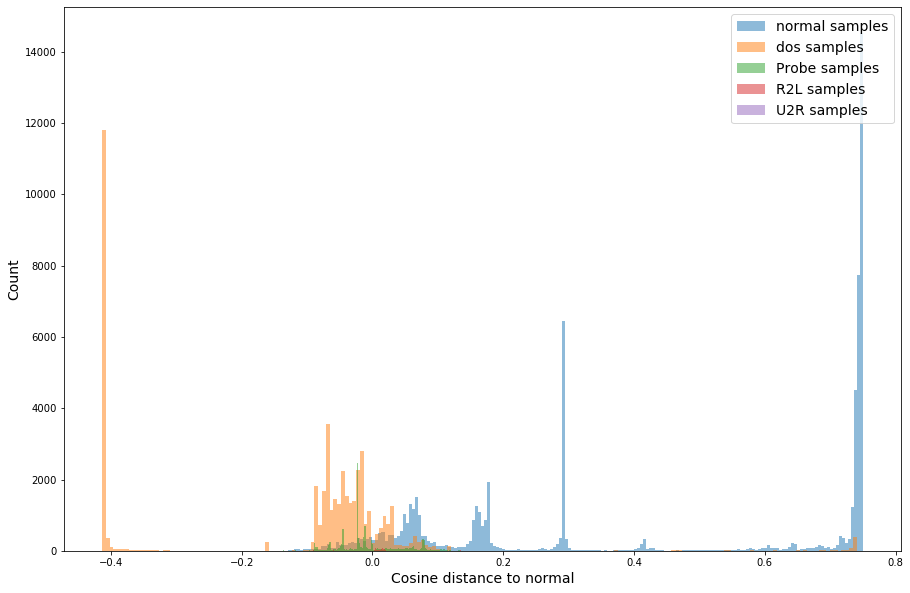

In [137]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_dos, bins=200, alpha=0.5, density=False, label="dos samples")
plt.hist(cos_sim_x_embeddings_probe, bins=200, alpha=0.5, density=False, label="Probe samples")
plt.hist(cos_sim_x_embeddings_R2L, bins=200, alpha=0.5, density=False, label="R2L samples")
plt.hist(cos_sim_x_embeddings_U2R, bins=200, alpha=0.5, density=False, label="U2R samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, training dataset

In [138]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTrainM[YTrainAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTrainM[YTrainAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTrainM[YTrainAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTrainM[YTrainAN5M=='U2R']) # embeddings de las muestras u2r

In [139]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_dos_mean = np.mean(x_embeddings_dos, axis=0)

No handles with labels found to put in legend.


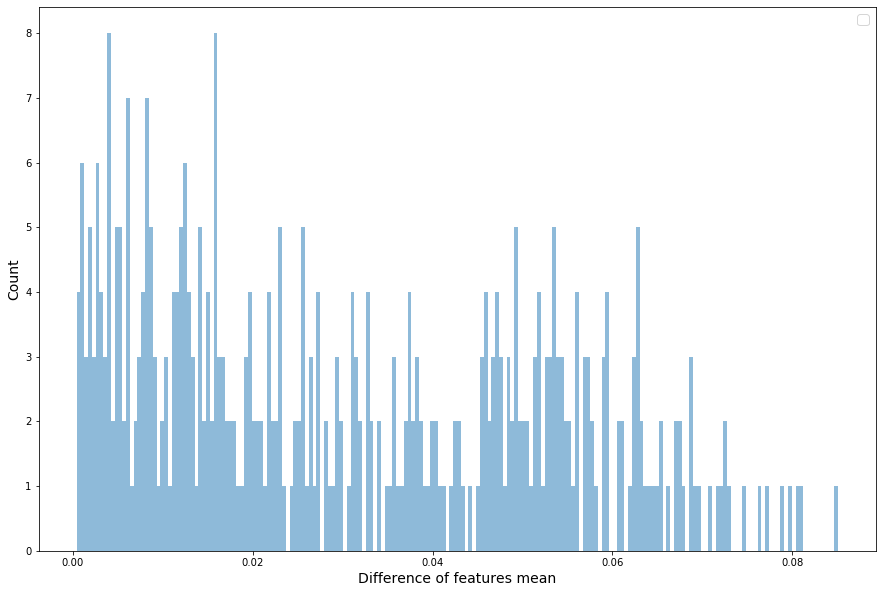

In [140]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [142]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), 0) 
print (stat, pvalue)

28.15266330849628 7.892976920839595e-97


## Graficas Test dataset

In [143]:
model.load_weights(save_best_weights)

In [144]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

In [145]:
def cosine_sim (a,ref):
    return( dot(a, ref)/(norm(a)*norm(ref)))

In [146]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[1,:]  #ref es el label embedding de normal
print("Normal to Dos",cosine_sim (label_embeddings[0,:],ref))
print("Normal to probe",cosine_sim (label_embeddings[2,:],ref))
print("Normal to R2L",cosine_sim (label_embeddings[3,:],ref))
print("Normal to U2R",cosine_sim (label_embeddings[4,:],ref))

Normal to Dos -0.35580985200009707
Normal to probe -0.5325382593543321
Normal to R2L -0.526822503430403
Normal to U2R -0.8361229473801268


In [147]:
np.unique(YTestAN5M)

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype=object)

In [148]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTestM[YTestAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTestM[YTestAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTestM[YTestAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTestM[YTestAN5M=='U2R']) # embeddings de las muestras u2r

In [149]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_dos = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_dos])
cos_sim_x_embeddings_probe = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_probe])
cos_sim_x_embeddings_R2L = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_R2L])
cos_sim_x_embeddings_U2R = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_U2R])

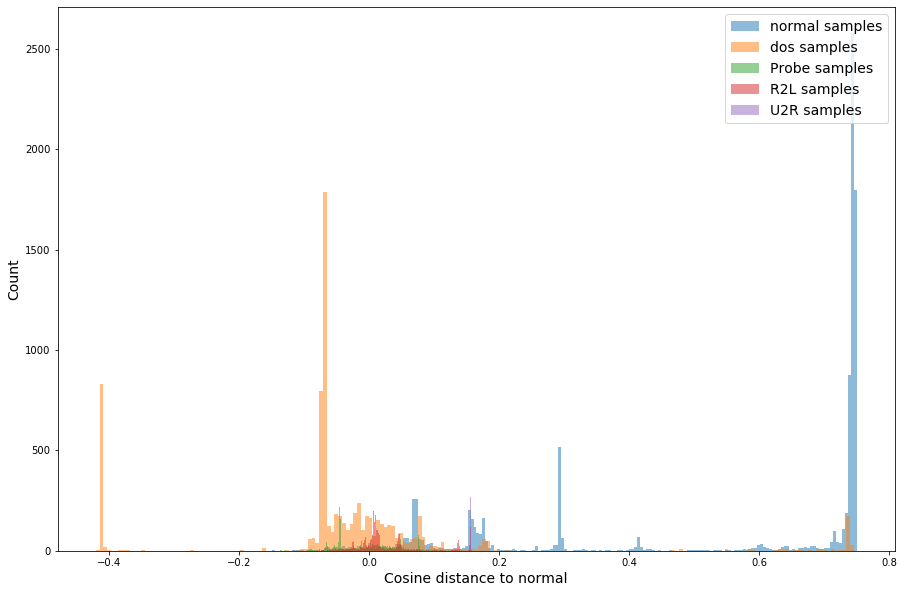

In [150]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_dos, bins=200, alpha=0.5, density=False, label="dos samples")
plt.hist(cos_sim_x_embeddings_probe, bins=200, alpha=0.5, density=False, label="Probe samples")
plt.hist(cos_sim_x_embeddings_R2L, bins=200, alpha=0.5, density=False, label="R2L samples")
plt.hist(cos_sim_x_embeddings_U2R, bins=200, alpha=0.5, density=False, label="U2R samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, test dataset

In [151]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTestM[YTestAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTestM[YTestAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTestM[YTestAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTestM[YTestAN5M=='U2R']) # embeddings de las muestras u2r

In [152]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_dos_mean = np.mean(x_embeddings_dos, axis=0)

No handles with labels found to put in legend.


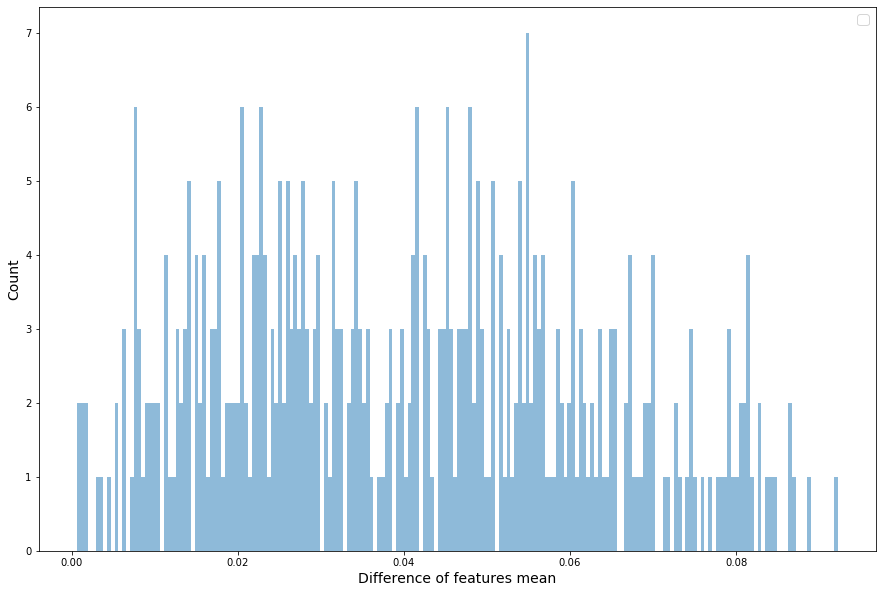

In [153]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [155]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), 0) 
print (stat, pvalue)

36.91716604133186 9.518760421812934e-131


## logloss
rff_dim = 400
gamma = 3
seed = 1234


In [309]:
x_train, x_test, label_train, label_test, y_train, y_test = XTrainM5_extended, XTestM5_extended, \
                                                            YTrainANMOhe5_extended, YTestANMOhe5_extended,\
                                                            YTrainOutput5, YTestOutput5
print (x_train.shape, x_test.shape, label_train.shape, label_test.shape, y_train.shape, y_test.shape)


(629865, 122) (112720, 122) (629865, 5) (112720, 5) (629865,) (112720,)


In [310]:
pd.Series(label_train[:,1]).value_counts()

0    503892
1    125973
dtype: int64

In [311]:
# save the best weights for predicting the test question pairs
file_name = 'contracted CLC_5NSL_3 dim 10 v1.0 logloss'
save_best_weights = file_name + '_best.h5'
save_last_weights = file_name + '_last.h5'
save_summary_stats = file_name + '.csv'

in_dim_x = x_train.shape[1]
in_dim_label = label_train.shape[1]
out_dim = 1 # yes, no

print(in_dim_x)
print(in_dim_label)
print(out_dim)

122
5
1


### Preparar modelo

In [312]:
np.random.seed(2453115889)
tf.random.set_seed(322198573)

In [313]:
def cosine_act(x):
    return tf.math.cos(x)

In [314]:
def cosine_act_contracted_2(x):
    return (tf.math.cos(x) * np.sqrt(2.) / np.sqrt(rff_dim))

In [315]:
def cosine_act_contracted_1(x):
    return (tf.math.cos(x) * 1. / np.sqrt(rff_dim))

In [316]:
def sine_act_contracted_1(x):
    return (tf.math.sin(x) * 1. / np.sqrt(rff_dim))

In [317]:
def contrastive_loss(y, d):
    """ Contrastive loss from Hadsell-et-al.'06
        http://yann.lecun.com/exdb/publis/pdf/hadsell-chopra-lecun-06.pdf
    """
    margin = 1
    square_pred = K.square(d)
    margin_square = K.square(K.maximum(margin - d, 0))
    return K.mean(y * square_pred + (1 - y) * margin_square)

In [318]:
def dummy_loss(y_true, d): # d es el valor que queremos minimizar y su valor es [0,+inf]
  return K.mean(d - y_true) # y_true es siempre 0

In [319]:
tf.compat.v1.disable_eager_execution()
def contractive_multi_loss(y_true, y_pred):

    logloss = tf.keras.metrics.binary_crossentropy(y_true, y_pred)
    
    return (logloss )



In [320]:

def create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val):
    
    tf.random.set_seed(seed)
    #init random weights
    ini_w_x = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_x = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    ini_w_l = tf.keras.initializers.RandomNormal(mean=0., stddev=np.sqrt(2 * gamma) )
    ini_b_l = tf.keras.initializers.RandomUniform(minval=0., maxval=2*np.pi)
    
    # input variables
    in_x = Input(shape=(in_dim_x,))
    in_label = Input(shape=(in_dim_label,))
    
    #RFF layers
    rff_x = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_x, 
                     bias_initializer=ini_b_x,
                     name="layer_x")
    rff_l = Dense(rff_dim, activation = "linear", trainable = True, 
                     kernel_initializer=ini_w_l, 
                     bias_initializer=ini_b_l,
                     name="layer_l")

    #embedding de x
    random_part_x = rff_x(in_x)
    latent_x = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_x_out")(random_part_x)
    
    
    #embedding de label
    random_part_l = rff_l(in_label)
    latent_l = tensorflow.keras.layers.Lambda(cosine_act_contracted_2, name="layer_l_out")(random_part_l)

    # similarity measure
    dot_product =  tensorflow.keras.layers.dot([latent_x, latent_l], 1, normalize=True)
    
    #  output layer
    #output = Dense(out_dim, activation='sigmoid')(dot_product)
    output = (dot_product+1.0)/2.0  # scale between 0-1
    
    #W = model.get_layer('layer_x').get_weights()[0]  # N x N_hidden
    W = rff_x.get_weights()[0]
    W2 = tf.convert_to_tensor(W, dtype=tf.float64)  # N x N_hidden
    W2 = K.transpose(W2)  # N_hidden x N
    #h_cos = model.get_layer('layer_x_out').output
    dh_cos = 1.0 - tf.math.square(latent_x)  # N_batch x N_hidden, por ser cosine
    # N_batch x N_hidden * N_hidden x 1 = N_batch x 1
    contractive_loss = alpha_val * (K.sum(dh_cos * K.sum(W2**2, axis=1), axis=1))

    
    # training model
    #m = Model(inputs=[in_x, in_label], outputs= [contractive_loss, output]) # devuelve salidas
    m = Model(inputs=[in_x, in_label], outputs= output) # devuelve salidas
    m_embed_x = Model(inputs=in_x, outputs= latent_x) # devuelve embedding de x
    m_embed_label = Model(inputs= in_label, outputs= latent_l) # devuelve embedding de label

    
    return(m, m_embed_x , m_embed_label, W2)

In [321]:
#crear modelo
rff_dim = 400
gamma = 3
seed = 1234
#alpha_val = 0.1

model, model_embed_x , model_embed_label, W2 = create_model_1(in_dim_x,in_dim_label,out_dim, rff_dim, gamma, seed, alpha_val)
#tf.compat.v1.enable_eager_execution()
#model.compile(loss=[dummy_loss, 'binary_crossentropy'], optimizer=Adam(0.001), metrics=['mse','accuracy'] , loss_weights = [1.0, 1.0] )
model.compile(loss=contractive_multi_loss, optimizer=Adam(0.001), metrics=['accuracy'])

In [322]:
model.summary()

Model: "model_9"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_7 (InputLayer)            [(None, 122)]        0                                            
__________________________________________________________________________________________________
input_8 (InputLayer)            [(None, 5)]          0                                            
__________________________________________________________________________________________________
layer_x (Dense)                 (None, 400)          49200       input_7[0][0]                    
__________________________________________________________________________________________________
layer_l (Dense)                 (None, 400)          2400        input_8[0][0]                    
____________________________________________________________________________________________

In [323]:
model_embed_x.summary()

Model: "model_10"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_7 (InputLayer)         [(None, 122)]             0         
_________________________________________________________________
layer_x (Dense)              (None, 400)               49200     
_________________________________________________________________
layer_x_out (Lambda)         (None, 400)               0         
Total params: 49,200
Trainable params: 49,200
Non-trainable params: 0
_________________________________________________________________


In [324]:
model_embed_label.summary()

Model: "model_11"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_8 (InputLayer)         [(None, 5)]               0         
_________________________________________________________________
layer_l (Dense)              (None, 400)               2400      
_________________________________________________________________
layer_l_out (Lambda)         (None, 400)               0         
Total params: 2,400
Trainable params: 2,400
Non-trainable params: 0
_________________________________________________________________


### Entrenamiento

In [325]:
np.random.seed(247531338)
tf.random.set_seed(31722973)

In [326]:
t0 = time.time()
# Entrenar el modelo
callbacks = [ModelCheckpoint(save_best_weights, monitor='val_loss', save_best_only=True, mode='auto'),
             EarlyStopping(monitor='val_loss', patience=10, verbose=1, mode='auto')
             #,tensorboard
            ]

history = model.fit([x_train,label_train],y_train,
                    batch_size=100,
                    epochs=100,
                    validation_split=0.2,
                    #validation_data = (x_test, y_test),
                    verbose=1,
                    #class_weight = class_weight,
                    shuffle=True,
                    initial_epoch = 0,
                    callbacks=callbacks)
t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Train on 503892 samples, validate on 125973 samples
Epoch 1/100
503892/503892 [==============================] - 23s 46us/sample - loss: 0.3288 - accuracy: 0.9556 - val_loss: 0.7977 - val_accuracy: 0.3828
Epoch 2/100
503892/503892 [==============================] - 21s 42us/sample - loss: 0.2222 - accuracy: 0.9821 - val_loss: 0.8148 - val_accuracy: 0.3786
Epoch 3/100
503892/503892 [==============================] - 21s 42us/sample - loss: 0.2000 - accuracy: 0.9837 - val_loss: 0.8232 - val_accuracy: 0.3769
Epoch 4/100
503892/503892 [==============================] - 21s 42us/sample - loss: 0.1894 - accuracy: 0.9853 - val_loss: 0.8286 - val_accuracy: 0.3771
Epoch 5/100
503892/503892 [==============================] - 21s 42us/sample - loss: 0.1832 - accuracy: 0.9854 - val_loss: 0.8277 - val_accuracy: 0.3789
Epoch 6/100
503892/503892 [==============================] - 21s 42us/sample - loss: 0.1793 - accuracy: 0.9864 - val_loss: 0.8344 - val_accuracy: 0.3785
Epoch 7/100
503892/503892 [===

In [327]:
# Aggregate the summary statistics
summary_stats = pd.DataFrame({'epoch': [ i + 1 for i in history.epoch ],
                              'train_acc': history.history['accuracy'],
                              'valid_acc': history.history['val_accuracy'],
                              'train_loss': history.history['loss'],
                              'valid_loss': history.history['val_loss']})

In [328]:
#summary_stats = pd.read_csv(save_summary_stats)
summary_stats.to_csv(save_summary_stats)    

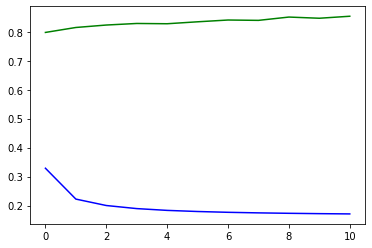

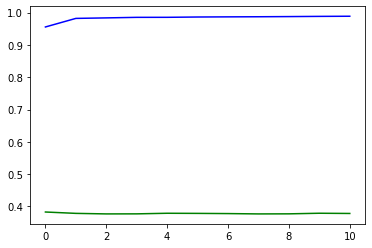

Minimum val_loss at epoch 1 = 0.7977


In [329]:
plt.plot(summary_stats.train_loss, 'b') # blue
plt.plot(summary_stats.valid_loss, 'g') # green
plt.show()

plt.plot(summary_stats.train_acc, 'b') # blue
plt.plot(summary_stats.valid_acc, 'g') # green
plt.show()


# Find the min validation loss during the training
min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
print('Minimum val_loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
min_loss = round(min_loss, 4)

## Find the minimum validation loss during the training
#min_loss, idx = min((loss, idx) for (idx, loss) in enumerate(history.history['val_loss']))
#print('Minimum loss at epoch', '{:d}'.format(idx+1), '=', '{:.4f}'.format(min_loss))
#min_loss = round(min_loss, 4)

###  Prediccion

In [330]:
model.load_weights(save_best_weights)

### prediccion sobre el conjunto de test y fake para deteccion de aciertos (deteccion binaria)

In [331]:
t0 = time.time()

ytest_prob_hat_binary = model.predict([x_test,label_test])

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.079689


In [332]:
pd.Series(ytest_prob_hat_binary.flatten()).describe()

count    112720.000000
mean          0.403769
std           0.245308
min           0.013357
25%           0.166077
50%           0.433435
75%           0.555110
max           0.984677
dtype: float64

In [333]:
#ytest_prob_hat_binary = (ytest_prob_hat_binary-min(ytest_prob_hat_binary))/(max(ytest_prob_hat_binary)-min(ytest_prob_hat_binary)) # escalamos 0-1

In [334]:
#pd.Series(ytest_prob_hat_binary.flatten()).describe()

In [335]:
threshold = 0.5
ytest_hat = ((ytest_prob_hat_binary > threshold) * 1.).reshape(-1)
print(ytest_hat.shape)
print(ytest_hat.mean())
print(y_test.mean())

(112720,)
0.3513041163946061
0.2


In [336]:
threshold = 0.7
ytest_hat = ((ytest_prob_hat_binary > threshold) * 1.).reshape(-1)

print('Performance measures. Prediccion de los embeddings ')
print('Accuracy =  {}'.format(accuracy_score(y_test, ytest_hat)))
print('F1 =  {}'.format(f1_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('Precision_score =  {}'.format(precision_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('recall_score =  {}'.format(recall_score(y_test, ytest_hat, pos_label=1, average='binary')))
print('roc_auc_score =  {}'.format(roc_auc_score(y_test, ytest_prob_hat_binary)))
precision, recall, thresholds = precision_recall_curve(y_test, ytest_prob_hat_binary)
print('pr_auc =  {}'.format(auc(recall, precision)))
print('matthews_corr_score =  {}'.format(matthews_corrcoef(y_test, ytest_hat)))

Performance measures. Prediccion de los embeddings 
Accuracy =  0.9009403832505323
F1 =  0.6934438831539643
Precision_score =  0.9098703170028818
recall_score =  0.560193399574166
roc_auc_score =  0.8844546306708283
pr_auc =  0.7566613537927219
matthews_corr_score =  0.665039421996871


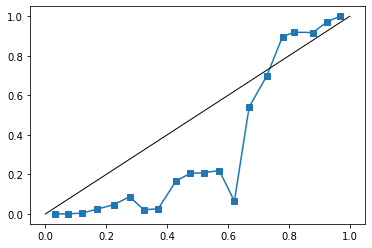

In [337]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, ytest_prob_hat_binary, normalize=False, n_bins=20, strategy='uniform')

plt.plot(mean_predicted_value, fraction_of_positives, "s-")
plt.plot([0, 1], [0, 1], color = 'black', linewidth = 1)

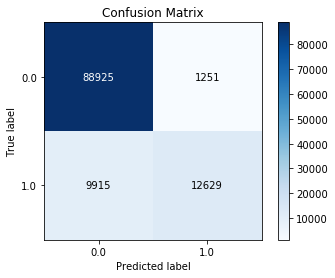

In [338]:
import scikitplot as skplt
skplt.metrics.plot_confusion_matrix(y_test, ytest_hat)

### prediccion real sobre el conjunto de test para predecir la clase en concreto

In [339]:
from sklearn.preprocessing import normalize
lb5.inverse_transform(labelOHEncodedFromPrediction([[0.8,0.7,0,0,0],[0,0.6,0,0,0],[0,0,1,0,0],[0,0,0,1,0],[0,0,0,0,1]]))

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype='<U6')

In [340]:
lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'])

array([[1, 0, 0, 0, 0],
       [0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 0, 0, 1]])

In [341]:
t0 = time.time()

total_label_test =[np.tile(lb5.transform([i]),(len(YTestAN5MOhe),1)) for i in ['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']]
ytest_prob_hat = np.column_stack([model.predict([XTestM,i]) for i in total_label_test])
ytest_prob_hat.shape

t1 = time.time()
print("Minutes elapsed: %f" % ((t1 - t0) / 60.))

Minutes elapsed: 0.076871


In [342]:
ytest_prob_hat

array([[0.97307287, 0.30022525, 0.08899566, 0.14779687, 0.3520478 ],
       [0.8983414 , 0.33570514, 0.1524798 , 0.20256402, 0.37304136],
       [0.59254638, 0.62928127, 0.28190905, 0.25987196, 0.26000113],
       ...,
       [0.65699238, 0.66256372, 0.18406879, 0.1654579 , 0.1804975 ],
       [0.61230756, 0.73840597, 0.17828519, 0.14570863, 0.12864659],
       [0.43365642, 0.52841829, 0.55290398, 0.53945896, 0.51141968]])

In [343]:
y_test_hat = lb5.inverse_transform(labelOHEncodedFromPrediction(ytest_prob_hat))
y_test_hat

array(['DOS', 'DOS', 'NORMAL', ..., 'NORMAL', 'NORMAL', 'PROBE'],
      dtype='<U6')

In [344]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef


average_type = 'weighted' # micro' , 'weighted'
print('Performance measures on Test data')
print('Accuracy =  {}'.format(accuracy_score( lb5.inverse_transform(YTestAN5MOhe),y_test_hat)))

print('F1 =  {}'.format(f1_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('Precision_score =  {}'.format(precision_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('recall_score =  {}'.format(recall_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('roc_auc_score =  {}'.format(roc_auc_score(YTestAN5MOhe,normalize(ytest_prob_hat, axis=1, norm='l1'))))

print('matthews_corr_score =  {}'.format(matthews_corrcoef(lb5.inverse_transform(YTestAN5MOhe), y_test_hat)))

Performance measures on Test data
Accuracy =  0.6992991483321505
F1 =  0.6217562255243222
Precision_score =  0.587644529426335
recall_score =  0.6992991483321505
roc_auc_score =  0.7729226054813071
matthews_corr_score =  0.5467507457178159


In [345]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef

average_type = 'micro' # micro' , 'weighted'
print('Performance measures on Test data')
print('Accuracy =  {}'.format(accuracy_score( lb5.inverse_transform(YTestAN5MOhe),y_test_hat)))

print('F1 =  {}'.format(f1_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('Precision_score =  {}'.format(precision_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('recall_score =  {}'.format(recall_score(lb5.inverse_transform(YTestAN5MOhe),y_test_hat, average=average_type)))

print('roc_auc_score =  {}'.format(roc_auc_score(YTestAN5MOhe,normalize(ytest_prob_hat, axis=1, norm='l1'))))

print('matthews_corr_score =  {}'.format(matthews_corrcoef(lb5.inverse_transform(YTestAN5MOhe), y_test_hat)))

Performance measures on Test data
Accuracy =  0.6992991483321505
F1 =  0.6992991483321505
Precision_score =  0.6992991483321505
recall_score =  0.6992991483321505
roc_auc_score =  0.7729226054813071
matthews_corr_score =  0.5467507457178159


### Perform test evaluation one vs. rest

Percentage per label class

In [346]:
(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts()/pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts().sum())*100

NORMAL    43.075763
DOS       33.081973
R2L       11.328957
PROBE     10.738999
U2R        1.774308
dtype: float64

In [347]:
(pd.Series(y_test_hat).value_counts()/pd.Series(y_test_hat).value_counts().sum())*100

NORMAL    64.828779
DOS       31.888751
PROBE      2.222321
U2R        0.687544
R2L        0.372605
dtype: float64

In [348]:
yt_app = lb5.inverse_transform(YTestAN5MOhe)
perf_per_class = pd.DataFrame(index=range(len(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).unique())),columns=['name', 'acc','f1', 'pre','rec'])
for i,x in enumerate(pd.Series(lb5.inverse_transform(YTestAN5MOhe)).value_counts().index):
    y_test_hat_check = y_test_hat.copy()
    y_test_hat_check[y_test_hat_check != x] = 'OTHER'
    yt_app = lb5.inverse_transform(YTestAN5MOhe).copy()
    yt_app[yt_app != x] = 'OTHER'
    ac=accuracy_score( yt_app,y_test_hat_check)
    f1=f1_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    pr=precision_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    re=recall_score( yt_app,y_test_hat_check,pos_label=x, average='binary')
    perf_per_class.iloc[i]=[x,ac,f1,pr,re]

In [349]:
# performance measures per class for test data
perf_per_class

,name,acc,f1,pre,rec
0,NORMAL,0.766856,0.783935,0.652412,0.981876
1,DOS,0.894828,0.838124,0.853804,0.823009
2,R2L,0.883339,0.0030326,0.047619,0.00156617
3,PROBE,0.878105,0.0595483,0.173653,0.0359356
4,U2R,0.97547,0.0036036,0.00645161,0.0025


###  Visualizar embeddings

In [350]:
model.load_weights(save_best_weights)

In [351]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

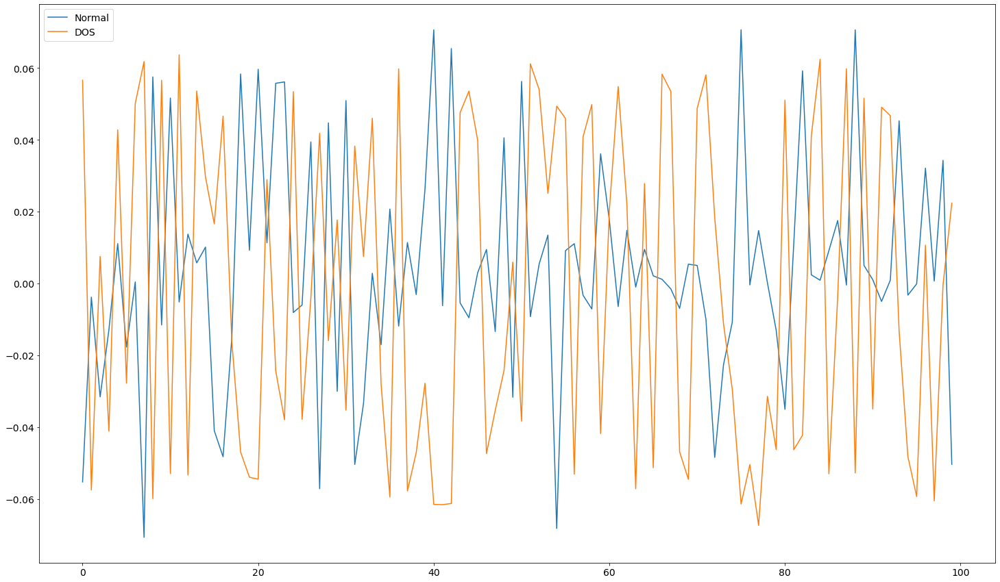

In [352]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[0,0:limit],label = "DOS")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

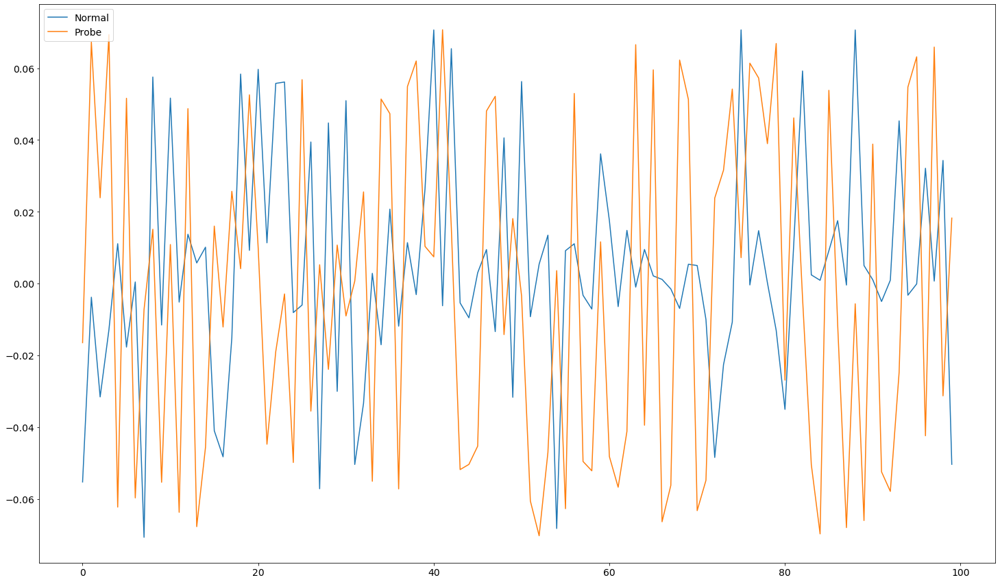

In [353]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[2,0:limit],label = "Probe")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

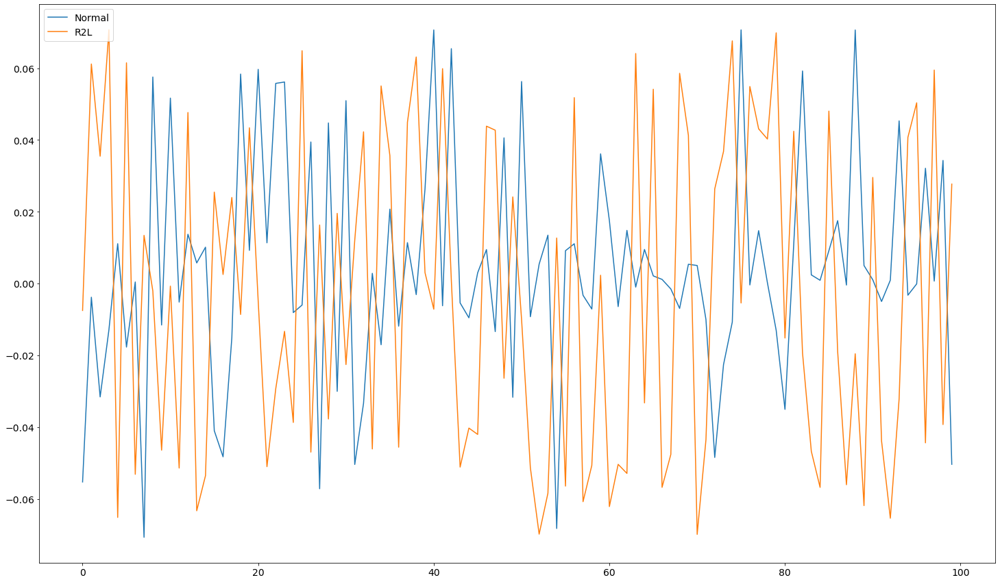

In [354]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[3,0:limit],label = "R2L")

plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

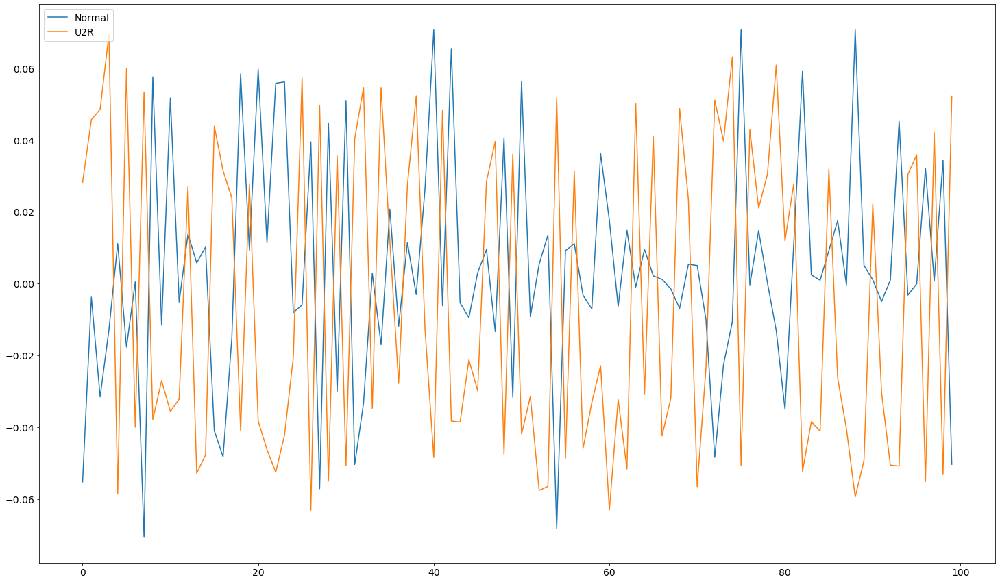

In [355]:
import matplotlib.pyplot as plt

limit = 100
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[4,0:limit],label = "U2R")
plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

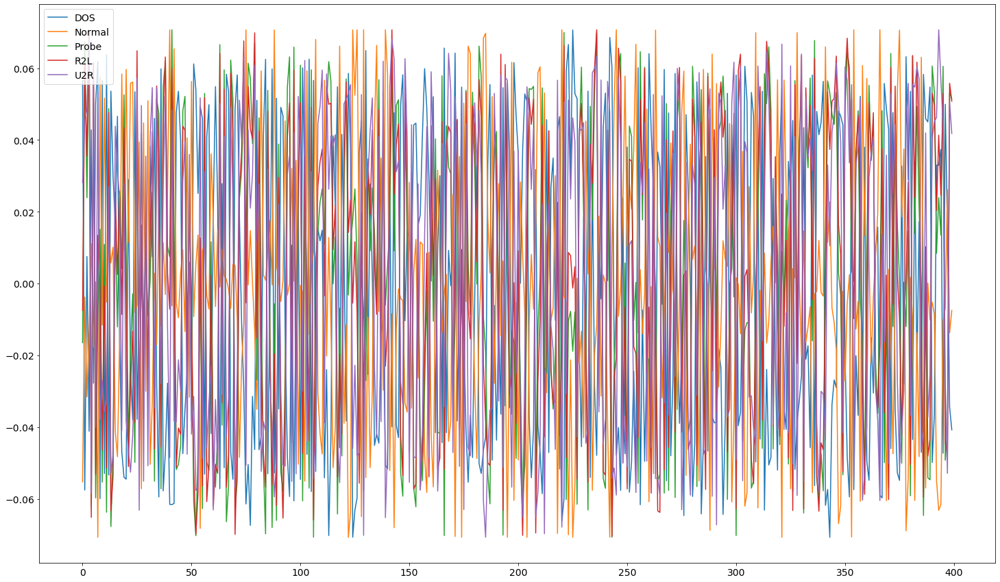

In [356]:
import matplotlib.pyplot as plt

limit = 400
plt.figure(figsize=(25,15))
plt.plot(label_embeddings[0,0:limit],label = "DOS")
plt.plot(label_embeddings[1,0:limit],label = "Normal")
plt.plot(label_embeddings[2,0:limit],label = "Probe")
plt.plot(label_embeddings[3,0:limit],label = "R2L")
plt.plot(label_embeddings[4,0:limit],label = "U2R")
plt.legend(loc='upper left',fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

In [357]:
x_embeddings = model_embed_x.predict(x_train)
x_embeddings.shape

(629865, 400)

In [358]:
YTestAN5M

array(['DOS', 'DOS', 'NORMAL', ..., 'DOS', 'NORMAL', 'PROBE'],
      dtype=object)

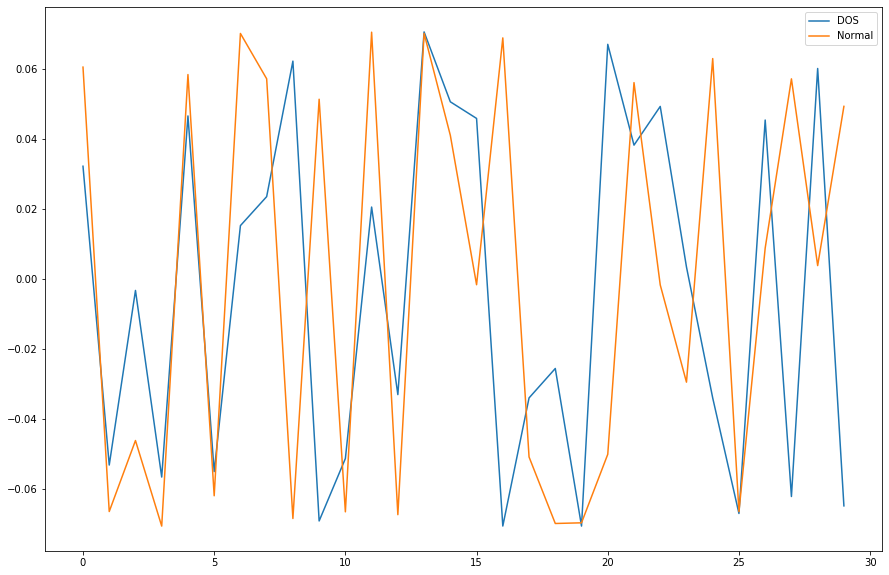

In [359]:
import matplotlib.pyplot as plt

limit = 30
plt.figure(figsize=(15,10))
plt.plot(x_embeddings[0,0:limit],label = "DOS")
plt.plot(x_embeddings[2,0:limit],label = "Normal")
plt.legend()
plt.show()


## Graficas Training dataset

In [360]:
model.load_weights(save_best_weights)

In [361]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

In [362]:
def cosine_sim (a,ref):
    return( dot(a, ref)/(norm(a)*norm(ref)))

In [363]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[1,:]  #ref es el label embedding de normal
print("Normal to Dos",cosine_sim (label_embeddings[0,:],ref))
print("Normal to probe",cosine_sim (label_embeddings[2,:],ref))
print("Normal to R2L",cosine_sim (label_embeddings[3,:],ref))
print("Normal to U2R",cosine_sim (label_embeddings[4,:],ref))

Normal to Dos -0.5534946074041763
Normal to probe -0.1242129834179551
Normal to R2L -0.32246552140172413
Normal to U2R -0.7384316110483692


In [364]:
np.unique(YTrainAN5M)

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype=object)

In [365]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTrainM[YTrainAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTrainM[YTrainAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTrainM[YTrainAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTrainM[YTrainAN5M=='U2R']) # embeddings de las muestras u2r

In [366]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_dos = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_dos])
cos_sim_x_embeddings_probe = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_probe])
cos_sim_x_embeddings_R2L = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_R2L])
cos_sim_x_embeddings_U2R = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_U2R])

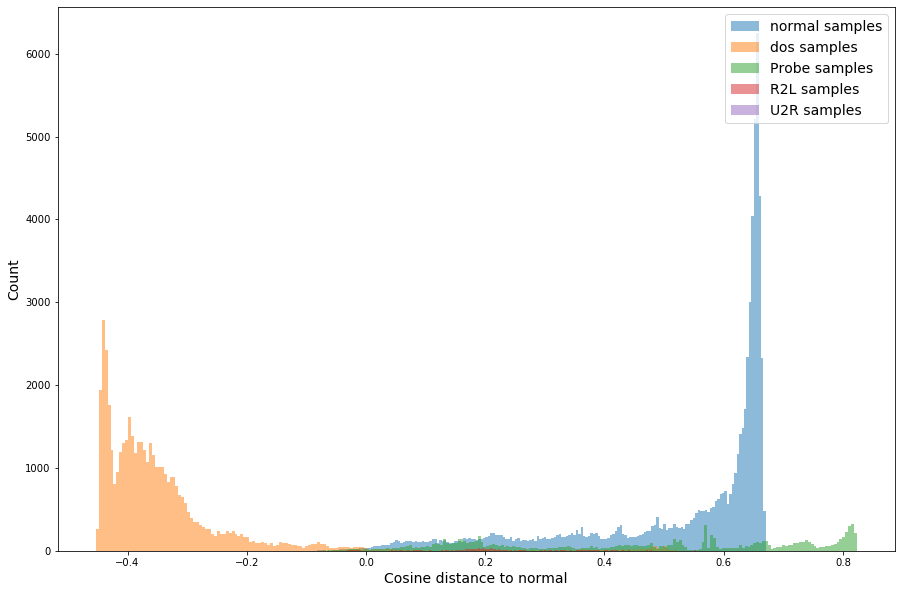

In [367]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_dos, bins=200, alpha=0.5, density=False, label="dos samples")
plt.hist(cos_sim_x_embeddings_probe, bins=200, alpha=0.5, density=False, label="Probe samples")
plt.hist(cos_sim_x_embeddings_R2L, bins=200, alpha=0.5, density=False, label="R2L samples")
plt.hist(cos_sim_x_embeddings_U2R, bins=200, alpha=0.5, density=False, label="U2R samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, training dataset

In [368]:
x_embeddings_normal = model_embed_x.predict(XTrainM[YTrainAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTrainM[YTrainAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTrainM[YTrainAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTrainM[YTrainAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTrainM[YTrainAN5M=='U2R']) # embeddings de las muestras u2r

In [369]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_dos_mean = np.mean(x_embeddings_dos, axis=0)

No handles with labels found to put in legend.


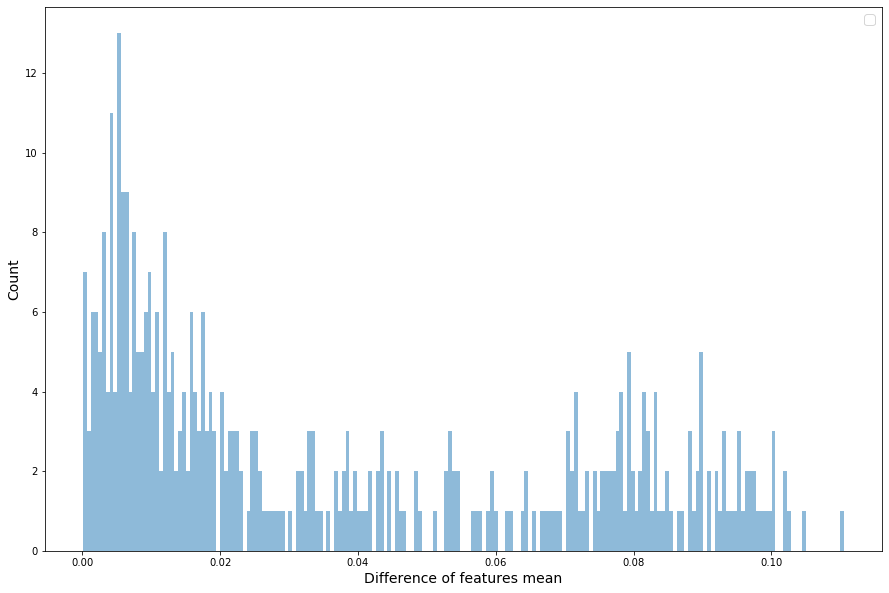

In [370]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [371]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), 0) 
print (stat, pvalue)

22.41489711058896 1.2961073213105622e-72


## Graficas Test dataset

In [372]:
model.load_weights(save_best_weights)

In [373]:
label_embeddings = model_embed_label.predict(lb5.transform(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R']))
label_embeddings.shape

(5, 400)

In [374]:
def cosine_sim (a,ref):
    return( dot(a, ref)/(norm(a)*norm(ref)))

In [375]:
from numpy import dot
from numpy.linalg import norm

# cosine distance entre label embeddings
ref = label_embeddings[1,:]  #ref es el label embedding de normal
print("Normal to Dos",cosine_sim (label_embeddings[0,:],ref))
print("Normal to probe",cosine_sim (label_embeddings[2,:],ref))
print("Normal to R2L",cosine_sim (label_embeddings[3,:],ref))
print("Normal to U2R",cosine_sim (label_embeddings[4,:],ref))

Normal to Dos -0.5534946074041763
Normal to probe -0.1242129834179551
Normal to R2L -0.32246552140172413
Normal to U2R -0.7384316110483692


In [376]:
np.unique(YTestAN5M)

array(['DOS', 'NORMAL', 'PROBE', 'R2L', 'U2R'], dtype=object)

In [377]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTestM[YTestAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTestM[YTestAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTestM[YTestAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTestM[YTestAN5M=='U2R']) # embeddings de las muestras u2r

In [378]:
cos_sim_x_embeddings_normal = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_normal])
cos_sim_x_embeddings_dos = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_dos])
cos_sim_x_embeddings_probe = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_probe])
cos_sim_x_embeddings_R2L = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_R2L])
cos_sim_x_embeddings_U2R = np.array([dot(a, ref)/(norm(a)*norm(ref)) for a in x_embeddings_U2R])

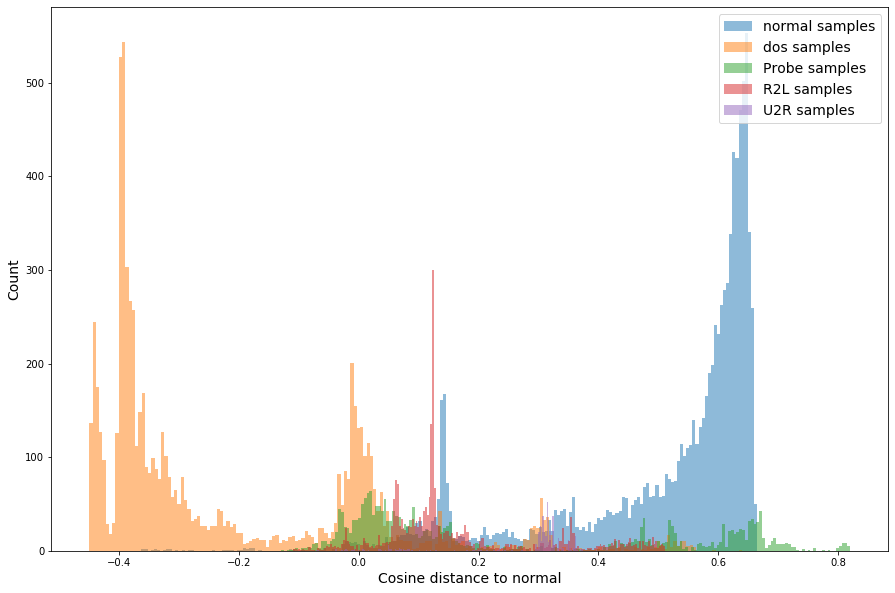

In [379]:
plt.figure(figsize=(15,10))
plt.hist(cos_sim_x_embeddings_normal, bins=200, alpha=0.5, density=False, label="normal samples")
plt.hist(cos_sim_x_embeddings_dos, bins=200, alpha=0.5, density=False, label="dos samples")
plt.hist(cos_sim_x_embeddings_probe, bins=200, alpha=0.5, density=False, label="Probe samples")
plt.hist(cos_sim_x_embeddings_R2L, bins=200, alpha=0.5, density=False, label="R2L samples")
plt.hist(cos_sim_x_embeddings_U2R, bins=200, alpha=0.5, density=False, label="U2R samples")
plt.xlabel("Cosine distance to normal", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

## Comparacion de los valores medios de las features, test dataset

In [380]:
x_embeddings_normal = model_embed_x.predict(XTestM[YTestAN5M=='NORMAL']) # embeddings de las muestras normales
x_embeddings_dos = model_embed_x.predict(XTestM[YTestAN5M=='DOS']) # embeddings de las muestras dos
x_embeddings_probe = model_embed_x.predict(XTestM[YTestAN5M=='PROBE']) # embeddings de las muestras probe
x_embeddings_R2L = model_embed_x.predict(XTestM[YTestAN5M=='R2L']) # embeddings de las muestras r2l
x_embeddings_U2R = model_embed_x.predict(XTestM[YTestAN5M=='U2R']) # embeddings de las muestras u2r

In [381]:
x_embeddings_normal_mean = np.mean(x_embeddings_normal, axis=0)
x_embeddings_dos_mean = np.mean(x_embeddings_dos, axis=0)

No handles with labels found to put in legend.


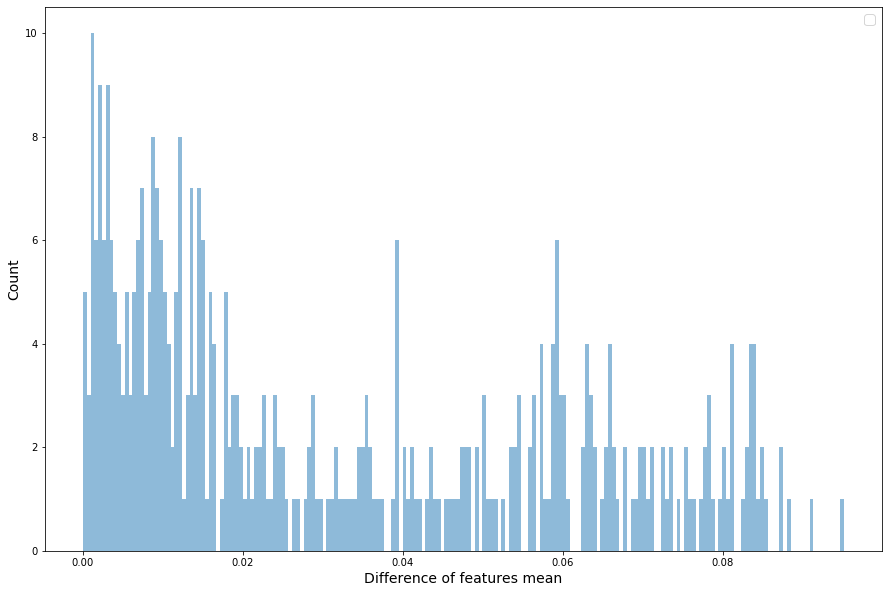

In [382]:
plt.figure(figsize=(15,10))
plt.hist(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), bins=200, alpha=0.5, density=False)
plt.xlabel("Difference of features mean", size=14)
plt.ylabel("Count", size=14)
plt.legend(loc='upper right',fontsize = 14)

In [383]:
from scipy import stats
stat, pvalue = stats.ttest_1samp(np.abs(x_embeddings_normal_mean - x_embeddings_dos_mean), 0) 
print (stat, pvalue)

23.356823995060633 1.1405360992156199e-76
